# Is there a unified bosonic edge of chaos? DV, CV and CV-MBQC photonic quantum reservoirs

**One notebook, three physical engines:** DV-QRC (Perceval), CV-QRC (Piquasso) and CV-MB-QRC (PhotoGraphiQ/PhotoGraphiQML).

## 1. Title, scope and claims

**Question.** Are the task-performance optima of bosonic photonic quantum reservoirs located at an *edge of chaos*? If so, at which edge? Photonic reservoirs have several candidate boundaries, and they are not the same object:

| # | boundary | what is measured | independent of task data? |
|---|---|---|---|
| 1 | **spectral (parametric) many-body chaos edge** | symmetry-resolved gap-ratio statistics of the reservoir Hamiltonian or Floquet cell, $\langle r\rangle\to C_{\rm spec}$ | yes |
| 2 | **temporal chaos edge** | Thouless time $t_{\rm Th}$ from the spectral form factor; the injection interval relative to $t_{\rm Th}$ | yes |
| 3 | **channel-contractivity edge** | driven exponent $\Lambda_{\rm ch}$ of the *unconditional* input-driven channel | yes |
| 4 | **measurement-trajectory edge** | conditional exponent $\lambda_{\rm traj}$ of *measurement-conditioned* trajectories | yes |

**Scope.** Three reservoir families are implemented, each in the photonic simulator it is native to:
* **discrete-variable (DV)** fixed-photon-number Bose–Hubbard reservoirs, with Perceval;
* **continuous-variable (CV)** reservoirs with Piquasso: Gaussian, and interacting Kerr/Bose–Hubbard in Fock space;
* **measurement-based CV reservoirs (CV-MB-QRC)** with PhotoGraphiQ/PhotoGraphiQML: Gaussian, and an ideal-logical-gate non-Gaussian model with measurement-conditioned trajectories.

**Claims tested (preregistered in §4).**
* $H_1$: primary performance (NARMA5 test NMSE) is optimised near a spectral-chaos edge, or, as its temporal variant, in the pre-Thouless window.
* $H_2$: primary performance is optimised near a channel-contractivity edge.
* $H_3$: MB-QRC performance is optimised near the intersection of the channel and trajectory edges.
* A universal collapse of performance onto shared coordinates across engines.

**What this notebook does not claim.**
* Simulator agreement validates an implementation. It says nothing about physical advantage.
* A Gaussian contractivity boundary is not many-body chaos.
* A small-system trajectory crossover is a finite-size crossover, not a measurement-induced phase transition.
* No quantum advantage is claimed unless §15 shows a resource-matched, statistically supported advantage.
* The machine-generated verdicts are in §16 and §19. Every "established" statement in §19 passes all criteria preregistered in §4. A smoke run can never produce such a statement.

**Provenance labels.** Every theory section carries three boxes:
* **Established in literature**: with references (§20).
* **Adapted here**: an established method changed for this setting.
* **Proposed novel element**: new definitions or constructions. These are labelled *proposed* wherever they are used.

**Execution labels.** Every engine call is labelled with one of three terms:
* **native**: every relevant operation runs inside the engine;
* **engine-compiled**: the engine builds the operator, and a validated exact propagation is iterated outside it;
* **exact adapter**: an exact NumPy/CuPy implementation of an operation the engine does not provide, validated against the engine on the cases it can run.

The validation dashboard (§17) lists, for every engine, which operations fall in which class and how each adapter was validated.

**Relation to the previous version of this notebook.** This file was revised in place. The previous version's audit, its frozen quick-profile results and the checks that re-derive them are in §5 and §6.9. Superseded code and conclusions were removed rather than appended to. The earlier verdict phrase "trend only" is no longer used, because it did not state which acceptance criterion failed.

# 2. Reproducibility manifest
This section fixes everything a result depends on before any physics is computed. It covers:
* the run mode;
* the pinned package versions and repository commits;
* machine and GPU provenance;
* file hashes;
* the compute-backend decision;
* the seeds;
* the checkpoint store and the run registry.

**Run modes.**
* `smoke` validates the implementation end to end in roughly 15–30 minutes on a laptop with a GPU. It uses 3–5 realisations, small Hilbert spaces and short sequences. **A smoke run can never produce a scientific verdict:** every hypothesis verdict it computes is forced to *inconclusive (smoke mode)* by the verdict engine of §4.
* `research` uses at least 30 exploratory and at least 50 new, independent confirmatory realisations per point, as preregistered in §4. Every parameter point is checkpointed and the run resumes where it stopped.

The environment variable `UEOC_RUN_MODE` overrides the cell below, for batch execution. On Colab, edit the cell and choose *Runtime → Run all*.

In [1]:
# RUN_MODE = "smoke"
RUN_MODE = "research"

import os
RUN_MODE = os.environ.get("UEOC_RUN_MODE", RUN_MODE)
assert RUN_MODE in ("smoke", "research"), RUN_MODE
if "UEOC_SESSION" in globals():            # stale-state guard: this cell must run first in a fresh kernel
    raise RuntimeError("This notebook was re-entered without a kernel restart. Restart the kernel and run all cells in order.")
print("RUN_MODE =", RUN_MODE)

RUN_MODE = research


## 2.1 Installation with pinned versions and commits
* **Physics engines.** The engines are pinned exactly: `perceval-quandela==1.3.0` and `piquasso==8.0.1`. PhotoGraphiQ and PhotoGraphiQML are pinned to fixed commits, never to a moving branch head. A clone is checked out at its commit, and the notebook refuses to run if `HEAD` differs.
* **Numerical stack.** NumPy, SciPy, pandas and matplotlib are **not** reinstalled, because a forced reinstall of NumPy on Colab corrupts the running kernel. Their versions are recorded and compared with the validated set of §2.2, and any mismatch is reported.
* **GPU (optional).** CuPy is used only if it is importable and passes the correctness benchmark of §2.4. On Colab it is preinstalled. Locally, install `cupy-cuda12x` together with the NVIDIA runtime wheels.
* **Local clones.** Set `UEOC_REPO_ROOT` to reuse existing clones. They are verified, never modified.

In [2]:
import sys, subprocess, importlib, importlib.util, importlib.metadata as _md, platform, json, hashlib, time, uuid
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def _dist_version(dist):
    try:
        return _md.version(dist)
    except _md.PackageNotFoundError:
        return None

def _sh(*cmd, check=True):
    return subprocess.run(cmd, check=check, capture_output=True, text=True).stdout.strip()

_numpy_loaded = sys.modules["numpy"].__version__ if "numpy" in sys.modules else None
PINS = {"perceval-quandela": "1.3.0", "piquasso": "8.0.1"}
_need = [f"{d}=={v}" for d, v in PINS.items() if _dist_version(d) != v]
_need += [p for p, m in [("threadpoolctl", "threadpoolctl"), ("pandas", "pandas"), ("matplotlib", "matplotlib"),
                         ("networkx", "networkx"), ("psutil", "psutil"), ("scipy", "scipy")] if importlib.util.find_spec(m) is None]
if _need:
    print("pip install:", " ".join(_need))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)

REPO_PINS = {"PhotoGraphiQ": ("https://github.com/chinmoybiswasdeep/PhotoGraphiQ.git", "6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e"),
             "PhotoGraphiQML": ("https://github.com/chinmoybiswasdeep/PhotoGraphiQML.git", "418c4601d578a6b5663122f176c293bbe4d6bd1c")}
REPO_ROOT = Path(os.environ.get("UEOC_REPO_ROOT", "/content/ueoc_repos" if IN_COLAB else "ueoc_repos")).resolve()
COMMITS, ORIGINS = {}, {}
for name, (url, commit) in REPO_PINS.items():
    path = REPO_ROOT / name
    if not (path / ".git").exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        _sh("git", "-c", "core.longpaths=true", "clone", "--quiet", url, str(path))
        _sh("git", "-C", str(path), "-c", "advice.detachedHead=false", "checkout", "--quiet", commit)
    _sh("git", "-C", str(path), "config", "core.longpaths", "true")     # Windows only; harmless elsewhere
    COMMITS[name] = _sh("git", "-C", str(path), "rev-parse", "HEAD")
    assert COMMITS[name] == commit, f"{name}: HEAD {COMMITS[name]} differs from the pinned commit {commit}"
    assert _sh("git", "-C", str(path), "status", "--porcelain", "--untracked-files=no") == "", f"{name}: tracked files modified"
    ORIGINS[name] = _sh("git", "-C", str(path), "remote", "get-url", "origin")
for mod, name in (("photographiq", "PhotoGraphiQ"), ("photographiqml", "PhotoGraphiQML")):
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", str(REPO_ROOT / name)], check=True)
importlib.invalidate_caches()
if _numpy_loaded is not None and _dist_version("numpy") != _numpy_loaded:
    raise SystemExit(f"NumPy changed from {_numpy_loaded} to {_dist_version('numpy')} after import: Runtime -> Restart session, then Run all.")
print({k: v[:12] for k, v in COMMITS.items()})

{'PhotoGraphiQ': '6d49da06fa6e', 'PhotoGraphiQML': '418c4601d578'}


## 2.2 Imports, machine and software provenance
The table records:
* the operating system, CPU model, core count, RAM, GPU model and VRAM, NVIDIA driver and CUDA runtime;
* every package version, together with the import location of each physics engine;
* whether the run is local or on Colab.

The full `nvidia-smi` output is printed below the table when a driver is present.

In [3]:
import os, ast, time, math, json, zlib, itertools, warnings, contextlib, inspect, re, hashlib, pickle, random, shutil, copy
import numpy as np, scipy, scipy.linalg as sla, scipy.stats as sst, scipy.special as ssp, scipy.optimize, scipy.sparse, scipy.sparse.linalg as spla
import pandas as pd, matplotlib, matplotlib.pyplot as plt, networkx as nx, psutil, threadpoolctl
from numpy.polynomial import legendre as npleg
from IPython.display import display, Markdown
import perceval as pcvl
import piquasso as pq
import photographiq as pg
import photographiqml as pgml

UEOC_SESSION = uuid.uuid4().hex[:12]
NOTEBOOK_T0 = time.perf_counter()
warnings.filterwarnings("ignore", message=".*deprecated.*", category=DeprecationWarning)
if os.environ.get("UEOC_BLAS_THREADS"):    # optional calibration knob for hybrid/throttled laptop CPUs; results do not depend on it
    _BLAS_LIMIT = threadpoolctl.threadpool_limits(int(os.environ["UEOC_BLAS_THREADS"]), user_api="blas")

def _cpu_model():
    try:
        if platform.system() == "Windows":
            out = _sh("powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name", check=False)
            return out.splitlines()[0].strip() if out else platform.processor()
        if Path("/proc/cpuinfo").exists():
            for line in open("/proc/cpuinfo"):
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
        return platform.processor() or "unknown"
    except Exception:
        return platform.processor() or "unknown"

def _nvidia_smi():
    exe = shutil.which("nvidia-smi")
    if exe is None:
        return None, None
    q = _sh(exe, "--query-gpu=name,memory.total,driver_version,compute_cap", "--format=csv,noheader", check=False)
    return q, _sh(exe, check=False)

VALIDATED_STACK = {"numpy": "2.5.3", "scipy": "1.18.1", "pandas": None, "matplotlib": None}   # None = not pinned (recorded only)
_vm = psutil.virtual_memory(); _smi_q, NVIDIA_SMI = _nvidia_smi()
ENV = {
    "run location": "Google Colab" if IN_COLAB else "local", "operating system": platform.platform(), "python": platform.python_version(),
    "CPU model": _cpu_model(), "physical / logical cores": f"{psutil.cpu_count(logical=False)} / {psutil.cpu_count()}",
    "RAM total (GB)": f"{_vm.total / 2**30:.1f}", "GPU (nvidia-smi: name, VRAM, driver, compute capability)": _smi_q or "none detected",
    "BLAS threads": ", ".join(f"{d['internal_api']}:{d['num_threads']}" for d in threadpoolctl.threadpool_info() if d["user_api"] == "blas"),
    "Perceval": f"{pcvl.__version__}  ({Path(pcvl.__file__).parent})", "Piquasso": f"{pq.__version__}  ({Path(pq.__file__).parent})",
    "PhotoGraphiQ": f"{pg.__version__} @ {COMMITS['PhotoGraphiQ']}  ({Path(pg.__file__).parent})",
    "PhotoGraphiQML": f"{pgml.__version__} @ {COMMITS['PhotoGraphiQML']}  ({Path(pgml.__file__).parent})",
    "PhotoGraphiQ origin": ORIGINS["PhotoGraphiQ"], "PhotoGraphiQML origin": ORIGINS["PhotoGraphiQML"],
}
for dist in ("numpy", "scipy", "pandas", "matplotlib", "networkx", "scikit-learn", "seaborn", "cupy-cuda12x", "cupy", "torch", "jax"):
    v = _dist_version(dist)
    if v or dist in ("numpy", "scipy", "pandas", "matplotlib"):
        pin = VALIDATED_STACK.get(dist)
        ENV[dist] = (v or "not installed") + ("" if pin is None or v == pin else f"   [validated with {pin}: MISMATCH]")
with pd.option_context("display.max_colwidth", 150):
    display(pd.DataFrame(ENV.items(), columns=["item", "value"]).set_index("item"))
if NVIDIA_SMI:
    print(NVIDIA_SMI)

,value
item,
run location,local
operating system,Windows-11-10.0.26200-SP0
python,3.12.14
CPU model,12th Gen Intel(R) Core(TM) i5-12450HX
physical / logical cores,8 / 12
RAM total (GB),23.7
"GPU (nvidia-smi: name, VRAM, driver, compute capability)","NVIDIA GeForce RTX 4050 Laptop GPU, 6141 MiB, 581.86, 8.9"
BLAS threads,"openblas:4, openblas:4"
Perceval,1.3.0 (C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\claude\d--Research-QML-results-1-photonic-qrc-eoc\49701066-26a2-4270-8167-14dc3c92a73e\scra...


Thu Oct  1 14:10:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 581.86                 Driver Version: 581.86         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   64C    P8              2W /   80W |     584MiB /   6141MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2.3 File hashes and local-repository provenance
SHA-256 hashes are recorded for:
* the unified notebook **as it was before this revision**. The value is frozen, because the file is now modified in place.
* every source notebook found next to this notebook. If a source notebook is absent, as on a fresh Colab runtime, this is stated.
* the PhotoGraphiQ/PhotoGraphiQML source files that this notebook imports or calls.

The hash of the final executed notebook cannot be computed from inside itself, so it is recorded by the execution script (§19).

In [4]:
def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

PRE_REVISION_NOTEBOOK_SHA256 = "2aa947262f672dd24c071fd1c150673021ecce3c10c16ec82d4064a6ddc94008"   # frozen: file state before this revision
SOURCE_NOTEBOOKS = {"DV (Perceval)": "dv_qrc_perceval_colab.ipynb", "CV (Piquasso)": "garcia_beni_cv_qrc_piquasso_colab.ipynb",
                    "CV-MB (PhotoGraphiQ/ML)": "cv_mbqrc_photographiqml_colab.ipynb"}
SOURCE_SEARCH = [Path(os.environ.get("UEOC_SOURCE_DIR", ".")).resolve()] + ([Path("/content")] if IN_COLAB else [])
SOURCE_PATHS = {}
for k, fn in SOURCE_NOTEBOOKS.items():
    hits = [d / fn for d in SOURCE_SEARCH if (d / fn).exists()]
    SOURCE_PATHS[k] = hits[0] if hits else None
IMPORTED_SOURCES = ["photographiq/__init__.py", "photographiq/pattern.py", "photographiq/gaussian.py", "photographiq/compiler.py",
                    "photographiq/fock_measurements.py", "photographiq/backends/fock.py", "photographiq/backends/mixed_fock.py",
                    "photographiq/backends/piquasso.py", "photographiq/graph.py", "photographiq/states.py", "photographiqml/__init__.py"]
hash_rows = [dict(item="unified notebook before revision (frozen)", path="unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb", sha256=PRE_REVISION_NOTEBOOK_SHA256)]
for k, p in SOURCE_PATHS.items():
    hash_rows.append(dict(item=f"source notebook {k}", path=str(p) if p else f"{SOURCE_NOTEBOOKS[k]} NOT FOUND", sha256=sha256_file(p) if p else "absent"))
_pg_root, _pgml_root = Path(pg.__file__).parent.parent, Path(pgml.__file__).parent.parent
for rel in IMPORTED_SOURCES:
    p = (_pgml_root if rel.startswith("photographiqml") else _pg_root) / rel
    hash_rows.append(dict(item="imported source", path=rel, sha256=sha256_file(p) if p.exists() else "absent"))
HASHES = pd.DataFrame(hash_rows)
with pd.option_context("display.max_colwidth", 80):
    display(HASHES)
print("source notebooks found:", {k: bool(v) for k, v in SOURCE_PATHS.items()})

,item,path,sha256
0,unified notebook before revision (frozen),unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb,2aa947262f672dd24c071fd1c150673021ecce3c10c16ec82d4064a6ddc94008
1,source notebook DV (Perceval),D:\Research\QML\results_1\photonic-qrc-eoc\dv_qrc_perceval_colab.ipynb,8f4562977056b7aac4d0360a1ce10cc15886578fe229ade42b6fdda6f52232f0
2,source notebook CV (Piquasso),D:\Research\QML\results_1\photonic-qrc-eoc\garcia_beni_cv_qrc_piquasso_colab...,609243ce5bcbfaef584730ad272b75cce60150a8b292348cda8d396edb2eaee3
3,source notebook CV-MB (PhotoGraphiQ/ML),D:\Research\QML\results_1\photonic-qrc-eoc\cv_mbqrc_photographiqml_colab.ipynb,f5ed39556c98cae4164cd60893893758b935ae8793599f7cd95151916175a174
4,imported source,photographiq/__init__.py,e7b8eeeea4d57f19b29769ade0164c20beeca0fdd0ed80a823eb494382b0920d
5,imported source,photographiq/pattern.py,485abc5b591603137f4b45ea9ed2257194211977b169867a48db584b4dae86d9
6,imported source,photographiq/gaussian.py,372988f56fc8fa28d7d06e5aacbede20c424c7462109d2e2dff31454b3a860ef
7,imported source,photographiq/compiler.py,389acee1b2b056aca64859571e54ef94f33a152b9f356e0e02a927f2a931d6b0
8,imported source,photographiq/fock_measurements.py,981b8e72a0961add10047971fd6d73f541633b46c61ea1221eb89b5b7d2efc4b
9,imported source,photographiq/backends/fock.py,410b616e685beaa77d9a9d72c30d4cab96a800fb096d2ba2c80f92734d65e116


source notebooks found: {'DV (Perceval)': True, 'CV (Piquasso)': True, 'CV-MB (PhotoGraphiQ/ML)': True}


## 2.4 Compute backend: GPU detection, correctness and timing benchmark
The policy is implemented by `detect_compute_device` and `get_array_namespace`.
1. **Detection.** CuPy must import, see a CUDA device and compile a kernel through NVRTC. A driver without the CUDA libraries counts as "no GPU".
2. **Correctness.** Complex128 results are compared with NumPy for:
   * a batched density-matrix propagation $U\rho U^\dagger$;
   * a batched Hermitian eigensolve;
   * a batched gather/scatter of the port-refresh type.

   The tolerance is $10^{-10}$ relative.
3. **Timing.** The production kernel, $B$ realisations of $\rho\mapsto U\rho U^\dagger$ at the reservoir dimension, is timed on both devices. The GPU is selected only if it is at least 1.5× faster.
4. **Scope of use.** GPU arrays are used **only** for:
   * batched propagation of density matrices and trajectory ensembles that were already built from engine-validated operators;
   * batched bootstrap arithmetic.

   Perceval, Piquasso and PhotoGraphiQ calls always run on the CPU, because those packages are CPU-only. The GPU never replaces an engine.
5. **Fallback.** Any CUDA/CuPy failure, whether at detection or at run time, falls back to NumPy on the CPU. The fallback is logged in `DEVICE_LOG`.

Arrays stay on the device for a whole trajectory or sequence. Only features and summary statistics are copied back to the host.

In [5]:
DEVICE_LOG = []

def _log_device(op, device, note=""):
    DEVICE_LOG.append(dict(operation=op, device=device, note=note))

def _bench_kernel(xp, B, D, reps, seed=0):
    rng = np.random.default_rng(seed)
    A = rng.normal(size=(B, D, D)) + 1j * rng.normal(size=(B, D, D)); Q, _ = np.linalg.qr(A)
    R = rng.normal(size=(B, D, D)) + 1j * rng.normal(size=(B, D, D)); R = R @ np.conj(np.swapaxes(R, 1, 2))
    Qd, Rd = xp.asarray(Q), xp.asarray(R)
    out = Qd @ Rd @ xp.conj(xp.swapaxes(Qd, 1, 2))
    if xp is not np:
        xp.cuda.Stream.null.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps):
        Rd = Qd @ Rd @ xp.conj(xp.swapaxes(Qd, 1, 2)); Rd = Rd / xp.trace(Rd, axis1=1, axis2=2)[:, None, None]
    if xp is not np:
        xp.cuda.Stream.null.synchronize()
    return (time.perf_counter() - t0) / reps, out

def _register_cuda_wheel_dlls():
    """Windows only: make the DLLs of pip-installed NVIDIA runtime wheels (nvidia-*-cu12) visible to CuPy."""
    if platform.system() != "Windows":
        return []
    import site
    dirs = []
    for sp in site.getsitepackages() + [site.getusersitepackages()]:
        for d in Path(sp).glob("nvidia/*/bin"):
            os.add_dll_directory(str(d)); dirs.append(str(d))
            os.environ["PATH"] = str(d) + os.pathsep + os.environ.get("PATH", "")
    return dirs

def detect_compute_device(prefer_gpu=True, B=16, D=126, reps=30):
    info = dict(kind="cpu", name=ENV["CPU model"], reason="", speedup=np.nan, max_rel_err=np.nan)
    if not prefer_gpu or os.environ.get("UEOC_FORCE_CPU") == "1":
        info["reason"] = "GPU not requested"; return info
    try:
        _register_cuda_wheel_dlls()
        import cupy as cp
        n = cp.cuda.runtime.getDeviceCount()
        if n < 1:
            info["reason"] = "CuPy imported but no CUDA device"; return info
        props = cp.cuda.runtime.getDeviceProperties(0)
        _ = (cp.arange(4.0) * 2).sum().item()                                        # forces an NVRTC-compiled kernel
        rng = np.random.default_rng(1)
        H = rng.normal(size=(8, 40, 40)) + 1j * rng.normal(size=(8, 40, 40)); H = H + np.conj(np.swapaxes(H, 1, 2))
        e_np = np.linalg.eigvalsh(H); e_cp = cp.asnumpy(cp.linalg.eigvalsh(cp.asarray(H)))
        t_cpu, o_cpu = _bench_kernel(np, B, D, reps); t_gpu, o_gpu = _bench_kernel(cp, B, D, reps)
        err = max(float(np.abs(cp.asnumpy(o_gpu) - o_cpu).max() / np.abs(o_cpu).max()), float(np.abs(e_cp - e_np).max() / np.abs(e_np).max()))
        idx = rng.integers(0, D, size=(5, 7)); Xh = rng.normal(size=(3, D, D)); g_np = Xh[:, idx[:, :, None], idx[:, None, :]].sum(1)
        g_cp = cp.asnumpy(cp.asarray(Xh)[:, cp.asarray(idx)[:, :, None], cp.asarray(idx)[:, None, :]].sum(1)); err = max(err, float(np.abs(g_cp - g_np).max()))
        info.update(name=props["name"].decode() if isinstance(props["name"], bytes) else str(props["name"]),
                    vram_gb=props["totalGlobalMem"] / 2**30, cuda_runtime=cp.cuda.runtime.runtimeGetVersion(), cupy=cp.__version__,
                    t_cpu_ms=1e3 * t_cpu, t_gpu_ms=1e3 * t_gpu, speedup=t_cpu / t_gpu, max_rel_err=err)
        if err > 1e-10:
            info["reason"] = f"GPU correctness check failed (max rel. error {err:.1e}) -> CPU"; return info
        if t_cpu / t_gpu < 1.5:
            info["reason"] = f"GPU correct but not beneficial for the production kernel ({t_cpu / t_gpu:.2f}x) -> CPU"; return info
        info["kind"] = "gpu"; info["reason"] = f"GPU correct (max rel. error {err:.1e}) and {t_cpu / t_gpu:.1f}x faster on the production kernel"
        return info
    except Exception as e:                                                             # noqa: BLE001 - any CUDA failure means CPU
        info["reason"] = f"no usable GPU: {type(e).__name__}: {str(e)[:160]}"
        return info

def get_array_namespace(device):
    if device["kind"] == "gpu":
        import cupy as cp
        return cp
    return np

DEVICE = detect_compute_device(prefer_gpu=True)
xp = get_array_namespace(DEVICE)
ON_GPU = xp is not np
_log_device("backend selection", DEVICE["kind"], DEVICE["reason"])

def to_host(a):
    return a.get() if hasattr(a, "get") else np.asarray(a)

def to_dev(a):
    return xp.asarray(a)

def gpu_peak_mb():
    if not ON_GPU:
        return 0.0
    return xp.get_default_memory_pool().total_bytes() / 2**20

display(pd.DataFrame([DEVICE]).T.rename(columns={0: "compute backend"}))

C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\claude\d--Research-QML-results-1-photonic-qrc-eoc\49701066-26a2-4270-8167-14dc3c92a73e\scratchpad\venv\Lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


,compute backend
kind,gpu
name,NVIDIA GeForce RTX 4050 Laptop GPU
reason,GPU correct (max rel. error 1.1e-14) and 1.8x ...
speedup,1.809243
max_rel_err,0.0
vram_gb,5.996582
cuda_runtime,12090
cupy,13.6.0
t_cpu_ms,8.48409
t_gpu_ms,4.689303


## 2.5 Seeds, checkpoint store and run registry
* **Seeds.** Every stochastic object draws from a child stream `rng_for(*tags)` derived from `MASTER_SEED`. `seed_everything` also seeds Python's `random`, NumPy's legacy global generator, CuPy, PyTorch/JAX (when installed) and Perceval. Piquasso and PhotoGraphiQ take explicit seeds at each call.
* **Checkpoints.** `STORE.cached(name, params, fn)` stores the result of every expensive unit, typically one parameter point × one realisation bank, under a hash of:
  * the unit name;
  * its parameters;
  * the engine-version string of the code that produced it.

  A completed unit is never recomputed. A crash or interruption loses at most one unit, and re-running the notebook resumes. Deleting the directory `UEOC_CKPT_DIR` forces a full recomputation. §6 tests the resume path.
* **Run registry.** At the end of every run, a line is appended to `runs.jsonl`. It records the mode, a hash of all code cells (with the mode line normalised) and the completion status. §19 uses it to show that the *same code* also passed a complete smoke run.

In [6]:
MASTER_SEED = 20260930

def rng_for(*tags):
    return np.random.default_rng([MASTER_SEED] + [zlib.crc32(repr(t).encode()) for t in tags])

def seed_int(*tags):
    return int(rng_for(*tags).integers(0, 2**31 - 1))

def seed_everything(seed=MASTER_SEED):
    random.seed(seed); np.random.seed(seed % 2**32)
    pcvl.random_seed(seed % (2**31 - 1))
    if ON_GPU:
        xp.random.seed(seed % 2**32)
    for mod, fn in (("torch", "manual_seed"), ):
        if mod in sys.modules:
            getattr(sys.modules[mod], fn)(seed)
    return seed

seed_everything()
CKPT_ROOT = Path(os.environ.get("UEOC_CKPT_DIR", "/content/ueoc_checkpoints" if IN_COLAB else "ueoc_checkpoints")).resolve()
ENGINE_VERSIONS = {"dv": "dv-2", "cvk": "cvk-2", "cvg": "cvg-2", "mbg": "mbg-2", "mbk": "mbk-3", "stats": "stats-2", "classical": "cls-2", "lyap": "lyap-2 (detrace)"}

class CheckpointStore:
    """Resumable unit cache: one pickle per (unit name, parameters, engine version). The compute time of each unit is kept in a
    sidecar `.sec` file, so a run that reuses units still reports what they cost (`reused_s`; `reused_untimed` counts units from
    stores written before timing was recorded)."""

    def __init__(self, root):
        self.root = Path(root); self.root.mkdir(parents=True, exist_ok=True); self.hits = self.misses = 0; self.reused_s = 0.0; self.reused_untimed = 0

    @staticmethod
    def key(name, params):
        blob = json.dumps(params, sort_keys=True, default=lambda o: o.tolist() if hasattr(o, "tolist") else repr(o))
        return f"{name}-{hashlib.sha256(blob.encode()).hexdigest()[:20]}"

    def path(self, name, params):
        return self.root / (self.key(name, params) + ".pkl")

    def cached(self, name, params, fn):
        p = self.path(name, params)
        if p.exists():
            try:
                with open(p, "rb") as fh:
                    out = pickle.load(fh)
                self.hits += 1; sec = p.with_suffix(".sec")
                if sec.exists():
                    self.reused_s += float(sec.read_text())
                else:
                    self.reused_untimed += 1
                return out
            except Exception:                                  # truncated file from an interrupted write -> recompute
                p.unlink(missing_ok=True)
        t0 = time.perf_counter(); out = fn(); dt = time.perf_counter() - t0; tmp = p.with_suffix(".tmp")
        with open(tmp, "wb") as fh:
            pickle.dump(out, fh, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, p); p.with_suffix(".sec").write_text(f"{dt:.3f}"); self.misses += 1
        return out

STORE = CheckpointStore(CKPT_ROOT / RUN_MODE)
RUN_REGISTRY = CKPT_ROOT / "runs.jsonl"
print(f"checkpoints: {STORE.root}  (existing units: {len(list(STORE.root.glob('*.pkl')))})")

checkpoints: C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\claude\d--Research-QML-results-1-photonic-qrc-eoc\49701066-26a2-4270-8167-14dc3c92a73e\scratchpad\ckpt_research\research  (existing units: 1807)


## 2.6 Central configuration
One object, `CFG`, holds every size, grid, realisation count and sequence length. Everything downstream reads from it. The research-mode values are the preregistered ones; see §4 for the rules that use them.

**Partial research runs.** If a complete research run is too expensive for the available hardware, the environment variable `UEOC_PHASE_LEVELS` can hold a JSON map such as `{"phase4": "smoke"}`. Such a map runs single phases at smoke scale inside a research run. Every result table carries the level actually executed, and a phase executed at smoke level can never yield a verdict other than *inconclusive*.

In [7]:
_SMOKE = dict(
    # DV Bose-Hubbard (Phase 1)
    L=5, N=5, stat_sizes=[(5, 5), (6, 6)], stat_real={(5, 5): 30, (6, 6): 10}, g_spec=list(np.geomspace(0.01, 100, 13)),
    sff_real=(100, 400), sff_real_big=30, boot=500,
    seq=(100, 500, 150, 400), ipc_deg=2, ipc_delay=5, mc_tau=15, n_null=1000, refits=4,
    dv_g_explore=list(np.geomspace(0.03, 60, 7)), dv_tau_explore=list(np.geomspace(1.0, 1000.0, 5)), lyap_steps=400,
    n_explore=4, n_confirm=3,
    # interacting CV (Phase 2) and matched DV-CV (Phase 3)
    cvk_L=5, cvk_cut=(6, 7), cvk_alpha_grid=[0.35, 0.5], cvk_g=[0.1, 0.5, 2.0, 8.0, 30.0], cvk_tau=40.0, cvk_sector_real=40,
    cvk_conv_real=2, match_real=3, cvk_probe_n=1, cvk_probe_g=[0.1, 30.0], cvk_conv_g=[0.1, 2.0, 30.0], match_g_n=3,
    # Gaussian controls
    cv_N=5, cv_kappa=[0.5, 1.0, 1.4, 1.8, 2.4], cv_R=[0.3, 0.6, 0.9, 0.97], mb_N=5, mb_T=[0.1, 0.3, 0.5, 0.7, 0.85, 0.95], mb_scale=1.0,
    # MBQC (Phases 4-5)
    fl_chi=list(np.geomspace(1e-3, np.pi, 10)), fl_real=30, mbk_L=3, mbk_cut=(5, 6), mbk_meter_cut=14,
    mbk_chi=[0.03, 0.3, 3.0], mbk_T=[0.5, 0.8, 0.95, 0.99], rob_mbk=["baseline", "loss 0.05", "r_m 1.0", "ff error 0.1", "cutoff c+1"], mbk_eta=[1.0, 0.5], mbk_traj=16, mbk_traj_steps=120, mbk_grid=64,
    mbg_T=[0.3, 0.6, 0.9], mbg_eta=[0.2, 1.0], mbg_traj_steps=300,
    shots=[100, 1000], hyper_budget=4,
)
_RESEARCH = dict(
    L=5, N=5, stat_sizes=[(5, 5), (6, 6), (7, 7)], stat_real={(5, 5): 200, (6, 6): 60, (7, 7): 8}, g_spec=list(np.geomspace(0.01, 100, 21)),
    sff_real=(400, 2000), sff_real_big=100, boot=2000,
    seq=(200, 1500, 500, 800), ipc_deg=3, ipc_delay=6, mc_tau=25, n_null=3000, refits=10,
    dv_g_explore=list(np.geomspace(0.03, 60, 11)), dv_tau_explore=list(np.geomspace(1.0, 1000.0, 9)), lyap_steps=1000,
    n_explore=30, n_confirm=50,
    cvk_L=5, cvk_cut=(6, 7), cvk_alpha_grid=[0.25, 0.35, 0.5], cvk_g=list(np.geomspace(0.1, 30.0, 8)), cvk_tau=40.0, cvk_sector_real=300,
    cvk_conv_real=10, match_real=30, cvk_probe_n=2, cvk_probe_g=[0.1, 1.73, 30.0], cvk_conv_g=list(np.geomspace(0.1, 30.0, 8)), match_g_n=4,
    cv_N=5, cv_kappa=list(np.round(np.linspace(0.5, 2.4, 9), 3)), cv_R=[0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.98], mb_N=5,
    mb_T=[0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95], mb_scale=1.0,
    fl_chi=list(np.geomspace(1e-3, np.pi, 16)), fl_real=150, mbk_L=3, mbk_cut=(5, 6), mbk_meter_cut=16,
    mbk_chi=list(np.geomspace(0.03, 3.0, 7)), rob_mbk=["baseline", "loss 0.01", "loss 0.05", "r_m 0.25", "r_m 1.0", "ff error 0.05", "ff error 0.1", "cutoff c+1"], mbk_T=[0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 0.995], mbk_eta=[1.0, 0.7, 0.4], mbk_traj=96, mbk_traj_steps=400, mbk_grid=96,
    mbg_T=list(np.round(np.linspace(0.1, 0.95, 10), 3)), mbg_eta=[0.05, 0.2, 0.5, 1.0], mbg_traj_steps=600,
    shots=[100, 1000, 10000], hyper_budget=9,
)
CFG = dict(_SMOKE if RUN_MODE == "smoke" else _RESEARCH)
PHASE_LEVEL = {ph: RUN_MODE for ph in ("phase1", "phase2", "phase3", "gauss", "phase4", "phase5", "controls")}
PHASE_LEVEL.update(json.loads(os.environ.get("UEOC_PHASE_LEVELS", "{}")))
assert set(PHASE_LEVEL.values()) <= {"smoke", "research"}

def phase_cfg(phase, key):
    """Value of `key` at the level executed for `phase` (lets a research run execute single phases at smoke scale)."""
    return (_SMOKE if PHASE_LEVEL[phase] == "smoke" else _RESEARCH)[key]

display(pd.DataFrame({"smoke": {k: str(v) for k, v in _SMOKE.items()}, "research": {k: str(v) for k, v in _RESEARCH.items()}}))
print("executed level per phase:", PHASE_LEVEL)

,smoke,research
L,5,5
N,5,5
stat_sizes,"[(5, 5), (6, 6)]","[(5, 5), (6, 6), (7, 7)]"
stat_real,"{(5, 5): 30, (6, 6): 10}","{(5, 5): 200, (6, 6): 60, (7, 7): 8}"
g_spec,"[np.float64(0.01), np.float64(0.02154434690031...","[np.float64(0.01), np.float64(0.01584893192461..."
sff_real,"(100, 400)","(400, 2000)"
sff_real_big,30,100
boot,500,2000
seq,"(100, 500, 150, 400)","(200, 1500, 500, 800)"
ipc_deg,2,3


executed level per phase: {'phase1': 'research', 'phase2': 'research', 'phase3': 'research', 'gauss': 'research', 'phase4': 'research', 'phase5': 'research', 'controls': 'research'}


## 2.7 Run infrastructure: timing, memory, tests and figure metadata
* `section(name)` records the wall time, the peak host RSS and the GPU memory-pool size of every major section. §19 reports them.
* `record_test` stores every validation with its measured value and its criterion. The pass/fail flag must come from a numerical comparison made by the caller; §17 scans the code for constant flags. Tests are grouped into `physics`, `numerical`, `engine` and `statistics`, the categories of the validation dashboard.
* `figmeta` attaches the mandatory footer to every figure: normalisation, realisations, uncertainty, run mode, stage (exploratory / confirmatory / validation) and engine (native vs adapter). A figure without it raises an error.

In [8]:
SECTION_TIMES, SECTION_MEM, SECTION_REUSED, RESULTS, TESTS = {}, {}, {}, {}, []
_SECTION_SEQ = []

def peak_mb():
    try:
        import resource
        return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    except ImportError:
        return psutil.Process().memory_info().peak_wset / 2**20

@contextlib.contextmanager
def section(name):
    t0 = time.perf_counter(); _SECTION_SEQ.append(name); r0 = (STORE.reused_s, STORE.reused_untimed)
    yield
    SECTION_TIMES[name] = time.perf_counter() - t0; SECTION_MEM[name] = (peak_mb(), gpu_peak_mb())
    SECTION_REUSED[name] = (STORE.reused_s - r0[0], STORE.reused_untimed - r0[1])
    reuse = (f" | reused checkpointed units: {SECTION_REUSED[name][0]:.0f} s of earlier compute" + (f" + {SECTION_REUSED[name][1]} untimed units" if SECTION_REUSED[name][1] else "")
             if any(SECTION_REUSED[name]) else "")
    print(f"[{name}] {SECTION_TIMES[name]:.1f} s | peak host memory {SECTION_MEM[name][0]:.0f} MB | GPU pool {SECTION_MEM[name][1]:.0f} MB{reuse}")

def record_test(tid, name, value, threshold, passed, critical=True, section_ref="", category="numerical"):
    """Every PASS/FAIL comes from a numerical comparison made by the caller; `passed` must be a bool expression."""
    passed = bool(passed)
    TESTS.append(dict(id=tid, test=name, value=f"{value:.3g}" if isinstance(value, (int, float, np.floating, np.integer)) else str(value),
                      threshold=str(threshold), result="PASS" if passed else "FAIL", critical=critical, section=section_ref, category=category))
    print(("PASS " if passed else "FAIL ") + f"[{tid}] {name}: {TESTS[-1]['value']} (criterion {threshold})")
    return passed

def stop_on_failures(prefix=None):
    bad = [t for t in TESTS if t["result"] == "FAIL" and t["critical"] and (prefix is None or t["id"].startswith(prefix))]
    if bad:
        raise RuntimeError("Critical test(s) failed:\n" + "\n".join(f"{t['id']} {t['test']}: {t['value']}" for t in bad))

COL = dict(dv="#2a78d6", cv="#eb6834", mb="#1baf7a", kerr="#e87ba4", ink="#0b0b0b", ink2="#52514e", grey="#a9a8a2",
           yel="#eda100", vio="#4a3aa7", red="#e34948", grn="#008300")
PAL = [COL[c] for c in ("dv", "cv", "mb", "yel", "kerr", "grn", "vio", "red")]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3de", "grid.linewidth": 0.7, "lines.linewidth": 1.7, "legend.frameon": False,
                     "font.size": 9.0, "axes.titlesize": 10.0, "axes.titleweight": "bold", "axes.labelsize": 9.0})
FIG_KEYS = ("normalisation", "realisations", "uncertainty", "stage", "engine")

def figmeta(fig, **info):
    """Mandatory footer: units/normalisation, independent realisations, uncertainty definition, run mode,
    exploratory/confirmatory/validation stage and physical engine (native vs adapter)."""
    missing = [k for k in FIG_KEYS if k not in info]
    assert not missing, f"figure metadata missing: {missing}"
    txt = f"[run mode: {RUN_MODE}] " + " | ".join(f"{k}: {info[k]}" for k in FIG_KEYS) + "".join(f" | {k}: {v}" for k, v in info.items() if k not in FIG_KEYS)
    fig.text(0.005, -0.01, txt, fontsize=6.8, color=COL["ink2"], ha="left", va="top", wrap=True)

# 3. Definitions and equations
This section states every equation the code implements. After each block, a *code map* names the functions and arrays that implement it; those functions are defined in §6–§13. Conventions:
* **Units:** $\hbar=2$, $\hat x=\hat a+\hat a^\dagger$, $\hat p=-i(\hat a-\hat a^\dagger)$, vacuum quadrature variance $1$.
* **Covariances:** $xpxp$ ordering.
* **Fock basis:** occupation tuples in Perceval's descending order.

## 3.1 The common Bose–Hubbard Hamiltonian
> **Established in literature.** The Bose–Hubbard model and its chaotic regime at intermediate $U/J$ [Kolovsky & Buchleitner 2004; Kollath *et al.* 2010; Pausch *et al.* 2021]. Level statistics must be computed inside one symmetry sector.
> **Adapted here.** One Hamiltonian is used by the DV, interacting-CV and MBQC Floquet models. Weak on-site disorder is the symmetry-breaking term, and its realisations form the ensemble.
> **Proposed novel element.** None.

$$
H=-J\sum_{\langle i,j\rangle}\bigl(a_i^\dagger a_j+a_j^\dagger a_i\bigr)+\frac U2\sum_i n_i(n_i-1)+\sum_i\epsilon_i n_i ,\qquad \epsilon_i\sim\mathcal U[-W/2,W/2].
$$

**The three terms.**
* **Hopping.** The first term is a passive linear-optical network: it is second-quantised single-particle dynamics, with $\Gamma(e^{-iht})$ acting on Fock space.
* **Kerr.** The on-site Kerr term is the only term that makes the fixed-$N$ dynamics interacting.
* **Disorder.** The detunings break the reflection symmetry of the open chain.

**Symmetries.**
* The total number $\hat N$ is conserved, so $H=\bigoplus_N H_N$. Every spectrum is computed in one sector $N$, of dimension $D_N=\binom{N+L-1}{N}$.
* $H_N$ is real symmetric, so complex conjugation is an antiunitary symmetry with $T^2=+1$, and the class is GOE. §6 tests this rather than assuming it.

**Normalisation.** Parameter scans use $\widetilde H=H/\lVert H_{N=L}\rVert_2$, as in Kobayashi & Motome. Normalising by the unit-filling sector makes the DV reservoir ($N=L$) and the multi-sector CV reservoir share **the same energy scale and the same time unit**.

*Code map:* `fock_basis`, `hopping_matrix`, `second_quantize`/`second_quantize_fast`, `interaction_diag`, `bh_hamiltonian`, `disorder` (§6.2).

## 3.2 Spectral coordinates
> **Established in literature.** Gap ratios $r_n=\min(s_n,s_{n+1})/\max(s_n,s_{n+1})$ [Oganesyan & Huse 2007]. The Poisson value is $\langle r\rangle_P=2\ln2-1\approx0.386$ and the large-$D$ GOE/COE value is $\approx0.536$ [Atas *et al.* 2013]. The connected, unfolded, filtered spectral form factor and the Thouless time are those of Šuntajs *et al.* (2020).
> **Adapted here.** The Thouless criterion is applied to a log-smoothed SFF with a minimum ramp span. Bootstrap is over disorder realisations.
> **Proposed novel element.** The normalised coordinate $C_{\rm spec}=(\langle r\rangle-\langle r\rangle_P)/(\langle r\rangle_{\rm RMT}-\langle r\rangle_P)$, with the spectral edge defined as its $\tfrac12$-crossing.

* **Spectral form factor.** For unfolded levels $e_n$ with Gaussian filter weights $w_n$,
  $$K(\tau)=\frac{\langle|\sum_nw_ne^{-2\pi i\tau e_n}|^2\rangle-|\langle\sum_nw_ne^{-2\pi i\tau e_n}\rangle|^2}{\langle\sum_nw_n^2\rangle}.$$
* **Thouless time.** $\tau_{\rm Th}$ is the earliest $\tau$ after which $|\log_{10}(\bar K/K_{\rm GOE})|<0.1$ holds up to $\tau=0.5$. The ramp must span at least 0.3 decades.
* **Physical time.** $\tilde t_{\rm Th}=2\pi\bar\rho\,\tau_{\rm Th}$ in units of $\lVert H\rVert^{-1}$, where $\bar\rho$ is the mean level density.
* **Floquet cells.** Quasienergies need no unfolding, and $\ell_{\rm Th}=\tau_{\rm Th}D$ is measured in layers.

*Code map:* `gap_ratios`, `c_spec`, `level_stats`, `sff_moments`, `connected_sff`, `thouless_tau`, `thouless_estimate`, `crossing` (§6.3).

## 3.3 Reservoir channels
**DV port-refresh channel** (proposed in the previous version; retained). It is a number-restoring analogue of Kobayashi–Motome site replacement on the port modes $(0,1)$:
$$\mathcal R_u(\rho)=\sum_{m=0}^N|\psi_m(u)\rangle\langle\psi_m(u)|_{01}\otimes\mathrm{Tr}_{01}\bigl[\Pi^{\rm rest}_{N-m}\rho\,\Pi^{\rm rest}_{N-m}\bigr],\qquad |\psi_m(u)\rangle=\mathrm{PS}_1(\pi u)\,\mathrm{BS}(\pi u)|m,0\rangle .$$
* One input step is $\rho_{k}=U\mathcal R_{u_k}(\rho_{k-1})U^\dagger$, with $U=e^{-i\widetilde H\tilde\tau}$.
* The map is CPTP and conserves $N$.

**CV coherent-replacement channel.** Mode 0 is replaced by a coherent state:
$$\mathcal I_u(\rho)=|\alpha(u)\rangle\langle\alpha(u)|_0\otimes\mathrm{Tr}_0\rho,\qquad \alpha(u)=\alpha_{\max}\sqrt u\,e^{i\pi u/2}.$$
The **phase-randomised** variant replaces $|\alpha\rangle\langle\alpha|$ by $\sum_n e^{-|\alpha|^2}|\alpha|^{2n}/n!\,|n\rangle\langle n|$. §8 shows that this variant keeps the state block-diagonal in total number $N$, whereas the coherent variant does not.

**Driven channel exponent** (Benettin iteration on traceless operators, the only direction in which a trace-preserving linear map can contract or expand):
$$\Lambda_{\rm ch}=\lim_{K\to\infty}\frac1K\log\frac{\lVert\mathcal E_{u_K}\circ\cdots\circ\mathcal E_{u_1}(\delta)\rVert_2}{\lVert\delta\rVert_2},\qquad \mathrm{Tr}\,\delta=0 .$$
* A finite-dimensional CPTP map has $\Lambda_{\rm ch}\le0$. Gaussian maps can have $\Lambda_{\rm ch}>0$ (amplification).
* Numerically, the probe is re-projected onto $\mathrm{Tr}\,\delta=0$ after every step. Otherwise renormalisation amplifies round-off along the fixed point, and strongly contracting channels would falsely read $\Lambda_{\rm ch}\approx0$ (§6.5).
* **Channel edge (proposed operational definition).** The first point where $\Lambda_{\rm ch}$ crosses $\lambda_c=-0.01$ per input, i.e. a memory time of 100 inputs, shorter than the washout. The threshold is the same for every engine, and the Benettin resolution $2/K_\Lambda$ must be finer than $|\lambda_c|$.

*Code map:* `FockReservoirBatch.run/.lyapunov` (§7), `KerrCVBatch` (§8), `qr_lyapunov` for Gaussian maps (§6.4).

## 3.4 Measurement-conditioned trajectories (Phase 4)
> **Established in literature.** Quantum trajectories and filtering [Wiseman & Milburn 2009]; purification under monitoring [Gullans & Huse 2020]; measurement-induced transitions need finite-size scaling [Skinner *et al.* 2019].
> **Adapted here.** Measurement-based reservoir steps are written as quantum instruments $\{\mathcal M_{\mathbf m,u}\}$.
> **Proposed novel element.** The conditional trajectory exponent $\lambda_{\rm traj}$ as an MB-QRC coordinate, its two coupling protocols, the Gaussian closed-form results derived below, and hypothesis $H_3$.

**Conditional and unconditional evolution.**
$$\rho^{(\mathbf m)}_{k+1}=\frac{\mathcal M_{\mathbf m_k,u_k}\circ\mathcal U_\theta(\rho^{(\mathbf m)}_k)}{p(\mathbf m_k\mid\rho_k,u_k)},\qquad
\bar\rho_{k+1}=\int d\mathbf m\,\mathcal M_{\mathbf m,u_k}\circ\mathcal U_\theta(\bar\rho_k).$$
The two are never conflated. The unconditional channel alone defines $\Lambda_{\rm ch}$. The conditional map is nonlinear through the normalisation.

**Trajectory exponent.**
$$\lambda_{\rm traj}=\lim_{K\to\infty}\frac1K\log\frac{D(\rho^{(1)}_K,\rho^{(2)}_K)}{D(\rho^{(1)}_0,\rho^{(2)}_0)} ,$$
with $D$ the trace distance for Fock-space states, and the equal-covariance Gaussian fidelity distance below for Gaussian states. There are two coupling protocols, and they are different physical experiments.
* **Common-innovation coupling.** Both trajectories use the *same underlying uniform or standard-normal innovations* $v_k$, transformed through each trajectory's *own* outcome distribution: $\mathbf m^{(i)}_k=F^{-1}_{\rho^{(i)}_k}(v_k)$. It measures how sensitive a stochastic trajectory is to its initial state when the "dice" are shared. This is a numerical construct: no experiment shares dice between two runs.
* **Common-record filter stability.** A record $\mathbf m_k$ is generated by a reference trajectory. Two candidate states are then both conditioned on that *same observed record*. It measures whether an observer's filter forgets a wrong prior. This is a physically operational question. The record likelihood $p(\mathbf m_k\mid\rho^{(i)}_k)$ is tracked, and a candidate that assigns zero likelihood to an observed outcome is flagged as numerically impossible conditioning.

**Closed-form results for linear-Gaussian MB-QRC (derived here, used as validation).** Let one step map the reservoir mean by $\mathbf R\mapsto X_C\mathbf R$ and the joint (reservoir, tap) covariance by $G=X\Gamma X^T+Y$. Let the tap $x$-quadratures be read with efficiency $\eta$. In normalised units the record is $\tilde y=\hat x_V+\sigma\xi$ with $\sigma^2=(1-\eta)/\eta$. Gaussian conditioning gives
$$\mathbf R'=M_C+K(\tilde y-M_V),\qquad \Gamma'=G_{CC}-KG_{VC},\qquad K=G_{CV}(G_{VV}+\sigma^2\mathbb 1)^{-1}.$$
$\Gamma'$ does not depend on the record, so two trajectories started with the same covariance keep equal covariances at every step. Their mean difference $\boldsymbol\delta$ then obeys the following.
* **Common innovations** ($\tilde y^{(i)}=M^{(i)}_V+L\xi$): $\boldsymbol\delta'=X_C\boldsymbol\delta$. Hence $\lambda_{\rm traj}^{\rm innov}=\Lambda_{\rm ch}$ (mean part) for every $\eta$.
* **Common record** ($\tilde y$ shared): $\boldsymbol\delta'=(X_C-KX_V)\boldsymbol\delta$. Hence $\lambda_{\rm traj}^{\rm rec}$ is the top Lyapunov exponent of the closed-loop (Kalman) matrices $F_k=X_{C,k}-K_kX_{V,k}$.

So, for Gaussian reservoirs, the common-innovation protocol reproduces the unconditional channel exponent exactly. Only the common-record protocol carries new information. For equal covariances, the fidelity of two Gaussian states is $F=\exp(-\tfrac14\boldsymbol\delta^T\Gamma^{-1}\boldsymbol\delta)$ ($\hbar=2$), and the distance used is $D=\sqrt{1-F}$. §12 checks both identities numerically.

**Purification and information.**
* Conditional purity $\mathrm{Tr}\rho^2$; unconditional purity $\mathrm{Tr}\bar\rho^2$.
* Von Neumann entropy $S=-\mathrm{Tr}\rho\ln\rho$. For Gaussian states it is computed from the symplectic eigenvalues.
* Bipartite entanglement entropy of conditional pure states, and logarithmic negativity $E_N=\log_2\lVert\rho^{T_B}\rVert_1$.
* Purification time $k_{\rm pur}$: the first step at which the mean conditional purity exceeds $0.99$.
* Record information $I(u_{k-d};\mathbf m_k)$, estimated with the bias-corrected Kraskov–Stögbauer–Grassberger estimator: a shuffle-null mean is subtracted, and §6 validates the estimator on distributions with known MI.
* Measurement susceptibility $\chi_{\rm meas}=\partial\langle O\rangle/\partial\eta$, by central differences in $\eta$.

**Trajectory edge (proposed).** The locus where $\lambda_{\rm traj}^{\rm rec}$ crosses $\lambda_c=-0.01$. A change of $\lambda_{\rm traj}$ in a system of a few modes is reported as a **finite-size crossover**. No measurement-induced phase transition is claimed, because no finite-size scaling is performed.

*Code map:* `gauss_trajectories` (§12.1); `MBKModel.kraus_grid` (§11.3), `mbk_trajectories`, `mbk_entanglement` (§12.2); `ksg_mi_corrected` (§6.5).

## 3.5 Task metrics
> **Established in literature.** NARMA [Atiya & Parlos 2000]; Dambre information-processing capacity with Legendre targets [Dambre *et al.* 2012].
> **Adapted here.** All capacities are out of sample: ridge trained on train, $\lambda$ chosen on validation, and the capacity $C=1-\mathrm{NMSE}$ evaluated once on test, with a shuffled-target null threshold.
> **Proposed novel element.** None.

* **Primary endpoint.** NARMA5 test NMSE, $\sum(y-\hat y)^2/\sum(y-\bar y)^2$ on the test split (§4).
* **Secondary endpoints.** NARMA10 NMSE, linear memory capacity, Dambre linear and nonlinear IPC, delayed XOR, 3-bit parity, effective feature rank, record MI.

*Code map:* `task_targets`, `RidgeReadout`, `evaluate_features` (§6.4).

## 3.6 Workflow: four distinct edges, one test protocol
Fig. 1 summarises what each edge is a property of and how it is estimated without task data. It also shows how every edge enters the same lock-then-confirm test of §4. The four edges are different mathematical objects, and none of them is assumed to coincide with another.

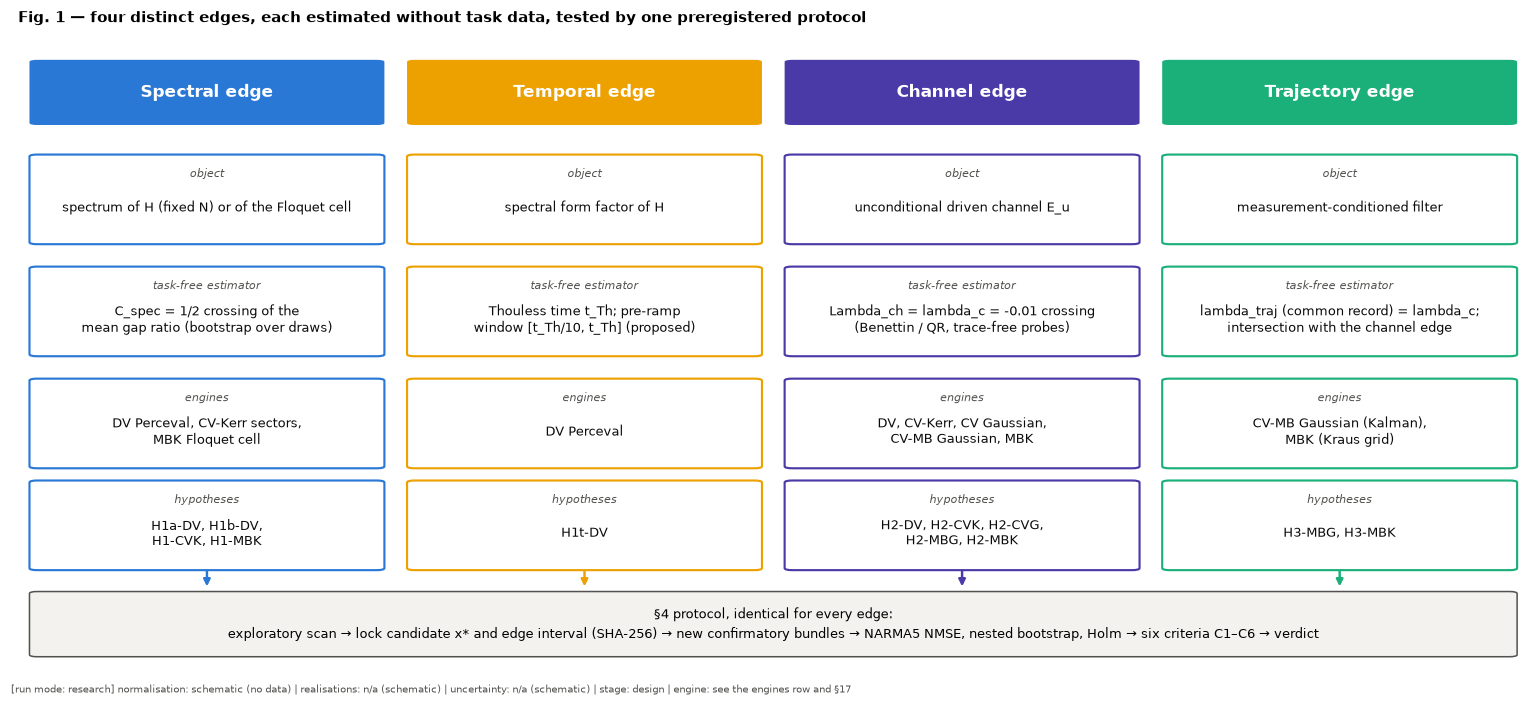

In [9]:
from matplotlib.patches import FancyBboxPatch
EDGE_WORKFLOW = [
    ("Spectral edge", "spectrum of H (fixed N) or of the Floquet cell", "C_spec = 1/2 crossing of the\nmean gap ratio (bootstrap over draws)", "DV Perceval, CV-Kerr sectors,\nMBK Floquet cell", "H1a-DV, H1b-DV,\nH1-CVK, H1-MBK", COL["dv"]),
    ("Temporal edge", "spectral form factor of H", "Thouless time t_Th; pre-ramp\nwindow [t_Th/10, t_Th] (proposed)", "DV Perceval", "H1t-DV", COL["yel"]),
    ("Channel edge", "unconditional driven channel E_u", "Lambda_ch = lambda_c = -0.01 crossing\n(Benettin / QR, trace-free probes)", "DV, CV-Kerr, CV Gaussian,\nCV-MB Gaussian, MBK", "H2-DV, H2-CVK, H2-CVG,\nH2-MBG, H2-MBK", COL["vio"]),
    ("Trajectory edge", "measurement-conditioned filter", "lambda_traj (common record) = lambda_c;\nintersection with the channel edge", "CV-MB Gaussian (Kalman),\nMBK (Kraus grid)", "H3-MBG, H3-MBK", COL["mb"]),
]
fig, ax = plt.subplots(figsize=(14, 6.2)); ax.set_xlim(0, 4); ax.set_ylim(0, 6.2); ax.axis("off"); ax.grid(False)
rows = [("object", 4.55), ("task-free estimator", 3.45), ("engines", 2.35), ("hypotheses", 1.35)]
for j, (name, obj, est, eng, hyp, col) in enumerate(EDGE_WORKFLOW):
    x0 = j + 0.05
    ax.add_patch(FancyBboxPatch((x0, 5.3), 0.9, 0.6, boxstyle="round,pad=0.02", fc=col, ec="none"))
    ax.text(x0 + 0.45, 5.6, name, ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    for (lab, y), txt in zip(rows, (obj, est, eng, hyp)):
        ax.add_patch(FancyBboxPatch((x0, y - 0.42), 0.9, 0.84, boxstyle="round,pad=0.02", fc="white", ec=col, lw=1.4))
        ax.text(x0 + 0.45, y + 0.25, lab, ha="center", va="center", fontsize=7.5, color=COL["ink2"], style="italic")
        ax.text(x0 + 0.45, y - 0.08, txt, ha="center", va="center", fontsize=8.2, color=COL["ink"])
    ax.annotate("", xy=(x0 + 0.45, 0.72), xytext=(x0 + 0.45, 0.93), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.6))
ax.add_patch(FancyBboxPatch((0.05, 0.08), 3.9, 0.6, boxstyle="round,pad=0.02", fc="#f3f2ee", ec=COL["ink2"], lw=1.0))
ax.text(2.0, 0.38, "§4 protocol, identical for every edge:\nexploratory scan → lock candidate x* and edge interval (SHA-256) → new confirmatory bundles → "
        "NARMA5 NMSE, nested bootstrap, Holm → six criteria C1–C6 → verdict", ha="center", va="center", fontsize=8.6, linespacing=1.5)
ax.set_title("Fig. 1 — four distinct edges, each estimated without task data, tested by one preregistered protocol", loc="left")
figmeta(fig, normalisation="schematic (no data)", realisations="n/a (schematic)", uncertainty="n/a (schematic)", stage="design", engine="see the engines row and §17")
plt.tight_layout(); plt.show()

# 4. Preregistered hypotheses and statistical criteria
Everything in this section was fixed before any new confirmatory data were generated. The code cell below turns it into a frozen dictionary, `PREREG`, and prints its SHA-256. Every verdict in §16 is computed from `PREREG` by the verdict engine of §6.6. Before a confirmatory run starts, the exploratory candidate is *locked*: its value and a hash are printed. §17 then checks that no confirmatory result changed a locked candidate.

## 4.1 Endpoints
* **Primary endpoint:** NARMA5 test NMSE (lower is better). It is the same for every engine and hypothesis, and is not changed after confirmatory data exist.
* **Secondary endpoints:** NARMA10 NMSE, linear MC, Dambre linear and nonlinear IPC, delayed XOR accuracy, 3-bit parity accuracy, effective feature rank, and record MI (MB models).
  * They are corrected with **Benjamini–Hochberg** FDR at $q=0.05$ within each engine.
  * They can never override a failed primary endpoint.
* **Primary family:** all primary-endpoint tests of all hypothesis–engine pairs, corrected with **Holm–Bonferroni** at $\alpha=0.05$.

## 4.2 Common random numbers
* **Realisation bundle.** A realisation $r$ is one *bundle*: disorder/network draw, input sequence $u^{(r)}$, initial state, and noise/innovation stream. It is generated before the scan, from `rng_for(bank, stage, r)`.
* **Pairing.** The same bundle is used at every parameter value, so comparisons across parameters are paired.
* **Splits.** Train/validation/test partitions are identical for all bundles.
* **Banks.** The **exploratory** and **confirmatory** banks use different stage tags, i.e. independent streams. §6.6 checks that they share no seed or disorder draw.
* **Measurement noise.** "Same noise" means the same underlying uniform or standard-normal innovations. They are pushed through each state's own outcome distribution; raw outcomes are never forced to be equal.
* **Stored identifiers.** Every result row stores `bank`, `stage` and `r`.

## 4.3 Exploratory and confirmatory stages
1. **Exploratory.** A broad grid covers the regular, crossover and chaotic regimes (and the stable and unstable channel regimes where they exist). It uses $\ge30$ bundles per point in research mode. The candidate $x^\ast$ is the point with the lowest mean primary endpoint.
2. **Lock.** $x^\ast$ and the task-independent edge estimates are frozen.
3. **Confirmatory grid.** It consists of $\{x^\ast$, the two exploratory neighbours of $x^\ast$, the independent edge estimate(s), both scan endpoints$\}$. It is evaluated on $\ge50$ new bundles per point in research mode. Confirmatory results are never used to move $x^\ast$.

**Grid revision recorded before any research-mode data (not a post-hoc change).** The MBK meter-transmissivity grid originally ended at $T_m=0.95$. The smoke validation run, after the channel-exponent correction of §6.5, showed $\Lambda_{\rm ch}<\lambda_c$ at every grid point: the unconditional MBK channel contracts roughly like $\ln\sqrt{T_m}$, so its $\lambda_c$ crossing lies near $T_m\approx0.98$, outside the grid. The grid was therefore extended to $T_m\in\{0.98,0.99,0.995\}$ (smoke: 0.99), so that H2-MBK and H3-MBK are testable. No task data informed the change, and smoke runs cannot yield verdicts.

## 4.4 Hierarchical uncertainty
For every configuration and bundle, the readout is refitted $R_{\rm fit}$ times on block-bootstrapped training sets. $\lambda$ is re-selected on validation each time, which covers readout fitting and hyperparameter selection. The squared test errors are stored per test block. The **nested bootstrap** then resamples at three levels: (i) bundles, i.e. disorder, input sequence, initial state and noise stream; (ii) one readout refit per bundle; (iii) test blocks. Each replicate recomputes every point's NMSE on the resampled data, paired across points. From it the notebook reports:
* the mean and median;
* the 95 % interval;
* the paired difference between the candidate and each endpoint, with its interval;
* the standardised paired effect size $d_z=\bar\Delta/s_\Delta$;
* $P(\text{candidate beats both endpoints})$, the fraction of replicates;
* the readout-regularisation sensitivity ($\lambda\times\{0.1,10\}$);
* the number of independent bundles.

The paired $p$-value is the one-sided Wilcoxon signed-rank test on per-bundle differences.

## 4.5 EOC-performance correspondence: all six criteria are required
* **C1** The edge is estimated without task data. This is recorded by the estimator itself.
* **C2** The confirmatory optimum is distinguishable from **both** scan endpoints: Holm-adjusted $p<0.05$ in the primary family for each paired comparison, and $d_z\ge0.3$ for each.
* **C3** The interval of the confirmatory optimum location intersects the independent edge interval.
  * *Optimum interval:* the 2.5–97.5 % range of the bootstrap arg-min over the confirmatory grid.
  * *Edge interval:* the 95 % CI of the edge estimator.
* **C4** The paired improvement survives: $P(\text{beats both})\ge0.95$ **and** C2.
* **C5** Stability under all of the following:
  * dropping the neighbour points from the confirmatory grid (grid density);
  * $\lambda\times0.1$ and $\lambda\times10$ (readout regularisation).

  In each case the optimum stays in the edge interval, and the endpoint improvements keep their sign with unadjusted $p<0.05$.
* **C6** No point involved is divergent, non-converged or excluded. Divergent points are retained and classified, never dropped.

**Confidence-interval overlap alone (C3) is never sufficient.**

## 4.6 Verdicts (the only allowed values)
* **supported**: C1–C6 all hold.
* **evidence against**: C1 holds, the edge interval is finite, and either
  * the confirmatory optimum satisfies C2 and its interval is disjoint from the edge interval; or
  * the edge point itself is significantly worse than the confirmatory optimum (Holm $p<0.05$, $d_z\ge0.3$).
* **inconclusive because underpowered**: neither of the above. This is also the forced verdict in smoke mode, for any phase executed at smoke level, and whenever fewer than 50 confirmatory bundles were used.
* **not testable with the implemented model**: the edge does not exist in the model (no many-body spectrum, no trajectories), or its estimator finds no crossing within the scanned range.

The failed criteria are listed next to every verdict.

In [10]:
PREREG = dict(
    primary_endpoint="NARMA5 NMSE", lower_is_better=True,
    secondary_endpoints=["NARMA10 NMSE", "MC", "IPC_lin", "IPC_nonlin", "XOR(b_k-1,b_k-2) acc", "parity3 acc", "eff_rank"],
    primary_correction="holm", secondary_correction="benjamini-hochberg", alpha=0.05, fdr_q=0.05,
    min_effect_dz=0.3, min_p_beats_both=0.95, n_explore_min=30, n_confirm_min=50,
    lambda_c=-0.01, lambda_perturbations=[0.1, 10.0], refits_research=10, block=50,
    hypotheses=[
        dict(id="H1a-DV", engine="DV (Perceval)", family="H1", param="g=U/J at tau~_long", edge="spectral C_spec=1/2 crossing, low-g side"),
        dict(id="H1b-DV", engine="DV (Perceval)", family="H1", param="g=U/J at tau~_long", edge="spectral C_spec=1/2 crossing, high-g side"),
        dict(id="H1t-DV", engine="DV (Perceval)", family="H1", param="tau~ at g_chaos", edge="pre-ramp window [t_Th/10, t_Th] (proposed)"),
        dict(id="H2-DV", engine="DV (Perceval)", family="H2", param="g=U/J at tau~_long", edge="Lambda_ch = lambda_c crossing"),
        dict(id="H1-CVK", engine="CV Kerr (Piquasso)", family="H1", param="g=U/J", edge="C_w=1/2 crossing (phase-randomised preparation, >=95% resolved weight)"),
        dict(id="H2-CVK", engine="CV Kerr (Piquasso)", family="H2", param="g=U/J", edge="Lambda_ch = lambda_c crossing"),
        dict(id="H2-CVG", engine="CV Gaussian (Piquasso)", family="H2", param="interferometer coupling kappa", edge="Lambda_ch = lambda_c crossing"),
        dict(id="H2-MBG", engine="CV-MB Gaussian (PhotoGraphiQ)", family="H2", param="feedback T", edge="Lambda_ch = lambda_c crossing"),
        dict(id="H3-MBG", engine="CV-MB Gaussian (PhotoGraphiQ)", family="H3", param="(T, eta)", edge="intersection of channel and common-record trajectory edges"),
        dict(id="H1-MBK", engine="CV-MB Kerr, ideal logical gates (PhotoGraphiQ/Piquasso)", family="H1", param="Kerr chi", edge="Floquet-cell C_spec=1/2 crossing"),
        dict(id="H2-MBK", engine="CV-MB Kerr, ideal logical gates (PhotoGraphiQ/Piquasso)", family="H2", param="meter transmissivity T_m", edge="Lambda_ch = lambda_c crossing"),
        dict(id="H3-MBK", engine="CV-MB Kerr, ideal logical gates (PhotoGraphiQ/Piquasso)", family="H3", param="(chi, T_m)", edge="intersection of channel and common-record trajectory edges"),
    ],
    verdicts=["supported", "evidence against", "inconclusive because underpowered", "not testable with the implemented model"],
)
PREREG_SHA256 = hashlib.sha256(json.dumps(PREREG, sort_keys=True).encode()).hexdigest()
LOCKS = {}

def lock_candidate(hid, **values):
    """Freeze an exploratory candidate and its independent edge estimate before the confirmatory stage."""
    assert hid not in LOCKS, f"{hid} already locked"
    blob = json.dumps(values, sort_keys=True, default=float)
    LOCKS[hid] = dict(values, sha256=hashlib.sha256(blob.encode()).hexdigest()[:16], locked_at=time.strftime("%Y-%m-%d %H:%M:%S"))
    print(f"LOCKED {hid}: {blob}  sha256[:16]={LOCKS[hid]['sha256']}")
    return LOCKS[hid]

print("PREREG sha256:", PREREG_SHA256)
display(pd.DataFrame(PREREG["hypotheses"]).set_index("id"))

PREREG sha256: 76a84a4a1a91523c8cc72ead5253709d442954844b48695ac6bd9e5c7aaf5c11


,engine,family,param,edge
id,,,,
H1a-DV,DV (Perceval),H1,g=U/J at tau~_long,"spectral C_spec=1/2 crossing, low-g side"
H1b-DV,DV (Perceval),H1,g=U/J at tau~_long,"spectral C_spec=1/2 crossing, high-g side"
H1t-DV,DV (Perceval),H1,tau~ at g_chaos,"pre-ramp window [t_Th/10, t_Th] (proposed)"
H2-DV,DV (Perceval),H2,g=U/J at tau~_long,Lambda_ch = lambda_c crossing
H1-CVK,CV Kerr (Piquasso),H1,g=U/J,C_w=1/2 crossing (phase-randomised preparation...
H2-CVK,CV Kerr (Piquasso),H2,g=U/J,Lambda_ch = lambda_c crossing
H2-CVG,CV Gaussian (Piquasso),H2,interferometer coupling kappa,Lambda_ch = lambda_c crossing
H2-MBG,CV-MB Gaussian (PhotoGraphiQ),H2,feedback T,Lambda_ch = lambda_c crossing
H3-MBG,CV-MB Gaussian (PhotoGraphiQ),H3,"(T, eta)",intersection of channel and common-record traj...


# 5. Source-notebook audit
The audit covers the previous version of this notebook (every section, stored output, statistical procedure and engine call) and the three source notebooks.
* **5.1** is the audit table.
* **5.2** extracts the source notebooks' stored regression values programmatically.
* **5.3** holds the frozen quick-profile results of the previous version. They are labelled as **frozen reference data**, because this file is modified in place and the previous outputs no longer exist in it.

The eight findings the audit had to verify, rather than assume, are **recomputed** in §6.9, together with a ninth found during this revision: a flaw in the previous channel-exponent estimator. That is the first point at which the tested utilities exist, and it precedes every new scientific result. The notebook stops there if a recomputation contradicts the frozen record in a way that is not documented.

## 5.1 Audit table of the previous version

In [11]:
AUDIT = pd.DataFrame([
    ("DV Bose-Hubbard spectra", "exact diagonalisation per disorder draw, <r> -> C_spec, bootstrap over draws", "NumPy (hopping validated vs Perceval)",
     "exact adapter", "regular-chaotic-regular in U/J at two sizes; edges with CIs", "only 2 sizes; low edge drifts with size", "keep; add third size in research mode"),
    ("DV SFF / Thouless", "unfolded filtered connected SFF, log-smoothed ramp criterion", "NumPy", "exact adapter",
     "t_Th = 84.7 [80.5, 89.1] at g_chaos; no ramp at edge/regular", "Thouless time at one g only", "keep; report as temporal edge with CI"),
    ("DV reservoir (Phase 1)", "port refresh + exp(-iHt), 2 disorder realisations, optimum z-test vs ends, CI overlap = correspondence",
     "Perceval (generator, port states) + Kerr adapter", "engine-compiled + adapter", "NARMA5 optimum g=0.106, CI [0.03, 16.9], not distinguishable",
     "2 realisations; CI overlap used as correspondence; no confirmatory stage", "CRN banks, >=30/50 realisations, nested bootstrap, locked candidates, 6 criteria"),
    ("CV Gaussian (Piquasso)", "native GaussianSimulator program per round trip; kappa and R scans", "Piquasso", "native",
     "Lambda crosses 0 at kappa~1.12; NARMA5 optimum not at the edge", "2 networks per point", "research-scale H2 test with confirmatory networks"),
    ("CV Kerr / Bose-Hubbard", "multi-sector Fock density matrix, coherent replacement, C_w over sectors with D>=20", "Piquasso (gates validated) + NumPy propagation",
     "engine-compiled + adapter", "<=7% of the state in sectors used for C_w", "C_w not interpretable; inter-sector coherence ignored; 1 realisation",
     "Phase 2: resolved weight >= 99%, coherence analysis, sector-conditioned tasks, convergence"),
    ("CV-MB Gaussian (PhotoGraphiQ)", "pattern -> gaussian_channel, iterated; QR exponent", "PhotoGraphiQ (+ Piquasso rollouts for validation)", "engine-compiled",
     "Lambda edge only at scale 4 (T~0.46); no many-body spectrum", "2 encodings per point; no trajectories", "H2 test at research scale; Gaussian trajectory edge (Phase 4)"),
    ("CV-MBQC Kerr Floquet", "passive teleported hopping layer + logical Kerr, fixed N", "PhotoGraphiQ layer + Piquasso Kerr", "engine-compiled + adapter",
     "COE-like crossover chi~0.12; NARMA5 optimum chi=0.012 (regular side) at l=6", "passive cell is not the active MB-QRC architecture",
     "keep as controlled comparison only; Phase 5 selects the active-cell route"),
    ("Active MB cell (C_Z F D + Kerr)", "truncated Fock matrix", "Piquasso Fock", "native (truncated)", "unitarity defect ~1.0 at cutoffs 10 and 16",
     "not a physical result", "not retained as a physical model (Phase 5)"),
    ("Measurement trajectories", "discussed only", "PhotoGraphiQ piquasso-fock demo", "native demo", "no trajectory exponent",
     "the trajectory edge (4th edge) was never computed", "Phase 4: two coupling protocols, validated, edge maps"),
    ("Cross-engine collapse", "nested F-test of pooled vs engine-specific quadratics", "all", "-", "rejected for C_spec, Lambda, d_temp",
     "in-sample test; no held-out validation; no partial pooling", "held-out model comparison: shared / engine-specific / hierarchical"),
    ("Channel exponent (DV, CV Kerr)", "Benettin iteration on renormalised traceless probes", "NumPy on engine channels", "-", "Lambda values used for edges and the collapse test",
     "no re-projection onto Tr = 0: round-off along the fixed point grows and strongly contracting channels read Lambda ~ 0 (finding 9)",
     "re-project every step (detrace); validate against exact superoperator spectra (P6.contract, N6.DV.lyap, P11.lyap)"),
    ("Statistics", "percentile bootstrap of optimum location; z>2 vs ends", "-", "-", "verdicts 'trend only'", "no preregistration, no multiplicity correction, no independent confirmation",
     "preregistered 6-criterion verdict engine, Holm + BH, nested bootstrap"),
    ("Environment", "CPU only; branch-pinned repositories", "-", "-", "executed locally", "moving branch head; no GPU; no checkpointing",
     "commit pins, GPU backend with validation, checkpoint/resume, run registry"),
], columns=["Component", "Existing method", "Physical engine", "Native or adapter", "Current evidence", "Main problem", "Required change"])
with pd.option_context("display.max_colwidth", 70, "display.width", 250):
    display(AUDIT.set_index("Component"))

,Existing method,Physical engine,Native or adapter,Current evidence,Main problem,Required change
Component,,,,,,
DV Bose-Hubbard spectra,"exact diagonalisation per disorder draw, <r> -> C_spec, bootstrap ...",NumPy (hopping validated vs Perceval),exact adapter,regular-chaotic-regular in U/J at two sizes; edges with CIs,only 2 sizes; low edge drifts with size,keep; add third size in research mode
DV SFF / Thouless,"unfolded filtered connected SFF, log-smoothed ramp criterion",NumPy,exact adapter,"t_Th = 84.7 [80.5, 89.1] at g_chaos; no ramp at edge/regular",Thouless time at one g only,keep; report as temporal edge with CI
DV reservoir (Phase 1),"port refresh + exp(-iHt), 2 disorder realisations, optimum z-test ...","Perceval (generator, port states) + Kerr adapter",engine-compiled + adapter,"NARMA5 optimum g=0.106, CI [0.03, 16.9], not distinguishable",2 realisations; CI overlap used as correspondence; no confirmatory...,"CRN banks, >=30/50 realisations, nested bootstrap, locked candidat..."
CV Gaussian (Piquasso),native GaussianSimulator program per round trip; kappa and R scans,Piquasso,native,Lambda crosses 0 at kappa~1.12; NARMA5 optimum not at the edge,2 networks per point,research-scale H2 test with confirmatory networks
CV Kerr / Bose-Hubbard,"multi-sector Fock density matrix, coherent replacement, C_w over s...",Piquasso (gates validated) + NumPy propagation,engine-compiled + adapter,<=7% of the state in sectors used for C_w,C_w not interpretable; inter-sector coherence ignored; 1 realisation,"Phase 2: resolved weight >= 99%, coherence analysis, sector-condit..."
CV-MB Gaussian (PhotoGraphiQ),"pattern -> gaussian_channel, iterated; QR exponent",PhotoGraphiQ (+ Piquasso rollouts for validation),engine-compiled,Lambda edge only at scale 4 (T~0.46); no many-body spectrum,2 encodings per point; no trajectories,H2 test at research scale; Gaussian trajectory edge (Phase 4)
CV-MBQC Kerr Floquet,"passive teleported hopping layer + logical Kerr, fixed N",PhotoGraphiQ layer + Piquasso Kerr,engine-compiled + adapter,COE-like crossover chi~0.12; NARMA5 optimum chi=0.012 (regular sid...,passive cell is not the active MB-QRC architecture,keep as controlled comparison only; Phase 5 selects the active-cel...
Active MB cell (C_Z F D + Kerr),truncated Fock matrix,Piquasso Fock,native (truncated),unitarity defect ~1.0 at cutoffs 10 and 16,not a physical result,not retained as a physical model (Phase 5)
Measurement trajectories,discussed only,PhotoGraphiQ piquasso-fock demo,native demo,no trajectory exponent,the trajectory edge (4th edge) was never computed,"Phase 4: two coupling protocols, validated, edge maps"


## 5.2 Programmatic extraction of the source notebooks' stored results
For each source notebook found in §2.3, the stored regression targets are parsed from its saved outputs. The regular expressions are anchored on the cell *source*, not on the cell index. If a notebook is absent, as on a fresh Colab runtime, the previous version's frozen copy of the value is used and is labelled **frozen**. Regression tests downstream read `SOURCE_VALUES`, which records where each value came from.

In [12]:
SOURCE_REFERENCE_FROZEN = {   # frozen copies (previous version), with the source cell they were read from
    "DV fading rate_echo, enc A, eta=0.5 (mean of 5 seeds)": (0.6970, "dv: cell defining fit_rate (fading memory table)"),
    "DV fading rate_echo, enc A, eta=0.7 (mean of 5 seeds)": (0.3710, "dv: cell defining fit_rate (fading memory table)"),
    "DV MC (corr^2), enc A, eta=0.5 (mean of 5 seeds)": (2.8472, "dv: cell defining ridge_predict (MC table)"),
    "CV covariance contraction rate, R=0.75, N=3": (0.75003, "cv: cell defining record_check (forgetting table)"),
    "CV ideal MC, N=3, R=0.75 (mean of 3 networks)": (3.865, "cv: cell defining ideal_capacity_run (memory vs R)"),
    "MB temporal XOR test accuracy, T=0.4": (0.966, "mb: cell defining run_temporal_xor"),
    "MB NARMA5 var-normalised median, N=10 (5 realisations)": (0.174206, "mb: cell defining narma (NARMA sweep)"),
}

def _nb_outputs(path, anchor):
    import nbformat
    nb = nbformat.read(path, as_version=4)
    for c in nb.cells:
        if c.cell_type == "code" and anchor in c.source:
            return "\n".join(o.get("text", "") if o.output_type == "stream" else o.get("data", {}).get("text/plain", "") for o in c.get("outputs", []))
    return None

def _row_value(text, pattern, group=1):
    m = re.search(pattern, text or "", re.M)
    return float(m.group(group)) if m else None

SOURCE_EXTRACTORS = {
    "DV fading rate_echo, enc A, eta=0.5 (mean of 5 seeds)": ("DV (Perceval)", "def fit_rate(D)", r"^A\s+0\.00.*?\n\s+0\.30.*?\n\s+0\.50\s+\S+\s+(\S+)"),
    "DV fading rate_echo, enc A, eta=0.7 (mean of 5 seeds)": ("DV (Perceval)", "def fit_rate(D)", r"^A\s+0\.00.*?\n(?:.*\n){2}\s+0\.70\s+\S+\s+(\S+)"),
    "DV MC (corr^2), enc A, eta=0.5 (mean of 5 seeds)": ("DV (Perceval)", "def ridge_predict", r"^A\s+0\.00.*?\n.*?\n\s+0\.50\s+\S+\s+(\S+)"),
    "CV covariance contraction rate, R=0.75, N=3": ("CV (Piquasso)", "def record_check", r"^\d+\s+0\.75\s+loop covariance \|\|dsigma\|\|_F\s+(\S+)"),
    "CV ideal MC, N=3, R=0.75 (mean of 3 networks)": ("CV (Piquasso)", "def ideal_capacity_run", r"^0\.75\s+\S+\s+\S+\s+(\S+)"),
    "MB temporal XOR test accuracy, T=0.4": ("CV-MB (PhotoGraphiQ/ML)", "def run_temporal_xor", r"paper setup \(recurrence, ideal\)\s+\S+\s+\S+\s+(\S+)"),
    "MB NARMA5 var-normalised median, N=10 (5 realisations)": ("CV-MB (PhotoGraphiQ/ML)", "def narma(u, d)", r"^5 6\s.*\n\s+10\s+(\S+)"),
}
SOURCE_VALUES, src_rows = {}, []
for key, (nbk, anchor, pat) in SOURCE_EXTRACTORS.items():
    frozen, where = SOURCE_REFERENCE_FROZEN[key]
    path = SOURCE_PATHS.get(nbk)
    val = _row_value(_nb_outputs(path, anchor), pat) if path else None
    SOURCE_VALUES[key] = (val, "extracted") if val is not None else (frozen, "frozen")
    src_rows.append(dict(quantity=key, notebook=nbk, extracted=val if val is not None else ("notebook absent" if path is None else "pattern not found"),
                         frozen=frozen, agree=(abs(val - frozen) <= 1e-9 * max(1, abs(frozen)) + 5e-5) if val is not None else None, origin=SOURCE_VALUES[key][1]))
SRC_DF = pd.DataFrame(src_rows)
with pd.option_context("display.max_colwidth", 60, "display.width", 220):
    display(SRC_DF)
_ext = SRC_DF[SRC_DF.origin == "extracted"]
record_test("S5.extract", "source-notebook regression values: programmatic extraction agrees with the previous version's frozen copies",
            f"{int(_ext.agree.sum())} of {len(_ext)} extracted agree; {int((SRC_DF.origin == 'frozen').sum())} frozen (source absent or unparsed)",
            "all extracted values agree", bool(_ext.agree.all()) if len(_ext) else True, section_ref="5", category="engine")

,quantity,notebook,extracted,frozen,agree,origin
0,"DV fading rate_echo, enc A, eta=0.5 (mean of 5 seeds)",DV (Perceval),0.697000,0.697000,True,extracted
1,"DV fading rate_echo, enc A, eta=0.7 (mean of 5 seeds)",DV (Perceval),0.371000,0.371000,True,extracted
2,"DV MC (corr^2), enc A, eta=0.5 (mean of 5 seeds)",DV (Perceval),2.847200,2.847200,True,extracted
3,"CV covariance contraction rate, R=0.75, N=3",CV (Piquasso),0.750030,0.750030,True,extracted
4,"CV ideal MC, N=3, R=0.75 (mean of 3 networks)",CV (Piquasso),3.865000,3.865000,True,extracted
5,"MB temporal XOR test accuracy, T=0.4",CV-MB (PhotoGraphiQ/ML),0.966000,0.966000,True,extracted
6,"MB NARMA5 var-normalised median, N=10 (5 realisations)",CV-MB (PhotoGraphiQ/ML),0.174206,0.174206,True,extracted


PASS [S5.extract] source-notebook regression values: programmatic extraction agrees with the previous version's frozen copies: 7 of 7 extracted agree; 0 frozen (source absent or unparsed) (criterion all extracted values agree)


True

## 5.3 Frozen quick-profile results of the previous version
These values were copied programmatically from the saved outputs of the previous version: SHA-256 `2aa94726…`, quick profile, CPU. They are **frozen reference data, not new calculations**. §6.9 recomputes findings 1–5 with the current code; findings 6–8 concern the previous code's design and are verified from this record. The new analyses of §7–§16 supersede all of them.

In [13]:
FROZEN_ORIGINAL = dict(
    notebook_sha256=PRE_REVISION_NOTEBOOK_SHA256, profile="quick", legacy_master_seed=20260929,
    f1_dv_spectral=dict(g_chaos_L5=0.464159, C_max_L5=0.935002, edge_low_L5=(0.06797, 0.048, 0.0855), edge_high_L5=(4.983168, 4.24, 5.55),
                        edge_low_L6=(0.120056, 0.0952, 0.139), edge_high_L6=(5.050092, 4.3, 5.81), r_chaos=0.526, r_regular=0.392),
    f2_dv_optimum=dict(tau_long=84.7, t_Th_CI=(80.5, 89.1), g_opt_tau_long=0.106486, g_opt_CI=(0.03, 16.9), distinguishable=False,
                       best_narma5=0.209, best_at=dict(g=0.464, tau=3.98), tau_scan_opt_chaotic=3.981072, realisations=2),
    f3_gaussian=dict(cv_kappa_edge=1.118981, cv_narma5_opt_kappa=1.0, mb_edge_scale4=0.459354, mb_edges_scale_le2="none (Lambda<0 throughout)"),
    f4_cv_weight=dict(weight_in_resolved_sectors=[0.0726, 0.0289, 0.0314, 0.0615, 0.0628], g=[0.3, 1.0, 3.0, 10.0, 30.0], alpha=0.6, cutoffs=(7, 8), mean_photons=[0.8906, 0.5927, 0.6554, 0.9520, 1.0083]),
    f5_floquet=dict(cls="COE", chi_edge=(0.119168, 0.0938, 0.153), chi_chaos=1.51087, ell_Th=5.79, narma5_opt_chi_ell6=0.012054, narma5_opt_CI_ell6=(0.003, 0.195),
                    narma5_opt_chi_ell1=0.781887, distinguishable=False),
    f6_collapse=dict(C_spec=dict(F=6.874, p=0.000272), Lambda=dict(F=8.142, p=0.0), d_temp=dict(F=4.280, p=0.0067), verdict="rejected (in-sample F-test)"),
    f7_trajectory="measurement-trajectory exponent explicitly not implemented (section 14.5 of the previous version)",
    f8_engines="DV, CV-Kerr, MBQC-Kerr adapter-assisted; CV Gaussian native Piquasso; MB Gaussian PhotoGraphiQ-derived channel",
    active_cell=dict(unitarity_defect=(0.9962, 1.0000), cutoffs=(10, 16), r=(0.3488, 0.4289)),
)
display(pd.json_normalize(FROZEN_ORIGINAL, sep=" / ").T.rename(columns={0: "frozen value"}))

,frozen value
notebook_sha256,2aa947262f672dd24c071fd1c150673021ecce3c10c16e...
profile,quick
legacy_master_seed,20260929
f7_trajectory,measurement-trajectory exponent explicitly not...
f8_engines,"DV, CV-Kerr, MBQC-Kerr adapter-assisted; CV Ga..."
f1_dv_spectral / g_chaos_L5,0.464159
f1_dv_spectral / C_max_L5,0.935002
f1_dv_spectral / edge_low_L5,"(0.06797, 0.048, 0.0855)"
f1_dv_spectral / edge_high_L5,"(4.983168, 4.24, 5.55)"
f1_dv_spectral / edge_low_L6,"(0.120056, 0.0952, 0.139)"


# 6. Shared utilities and validation tests
This section defines every shared function and every engine, and tests them before any hypothesis is examined:
* the spectral diagnostics and their synthetic benchmarks (§6.1–6.3);
* the readout and task metrics (§6.4);
* the information and exponent estimators (§6.5);
* the statistics and the verdict engine (§6.6);
* the numerical infrastructure: checkpoint/resume, seeds, CPU/GPU agreement (§6.7);
* the physical engines with their validations and source-notebook regressions (§6.8);
* the audit gate (§6.9).

Each test is recorded with a category (physics, numerical, engine, statistics), and all of them are collected in the validation dashboard (§17).

## 6.1 Batched linear algebra on the selected device
Batched arrays have shape `(B, D, D)`, one slice per realisation bundle or trajectory. The helpers below keep them on the device selected in §2.4; `to_host` is called only on features and summaries.

In [14]:
def dag(a):
    return xp.conj(xp.swapaxes(a, -1, -2))

def herm_eig_batch(H):
    """Batched Hermitian eigendecomposition on the host (NumPy/LAPACK); returns device arrays."""
    E, V = np.linalg.eigh(np.asarray(H))
    return to_dev(E), to_dev(V)

def propagators(E, V, t):
    """U(t) = V diag(exp(-i E t)) V^dagger for a batch (E: (B, D), V: (B, D, D)), on the device."""
    return (V * xp.exp(-1j * E * t)[:, None, :]) @ dag(V)

def trace_distance_batch(a, b):
    """0.5 ||a - b||_1 for batches of Hermitian matrices (device)."""
    w = xp.linalg.eigvalsh(0.5 * ((a - b) + dag(a - b)))
    return 0.5 * xp.abs(w).sum(-1)

## 6.2 Bose–Hubbard core (§3.1)
The functions are validated in the previous version, and again here: `second_quantize_fast` against the direct oracle, Hermiticity, the class test and reflection symmetry.

In [15]:
def fock_basis(m, n):
    """All occupation tuples of n bosons in m modes, Perceval's descending order; len = C(m+n-1, n)."""
    if m == 1:
        return [(n,)]
    return [(k,) + rest for k in range(n, -1, -1) for rest in fock_basis(m - 1, n - k)]

def hopping_matrix(L, J=1.0, eps=None):
    """Single-particle matrix h with H_hop = sum_pq h_pq a_p^dag a_q on an open chain (h_ii = eps_i)."""
    h = np.diag(np.zeros(L) if eps is None else np.asarray(eps, float))
    for i in range(L - 1):
        h[i, i + 1] = h[i + 1, i] = -J
    return h

def second_quantize(h, basis):
    """Matrix of sum_pq h_pq a_p^dag a_q in a fixed-N Fock basis (independent second-quantisation oracle)."""
    idx = {b: i for i, b in enumerate(basis)}
    D, L = len(basis), len(basis[0])
    H = np.zeros((D, D), dtype=np.result_type(h, float))
    for j, b in enumerate(basis):
        for p in range(L):
            H[j, j] += h[p, p] * b[p]
            for q in range(L):
                if p != q and h[p, q] != 0 and b[q] > 0:
                    nb = list(b); amp = math.sqrt(b[q]); nb[q] -= 1
                    amp *= math.sqrt(nb[p] + 1); nb[p] += 1
                    H[idx[tuple(nb)], j] += h[p, q] * amp
    return H

_SQ_OPS = {}

def one_body_ops(basis):
    key = (len(basis), basis[0], basis[-1])
    if key not in _SQ_OPS:
        L = len(basis[0]); ops = {}
        for p_ in range(L):
            for q_ in range(L):
                h1 = np.zeros((L, L)); h1[p_, q_] = 1.0
                ops[(p_, q_)] = scipy.sparse.csr_matrix(second_quantize(h1, basis))
        _SQ_OPS[key] = ops
    return _SQ_OPS[key]

def second_quantize_fast(h, basis):
    """sum_pq h_pq E_pq from cached sparse E_pq = a_p^dag a_q (validated against second_quantize)."""
    ops = one_body_ops(basis); out = None
    for (p_, q_), E in ops.items():
        if h[p_, q_] != 0:
            out = E * h[p_, q_] if out is None else out + E * h[p_, q_]
    return out.toarray() if out is not None else np.zeros((len(basis), len(basis)), dtype=np.result_type(h, float))

def interaction_diag(basis, U, V=0.0):
    """Diagonal of U/2 sum_i n_i(n_i-1) + V sum_<ij> n_i n_j (open chain)."""
    n = np.asarray(basis, float)
    d = 0.5 * U * (n * (n - 1)).sum(1)
    if V:
        d = d + V * (n[:, :-1] * n[:, 1:]).sum(1)
    return d

def reflection_operator(basis):
    idx = {b: i for i, b in enumerate(basis)}; Pm = np.zeros((len(basis), len(basis)))
    for i, b in enumerate(basis):
        Pm[idx[b[::-1]], i] = 1.0
    return Pm

W_BH, V_BH = 1.0, 0.0            # model selected by the previous version's chaos-only audit (disorder W = 1 J, no cross-Kerr); re-verified in §6.9

def disorder(L, W, real, bank="spectral", stage="explore"):
    """On-site detunings of one realisation; (bank, stage) keep exploratory and confirmatory draws independent."""
    return rng_for("disorder", bank, stage, L, real).uniform(-W / 2, W / 2, L)

_BASIS_CACHE, _HOP_CACHE = {}, {}

def sector(L, N):
    if (L, N) not in _BASIS_CACHE:
        _BASIS_CACHE[(L, N)] = fock_basis(L, N)
    return _BASIS_CACHE[(L, N)]

def bh_hamiltonian(L, N, g, W=None, V=None, real=0, J=1.0, eps=None, bank="spectral", stage="explore"):
    """H_BH(g=U/J) in the fixed-N sector; `eps` overrides the disorder draw (used for legacy/matched runs)."""
    W = W_BH if W is None else W; V = V_BH if V is None else V
    B = sector(L, N); eps = disorder(L, W, real, bank, stage) if eps is None else np.asarray(eps)
    key = (L, N, J, tuple(np.round(eps, 15)))
    if key not in _HOP_CACHE:
        _HOP_CACHE[key] = second_quantize_fast(hopping_matrix(L, J, eps), B)
    return _HOP_CACHE[key] + np.diag(interaction_diag(B, g * J, V))

def spectral_norm(H):
    return float(np.abs(np.linalg.eigvalsh(H)).max())

with section("6.2 Bose-Hubbard core tests"):
    B0 = sector(5, 5); H_t = bh_hamiltonian(5, 5, 1.3, real=0)
    record_test("P6.herm", "H_BH Hermitian (real symmetric) in the Fock basis", np.abs(H_t - H_t.T).max(), "< 1e-12", np.abs(H_t - H_t.T).max() < 1e-12,
                section_ref="6.2", category="physics")
    _hr = hopping_matrix(5, 1.0, disorder(5, 1.0, 3)) + 0.3j * np.triu(np.ones((5, 5)), 1) - 0.3j * np.tril(np.ones((5, 5)), -1)
    _e = np.abs(second_quantize_fast(_hr, B0) - second_quantize(_hr, B0)).max()
    record_test("N6.sqfast", "cached one-body operators = direct second quantisation (complex Hermitian h)", _e, "< 1e-12", _e < 1e-12, section_ref="6.2")
    Pr = reflection_operator(B0); H_clean = bh_hamiltonian(5, 5, 1.3, W=0.0)
    record_test("P6.refl", "clean chain commutes with reflection; W>0 breaks it",
                f"clean {np.abs(Pr @ H_clean - H_clean @ Pr).max():.1e}, W=1 {np.abs(Pr @ H_t - H_t @ Pr).max():.2f}", "clean < 1e-12, W=1 > 0.1",
                np.abs(Pr @ H_clean - H_clean @ Pr).max() < 1e-12 and np.abs(Pr @ H_t - H_t @ Pr).max() > 0.1, section_ref="6.2", category="physics")
    # J = 0 onsite-interaction limit: H is diagonal with U/2 sum n(n-1) + sum eps n (exact)
    eps0 = disorder(5, 1.0, 0); HJ0 = second_quantize_fast(hopping_matrix(5, 0.0, eps0), B0) + np.diag(interaction_diag(B0, 2.0))
    nB = np.asarray(B0, float); exact = 0.5 * 2.0 * (nB * (nB - 1)).sum(1) + nB @ eps0
    record_test("P6.J0", "J = 0 limit: H is diagonal with U/2 sum n(n-1) + sum eps_i n_i", np.abs(HJ0 - np.diag(exact)).max(), "< 1e-12",
                np.abs(HJ0 - np.diag(exact)).max() < 1e-12, section_ref="6.2", category="physics")

PASS [P6.herm] H_BH Hermitian (real symmetric) in the Fock basis: 0 (criterion < 1e-12)
PASS [N6.sqfast] cached one-body operators = direct second quantisation (complex Hermitian h): 0 (criterion < 1e-12)
PASS [P6.refl] clean chain commutes with reflection; W>0 breaks it: clean 0.0e+00, W=1 3.73 (criterion clean < 1e-12, W=1 > 0.1)
PASS [P6.J0] J = 0 limit: H is diagonal with U/2 sum n(n-1) + sum eps_i n_i: 0 (criterion < 1e-12)
[6.2 Bose-Hubbard core tests] 0.0 s | peak host memory 754 MB | GPU pool 24 MB


## 6.3 Spectral diagnostics and synthetic benchmarks (§3.2)

PASS [P6.GOE] <r> of the synthetic GOE benchmark within 0.015 of 0.5359: 0.538 (criterion ±0.015)
PASS [P6.GUE] <r> of the synthetic GUE benchmark within 0.015 of 0.6027: 0.605 (criterion ±0.015)
PASS [P6.Poisson] <r> of the synthetic Poisson benchmark within 0.015 of 0.3863: 0.379 (criterion ±0.015)
PASS [P6.CUE] <r> of the synthetic CUE benchmark within 0.015 of 0.6027: 0.605 (criterion ±0.015)
PASS [P6.COE] <r> of the synthetic COE benchmark within 0.015 of 0.5359: 0.531 (criterion ±0.015)
PASS [P6.SFF] synthetic SFF benchmark: GOE ramp found (tau_Th < 0.1), none for Poisson: GOE 0.0107, Poisson nan (criterion GOE finite & < 0.1; Poisson NaN)
PASS [P6.FSFF] synthetic Floquet SFF benchmark: COE ensemble reaches the COE ramp: 0.0137 (criterion finite)
PASS [P6.class] antiunitary class tests: real symmetric -> GOE, complex Hermitian -> GUE: GOE, GUE (criterion GOE, GUE)
[6.3 spectral diagnostics: synthetic benchmarks] 2.6 s | peak host memory 754 MB | GPU pool 24 MB


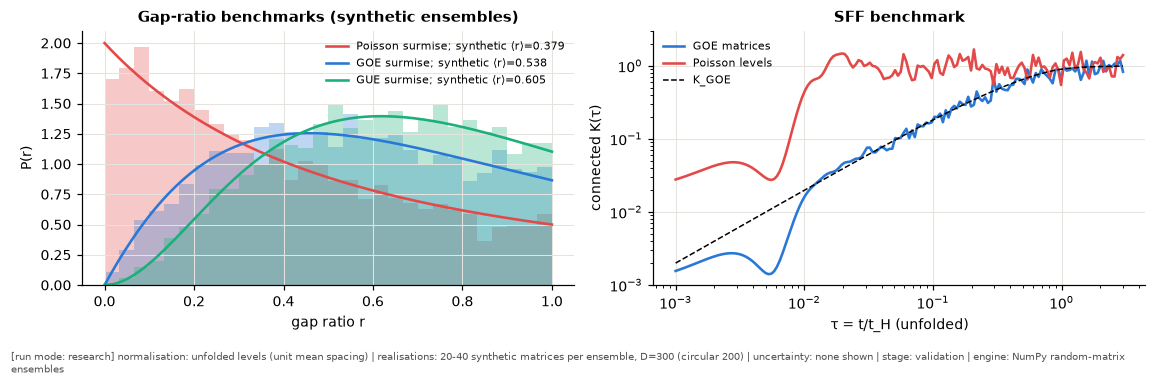

In [16]:
R_POISSON = 2 * math.log(2) - 1
R_ASYMPT = {"GOE": 0.5359, "GUE": 0.6027, "COE": 0.5359, "CUE": 0.6027}
BETA = {"GOE": 1, "COE": 1, "GUE": 2, "CUE": 2}
_ZB = {1: 8 / 27, 2: 4 * math.pi / (81 * math.sqrt(3))}

def p_r(r, kind):
    """Folded P(r): Poisson 2/(1+r)^2 and the Atas surmise for beta = 1, 2."""
    r = np.asarray(r, float)
    if kind == "Poisson":
        return 2 / (1 + r) ** 2
    b = BETA[kind]
    return 2 / _ZB[b] * (r + r * r) ** b / (1 + r + r * r) ** (1 + 1.5 * b)

_R_GRID = np.linspace(0, 1, 4001)

def cdf_r(r, kind):
    pdf = p_r(_R_GRID, kind); c = np.concatenate([[0], np.cumsum((pdf[1:] + pdf[:-1]) / 2 * np.diff(_R_GRID))])
    return np.interp(r, _R_GRID, c / c[-1])

def gap_ratios(E, frac=0.5, circular=False):
    E = np.sort(np.asarray(E, float))
    if circular:
        d = np.diff(np.concatenate([E, [E[0] + 2 * np.pi]])); d1, d2 = d, np.roll(d, -1)
    else:
        D = len(E); cut = int(round(D * (1 - frac) / 2))
        E = E[cut:D - cut] if cut > 0 else E
        d = np.diff(E); d1, d2 = d[:-1], d[1:]
    mx = np.maximum(d1, d2); ok = mx > 1e-12 * max(1.0, np.abs(E).max())
    return np.minimum(d1[ok], d2[ok]) / mx[ok]

def c_spec(rmean, rmt="GOE"):
    """PROPOSED normalised chaos coordinate: 0 = Poisson, 1 = large-D Wigner-Dyson of the symmetry class."""
    return (np.asarray(rmean) - R_POISSON) / (R_ASYMPT[rmt] - R_POISSON)

def bootstrap_groups(groups, stat=np.mean, n_boot=None, rng=None, alpha=0.05):
    n_boot = n_boot or CFG["boot"]; rng = rng or rng_for("bootstrap-groups")
    groups = [np.asarray(g) for g in groups if len(g)]
    full = float(stat(np.concatenate(groups))); idx = rng.integers(0, len(groups), size=(n_boot, len(groups)))
    boots = np.array([stat(np.concatenate([groups[i] for i in row])) for row in idx])
    return full, float(np.quantile(boots, alpha / 2)), float(np.quantile(boots, 1 - alpha / 2)), boots

def ks_distance(r, kind):
    r = np.sort(r); F = cdf_r(r, kind); n = len(r)
    return float(max(np.max(np.arange(1, n + 1) / n - F), np.max(F - np.arange(n) / n)))

def rmt_class_hamiltonian(H, tol=1e-12):
    return "GOE" if np.abs(np.imag(H)).max() <= tol * max(1.0, np.abs(H).max()) else "GUE"

def rmt_class_floquet(U_sym, tol=1e-9):
    return "COE" if np.abs(U_sym - U_sym.T).max() <= tol else "CUE"

def level_stats(spectra, rmt, frac=0.5, circular=False):
    groups = [gap_ratios(E, frac, circular) for E in spectra]
    m, lo, hi, boots = bootstrap_groups(groups); r = np.concatenate(groups)
    return dict(r=m, r_lo=lo, r_hi=hi, C=float(c_spec(m, rmt)), C_lo=float(c_spec(lo, rmt)), C_hi=float(c_spec(hi, rmt)), boots=boots,
                ks_poisson=ks_distance(r, "Poisson"), ks_rmt=ks_distance(r, rmt), n_ratios=len(r), ratios=r, groups=groups)

def unfold(E, deg=7):
    E = np.sort(E); x = (E - E.mean()) / E.std()
    return np.polyval(np.polyfit(x, np.arange(len(E), dtype=float), deg), x)

def k_rmt(t, rmt):
    t = np.asarray(t, float)
    if rmt in ("GUE", "CUE"):
        return np.minimum(t, 1.0)
    out = np.empty_like(t); a = t < 1
    out[a] = 2 * t[a] - t[a] * np.log1p(2 * t[a]); out[~a] = 2 - t[~a] * np.log((2 * t[~a] + 1) / (2 * t[~a] - 1))
    return out

def sff_moments(spectra, taus, eta=0.5, circular=False):
    Z, W2, rho_phys = [], [], []
    for E in spectra:
        if circular:
            e = np.sort(np.mod(E, 2 * np.pi)) / (2 * np.pi) * len(E); w = np.ones(len(e))
        else:
            e = unfold(E); m0 = 0.5 * (e.max() + e.min()); s0 = eta * (e.max() - e.min()) / 2
            w = np.exp(-0.5 * ((e - m0) / s0) ** 2)
            Es = np.sort(E); c = slice(int(0.25 * len(Es)), int(0.75 * len(Es)))
            rho_phys.append((c.stop - c.start - 1) / (Es[c][-1] - Es[c][0]))
        Z.append(np.exp(-2j * np.pi * np.outer(taus, e)) @ w); W2.append(np.sum(w ** 2))
    return np.array(Z), np.array(W2), (np.array(rho_phys) if rho_phys else None)

def connected_sff(Z, W2):
    return (np.mean(np.abs(Z) ** 2, 0) - np.abs(Z.mean(0)) ** 2) / W2.mean()

def thouless_tau(taus, K, rmt, eps=0.1, tau_max=0.5):
    Ks = np.exp(np.convolve(np.log(np.clip(K, 1e-300, None)), np.ones(11) / 11, mode="same"))
    dev = np.abs(np.log10(Ks / k_rmt(taus, rmt))); stop = np.searchsorted(taus, tau_max); ok = dev[:stop] < eps
    if not ok[-1]:
        return np.nan
    bad = np.flatnonzero(~ok); t_th = float(taus[0 if len(bad) == 0 else bad[-1] + 1])
    return t_th if t_th <= tau_max / 2 else np.nan

def thouless_estimate(Z, W2, taus, rmt, n_boot=300, rng=None):
    rng = rng or rng_for("thouless-boot")
    K = connected_sff(Z, W2); t0 = thouless_tau(taus, K, rmt)
    boots = np.array([thouless_tau(taus, connected_sff(Z[i], W2[i]), rmt) for i in (rng.integers(0, len(Z), len(Z)) for _ in range(n_boot))])
    fin = boots[np.isfinite(boots)]
    return dict(tau_th=t0, lo=float(np.quantile(fin, 0.025)) if len(fin) else np.nan, hi=float(np.quantile(fin, 0.975)) if len(fin) else np.nan,
                found_frac=float(np.isfinite(boots).mean()), K=K)

def crossing(xs, C, level=0.5, side="high"):
    """log-interpolated x where C crosses `level` moving away from its maximum (side = 'high' or 'low'); NaN if none."""
    xs = np.asarray(xs, float); C = np.asarray(C, float); i0 = int(np.nanargmax(C))
    rng_ = range(i0, len(xs) - 1) if side == "high" else range(i0, 0, -1)
    for i in rng_:
        j = i + 1 if side == "high" else i - 1
        if (C[i] - level) * (C[j] - level) <= 0 and C[i] != C[j]:
            f = (C[i] - level) / (C[i] - C[j]); return float(np.exp(np.log(xs[i]) + f * (np.log(xs[j]) - np.log(xs[i]))))
    return np.nan

def level_crossing(xs, y, level, direction="up"):
    """First log-interpolated x at which y crosses `level` going up (or down) along increasing x; NaN if none."""
    xs = np.asarray(xs, float); y = np.asarray(y, float)
    for i in range(len(xs) - 1):
        a, b = y[i] - level, y[i + 1] - level
        if np.isfinite(a) and np.isfinite(b) and ((direction == "up" and a < 0 <= b) or (direction == "down" and a > 0 >= b)):
            f = a / (a - b); return float(np.exp(np.log(xs[i]) + f * (np.log(xs[i + 1]) - np.log(xs[i]))))
    return np.nan

TAUS = np.geomspace(1e-3, 3.0, 160)

with section("6.3 spectral diagnostics: synthetic benchmarks"):
    rng = rng_for("rmt-selftest"); D0 = 300
    goe = [np.linalg.eigvalsh((lambda A: (A + A.T) / 2)(rng.normal(size=(D0, D0)))) for _ in range(40)]
    gue = [np.linalg.eigvalsh((lambda A: (A + A.conj().T) / 2)(rng.normal(size=(D0, D0)) + 1j * rng.normal(size=(D0, D0)))) for _ in range(20)]
    poi = [np.cumsum(rng.exponential(size=D0)) for _ in range(20)]
    def haar(d):
        Q, R = np.linalg.qr(rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d))); return Q * (np.diag(R) / np.abs(np.diag(R)))
    cue = [np.angle(np.linalg.eigvals(haar(200))) for _ in range(20)]
    coe = [np.angle(np.linalg.eigvals((lambda Uh: Uh.T @ Uh)(haar(200)))) for _ in range(20)]
    st = {k: level_stats(v, rmt, circular=circ) for k, v, rmt, circ in
          [("GOE", goe, "GOE", False), ("GUE", gue, "GUE", False), ("Poisson", poi, "GOE", False), ("CUE", cue, "CUE", True), ("COE", coe, "COE", True)]}
    for k, ref in [("GOE", R_ASYMPT["GOE"]), ("GUE", R_ASYMPT["GUE"]), ("Poisson", R_POISSON), ("CUE", R_ASYMPT["CUE"]), ("COE", R_ASYMPT["COE"])]:
        record_test(f"P6.{k}", f"<r> of the synthetic {k} benchmark within 0.015 of {ref:.4f}", st[k]["r"], "±0.015", abs(st[k]["r"] - ref) < 0.015,
                    section_ref="6.3", category="physics")
    Zg, Wg, _ = sff_moments(goe, TAUS); Zp, Wp, _ = sff_moments(poi, TAUS)
    th_g = thouless_tau(TAUS, connected_sff(Zg, Wg), "GOE"); th_p = thouless_tau(TAUS, connected_sff(Zp, Wp), "GOE")
    record_test("P6.SFF", "synthetic SFF benchmark: GOE ramp found (tau_Th < 0.1), none for Poisson", f"GOE {th_g:.3g}, Poisson {th_p}",
                "GOE finite & < 0.1; Poisson NaN", np.isfinite(th_g) and th_g < 0.1 and not np.isfinite(th_p), section_ref="6.3", category="physics")
    Zc, Wc, _ = sff_moments(coe, TAUS, circular=True); th_c = thouless_tau(TAUS, connected_sff(Zc, Wc), "COE")
    record_test("P6.FSFF", "synthetic Floquet SFF benchmark: COE ensemble reaches the COE ramp", th_c, "finite", np.isfinite(th_c), section_ref="6.3", category="physics")
    record_test("P6.class", "antiunitary class tests: real symmetric -> GOE, complex Hermitian -> GUE",
                f"{rmt_class_hamiltonian(np.diag([1., 2.]))}, {rmt_class_hamiltonian(np.array([[0, 1j], [-1j, 0]]))}", "GOE, GUE",
                rmt_class_hamiltonian(np.diag([1., 2.])) == "GOE" and rmt_class_hamiltonian(np.array([[0, 1j], [-1j, 0]])) == "GUE", section_ref="6.3", category="physics")
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.2))
rr = np.linspace(0, 1, 200)
for k, c in [("Poisson", COL["red"]), ("GOE", COL["dv"]), ("GUE", COL["mb"])]:
    axs[0].hist(st[k]["ratios"], bins=30, range=(0, 1), density=True, alpha=0.3, color=c)
    axs[0].plot(rr, p_r(rr, k), color=c, label=f"{k} surmise; synthetic ⟨r⟩={st[k]['r']:.3f}")
axs[0].set(xlabel="gap ratio r", ylabel="P(r)", title="Gap-ratio benchmarks (synthetic ensembles)"); axs[0].legend(fontsize=7)
axs[1].loglog(TAUS, connected_sff(Zg, Wg), color=COL["dv"], label="GOE matrices"); axs[1].loglog(TAUS, connected_sff(Zp, Wp), color=COL["red"], label="Poisson levels")
axs[1].loglog(TAUS, k_rmt(TAUS, "GOE"), "k--", lw=1, label="K_GOE"); axs[1].set(xlabel="τ = t/t_H (unfolded)", ylabel="connected K(τ)", ylim=(1e-3, 3), title="SFF benchmark")
axs[1].legend(fontsize=7)
figmeta(fig, normalisation="unfolded levels (unit mean spacing)", realisations="20-40 synthetic matrices per ensemble, D=300 (circular 200)",
        uncertainty="none shown", stage="validation", engine="NumPy random-matrix ensembles")
plt.tight_layout(); plt.show()
stop_on_failures("P6"); stop_on_failures("N6")

## 6.4 Readout, tasks and capacities (§3.5)
> **Established in literature.** Dambre capacity, Legendre targets, NARMA, ridge readouts.
> **Adapted here.** Every bundle has its own input sequence $u^{(r)}$. The targets, IPC design and null targets are built per sequence and cached.
> **Proposed novel element.** None.

**What `evaluate_features(X, design)` returns for one configuration and bundle.**
1. The **main fit.** Features are standardised with training statistics. Every target gets its own ridge $\lambda$, chosen on validation MSE from `ALPHAS`, and the test split is used once. From this fit come every secondary metric:
   * linear MC (delays $1..\tau_{\rm MC}$);
   * Dambre IPC by degree. A capacity counts only above the $1-0.05/n_{
m targets}$ quantile of the capacities of time-shuffled null targets, which controls the family-wise false-positive rate at 5 % over all IPC and MC targets. The previous version used the 99.5 % quantile per target, which lets roughly one spurious target in eight runs through (§6.4 test `N6.delay`);
   * numerical and entropy rank, and condition number;
   * all task NMSEs and accuracies.
2. **Primary-endpoint material for the nested bootstrap of §4.4:**
   * squared errors and target sums of squares per test block (50 steps) for the main fit, and for $R_{\rm fit}$ refits on block-bootstrapped training sets, with $\lambda$ re-selected on validation each time;
   * the NMSE at $\lambda^\ast\times0.1$ and $\lambda^\ast\times10$ (readout-regularisation sensitivity).

In [17]:
ALPHAS = np.logspace(-9, 2, 12)
BLOCK = PREREG["block"]

def make_splits(w, tr, va, te):
    return dict(tr=slice(w, w + tr), va=slice(w + tr, w + tr + va), te=slice(w + tr + va, w + tr + va + te), T=w + tr + va + te)

SPLITS = make_splits(*CFG["seq"])
SEQ_TXT = "washout/train/val/test = {}/{}/{}/{}".format(*CFG["seq"])

def delayed(x, tau):
    y = np.full(len(x), np.nan); y[tau:] = x[:len(x) - tau] if tau > 0 else x
    return y

def narma(u, d):
    """NARMA-d: y_k = 0.3 y_{k-1} + 0.05 y_{k-1} sum_{i=1..d} y_{k-i} + 1.5 x_{k-d} x_{k-1} + 0.1, x = u/2 in [0, 0.5]."""
    x = 0.5 * np.asarray(u, float); y = np.zeros(len(x))
    with np.errstate(over="ignore", invalid="ignore"):
        for k in range(d, len(x)):
            y[k] = 0.3 * y[k - 1] + 0.05 * y[k - 1] * y[k - d:k].sum() + 1.5 * x[k - d] * x[k - 1] + 0.1
            if not abs(y[k]) < 1e3:
                return np.full(len(x), np.nan)
    y[:d] = np.nan
    return y

def legendre_n(d, s):
    return math.sqrt(2 * d + 1) * npleg.legval(s, [0] * d + [1])

BINARY_TASKS = ("XOR(b_k-1,b_k-2)", "parity3")
TASK_NAMES = ["NARMA3", "NARMA5", "NARMA7", "NARMA10", "STM3", "NLSTM", "XOR(b_k-1,b_k-2)", "parity3"]

def task_targets(u):
    s = 2 * np.asarray(u) - 1; b = (np.asarray(u) > 0.5).astype(float)
    T = {f"NARMA{d}": narma(u, d) for d in (3, 5, 7, 10)}
    T["STM3"] = delayed(s, 3); T["NLSTM"] = delayed(legendre_n(2, s), 1)
    x = (delayed(b, 1) != delayed(b, 2)).astype(float); x[:2] = np.nan; T["XOR(b_k-1,b_k-2)"] = x
    p = (b + delayed(b, 1) + delayed(b, 2)) % 2; p[:2] = np.nan; T["parity3"] = p
    return T

def ipc_targets(s, max_deg, max_delay):
    Pd = {d: legendre_n(d, s) for d in range(1, max_deg + 1)}; specs = []

    def rec(tau, rem, cur):
        if tau > max_delay:
            if cur:
                specs.append(tuple(cur))
            return
        rec(tau + 1, rem, cur)
        for d in range(1, rem + 1):
            rec(tau + 1, rem - d, cur + [(tau, d)])
    rec(0, max_deg, [])
    Y = np.stack([np.prod([delayed(Pd[d], t) for t, d in sp], 0) for sp in specs], 1)
    return Y, np.array([sum(d for _, d in sp) for sp in specs]), specs

def input_sequence(bank, stage, r, T=None):
    """The input sequence of realisation bundle r (common to every parameter value of a scan)."""
    return rng_for("input", bank, stage, r).uniform(size=T or SPLITS["T"])

_DESIGN_CACHE = {}

def task_design(u, key=None):
    """Targets, IPC design, MC targets and shuffled null targets for one input sequence (cached by `key`)."""
    key = key or ("anon", hashlib.sha1(np.asarray(u).tobytes()).hexdigest()[:16])
    if key not in _DESIGN_CACHE:
        s = 2 * np.asarray(u) - 1; sp = SPLITS
        Y, deg, specs = ipc_targets(s, CFG["ipc_deg"], CFG["ipc_delay"])
        Ymc = np.stack([delayed(s, t) for t in range(1, CFG["mc_tau"] + 1)], 1)
        tt = task_targets(u); Tm = np.stack([tt[k] for k in TASK_NAMES], 1)
        _DESIGN_CACHE[key] = dict(u=np.asarray(u), Y=Y, deg=deg, specs=specs, Ymc=Ymc, T=Tm, key=key)
    return _DESIGN_CACHE[key]

def null_targets(design):
    """Time-shuffled null targets (permuted within each split), regenerated deterministically from the bundle key
    instead of being cached (they are large at research size)."""
    sp = SPLITS; Yall = np.hstack([design["Y"], design["Ymc"]]); rng = rng_for("null-targets", design["key"])
    cols = rng.integers(0, Yall.shape[1], CFG["n_null"]); Yn = Yall[:, cols]
    for part in (sp["tr"], sp["va"], sp["te"]):
        blk = Yn[part]; Yn[part] = np.take_along_axis(blk, np.argsort(rng.random(blk.shape), axis=0), axis=0)
    return Yn

class RidgeReadout:
    """Standardised features (train statistics) + intercept; per-target lambda chosen on validation MSE.
    `train_idx` overrides the training rows (block-bootstrap refits). The test split only produces final predictions."""

    def __init__(self, X, sp=SPLITS, alphas=ALPHAS, train_idx=None):
        self.sp, self.alphas = sp, alphas; tr = np.arange(sp["tr"].start, sp["tr"].stop) if train_idx is None else train_idx; self.tr = tr
        mu = X[tr].mean(0); sd = X[tr].std(0); sd = np.where(sd > 1e-12 * max(1.0, np.abs(mu).max()), sd, 1.0)
        self.Z = (X - mu) / sd
        self.Uu, self.s, self.Vt = np.linalg.svd(self.Z[tr], full_matrices=False)

    def fit_predict(self, Y, return_alpha=False):
        va, te = self.sp["va"], self.sp["te"]; Y = np.asarray(Y, float)
        ym = Y[self.tr].mean(0); UtY = self.Uu.T @ (Y[self.tr] - ym)
        best = np.full(Y.shape[1], np.inf); pred = np.zeros((te.stop - te.start, Y.shape[1])); ia = np.zeros(Y.shape[1], int)
        for k, a in enumerate(self.alphas):
            W = self.Vt.T @ ((self.s / (self.s ** 2 + a))[:, None] * UtY)
            mse = ((self.Z[va] @ W + ym - Y[va]) ** 2).mean(0); better = mse < best
            if better.any():
                best[better] = mse[better]; pred[:, better] = self.Z[te] @ W[:, better] + ym[better]; ia[better] = k
        return (best, pred, ia) if return_alpha else (best, pred)

    def predict_at(self, y, alpha):
        ym = y[self.tr].mean(); W = self.Vt.T @ ((self.s / (self.s ** 2 + alpha)) * (self.Uu.T @ (y[self.tr] - ym)))
        return self.Z[self.sp["te"]] @ W + ym

def capacity(pred, y):
    y = np.asarray(y); return 1 - ((y - pred) ** 2).sum(0) / ((y - y.mean(0)) ** 2).sum(0)

def feature_rank(Xtr):
    Z = Xtr - Xtr.mean(0); sd = Z.std(0); keep = sd > 1e-12 * max(1.0, np.abs(Xtr).max())
    s = np.linalg.svd(Z[:, keep] / sd[keep], compute_uv=False) if keep.any() else np.zeros(1)
    if s[0] == 0:
        return 0, 0.0, np.inf
    r = int((s > 1e-9 * s[0]).sum()); p = s[:r] ** 2 / (s[:r] ** 2).sum()
    return r, float(np.exp(-(p * np.log(p)).sum())), float((s[0] / s[r - 1]) ** 2)

def _block_sse(pred, y):
    nb = len(y) // BLOCK
    e = ((pred[:nb * BLOCK] - y[:nb * BLOCK]) ** 2).reshape(nb, BLOCK).sum(1)
    t = ((y[:nb * BLOCK] - y.mean()) ** 2).reshape(nb, BLOCK).sum(1)
    return e, t

def evaluate_features(X, design, refits=None, rng=None, secondary=True):
    """All metrics of one feature matrix (see the markdown above). Divergent features are flagged, never dropped."""
    refits = CFG["refits"] if refits is None else refits
    out = dict(diverged=not (np.isfinite(X).all() and np.abs(X).max() < 1e12))
    if out["diverged"]:
        return out
    sp = SPLITS; te = sp["te"]; T = design["T"]; ip = TASK_NAMES.index(PREREG["primary_endpoint"].split()[0])
    ro = RidgeReadout(X, sp)
    if secondary:
        Y, deg, Ymc, Yn = design["Y"], design["deg"], design["Ymc"], null_targets(design)
        out["rank"], out["eff_rank"], out["cond"] = feature_rank(X[sp["tr"]])
        ok_t = np.isfinite(T[sp["tr"].start:te.stop]).all(0)
        Yall = np.hstack([Y, Ymc, Yn, np.nan_to_num(T[:, ok_t])]); _, pred, ia = ro.fit_predict(Yall, return_alpha=True)
        nY, nM, nN = Y.shape[1], Ymc.shape[1], Yn.shape[1]
        C = capacity(pred[:, :nY + nM + nN], Yall[te, :nY + nM + nN]); Cipc, Cmc, Cn = C[:nY], C[nY:nY + nM], C[nY + nM:]
        theta = float(np.quantile(Cn, 1 - 0.05 / (nY + nM))); sig = Cipc > theta              # family-wise 5% over all IPC and MC targets
        out.update(theta=theta, IPC=float(Cipc[sig].sum()), IPC_lin=float(Cipc[sig & (deg == 1)].sum()), IPC_nonlin=float(Cipc[sig & (deg >= 2)].sum()),
                   MC=float(Cmc[Cmc > theta].sum()), MC_curve=np.clip(Cmc, 0, None), n_sig=int(sig.sum()), n_targets=nY)
        pt = pred[:, nY + nM + nN:]; j = 0
        for k, ok in zip(TASK_NAMES, ok_t):
            if not ok:
                out[f"{k} NMSE"] = np.nan; continue
            y = T[te, TASK_NAMES.index(k)]; p = pt[:, j]; j += 1
            out[f"{k} NMSE"] = float(((p - y) ** 2).mean() / y.var())
            if k in BINARY_TASKS:
                out[f"{k} acc"] = float(((p > 0.5) == (y > 0.5)).mean())
    # primary endpoint: main fit, refits and lambda sensitivity
    y = T[:, ip]
    if not np.isfinite(y[sp["tr"].start:te.stop]).all():
        out["primary_ok"] = False; return out
    yf = np.nan_to_num(y); best, pp, ia_p = ro.fit_predict(yf[:, None], return_alpha=True); pp = pp[:, 0]; a_star = ALPHAS[ia_p[0]]
    e0, t0 = _block_sse(pp, y[te]); sse = [e0]
    rng = rng or rng_for("refit", design["key"])
    trb = np.arange(sp["tr"].start, sp["tr"].stop); nbt = len(trb) // BLOCK
    for _ in range(refits):
        pick = rng.integers(0, nbt, nbt); idx = np.concatenate([trb[b * BLOCK:(b + 1) * BLOCK] for b in pick])
        _, pr = RidgeReadout(X, sp, train_idx=idx).fit_predict(yf[:, None]); sse.append(_block_sse(pr[:, 0], y[te])[0])
    lam_sens = {m: float(((ro.predict_at(yf, a_star * m) - y[te]) ** 2).mean() / y[te].var()) for m in PREREG["lambda_perturbations"]}
    out.update(primary_ok=True, primary=float(((pp - y[te]) ** 2).mean() / y[te].var()), alpha_star=float(a_star),
               sse_blocks=np.array(sse), sst_blocks=t0, lam_sens=lam_sens)
    return out

SUMMARY_KEYS = ["primary", "MC", "IPC", "IPC_lin", "IPC_nonlin", "rank", "eff_rank", "cond", "NARMA10 NMSE", "STM3 NMSE", "NLSTM NMSE",
                "XOR(b_k-1,b_k-2) acc", "parity3 acc"]

def summarize(ev):
    """Flat row for result tables (the arrays needed by the nested bootstrap are kept in separate columns)."""
    if ev.get("diverged"):
        return dict(diverged=True, primary=np.nan)
    d = {k: ev.get(k, np.nan) for k in SUMMARY_KEYS}; d["diverged"] = False; d["NARMA5 NMSE"] = ev.get("primary", np.nan)
    d["sse_blocks"] = ev.get("sse_blocks"); d["sst_blocks"] = ev.get("sst_blocks")
    for m, v in ev.get("lam_sens", {}).items():
        d[f"primary_lam_x{m:g}"] = v
    return d

In [18]:
with section("6.4 readout and capacity calibration"):
    # an exactly linear system: 5 independent input sequences (a single sequence's spurious nonlinear capacity fluctuates by ~0.02
    # per target at 400 test steps, so the calibration is judged on the mean, with a per-sequence ceiling)
    cal = []
    for r_ in range(5):
        u_ = input_sequence("calib", "validation", r_); d_ = task_design(u_, ("calib", r_))
        e_ = evaluate_features(np.nan_to_num(np.stack([delayed(2 * u_ - 1, t) for t in range(10)], 1)), d_); cal.append((e_["IPC_lin"], e_["MC"], e_["IPC_nonlin"]))
    cal = np.array(cal); u0 = input_sequence("calib", "validation", 0); des0 = task_design(u0, ("calib", 0))
    Xd = np.nan_to_num(np.stack([delayed(2 * u0 - 1, t) for t in range(10)], 1)); ev_d = evaluate_features(Xd, des0)
    record_test("N6.delay", "delay line s_k..s_{k-9} (5 sequences): degree-1 IPC exact, MC = 9, nonlinear IPC ~ 0",
                f"IPC_lin {np.round(cal[:, 0], 3).tolist()}, MC {np.round(cal[:, 1], 3).tolist()}, nonlin {np.round(cal[:, 2], 3).tolist()}",
                f"all IPC_lin {CFG['ipc_delay'] + 1}±0.05, all MC 9±0.1, mean nonlin < 0.05 and each < 0.1",
                np.all(np.abs(cal[:, 0] - (CFG["ipc_delay"] + 1)) < 0.05) and np.all(np.abs(cal[:, 1] - 9) < 0.1) and cal[:, 2].mean() < 0.05 and cal[:, 2].max() < 0.1,
                section_ref="6.4")
    # absence of train/test leakage: permuting the TEST targets must leave the fitted readout (validation choice) unchanged
    y5 = np.nan_to_num(des0["T"][:, TASK_NAMES.index("NARMA5")]); ro_ = RidgeReadout(Xd)
    b1, p1, a1 = ro_.fit_predict(y5[:, None], return_alpha=True); y5p = y5.copy(); te_ = SPLITS["te"]
    y5p[te_] = rng_for("leak").permutation(y5p[te_]); b2, p2, a2 = ro_.fit_predict(y5p[:, None], return_alpha=True)
    record_test("N6.leak", "no train/test leakage: permuting test targets leaves lambda choice and test predictions unchanged",
                f"|dpred| {np.abs(p1 - p2).max():.1e}, lambda index {a1[0]} vs {a2[0]}", "0 and equal", np.abs(p1 - p2).max() == 0 and a1[0] == a2[0],
                section_ref="6.4")
    record_test("N6.split", "train/validation/test index ranges disjoint and ordered", f"{SPLITS['tr']}, {SPLITS['va']}, {SPLITS['te']}", "tr < va < te",
                SPLITS["tr"].stop <= SPLITS["va"].start and SPLITS["va"].stop <= SPLITS["te"].start, section_ref="6.4")
    nb_ = len(ev_d["sst_blocks"]); assert (te_.stop - te_.start) % BLOCK == 0, "test length must be a multiple of the block length"
    nm_re = float(ev_d["sse_blocks"][0].sum() / ev_d["sst_blocks"].sum())
    record_test("N6.blocks", "per-block squared errors reproduce the primary NMSE of the main fit exactly", f"{nm_re:.8f} vs {ev_d['primary']:.8f}",
                "rel. diff < 1e-10", abs(nm_re - ev_d["primary"]) < 1e-10 * max(1e-12, ev_d["primary"]), section_ref="6.4")
print(f"{des0['Y'].shape[1]} IPC targets, {CFG['mc_tau']} MC delays, {CFG['n_null']} null targets; test blocks of {BLOCK} steps: {nb_}")
stop_on_failures("N6")

PASS [N6.delay] delay line s_k..s_{k-9} (5 sequences): degree-1 IPC exact, MC = 9, nonlinear IPC ~ 0: IPC_lin [7.0, 7.0, 7.0, 7.0, 7.0], MC [9.0, 9.0, 9.0, 9.0, 9.0], nonlin [0.0, 0.0, 0.0, 0.0, 0.0] (criterion all IPC_lin 7±0.05, all MC 9±0.1, mean nonlin < 0.05 and each < 0.1)
PASS [N6.leak] no train/test leakage: permuting test targets leaves lambda choice and test predictions unchanged: |dpred| 0.0e+00, lambda index 11 vs 11 (criterion 0 and equal)
PASS [N6.split] train/validation/test index ranges disjoint and ordered: slice(200, 1700, None), slice(1700, 2200, None), slice(2200, 3000, None) (criterion tr < va < te)
PASS [N6.blocks] per-block squared errors reproduce the primary NMSE of the main fit exactly: 0.15762374 vs 0.15762374 (criterion rel. diff < 1e-10)
[6.4 readout and capacity calibration] 5.9 s | peak host memory 981 MB | GPU pool 24 MB
119 IPC targets, 25 MC delays, 3000 null targets; test blocks of 50 steps: 16


## 6.5 Information and exponent estimators
> **Established in literature.** The Kraskov–Stögbauer–Grassberger (KSG) $k$-nearest-neighbour MI estimator [Kraskov *et al.* 2004]; Benettin iteration and QR accumulation for Lyapunov exponents.
> **Adapted here.** KSG with a **shuffle-null bias correction**: the mean of $n_{\rm shuf}$ estimates on independently permuted $u$ is subtracted, and the null's 95 % quantile is reported.
> **Proposed novel element.** None.

**Validation targets.**
* **MI.** Distributions with known mutual information:
  * a bivariate Gaussian, $I=-\tfrac12\ln(1-\rho^2)$;
  * a scalar–vector Gaussian, $I=\tfrac12\ln(\det\Sigma_X\det\Sigma_Y/\det\Sigma)$;
  * independence, $I=0$.
* **Exponents.**
  * **Known contractive CPTP map** $\rho\mapsto(1-p)\,U\rho U^\dagger+p\,\sigma$: its traceless sector contracts exactly by $1-p$, so $\Lambda=\ln(1-p)$. The map is tested at weak *and* strong contraction. Without re-projecting the probe onto $\mathrm{Tr}\,\delta=0$ after each step, the renormalised probe amplifies round-off along the fixed point, and a strongly contracting channel falsely reads $\Lambda\approx0$ (`detrace`).
  * **Engine channels.** The Benettin estimates of the DV (§6.8.1) and MBK (§11.4) engines are compared with $\ln|\lambda_2|$ of their exact superoperators (`channel_rate_exact`) at a constant input.
  * **Known unstable linear map** $A=a\,R(\theta)$: $\Lambda=\ln a$.

In [19]:
from scipy.spatial import cKDTree

def ksg_mi(x, y, k=4):
    """KSG estimator (algorithm 1, max-norm) of I(X;Y) in nats; x: (n,) or (n, dx), y: (n, dy)."""
    x = np.asarray(x, float).reshape(len(x), -1); y = np.asarray(y, float).reshape(len(y), -1)
    x = (x - x.mean(0)) / (x.std(0) + 1e-300); y = (y - y.mean(0)) / (y.std(0) + 1e-300)
    xy = np.hstack([x, y]); n = len(xy)
    eps = cKDTree(xy).query(xy, k + 1, p=np.inf)[0][:, -1]
    nx = cKDTree(x).query_ball_point(x, eps - 1e-12, p=np.inf, return_length=True) - 1
    ny = cKDTree(y).query_ball_point(y, eps - 1e-12, p=np.inf, return_length=True) - 1
    return float(ssp.digamma(k) + ssp.digamma(n) - np.mean(ssp.digamma(nx + 1) + ssp.digamma(ny + 1)))

def ksg_mi_corrected(x, y, k=4, n_shuf=10, rng=None):
    """Bias-corrected MI = raw - mean(shuffled-x nulls); also returns the null 95% quantile."""
    rng = rng or rng_for("ksg-null", len(x)); raw = ksg_mi(x, y, k)
    nulls = np.array([ksg_mi(rng.permutation(np.asarray(x)), y, k) for _ in range(n_shuf)])
    return dict(mi=raw - nulls.mean(), raw=raw, null_mean=float(nulls.mean()), null_q95=float(np.quantile(nulls, 0.95) - nulls.mean()))

def detrace(P):
    """Project operators (..., D, D) onto Tr = 0. A trace-preserving map keeps the trace-free subspace invariant, so in exact arithmetic
    this is the identity. Numerically it removes the round-off component along the fixed point (eigenvalue 1), which a renormalised
    Benettin probe otherwise amplifies by 1/|lambda_2| per step until it dominates: the estimate of a strongly contracting channel
    then collapses to ln 1 = 0 (tests P6.contract, N6.DV.lyap, P11.lyap)."""
    X_ = np if isinstance(P, np.ndarray) else xp; D = P.shape[-1]
    return P - (X_.trace(P, axis1=-2, axis2=-1) / D)[..., None, None] * X_.eye(D, dtype=P.dtype)

def channel_rate_exact(step, D):
    """Exact asymptotic contraction rate ln|lambda_2| of a linear trace-preserving map, from its full superoperator:
    step maps a batch of operators (n, D, D) (host arrays) to (n, D, D). Validation oracle for the Benettin exponents (small D only)."""
    E = np.eye(D * D, dtype=complex).reshape(D * D, D, D); M = to_host(step(E)).reshape(D * D, D * D).T
    return float(np.log(np.sort(np.abs(np.linalg.eigvals(M)))[::-1][1]))

def benettin(step, probes, K, burn=None, project=None):
    """Driven top exponent of a linear map sequence: step(k, X) applies the k-th map to a batch of probes X (list of arrays,
    host or device). The largest late-time growth rate over the probes (after a burn-in) is returned. project: optional
    projection applied after every step (detrace for trace-preserving maps on traceless probes)."""
    burn = K // 2 if burn is None else burn; acc = np.zeros(len(probes)); X = [p / xp.linalg.norm(p) if hasattr(p, "shape") else p for p in probes]
    for k in range(K):
        for q in range(len(X)):
            X[q] = step(k, X[q]); X[q] = project(X[q]) if project else X[q]; nr = float(xp.linalg.norm(X[q])); X[q] = X[q] / nr
            if k >= burn:
                acc[q] += math.log(nr)
    return float(acc.max() / (K - burn))

def qr_lyapunov(mats):
    d = mats[0].shape[0]; Q = np.eye(d); acc = np.zeros(d)
    for A in mats:
        Q, R = np.linalg.qr(A @ Q); acc += np.log(np.abs(np.diag(R)) + 1e-300)
    ex = np.sort(acc / len(mats))[::-1]
    return float(ex[0]), ex

def fit_log_slope(Dseq, k0=0, floor=1e-12):
    """Slope of log D_k against k over [k0, first k with D < floor), with its standard error."""
    D = np.asarray(Dseq, float); k = np.arange(len(D)); ok = (k >= k0) & np.isfinite(D) & (D > floor)
    stop = np.flatnonzero(~ok[k0:]); ok[k0 + (stop[0] if len(stop) else len(D) - k0):] = False
    if ok.sum() < 4:
        return np.nan, np.nan
    res = sst.linregress(k[ok], np.log(D[ok])); return float(res.slope), float(res.stderr)

with section("6.5 estimator validation"):
    # bias (mean over 5 independent samples of N=2000) and spread of the bias-corrected estimator on known-MI distributions
    rng = rng_for("mi-synthetic"); nmi = 2000
    Sig = np.array([[1.0, 0.5, 0.3, 0.0], [0.5, 1.0, 0.2, 0.1], [0.3, 0.2, 1.0, 0.4], [0.0, 0.1, 0.4, 1.0]])
    cases_mi = {"indep": (np.eye(2), 0.0), "rho=0.6": (np.array([[1, 0.6], [0.6, 1]]), -0.5 * math.log(1 - 0.36)),
                "scalar vs 3-vector": (Sig, 0.5 * math.log(Sig[0, 0] * np.linalg.det(Sig[1:, 1:]) / np.linalg.det(Sig)))}
    for name, (Sg, true) in cases_mi.items():
        ests = [ksg_mi_corrected(z[:, 0], z[:, 1:])["mi"] for z in (rng.multivariate_normal(np.zeros(len(Sg)), Sg, nmi) for _ in range(5))]
        record_test(f"P6.MI:{name}", f"KSG MI (bias-corrected) on a Gaussian with known MI ({name}): mean of 5 samples (sd)",
                    f"{np.mean(ests):.4f} (sd {np.std(ests, ddof=1):.4f}) vs {true:.4f}", "|bias| < 0.02", abs(np.mean(ests) - true) < 0.02,
                    section_ref="6.5", category="physics")
    # known contractive CPTP map on 6x6 density matrices, applied on the device
    d_ = 6; Q_, _ = np.linalg.qr(rng.normal(size=(d_, d_)) + 1j * rng.normal(size=(d_, d_))); sig_ = np.diag(rng.uniform(size=d_)); sig_ /= np.trace(sig_)
    Qd, sd_ = to_dev(Q_), to_dev(sig_.astype(complex))
    G_ = rng.normal(size=(d_, d_)) + 1j * rng.normal(size=(d_, d_)); del_ = G_ + G_.conj().T; del_ -= np.trace(del_) / d_ * np.eye(d_)
    # weak and strong contraction: at p = 0.6 the round-off along the fixed point reaches O(1) within the 400 steps unless it is projected out
    lam_c = {p_: benettin(lambda k, X, p_=p_: (1 - p_) * (Qd @ X @ dag(Qd)) + p_ * xp.trace(X) * sd_, [to_dev(del_)], 400, project=detrace) for p_ in (0.07, 0.6)}
    record_test("P6.contract", "Benettin exponent of a known contractive channel (1-p) U.U^dag + p sigma = ln(1-p), weak (p=0.07) and strong (p=0.6) contraction",
                "; ".join(f"p={p_}: {l_:.6f} vs {math.log(1 - p_):.6f}" for p_, l_ in lam_c.items()), "|err| < 1e-9",
                all(abs(l_ - math.log(1 - p_)) < 1e-9 for p_, l_ in lam_c.items()), section_ref="6.5", category="physics")
    A_ = 1.03 * np.array([[math.cos(0.4), -math.sin(0.4)], [math.sin(0.4), math.cos(0.4)]]); lam_u, _ = qr_lyapunov([A_] * 300)
    record_test("P6.unstable", "QR exponent of a known unstable map 1.03 R(0.4) = ln 1.03", f"{lam_u:.6f} vs {math.log(1.03):.6f}", "|err| < 1e-9",
                abs(lam_u - math.log(1.03)) < 1e-9, section_ref="6.5", category="physics")
    kk = np.arange(80); sl, se = fit_log_slope(np.exp(-0.05 * kk) * (1 + 0.01 * rng.normal(size=80)))
    record_test("N6.slope", "log-distance slope estimator on a synthetic exponential decay (rate -0.05)", f"{sl:.4f} ± {se:.4f}", "|err| < 3 s.e.",
                abs(sl + 0.05) < 3 * se, section_ref="6.5")
stop_on_failures("P6"); stop_on_failures("N6")

PASS [P6.MI:indep] KSG MI (bias-corrected) on a Gaussian with known MI (indep): mean of 5 samples (sd): -0.0039 (sd 0.0133) vs 0.0000 (criterion |bias| < 0.02)


PASS [P6.MI:rho=0.6] KSG MI (bias-corrected) on a Gaussian with known MI (rho=0.6): mean of 5 samples (sd): 0.2156 (sd 0.0204) vs 0.2231 (criterion |bias| < 0.02)


PASS [P6.MI:scalar vs 3-vector] KSG MI (bias-corrected) on a Gaussian with known MI (scalar vs 3-vector): mean of 5 samples (sd): 0.1964 (sd 0.0204) vs 0.1866 (criterion |bias| < 0.02)


PASS [P6.contract] Benettin exponent of a known contractive channel (1-p) U.U^dag + p sigma = ln(1-p), weak (p=0.07) and strong (p=0.6) contraction: p=0.07: -0.072571 vs -0.072571; p=0.6: -0.916291 vs -0.916291 (criterion |err| < 1e-9)
PASS [P6.unstable] QR exponent of a known unstable map 1.03 R(0.4) = ln 1.03: 0.029559 vs 0.029559 (criterion |err| < 1e-9)
PASS [N6.slope] log-distance slope estimator on a synthetic exponential decay (rate -0.05): -0.0499 ± 0.0000 (criterion |err| < 3 s.e.)
[6.5 estimator validation] 4.2 s | peak host memory 981 MB | GPU pool 24 MB


## 6.6 Statistics: banks, nested bootstrap, multiplicity and the verdict engine (§4)
* **Banks.** `Bank(name, stage, n)` enumerates realisation bundles $r=0..n-1$. All randomness of a bundle comes from `rng_for(name, stage, r, ...)`, so the exploratory and confirmatory banks are independent by construction. Disjointness is also tested numerically below.
* **Nested bootstrap** (`nested_bootstrap`). The per-configuration arrays `sse_blocks` (fit × block) and `sst_blocks` (block) are stacked into $E[p,r,f,b]$ and $S[r,b]$. Each replicate draws, with replacement:
  * bundles $r$;
  * one readout fit $f$ per bundle, the same at every point, because the refit resamples are seeded by the bundle;
  * test blocks $b$ per bundle, the same at every point.

  It returns, for every point, $\overline{\rm NMSE}=\mathrm{mean}_r\,\sum_bE/\sum_bS$. All points are resampled jointly, so every comparison is paired.
* **Paired tests.** Per-bundle differences $\Delta_r$ enter a one-sided Wilcoxon signed-rank test, $d_z=\bar\Delta/s_\Delta$, and $P(\text{beats both})$.
* **Multiplicity.** Holm (primary family) and Benjamini–Hochberg (secondary).
* **Verdict engine** (`decide`). It implements C1–C6 and the verdict rules of §4.6. `finalize_verdicts` applies Holm across the whole primary family before any verdict is issued.

In [20]:
class Bank:
    def __init__(self, name, stage, n):
        self.name, self.stage, self.n = name, stage, int(n)

    def ids(self):
        return list(range(self.n))

    def rng(self, r, *tags):
        return rng_for("bank", self.name, self.stage, r, *tags)

    def __repr__(self):
        return f"Bank({self.name!r}, {self.stage!r}, n={self.n})"

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for i, j in enumerate(order):
        run = max(run, min(1.0, (m - i) * p[j])); adj[j] = run
    return adj

def benjamini_hochberg(pvals):
    p = np.asarray(pvals, float); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 1.0
    for i in range(m - 1, -1, -1):
        j = order[i]; run = min(run, p[j] * m / (i + 1)); adj[j] = run
    return adj

def per_bundle_nmse(df, xs, xcol="x", col="NARMA5 NMSE"):
    """Matrix (points x bundles) of the primary endpoint with NaN for divergent/missing rows (never dropped silently)."""
    rs = sorted(df.r.unique()); M = np.full((len(xs), len(rs)), np.nan)
    for i, x in enumerate(xs):
        d = df[np.isclose(df[xcol], x)].set_index("r")
        for j, r in enumerate(rs):
            if r in d.index and not bool(d.loc[r, "diverged"]):
                M[i, j] = d.loc[r, col]
    return M, rs

def nested_bootstrap(df, xs, xcol="x", n_boot=None, rng=None):
    n_boot = n_boot or CFG["boot"]; rng = rng or rng_for("nested-boot", tuple(np.round(xs, 10)))
    rs = sorted(df.r.unique()); E = None
    for i, x in enumerate(xs):
        d = df[np.isclose(df[xcol], x)].set_index("r")
        for j, r in enumerate(rs):
            row = d.loc[r] if r in d.index else None
            if row is None or bool(row["diverged"]) or row["sse_blocks"] is None:
                continue
            e = np.asarray(row["sse_blocks"], float)
            if E is None:
                E = np.full((len(xs), len(rs)) + e.shape, np.nan); S = np.full((len(rs), e.shape[1]), np.nan)
            E[i, j] = e; S[j] = np.asarray(row["sst_blocks"], float)
    if E is None:
        return np.full((n_boot, len(xs)), np.nan)
    nr, nf, nb = E.shape[1], E.shape[2], E.shape[3]
    rb = rng.integers(0, nr, (n_boot, nr)); fb = rng.integers(0, nf, (n_boot, nr)); bb = rng.integers(0, nb, (n_boot, nr, nb))
    out = np.empty((n_boot, len(xs)))
    Ssel = np.take_along_axis(S[rb], bb, axis=2).sum(-1)                                   # (n_boot, nr)
    for i in range(len(xs)):
        Ei = E[i][rb, fb]                                                                  # (n_boot, nr, nb)
        num = np.take_along_axis(Ei, bb, axis=2).sum(-1)
        out[:, i] = np.nanmean(num / Ssel, axis=1)
    return out

def paired_test(a, b):
    """One-sided test that b is larger than a (i.e. a is better) on paired per-bundle values; NaN pairs are excluded."""
    ok = np.isfinite(a) & np.isfinite(b); d = b[ok] - a[ok]
    if ok.sum() < 3 or np.allclose(d, 0):
        return dict(n=int(ok.sum()), mean=float(np.mean(d)) if len(d) else np.nan, dz=np.nan, p=1.0)
    p = float(sst.wilcoxon(d, alternative="greater").pvalue)
    return dict(n=int(ok.sum()), mean=float(d.mean()), dz=float(d.mean() / (d.std(ddof=1) + 1e-300)), p=p)

def interval_overlap(a, b):
    return bool(np.all(np.isfinite([a[0], a[1], b[0], b[1]])) and a[0] <= b[1] and b[0] <= a[1])

HYP_RESULTS = {}

def evaluate_hypothesis(hid, conf_df, xs, x_cand, edge, *, level, xcol="x", neighbours=(), edge_points=(), notes="", nonconverged=()):
    """Compute every quantity needed by the verdict rules on the CONFIRMATORY data of one hypothesis.
    edge = dict(value, lo, hi, task_independent(bool), found(bool)). Raw p-values; Holm is applied in finalize_verdicts.
    nonconverged: confirmatory points whose truncation-convergence check failed (C6; they are kept, never dropped)."""
    xs = np.asarray(sorted(xs), float); M, rs = per_bundle_nmse(conf_df, xs, xcol)
    boot = nested_bootstrap(conf_df, xs, xcol)
    means = np.nanmean(M, 1); ic = int(np.argmin(np.abs(xs - x_cand))); ends = [0, len(xs) - 1]
    res = dict(hid=hid, level=level, n_confirm=len(rs), xs=xs, means=means, x_cand=float(xs[ic]), edge=edge, notes=notes,
               diverged_points=[float(x) for x, row in zip(xs, M) if np.isnan(row).any()], nonconverged_points=[float(x) for x in nonconverged])
    res["tests"] = {f"cand_vs_end{j}": paired_test(M[ic], M[e]) for j, e in enumerate(ends) if e != ic}
    res["cand_is_endpoint"] = ic in ends
    arg = np.nanargmin(boot, axis=1); res["opt_interval"] = (float(np.quantile(xs[arg], 0.025, method="lower")), float(np.quantile(xs[arg], 0.975, method="higher")))
    res["x_conf_opt"] = float(xs[int(np.nanargmin(means))])
    others = [i for i in range(len(xs)) if i not in ends]
    res["p_beats_both"] = float(np.mean((boot[:, ic] < boot[:, ends[0]]) & (boot[:, ic] < boot[:, ends[1]]))) if not res["cand_is_endpoint"] else 0.0
    res["delta_ci"] = {f"end{j}": (float(np.quantile(boot[:, e] - boot[:, ic], 0.025)), float(np.quantile(boot[:, e] - boot[:, ic], 0.975))) for j, e in enumerate(ends)}
    # edge point(s) vs the locked candidate (for the evidence-against rule)
    res["edge_tests"] = {}
    for xe in edge_points:
        ie = int(np.argmin(np.abs(xs - xe)))
        if ie != ic:
            res["edge_tests"][float(xs[ie])] = paired_test(M[ic], M[ie])
    # C5: grid density (drop neighbours) and readout regularisation
    keep = [i for i, x in enumerate(xs) if not any(np.isclose(x, nb) for nb in neighbours)]
    arg2 = np.nanargmin(boot[:, keep], axis=1); xs2 = xs[keep]
    res["opt_interval_coarse"] = (float(np.quantile(xs2[arg2], 0.025, method="lower")), float(np.quantile(xs2[arg2], 0.975, method="higher")))
    res["lam_tests"] = {}
    for m in PREREG["lambda_perturbations"]:
        col = f"primary_lam_x{m:g}"
        if col in conf_df:
            Mm, _ = per_bundle_nmse(conf_df, xs, xcol, col)
            res["lam_tests"][m] = {f"end{j}": paired_test(Mm[ic], Mm[e]) for j, e in enumerate(ends) if e != ic}
    res["boot"] = boot; res["M"] = M
    HYP_RESULTS[hid] = res
    return res

def decide(res, p_adj):
    """Verdict of §4.6 from one hypothesis result and its Holm-adjusted p-values (dict test name -> adjusted p)."""
    e = res["edge"]; fails = []
    if not e.get("found", False) or not np.isfinite(e.get("lo", np.nan)) or not np.isfinite(e.get("hi", np.nan)):
        return "not testable with the implemented model", ["edge not defined in the scanned range"]
    if res.get("nonconverged_points"):                 # C6: a cutoff-limited point cannot carry an established verdict either way
        return "not testable with the implemented model", [f"C6 non-converged points {np.round(res['nonconverged_points'], 4).tolist()}: "
                                                           "they change beyond tolerance at cutoff c+1, so the truncated model cannot settle the hypothesis"]
    c1 = bool(e.get("task_independent", False))
    c2 = (not res["cand_is_endpoint"]) and all(p_adj.get(k, 1.0) < PREREG["alpha"] and t["dz"] >= PREREG["min_effect_dz"] for k, t in res["tests"].items()) and len(res["tests"]) == 2
    c3 = interval_overlap(res["opt_interval"], (e["lo"], e["hi"]))
    c4 = c2 and res["p_beats_both"] >= PREREG["min_p_beats_both"]
    c5 = (interval_overlap(res["opt_interval_coarse"], (e["lo"], e["hi"])) and
          all(t["mean"] > 0 and t["p"] < PREREG["alpha"] for lt in res["lam_tests"].values() for t in lt.values()) and len(res["lam_tests"]) > 0)
    c6 = len(res["diverged_points"]) == 0
    for name, ok in (("C1 edge independent of task", c1), ("C2 distinguishable from both endpoints", c2), ("C3 optimum interval overlaps edge interval", c3),
                     ("C4 paired improvement survives (P(beats both) >= 0.95)", c4), ("C5 stable to grid density and lambda", c5), ("C6 no divergent/non-converged points", c6)):
        if not ok:
            fails.append(name)
    underpowered = res["level"] != "research" or res["n_confirm"] < PREREG["n_confirm_min"]
    if underpowered:
        return "inconclusive because underpowered", fails + [f"level={res['level']}, n_confirm={res['n_confirm']} (< {PREREG['n_confirm_min']} or smoke)"]
    if not fails:
        return "supported", []
    against = c1 and ((c2 and not c3) or any(p_adj.get(f"edge@{xe:g}", 1.0) < PREREG["alpha"] and t["dz"] >= PREREG["min_effect_dz"]
                                             for xe, t in res["edge_tests"].items()))
    return ("evidence against" if against else "inconclusive because underpowered"), fails

def finalize_verdicts(hids=None):
    """Holm across the primary family (all candidate-vs-endpoint and edge-vs-candidate tests), then verdicts."""
    hids = hids or list(HYP_RESULTS); keys, pv = [], []
    for h in hids:
        for k, t in HYP_RESULTS[h]["tests"].items():
            keys.append((h, k)); pv.append(t["p"])
        for xe, t in HYP_RESULTS[h]["edge_tests"].items():
            keys.append((h, f"edge@{xe:g}")); pv.append(t["p"])
    adj = dict(zip(keys, holm(pv))) if pv else {}
    out = {}
    for h in hids:
        p_adj = {k: v for (hh, k), v in adj.items() if hh == h}
        v, fails = decide(HYP_RESULTS[h], p_adj); HYP_RESULTS[h]["verdict"] = v; HYP_RESULTS[h]["failed"] = fails; HYP_RESULTS[h]["p_adj"] = p_adj
        out[h] = (v, fails)
    return out

In [21]:
with section("6.6 statistics validation on synthetic data"):
    ra = Bank("dv", "explore", 50); rb_ = Bank("dv", "confirm", 50)
    da = np.array([disorder(5, 1.0, r, "dv", "explore") for r in ra.ids()]); db = np.array([disorder(5, 1.0, r, "dv", "confirm") for r in rb_.ids()])
    ua = np.array([input_sequence("dv", "explore", r)[:50] for r in range(5)]); ub = np.array([input_sequence("dv", "confirm", r)[:50] for r in range(5)])
    shared = sum(np.isclose(a, b).all() for a in da for b in db) + sum(np.isclose(a, b).all() for a in ua for b in ub)
    record_test("S6.banks", "exploratory and confirmatory banks share no disorder draw or input sequence", f"{shared} shared", "0", shared == 0,
                section_ref="6.6", category="statistics")
    # synthetic confirmatory datasets: 7 grid points, 60 bundles, 11 fits, 8 blocks
    def synth(effect_at, size, n_r=60, seed=0):
        rg = rng_for("synth", effect_at, size, seed); xs_ = np.geomspace(0.03, 60, 7); rows = []
        base = rg.normal(0.5, 0.08, n_r)                                                       # bundle effect (paired)
        for x in xs_:
            mu = 0.5 - (size if effect_at is not None and np.isclose(x, xs_[effect_at]) else 0.0)
            for r in range(n_r):
                val = mu + (base[r] - 0.5) + rg.normal(0, 0.03)
                sst_b = np.full(8, 1.0); sse_b = np.clip(val + rg.normal(0, 0.01, (11, 8)), 1e-3, None) * sst_b
                rows.append(dict(x=x, r=r, diverged=False, **{"NARMA5 NMSE": float(sse_b[0].sum() / sst_b.sum())}, sse_blocks=sse_b, sst_blocks=sst_b,
                                 **{"primary_lam_x0.1": val + 0.001, "primary_lam_x10": val + 0.002}))
        return pd.DataFrame(rows), xs_
    edge_true = dict(value=0.9, lo=0.6, hi=1.4, task_independent=True, found=True)
    cases = {"effect at the edge": (3, 0.08), "effect away from the edge": (1, 0.08), "no effect": (None, 0.0)}   # grid index of the effect
    got = {}
    for name, (loc, size) in cases.items():
        df_s, xs_s = synth(loc, size); ic = loc if loc is not None else 3; xc = float(xs_s[ic])
        HYP_RESULTS.pop("synthetic", None)
        r_ = evaluate_hypothesis("synthetic", df_s, xs_s, xc, edge_true, level="research", neighbours=[xs_s[max(ic - 1, 1)], xs_s[min(ic + 1, 5)]],
                                 edge_points=[float(xs_s[np.argmin(np.abs(xs_s - 0.9))])])
        got[name] = finalize_verdicts(["synthetic"])["synthetic"][0]; HYP_RESULTS.pop("synthetic")
    expected = {"effect at the edge": "supported", "effect away from the edge": "evidence against", "no effect": "inconclusive because underpowered"}
    record_test("S6.verdicts", "verdict engine recovers the known answer on synthetic confirmatory data", str(got), str(expected), got == expected,
                section_ref="6.6", category="statistics")
    fp = 0
    for s_ in range(20):
        df_s, xs_s = synth(None, 0.0, seed=s_ + 1)
        r_ = evaluate_hypothesis("synthetic", df_s, xs_s, float(xs_s[3]), edge_true, level="research", neighbours=[xs_s[2], xs_s[4]])
        fp += finalize_verdicts(["synthetic"])["synthetic"][0] == "supported"; HYP_RESULTS.pop("synthetic")
    record_test("S6.falsepos", "no 'supported' verdict under the null (20 synthetic null datasets)", f"{fp}/20", "0/20", fp == 0, section_ref="6.6", category="statistics")
    record_test("S6.holm", "Holm and BH adjustments on a known example", f"Holm {np.round(holm([0.01, 0.04, 0.03]), 3).tolist()}, BH {np.round(benjamini_hochberg([0.01, 0.04, 0.03]), 3).tolist()}",
                "Holm [0.03, 0.06, 0.06]; BH [0.03, 0.04, 0.04]", np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06]) and np.allclose(benjamini_hochberg([0.01, 0.04, 0.03]), [0.03, 0.04, 0.04]),
                section_ref="6.6", category="statistics")
stop_on_failures("S6")

PASS [S6.banks] exploratory and confirmatory banks share no disorder draw or input sequence: 0 shared (criterion 0)


PASS [S6.verdicts] verdict engine recovers the known answer on synthetic confirmatory data: {'effect at the edge': 'supported', 'effect away from the edge': 'evidence against', 'no effect': 'inconclusive because underpowered'} (criterion {'effect at the edge': 'supported', 'effect away from the edge': 'evidence against', 'no effect': 'inconclusive because underpowered'})


PASS [S6.falsepos] no 'supported' verdict under the null (20 synthetic null datasets): 0/20 (criterion 0/20)
PASS [S6.holm] Holm and BH adjustments on a known example: Holm [0.03, 0.06, 0.06], BH [0.03, 0.04, 0.04] (criterion Holm [0.03, 0.06, 0.06]; BH [0.03, 0.04, 0.04])
[6.6 statistics validation on synthetic data] 3.3 s | peak host memory 981 MB | GPU pool 24 MB


## 6.7 Numerical infrastructure: checkpoint/resume and seed reproducibility
* **Resume test.** A small unit is computed, then read back from its checkpoint, and must be bit-identical. A second batch of units is then run with one checkpoint deleted, simulating an interrupted run. Exactly one unit must be recomputed, and the resumed results must be bit-identical to the first pass.
* **Seed reproducibility.** The same tags give bit-identical streams. Different stage tags give different streams.

In [22]:
with section("6.7 checkpoint / resume / seeds"):
    calls = {"n": 0}
    def _unit(i):
        calls["n"] += 1; return rng_for("resume-test", i).normal(size=(4, 4))
    test_store = CheckpointStore(STORE.root / "_selftest"); [p.unlink() for p in test_store.root.glob("*.pkl")]
    first = [test_store.cached("unit", dict(i=i, v=ENGINE_VERSIONS["stats"]), lambda i=i: _unit(i)) for i in range(5)]
    n_first = calls["n"]; test_store.path("unit", dict(i=2, v=ENGINE_VERSIONS["stats"])).unlink()
    second = [test_store.cached("unit", dict(i=i, v=ENGINE_VERSIONS["stats"]), lambda i=i: _unit(i)) for i in range(5)]
    record_test("N6.resume", "checkpoint resume: an interrupted batch recomputes exactly the missing unit, results bit-identical",
                f"calls first pass {n_first}, resumed pass {calls['n'] - n_first}; identical {all(np.array_equal(a, b) for a, b in zip(first, second))}",
                "5, 1, True", n_first == 5 and calls["n"] - n_first == 1 and all(np.array_equal(a, b) for a, b in zip(first, second)), section_ref="6.7")
    a1, a2, a3 = rng_for("x", 1).normal(size=5), rng_for("x", 1).normal(size=5), rng_for("x", 2).normal(size=5)
    record_test("N6.seeds", "deterministic seeds: equal tags -> identical stream; different tags -> different stream",
                f"equal {np.array_equal(a1, a2)}, different {not np.array_equal(a1, a3)}", "True, True", np.array_equal(a1, a2) and not np.array_equal(a1, a3),
                section_ref="6.7")
stop_on_failures("N6")

PASS [N6.resume] checkpoint resume: an interrupted batch recomputes exactly the missing unit, results bit-identical: calls first pass 5, resumed pass 1; identical True (criterion 5, 1, True)
PASS [N6.seeds] deterministic seeds: equal tags -> identical stream; different tags -> different stream: equal True, different True (criterion True, True)
[6.7 checkpoint / resume / seeds] 0.1 s | peak host memory 981 MB | GPU pool 24 MB


## 6.8 Physical engines, validations and source-notebook regressions
### 6.8.1 DV with Perceval
> **Established in literature.** Fock-space linear optics via permanents [Aaronson & Arkhipov 2013]; Perceval's SLOS backend [Heurtel *et al.* 2023].
> **Adapted here.**
> * The passive DV reservoir of the source notebook is migrated **verbatim**. Its stored results are regression targets.
> * The interacting reservoir uses Perceval for everything Perceval provides:
>   * the fixed-$N$ Fock basis and its ordering;
>   * the hopping generator, extracted from Perceval's `prob_amplitude` sector unitary by a principal logarithm;
>   * the port-state preparation (BS + PS circuits);
>   * the $U=0$ probabilities.
> **Proposed novel element.** None. The on-site Kerr term and the recurrent port refresh are **exact adapters**, because Perceval 1.3.0 has no nonlinear component and no mid-circuit reinjection. The calculation is therefore labelled *engine-compiled + exact adapter*, never "native Perceval".

**Batched production engine.** `FockReservoirBatch` evolves $B$ bundles at once, each with its own disorder draw (its own Perceval-derived generator) and its own input sequence, as $(B,D,D)$ arrays on the device of §2.4. One step is $\rho\mapsto U\mathcal R_{u_k}(\rho)U^\dagger$; the features are $\mathrm{diag}\,\rho$ contracted with $n_i$ and $n_in_j$ after each of the two half-intervals. The driven exponent uses Benettin iteration with two probes per bundle, a random traceless one and a Fock difference, with a 50 % burn-in.

In [23]:
DV_MASTER_SEED = 2605_10471 % (2**31 - 1)          # source notebook seed (bitwise regression)

def haar_unitary(m, seed):
    pcvl.random_seed(int(seed) % (2**31 - 1))
    return np.array(pcvl.Matrix.random_unitary(m), dtype=complex)

def unitary_circuit(m, blocks):
    c = pcvl.Circuit(m)
    for start, Um in blocks:
        c.add(start, pcvl.Unitary(pcvl.Matrix(np.asarray(Um))))
    return c

def perceval_probs(circuit, occ):
    be = pcvl.SLOSBackend(); be.set_circuit(circuit); be.set_input_state(pcvl.BasicState(list(occ)))
    return {tuple(s): float(p) for s, p in be.prob_distribution().items()}

def perceval_sector_unitary(Usp, basis):
    """<m|U_F|n> of the passive circuit Unitary(Usp) in a fixed-N sector, from Perceval SLOS prob_amplitude
    (evolve() is NOT used: it prunes amplitudes below 1e-6, see test R9.prune)."""
    L = len(basis[0]); be = pcvl.SLOSBackend(); be.set_circuit(pcvl.Circuit(L).add(0, pcvl.Unitary(pcvl.Matrix(Usp))))
    outs = [pcvl.BasicState(list(b)) for b in basis]; M = np.zeros((len(basis), len(basis)), complex)
    for j, b in enumerate(basis):
        be.set_input_state(pcvl.BasicState(list(b))); M[:, j] = [complex(be.prob_amplitude(o)) for o in outs]
    return M

def perceval_hopping_generator(h, basis):
    """H_hop = (i/t0) log U_F(t0) from Perceval (principal branch: ||H_hop|| t0 <= pi/4)."""
    N = sum(basis[0]); t0 = 0.25 * math.pi / (N * np.abs(np.linalg.eigvalsh(h)).max())
    Hh = 1j * sla.logm(perceval_sector_unitary(sla.expm(-1j * t0 * h), basis)) / t0
    return 0.5 * (Hh + Hh.conj().T)

def port_states_perceval(u_seq, N):
    """Perceval-prepared port states PS_1(pi u) BS(theta = pi u)|m,0>, m = 0..N; arrays (T, m+1), order (m,0)...(0,m)."""
    out = [np.ones((len(u_seq), 1), complex)]; be = pcvl.SLOSBackend()
    for m in range(1, N + 1):
        outs = [pcvl.BasicState([k, m - k]) for k in range(m, -1, -1)]; A = np.zeros((len(u_seq), m + 1), complex)
        for t, u in enumerate(u_seq):
            be.set_circuit(pcvl.Circuit(2).add(0, pcvl.BS(theta=float(np.pi * u))).add(1, pcvl.PS(float(np.pi * u))))
            be.set_input_state(pcvl.BasicState([m, 0])); A[t] = [complex(be.prob_amplitude(o)) for o in outs]
        out.append(A)
    return out

def port_states_closed_form(u_seq, N):
    u = np.asarray(u_seq, float); a = np.cos(np.pi * u / 2); b = 1j * np.sin(np.pi * u / 2) * np.exp(1j * np.pi * u)
    return [np.ones((len(u), 1), complex)] + [np.stack([math.sqrt(math.comb(m, k)) * a ** k * b ** (m - k) for k in range(m, -1, -1)], 1) for m in range(1, N + 1)]

class FockReservoirBatch:
    """Batched fixed-N interacting Fock reservoir (Perceval-derived hopping + exact Kerr adapter + port refresh).
    Hhops: list of B hopping generators (one per bundle); ports: list over m of arrays (B, T, m+1)."""

    def __init__(self, L, N, Hhops, g, V=0.0, n_sub=2, features="full", xpm=None, kerr_diag=None):
        """kerr_diag: optional explicit on-site diagonal (e.g. Piquasso-derived Kerr phases); default: exact U/2 sum n(n-1) adapter."""
        self.xp = xpm or xp; X_ = self.xp
        self.L, self.N, self.n_sub, self.B = L, N, n_sub, len(Hhops)
        self.basis = sector(L, N); self.D = len(self.basis); nm = np.asarray(self.basis, float)
        kd = interaction_diag(self.basis, g, V) if kerr_diag is None else np.asarray(kerr_diag, float); H = np.stack([Hh + np.diag(kd) for Hh in Hhops])
        self.norms = np.array([spectral_norm(h) or 1.0 for h in H]); E, Vv = np.linalg.eigh(H / self.norms[:, None, None])
        self.E, self.V = X_.asarray(E), X_.asarray(Vv)
        iu = np.triu_indices(L); pairs = (nm[:, :, None] * nm[:, None, :])[:, iu[0], iu[1]]
        ops = {"diag": nm, "nocross": np.hstack([nm, nm ** 2]), "full": np.hstack([nm, pairs])}[features]
        self.ops = X_.asarray(ops); self.F = ops.shape[1]
        idx = {b: i for i, b in enumerate(self.basis)}; self.blk = []
        for m in range(N + 1):
            R = fock_basis(L - 2, N - m); I = np.array([[idx[(k, m - k) + r] for r in R] for k in range(m, -1, -1)])
            flat = I.reshape(-1); self.blk.append((X_.asarray(I), X_.asarray(flat[:, None]), X_.asarray(flat[None, :]), len(R)))

    def propagator(self, t):
        X_ = self.xp; return (self.V * X_.exp(-1j * self.E * t)[:, None, :]) @ X_.conj(X_.swapaxes(self.V, 1, 2))

    def refresh(self, rho, psi):
        """R_u(rho) for the batch; psi[m]: (B, m+1) device arrays of the port states at this step."""
        X_ = self.xp; out = X_.zeros_like(rho); B = rho.shape[0]
        for m, (I, fi, fj, r) in enumerate(self.blk):
            sig = rho[:, I[:, :, None], I[:, None, :]].sum(1)
            P = psi[m][:, :, None] * X_.conj(psi[m][:, None, :])
            out[:, fi, fj] = (P[:, :, None, :, None] * sig[:, None, :, None, :]).reshape(B, (m + 1) * r, (m + 1) * r)
        return out

    def _ports_dev(self, ports):
        return [self.xp.asarray(p) for p in ports]

    def run(self, ports, tau=None, *, units=None, T=None, reset=False, keep_diag=False):
        """Features (B, T, n_sub*F) on the host. units: optional list of n_sub sub-step unitaries (B, D, D) or (D, D)."""
        X_ = self.xp; pd_ = self._ports_dev(ports); T = T or pd_[0].shape[1]
        Us = [X_.asarray(u_) for u_ in units] if units is not None else [self.propagator(tau / self.n_sub)] * self.n_sub
        Us = [u_ if u_.ndim == 3 else X_.broadcast_to(u_, (self.B,) + u_.shape) for u_ in Us]
        Ufull = Us[0]
        for Ux in Us[1:]:
            Ufull = Ux @ Ufull
        partial = [Us[0]]
        for Ux in Us[1:-1]:
            partial.append(Ux @ partial[-1])
        Ufd = X_.conj(X_.swapaxes(Ufull, 1, 2)); rho0 = X_.broadcast_to(X_.eye(self.D, dtype=complex) / self.D, (self.B, self.D, self.D))
        rho = rho0.copy(); out = X_.empty((self.B, T, self.n_sub * self.F)); diags = X_.empty((self.B, T, self.n_sub, self.D)) if keep_diag else None
        for k in range(T):
            if reset:
                rho = rho0.copy()
            rho = self.refresh(rho, [p[:, k] for p in pd_])
            for s, Up in enumerate(partial):
                A = Up @ rho; pd = X_.real(X_.sum(A * X_.conj(Up), 2)); out[:, k, s * self.F:(s + 1) * self.F] = pd @ self.ops
                if keep_diag:
                    diags[:, k, s] = pd
            rho = Ufull @ rho @ Ufd
            pd = X_.real(X_.diagonal(rho, axis1=1, axis2=2)); out[:, k, (self.n_sub - 1) * self.F:] = pd @ self.ops
            if keep_diag:
                diags[:, k, self.n_sub - 1] = pd
        self.last_rho = rho; self.diags = to_host(diags) if keep_diag else None
        return to_host(out)

    def lyapunov(self, ports, tau=None, steps=None, U=None, seed=0):
        """Driven exponent per bundle (host array (B,)): Benettin on traceless operators, two probes, 50% burn-in."""
        X_ = self.xp; pd_ = self._ports_dev(ports); steps = steps or CFG["lyap_steps"]; burn = steps // 2
        U = self.propagator(tau) if U is None else X_.asarray(U); U = U if U.ndim == 3 else X_.broadcast_to(U, (self.B,) + U.shape); Ud = X_.conj(X_.swapaxes(U, 1, 2))
        rng = rng_for("benettin", self.L, self.N, seed); G = rng.normal(size=(self.B, self.D, self.D)) + 1j * rng.normal(size=(self.B, self.D, self.D))
        p1 = G + np.conj(np.swapaxes(G, 1, 2)); p1 -= np.trace(p1, axis1=1, axis2=2)[:, None, None] / self.D * np.eye(self.D)
        p2 = np.zeros((self.B, self.D, self.D), complex); p2[:, 0, 0], p2[:, -1, -1] = 1, -1
        probes = [X_.asarray(p / np.linalg.norm(p, axis=(1, 2))[:, None, None]) for p in (p1, p2)]; acc = X_.zeros((2, self.B))
        for k in range(steps):
            psi = [p[:, k] for p in pd_]
            for q in range(2):
                probes[q] = detrace(U @ self.refresh(probes[q], psi) @ Ud); nr = X_.sqrt(X_.sum(X_.abs(probes[q]) ** 2, axis=(1, 2))); probes[q] = probes[q] / nr[:, None, None]
                if k >= burn:
                    acc[q] += X_.log(nr)
        return to_host(acc.max(0) / (steps - burn))

def dv_bundle(L, N, bank, stage, r, W=None, T=None, legacy=None):
    """One DV realisation bundle (cached): disorder draw, Perceval-derived hopping generator, input sequence and Perceval port states.
    legacy: dict(eps=..., u=...) reproduces the previous version's draws in the audit gate."""
    W = W_BH if W is None else W; T = T or SPLITS["T"]
    def make():
        eps = disorder(L, W, r, bank, stage) if legacy is None else np.asarray(legacy["eps"])
        u = input_sequence(bank, stage, r, T) if legacy is None else np.asarray(legacy["u"])
        return dict(eps=eps, u=u, hop=perceval_hopping_generator(hopping_matrix(L, 1.0, eps), sector(L, N)), ports=port_states_perceval(u, N))
    key = dict(L=L, N=N, bank=bank, stage=stage, r=r, W=W, T=T, legacy=None if legacy is None else hashlib.sha1(np.asarray(legacy["u"]).tobytes()).hexdigest()[:12],
               v=ENGINE_VERSIONS["dv"])
    return STORE.cached("dv-bundle", key, make)

def stack_ports(bundles):
    return [np.stack([b["ports"][m] for b in bundles]) for m in range(len(bundles[0]["ports"]))]

In [24]:
# ---- passive DV reservoir of the source notebook (verbatim; regression targets in the next cell)
def marginal_features(probs, keep_modes, basis_keep):
    idx = {b: i for i, b in enumerate(basis_keep)}; x = np.zeros(len(basis_keep))
    for occ, p in probs.items():
        x[idx[tuple(occ[k] for k in keep_modes)]] += p
    return x

def add_between(c, i, j, comp):
    if j == i + 1:
        return c.add(i, comp)
    perm = list(range(j - i + 1)); perm[1], perm[-1] = perm[-1], perm[1]
    c.add(i, pcvl.PERM(perm)); c.add(i, comp); c.add(i, pcvl.PERM(perm))
    return c

def step_circuit(eta, gamma, U_mem, U_tap, phase=None):
    c = pcvl.Circuit(6)
    if phase is not None:
        c.add(0, pcvl.PS(float(phase)))
    th = 2 * math.acos(math.sqrt(eta))
    add_between(c, 0, 2, pcvl.BS(theta=th)); add_between(c, 1, 3, pcvl.BS(theta=th))
    if gamma > 0:
        tg = 2 * math.asin(math.sqrt(gamma))
        add_between(c, 0, 4, pcvl.BS(theta=tg)); add_between(c, 1, 5, pcvl.BS(theta=tg))
    c.add(0, pcvl.Unitary(pcvl.Matrix(U_mem))); c.add(2, pcvl.Unitary(pcvl.Matrix(U_tap)))
    return c

def psi_A(u):
    return np.array([math.sqrt(1 - u), np.exp(1j * math.pi * u) * math.sqrt(u)])

class TemporalDVReservoir:
    """Perceval-backed temporal DV reservoir (memory 0,1 | input/tap 2,3 | environment 4,5) - source notebook, verbatim."""

    def __init__(self, eta, seed, encoding="A", n_cap=4, gamma=0.0):
        self.eta, self.seed, self.encoding, self.n_cap, self.gamma = eta, seed, encoding, n_cap, gamma
        self.U_mem, self.U_tap = haar_unitary(2, seed), haar_unitary(2, seed + 7919)
        self.circuit = step_circuit(eta, gamma, self.U_mem, self.U_tap)
        self.mem_basis = [fock_basis(2, n) for n in range(n_cap + 1)]
        self.d = [n + 1 for n in range(n_cap + 1)]
        self.off = np.cumsum([0] + [d * d for d in self.d]); self.V = int(self.off[-1])
        self.tap_basis = [o for Nn in range(n_cap + 2) for o in fock_basis(2, Nn)]
        self.tap_index = {o: k for k, o in enumerate(self.tap_basis)}
        self.inputs = [(1, 0), (0, 1)] if encoding == "A" else [(1, 0)]
        self.diag_idx = np.concatenate([self.off[n] + np.arange(d) * (d + 1) for n, d in enumerate(self.d)])
        n0 = [np.array([c[0] for c in b]) for b in self.mem_basis]
        self.delta = np.concatenate([(n0[n][:, None] - n0[n][None, :]).ravel() for n in range(n_cap + 1)])
        self.n0 = n0
        self._build()

    def _build(self):
        nA, be = len(self.inputs), pcvl.SLOSBackend()
        be.set_circuit(self.circuit)
        self.branches = {n: {} for n in range(self.n_cap + 1)}
        for n in range(self.n_cap + 1):
            for j, mc in enumerate(self.mem_basis[n]):
                for a, ic in enumerate(self.inputs):
                    be.set_input_state(pcvl.BasicState(list(mc + ic + (0, 0))))
                    sv = be.evolve()
                    for s in sv.keys():
                        amp = complex(sv[s])
                        if abs(amp) < 1e-14:
                            continue
                        occ = tuple(s); mem, o, e = occ[:2], occ[2:4], occ[4:]
                        n2 = sum(mem)
                        if n2 > self.n_cap:
                            continue
                        K = self.branches[n].setdefault((o, e), np.zeros((nA, self.d[n2], self.d[n]), complex))
                        K[a, self.mem_basis[n2].index(mem), j] += amp
        n_o = len(self.tap_basis)
        self.L = np.zeros((nA, nA, self.V, self.V), complex); self.F = np.zeros((nA, nA, n_o, self.V), complex)
        for n, br in self.branches.items():
            dn, c0 = self.d[n], self.off[n]
            for (o, e), K in br.items():
                n2 = n + 1 - sum(o) - sum(e); d2, r0 = self.d[n2], self.off[n2]
                for a in range(nA):
                    for b in range(nA):
                        self.L[a, b, r0:r0 + d2 * d2, c0:c0 + dn * dn] += np.kron(K[a], K[b].conj())
                        self.F[a, b, self.tap_index[o], c0:c0 + dn * dn] += (K[a].T @ K[b].conj()).ravel()
        self.Ls, self.Fs = self.L.reshape(nA * nA, self.V, self.V), self.F.reshape(nA * nA, n_o, self.V)

    def fock_state(self, cfg):
        v = np.zeros(self.V, complex); n = sum(cfg)
        i = self.mem_basis[n].index(tuple(cfg)); v[self.off[n] + i * self.d[n] + i] = 1
        return v

    def vacuum(self):
        return self.fock_state((0, 0))

    def step(self, v, u):
        if self.encoding == "A":
            psi = psi_A(u); sig = np.outer(psi, psi.conj()).ravel()
            new = sig @ (self.Ls @ v); p = (sig @ (self.Fs @ v)).real
        else:
            v = v * np.exp(1j * math.pi * u * self.delta)
            new = self.Ls[0] @ v; p = (self.Fs[0] @ v).real
        t = new[self.diag_idx].real.sum()
        return new / t, p / t, 1 - t

    def run(self, u, v0=None, keep_states=False):
        v = self.vacuum() if v0 is None else v0.copy()
        X = np.empty((len(u), len(self.tap_basis))); leak = 0.0; states = []
        for k, uk in enumerate(u):
            v, X[k], lk = self.step(v, uk); leak = max(leak, lk)
            if keep_states:
                states.append(v)
        self.max_leak = leak
        return (X, states) if keep_states else X

    def blocks(self, v):
        return [v[self.off[n]:self.off[n + 1]].reshape(d, d) for n, d in enumerate(self.d)]

    def trace_distance(self, v1, v2):
        return 0.5 * sum(np.abs(np.linalg.eigvalsh((B + B.conj().T) / 2)).sum()
                         for B in (b1 - b2 for b1, b2 in zip(self.blocks(v1), self.blocks(v2))))

In [25]:
def corr2(a, b):
    a = a - a.mean(0); b = b - b.mean(0); den = (a ** 2).sum(0) * (b ** 2).sum(0)
    return np.where(den > 0, (a * b).sum(0) ** 2 / np.where(den > 0, den, 1), 0.0)

with section("6.8.1 DV engines: validation and source regression"):
    # --- passive reservoir: T2 unrolled 14-mode circuit and stored-value regressions (targets from §5.2)
    res = TemporalDVReservoir(0.6, 321, "A", n_cap=3, gamma=0.2); rng = np.random.default_rng(5)
    u_seq = rng.uniform(size=3); m_tot = 14; circ = pcvl.Circuit(m_tot); occ = [0] * m_tot; Ubig = np.eye(m_tot, dtype=complex)
    for k, uk in enumerate(u_seq):
        a0 = 2 + 4 * k; occ[a0] = 1
        circ.add(a0, pcvl.BS(theta=2 * math.asin(math.sqrt(uk)))).add(a0 + 1, pcvl.PS(math.pi * uk - math.pi / 2))
        E_ = np.eye(m_tot, dtype=complex); mods = [0, 1, a0, a0 + 1, a0 + 2, a0 + 3]; E_[np.ix_(mods, mods)] = np.array(res.circuit.compute_unitary()); Ubig = E_ @ Ubig
    circ.add(0, pcvl.Unitary(pcvl.Matrix(Ubig))); probs = perceval_probs(circ, occ); X_ex = res.run(u_seq)
    err_T2 = max(np.abs(marginal_features(probs, [2 + 4 * k, 3 + 4 * k], res.tap_basis) - X_ex[k]).max() for k in range(3))
    record_test("E6.DV.T2", "passive DV: 3 recurrent steps = unrolled 14-mode native Perceval circuit", err_T2, "< 1e-10", err_T2 < 1e-10, section_ref="6.8.1", category="engine")
    t_seeds = [DV_MASTER_SEED + 70000 + 31 * s for s in range(5)]

    def src_fit_rate(D):
        k = np.arange(len(D)); ok = (D > 1e-12) & (D < 0.5)
        return np.nan if ok.sum() < 4 else -np.polyfit(k[ok], np.log(D[ok]), 1)[0]
    rates = {}
    for eta in (0.5, 0.7):
        rr = []
        for s in t_seeds:
            r_ = TemporalDVReservoir(eta, s, "A", 6); uu = np.random.default_rng([DV_MASTER_SEED, 72, s]).uniform(size=40)
            _, S1 = r_.run(uu, r_.fock_state((0, 0)), keep_states=True); _, S2 = r_.run(uu, r_.fock_state((1, 1)), keep_states=True)
            rr.append(src_fit_rate(np.array([r_.trace_distance(a, b) for a, b in zip(S1, S2)])))
        rates[eta] = float(np.mean(rr))
    sp_src = dict(tr=slice(100, 1100), va=slice(1100, 1400), te=slice(1400, 1900), T=1900); ALPHAS_SRC = np.logspace(-10, 1, 12); mc_corr = []
    for s in t_seeds:
        u_src = np.random.default_rng([DV_MASTER_SEED, 71, s]).uniform(size=1900); Xs = TemporalDVReservoir(0.5, s, "A", 6).run(u_src)
        Yd = np.stack([np.roll(u_src, t) for t in range(16)], 1); _, pr = RidgeReadout(Xs, sp_src, ALPHAS_SRC).fit_predict(Yd)
        mc_corr.append(float(corr2(pr, Yd[sp_src["te"]])[1:].sum()))
    for eta in (0.5, 0.7):
        key = f"DV fading rate_echo, enc A, eta={eta} (mean of 5 seeds)"; ref, origin = SOURCE_VALUES[key]
        record_test(f"R6.DV.rate{eta}", f"regression vs source notebook ({origin} value): {key}", rates[eta], f"{ref} ± 5e-4", abs(rates[eta] - ref) < 5e-4,
                    section_ref="6.8.1", category="engine")
    key = "DV MC (corr^2), enc A, eta=0.5 (mean of 5 seeds)"; ref, origin = SOURCE_VALUES[key]
    record_test("R6.DV.MC", f"regression vs source notebook ({origin} value): {key}", np.mean(mc_corr), f"{ref} ± 5e-3", abs(np.mean(mc_corr) - ref) < 5e-3,
                section_ref="6.8.1", category="engine")
    # --- interacting engine: Perceval-derived pieces and the adapters
    L_dv, N_dv = CFG["L"], CFG["N"]; B_dv = sector(L_dv, N_dv); D_dv = len(B_dv)
    h0 = hopping_matrix(L_dv, 1.0, disorder(L_dv, W_BH, 0)); Hh0 = perceval_hopping_generator(h0, B_dv)
    keys = set(perceval_probs(unitary_circuit(L_dv, [(0, haar_unitary(L_dv, 3))]), B_dv[0]).keys())
    record_test("E6.DV.basis", "Perceval output keys = fixed-N basis; photon number conserved", f"{len(keys)} keys vs D={D_dv}", "set equality",
                keys == set(B_dv) and all(sum(k) == N_dv for k in keys), section_ref="6.8.1", category="engine")
    e_gen = np.abs(Hh0 - second_quantize(h0, B_dv)).max()
    record_test("E6.DV.gen", "Perceval-derived hopping generator = second-quantised h (independent oracle)", e_gen, "< 1e-9", e_gen < 1e-9, section_ref="6.8.1", category="engine")
    res0 = FockReservoirBatch(L_dv, N_dv, [Hh0], 0.0); tt = 3.1
    pn = perceval_probs(unitary_circuit(L_dv, [(0, sla.expm(-1j * h0 * tt / res0.norms[0]))]), B_dv[7]); pa = np.abs(to_host(res0.propagator(tt))[0][:, 7]) ** 2
    err_u0 = max(abs(pa[i] - pn.get(b, 0.0)) for i, b in enumerate(B_dv))
    record_test("P6.DV.U0", "U = 0 limit: adapter probabilities = native Perceval SLOS probabilities (linear optics)", err_u0, "< 1e-12", err_u0 < 1e-12,
                section_ref="6.8.1", category="physics")
    resg = FockReservoirBatch(L_dv, N_dv, [Hh0], 2.0); Ut = to_host(resg.propagator(7.3))[0]
    record_test("P6.DV.unit", "propagator exp(-i H~ t) unitary", np.abs(Ut.conj().T @ Ut - np.eye(D_dv)).max(), "< 1e-12",
                np.abs(Ut.conj().T @ Ut - np.eye(D_dv)).max() < 1e-12, section_ref="6.8.1", category="physics")
    g_tr, t_tr = 2.0, 1.0; Uex = to_host(resg.propagator(t_tr))[0]; kph = interaction_diag(B_dv, g_tr) / resg.norms[0]; trot = {}
    for n in (1, 2, 4, 8):
        dt = t_tr / n; Pp = perceval_sector_unitary(sla.expm(-1j * h0 * dt / resg.norms[0]), B_dv); K2 = np.exp(-0.5j * kph * dt)
        trot[n] = float(np.abs(np.linalg.matrix_power((K2[:, None] * Pp) * K2[None, :], n) - Uex).max())
    slope = np.polyfit(np.log([2, 4, 8]), np.log([trot[2], trot[4], trot[8]]), 1)[0]
    record_test("N6.DV.trotter", "Perceval passive steps x Kerr phases -> exact propagator: second-order Trotter convergence", f"{slope:.3f}", "in [-2.3, -1.7]",
                -2.3 < slope < -1.7, section_ref="6.8.1")
    u_t = input_sequence("validation", "dv", 0, 120); port_p = port_states_perceval(u_t, N_dv); port_c = port_states_closed_form(u_t, N_dv)
    e_port = max(np.abs(a - b).max() for a, b in zip(port_p, port_c))
    record_test("E6.DV.port", "Perceval-prepared port states = binomial closed form", e_port, "< 1e-12", e_port < 1e-12, section_ref="6.8.1", category="engine")
    rngc = rng_for("cptp"); worst_tr = worst_neg = 0.0
    for _ in range(4):
        A = rngc.normal(size=(D_dv, D_dv)) + 1j * rngc.normal(size=(D_dv, D_dv)); rho_r = A @ A.conj().T; rho_r /= np.trace(rho_r)
        kk = int(rngc.integers(len(u_t))); out = to_host(resg.refresh(xp.asarray(rho_r[None]), [xp.asarray(p[kk][None]) for p in port_p]))[0]
        worst_tr = max(worst_tr, abs(np.trace(out) - 1)); worst_neg = min(worst_neg, np.linalg.eigvalsh((out + out.conj().T) / 2).min())
    record_test("P6.DV.cptp", "port refresh trace-preserving and positive on random states", f"|Tr-1| {worst_tr:.1e}, min eig {worst_neg:.1e}", "< 1e-12, > -1e-12",
                worst_tr < 1e-12 and worst_neg > -1e-12, section_ref="6.8.1", category="physics")
    # --- channel exponent vs the exact superoperator spectrum (constant input; small sector L=4, N=2 so that D^2 x D^2 is tractable)
    ly_rows = []
    for g_l, tau_l in ((0.3, 0.5), (2.0, 5.0)):
        Bs_l = sector(4, 2); rs = FockReservoirBatch(4, 2, [second_quantize(hopping_matrix(4, 1.0, disorder(4, W_BH, 0)), Bs_l)], g_l); pc = port_states_closed_form(np.full(400, 0.37), 2)
        Ul = rs.propagator(tau_l); Uld = xp.conj(xp.swapaxes(Ul, 1, 2))
        exact_l = channel_rate_exact(lambda E: Ul @ rs.refresh(xp.asarray(E), [xp.asarray(np.repeat(p[:1], len(E), 0)) for p in pc]) @ Uld, rs.D)
        ly_rows.append((g_l, tau_l, float(rs.lyapunov([p[None] for p in pc], tau_l, steps=400)[0]), exact_l))
    record_test("N6.DV.lyap", "DV Benettin channel exponent = ln|lambda_2| of the exact channel superoperator (constant input, L=4, N=2)",
                "; ".join(f"g={g_}, tau={t_}: {b_:.4f} vs {e_:.4f}" for g_, t_, b_, e_ in ly_rows), "|diff| < 0.01 + 3%",
                all(abs(b_ - e_) < 0.01 + 0.03 * abs(e_) for _, _, b_, e_ in ly_rows), section_ref="6.8.1")
    # --- batched engine vs an independent single-bundle NumPy reference (explicit np.kron refresh, loop over steps)
    Hh1 = perceval_hopping_generator(hopping_matrix(L_dv, 1.0, disorder(L_dv, W_BH, 1)), B_dv); Tv = 60; tau_v = 5.0
    batch = FockReservoirBatch(L_dv, N_dv, [Hh0, Hh1], 1.3); ports2 = [np.stack([p[:Tv], p[:Tv]]) for p in port_p]
    Xb = batch.run(ports2, tau_v, T=Tv); rho_b = to_host(batch.last_rho)
    idx_b = {b: i for i, b in enumerate(B_dv)}; ref_err = 0.0; nm_ = np.asarray(B_dv, float); iu_ = np.triu_indices(L_dv)
    ops_ = np.hstack([nm_, (nm_[:, :, None] * nm_[:, None, :])[:, iu_[0], iu_[1]]])
    for bi, Hh in enumerate((Hh0, Hh1)):
        H = Hh + np.diag(interaction_diag(B_dv, 1.3)); Hn = H / spectral_norm(H); U2 = sla.expm(-1j * Hn * tau_v / 2); rho = np.eye(D_dv, dtype=complex) / D_dv
        for k in range(Tv):
            new = np.zeros_like(rho)
            for m in range(N_dv + 1):
                R = fock_basis(L_dv - 2, N_dv - m); I = np.array([[idx_b[(q, m - q) + r] for r in R] for q in range(m, -1, -1)])
                sig = sum(rho[np.ix_(I[q], I[q])] for q in range(m + 1)); psi = port_p[m][k]; flat = I.reshape(-1)
                new[np.ix_(flat, flat)] = np.kron(np.outer(psi, psi.conj()), sig)
            rho = U2 @ new @ U2.conj().T; f1 = np.real(np.diag(rho)) @ ops_; rho = U2 @ rho @ U2.conj().T; f2 = np.real(np.diag(rho)) @ ops_
            ref_err = max(ref_err, np.abs(np.concatenate([f1, f2]) - Xb[bi, k]).max())
    record_test("N6.DV.batch", "batched engine = independent single-bundle NumPy reference (features, 60 steps, 2 bundles)", ref_err, "< 1e-10", ref_err < 1e-10,
                section_ref="6.8.1")
    herm_e = np.abs(rho_b - np.conj(np.swapaxes(rho_b, 1, 2))).max(); mine = min(np.linalg.eigvalsh(r).min() for r in rho_b)
    tr_e = np.abs(np.trace(rho_b, axis1=1, axis2=2) - 1).max()
    record_test("P6.DV.state", "reservoir density matrices Hermitian, PSD, unit trace after 60 steps", f"herm {herm_e:.1e}, min eig {mine:.1e}, |Tr-1| {tr_e:.1e}",
                "< 1e-12, > -1e-12, < 1e-12", herm_e < 1e-12 and mine > -1e-12 and tr_e < 1e-12, section_ref="6.8.1", category="physics")
    # --- CPU/GPU agreement on the production kernel (only when the GPU backend is active)
    if ON_GPU:
        bcpu = FockReservoirBatch(L_dv, N_dv, [Hh0, Hh1], 1.3, xpm=np); Xc = bcpu.run(ports2, tau_v, T=Tv)
        lam_g = batch.lyapunov(ports2, tau_v, steps=40); lam_c = bcpu.lyapunov(ports2, tau_v, steps=40)
        dev_err = max(float(np.abs(Xc - Xb).max()), float(np.abs(lam_g - lam_c).max()))
        record_test("N6.gpu", "CPU/GPU agreement: batched DV features (60 steps) and driven exponents", dev_err, "< 1e-10", dev_err < 1e-10, section_ref="6.8.1")
        _log_device("DV reservoir propagation + Benettin", "gpu", f"validated against CPU to {dev_err:.1e}")
    else:
        _log_device("DV reservoir propagation + Benettin", "cpu", DEVICE["reason"])
print("Trotter errors:", {k: f"{v:.2e}" for k, v in trot.items()}, "| passive regressions:", rates, round(float(np.mean(mc_corr)), 4))
stop_on_failures("E6"); stop_on_failures("R6"); stop_on_failures("P6"); stop_on_failures("N6")

PASS [E6.DV.T2] passive DV: 3 recurrent steps = unrolled 14-mode native Perceval circuit: 7.77e-16 (criterion < 1e-10)


PASS [R6.DV.rate0.5] regression vs source notebook (extracted value): DV fading rate_echo, enc A, eta=0.5 (mean of 5 seeds): 0.697 (criterion 0.697 ± 5e-4)
PASS [R6.DV.rate0.7] regression vs source notebook (extracted value): DV fading rate_echo, enc A, eta=0.7 (mean of 5 seeds): 0.371 (criterion 0.371 ± 5e-4)
PASS [R6.DV.MC] regression vs source notebook (extracted value): DV MC (corr^2), enc A, eta=0.5 (mean of 5 seeds): 2.85 (criterion 2.8472 ± 5e-3)
PASS [E6.DV.basis] Perceval output keys = fixed-N basis; photon number conserved: 126 keys vs D=126 (criterion set equality)
PASS [E6.DV.gen] Perceval-derived hopping generator = second-quantised h (independent oracle): 9.83e-15 (criterion < 1e-9)
PASS [P6.DV.U0] U = 0 limit: adapter probabilities = native Perceval SLOS probabilities (linear optics): 6.66e-16 (criterion < 1e-12)
PASS [P6.DV.unit] propagator exp(-i H~ t) unitary: 2.22e-15 (criterion < 1e-12)


PASS [N6.DV.trotter] Perceval passive steps x Kerr phases -> exact propagator: second-order Trotter convergence: -2.001 (criterion in [-2.3, -1.7])
PASS [E6.DV.port] Perceval-prepared port states = binomial closed form: 2.36e-16 (criterion < 1e-12)


PASS [P6.DV.cptp] port refresh trace-preserving and positive on random states: |Tr-1| 1.1e-16, min eig -1.8e-17 (criterion < 1e-12, > -1e-12)


PASS [N6.DV.lyap] DV Benettin channel exponent = ln|lambda_2| of the exact channel superoperator (constant input, L=4, N=2): g=0.3, tau=0.5: -0.0116 vs -0.0111; g=2.0, tau=5.0: -0.4040 vs -0.4040 (criterion |diff| < 0.01 + 3%)


PASS [N6.DV.batch] batched engine = independent single-bundle NumPy reference (features, 60 steps, 2 bundles): 1.1e-13 (criterion < 1e-10)
PASS [P6.DV.state] reservoir density matrices Hermitian, PSD, unit trace after 60 steps: herm 1.8e-17, min eig -3.9e-17, |Tr-1| 2.3e-14 (criterion < 1e-12, > -1e-12, < 1e-12)


PASS [N6.gpu] CPU/GPU agreement: batched DV features (60 steps) and driven exponents: 1.33e-14 (criterion < 1e-10)
[6.8.1 DV engines: validation and source regression] 9.7 s | peak host memory 981 MB | GPU pool 24 MB
Trotter errors: {1: '1.04e-03', 2: '2.58e-04', 4: '6.45e-05', 8: '1.61e-05'} | passive regressions: {0.5: 0.6970290052554267, 0.7: 0.3710148193572637} 2.8472


### 6.8.2 Interacting CV (Kerr/Bose–Hubbard) with Piquasso
> **Established in literature.** Kerr gates are non-Gaussian. Coherent states occupy many number sectors. Level statistics are defined per sector.
> **Adapted here.**
> * Piquasso's Fock simulator provides every gate matrix and state preparation that is used: `Interferometer`, `Kerr` ($e^{i\xi n^2}$), `Phaseshifter`, `Displacement`, and `reduced()`. These are validated one by one below.
> * The production propagation is the exact block-diagonal propagator of the same Hamiltonian ("engine-compiled + exact adapter"). A Piquasso program costs ~70 ms per step, which is too slow for the scans.
> **Proposed novel element.** None in the engine. The repaired analysis is in §8.

**State space.** $L$ modes with a total-photon cutoff $\sum_in_i<c$. The basis is ordered by total $N$, so $H=\bigoplus_{N<c}H_N$. The normalisation $\lVert H_{N=L}\rVert_2$ equals that of the DV reservoir of the same disorder draw.

**Input channel.** Mode 0 is replaced by $|\alpha(u)\rangle$: `prep="coherent"`, the explicit coherent multi-sector state. Alternatively it is replaced by the phase-randomised mixture $\sum_ne^{-|\alpha|^2}|\alpha|^{2n}/n!\,|n\rangle\langle n|$: `prep="dephased"`. Weight lost to the cutoff is recorded at every step and renormalised.

**Per-step outputs.**
* number features $\langle n_i\rangle,\langle n_in_j\rangle$;
* quadrature features $\mathrm{Re},\mathrm{Im}\langle a_i\rangle$;
* sector populations $p_N=\mathrm{Tr}\,\Pi_N\rho$;
* the inter-sector coherence fraction $\lVert\rho-\sum_N\Pi_N\rho\Pi_N\rVert_F/\lVert\rho\rVert_F$;
* sector-conditioned number features $\mathrm{Tr}(\Pi_N\rho\,O)/p_N$. These are what a detector would give if it post-selected on the total count $N$.

In [26]:
def coherent_amplitudes(u_seq, alpha_max, c):
    alpha = alpha_max * np.sqrt(np.asarray(u_seq)) * np.exp(0.5j * np.pi * np.asarray(u_seq)); n = np.arange(c)
    return np.exp(-np.abs(alpha)[..., None] ** 2 / 2) * alpha[..., None] ** n / np.sqrt([math.factorial(int(k)) for k in n])

class KerrCVBatch:
    """Batched multi-sector Bose-Hubbard CV reservoir with total-photon cutoff c; mode 0 replaced every step."""

    def __init__(self, L, c, hs, g, V=0.0, n_sub=2, xpm=None):
        self.xp = xpm or xp; X_ = self.xp; self.L, self.c, self.n_sub, self.B = L, c, n_sub, len(hs)
        self.basis = [b for n in range(c) for b in fock_basis(L, n)]; self.D = len(self.basis); idx = {b: i for i, b in enumerate(self.basis)}
        dims = [math.comb(n + L - 1, n) for n in range(c)]; st = np.concatenate([[0], np.cumsum(dims)]).astype(int)
        self.sl = [slice(int(st[n]), int(st[n + 1])) for n in range(c)]
        Rall = [r for n in range(c) for r in fock_basis(L - 1, n)]; rpos = {r: i for i, r in enumerate(Rall)}; self.nR = len(Rall)
        self.n0 = np.array([b[0] for b in self.basis]); self.ridx = np.array([rpos[b[1:]] for b in self.basis])
        self.pos = [np.array([idx[(n0,) + r] for r in Rall if sum(r) < c - n0]) for n0 in range(c)]
        nm = np.asarray(self.basis, float); self.Ntot = nm.sum(1).astype(int); iu = np.triu_indices(L)
        self.ops = np.hstack([nm, (nm[:, :, None] * nm[:, None, :])[:, iu[0], iu[1]]]); self.F = self.ops.shape[1]
        E = np.zeros((self.B, self.D)); Vv = np.zeros((self.B, self.D, self.D)); self.norms = np.zeros(self.B)
        for b, h in enumerate(hs):
            Bref = sector(L, L); self.norms[b] = spectral_norm(second_quantize_fast(h, Bref) + np.diag(interaction_diag(Bref, g, V)))
            for n in range(c):
                Bn = fock_basis(L, n); Hn = second_quantize_fast(h, Bn) + np.diag(interaction_diag(Bn, g, V)); e, v = np.linalg.eigh(Hn / self.norms[b])
                E[b, self.sl[n]] = e; Vv[b, self.sl[n], self.sl[n]] = v
        self.E, self.V = X_.asarray(E), X_.asarray(Vv)
        lad = []
        for i in range(L):
            src, dst, amp = [], [], []
            for j, b in enumerate(self.basis):
                if b[i] > 0:
                    nb = list(b); nb[i] -= 1; src.append(j); dst.append(idx[tuple(nb)]); amp.append(math.sqrt(b[i]))
            lad.append((X_.asarray(dst), X_.asarray(src), X_.asarray(amp)))
        self.lad = lad; self.ops_d = X_.asarray(self.ops); self.pos_d = [X_.asarray(p) for p in self.pos]
        self.n0_d, self.ridx_d = X_.asarray(self.n0), X_.asarray(self.ridx)
        self.sector_mask = X_.asarray((self.Ntot[:, None] == self.Ntot[None, :]).astype(float))
        self.onehot = X_.asarray(np.eye(c)[self.Ntot])                                      # (D, c)

    def propagator(self, t):
        X_ = self.xp; return (self.V * X_.exp(-1j * self.E * t)[:, None, :]) @ X_.conj(X_.swapaxes(self.V, 1, 2))

    def trace_out_mode0(self, rho):
        X_ = self.xp; sig = X_.zeros((rho.shape[0], self.nR, self.nR), dtype=complex)
        for p in self.pos_d:
            k = len(p); sig[:, :k, :k] += rho[:, p[:, None], p[None, :]]
        return sig

    def inject(self, rho, amp, prep="coherent", normalise=True):
        """amp: (B, c) amplitudes of the injected mode-0 state (coherent) or its Fock distribution source (dephased)."""
        X_ = self.xp; sig = self.trace_out_mode0(rho); a = amp[:, self.n0_d]
        S = sig[:, self.ridx_d[:, None], self.ridx_d[None, :]]
        if prep == "coherent":
            new = a[:, :, None] * X_.conj(a[:, None, :]) * S
        else:
            same = (self.n0_d[:, None] == self.n0_d[None, :])
            new = X_.where(same[None], (X_.abs(a) ** 2)[:, :, None] * S, 0.0)
        if not normalise:
            return new, None
        tr = X_.real(X_.trace(new, axis1=1, axis2=2))
        return new / tr[:, None, None], 1 - tr

    def number_features(self, rho):
        X_ = self.xp; return X_.real(X_.diagonal(rho, axis1=1, axis2=2)) @ self.ops_d

    def quad_features(self, rho):
        X_ = self.xp; a = X_.stack([X_.sum(amp * rho[:, dst, src], axis=1) for dst, src, amp in self.lad], 1)
        return X_.concatenate([X_.real(a), X_.imag(a)], 1)

    def run(self, amps, tau, prep="coherent", T=None, loss=None, sector_features=False, keep_diag=False):
        """amps: (B, T, c). Returns dict of host arrays: Xn (B,T,n_sub*F), Xq (B,T,n_sub*2L), pops (B,T,c), coh (B,T), trunc (B,T),
        and (optionally) Xsec (B,T,c,F) sector-conditioned number features after the last sub-step."""
        X_ = self.xp; amps_d = X_.asarray(amps); T = T or amps_d.shape[1]; Uh = self.propagator(tau / self.n_sub); Uhd = X_.conj(X_.swapaxes(Uh, 1, 2))
        rho = X_.zeros((self.B, self.D, self.D), dtype=complex); rho[:, 0, 0] = 1.0
        Xn = X_.empty((self.B, T, self.n_sub * self.F)); Xq = X_.empty((self.B, T, self.n_sub * 2 * self.L)); pops = X_.empty((self.B, T, self.c))
        coh = X_.empty((self.B, T)); trunc = X_.empty((self.B, T)); Xsec = X_.empty((self.B, T, self.c, self.F)) if sector_features else None
        diags = X_.empty((self.B, T, self.n_sub, self.D)) if keep_diag else None
        for k in range(T):
            rho, trunc[:, k] = self.inject(rho, amps_d[:, k], prep)
            for s in range(self.n_sub):
                rho = Uh @ rho @ Uhd
                if loss is not None and s == self.n_sub - 1:
                    rho = X_.asarray(np.stack([amplitude_damping(r, self.basis, loss) for r in to_host(rho)]))
                Xn[:, k, s * self.F:(s + 1) * self.F] = self.number_features(rho); Xq[:, k, s * 2 * self.L:(s + 1) * 2 * self.L] = self.quad_features(rho)
                if keep_diag:
                    diags[:, k, s] = X_.real(X_.diagonal(rho, axis1=1, axis2=2))
            d = X_.real(X_.diagonal(rho, axis1=1, axis2=2)); pops[:, k] = d @ self.onehot
            off = rho * (1 - self.sector_mask[None]); coh[:, k] = X_.sqrt(X_.sum(X_.abs(off) ** 2, axis=(1, 2)) / X_.sum(X_.abs(rho) ** 2, axis=(1, 2)))
            if sector_features:
                num = (d[:, :, None] * self.onehot[None]).swapaxes(1, 2) @ self.ops_d          # (B, c, F): sum_{i in N} p_i O_i
                Xsec[:, k] = num / X_.maximum(pops[:, k][:, :, None], 1e-300)
        self.last_rho = rho
        out = dict(Xn=to_host(Xn), Xq=to_host(Xq), pops=to_host(pops), coh=to_host(coh), trunc=to_host(trunc))
        if sector_features:
            out["Xsec"] = to_host(Xsec)
        if keep_diag:
            out["diags"] = to_host(diags)
        return out

    def lyapunov(self, amps, tau, prep="coherent", steps=None, seed=0):
        X_ = self.xp; amps_d = X_.asarray(amps); steps = steps or CFG["lyap_steps"]; burn = steps // 2; U = self.propagator(tau); Ud = X_.conj(X_.swapaxes(U, 1, 2))
        rng = rng_for("cvk-benettin", self.c, seed); G = rng.normal(size=(self.B, self.D, self.D)) + 1j * rng.normal(size=(self.B, self.D, self.D))
        p1 = G + np.conj(np.swapaxes(G, 1, 2)); p1 -= np.trace(p1, axis1=1, axis2=2)[:, None, None] / self.D * np.eye(self.D)
        p2 = np.zeros((self.B, self.D, self.D), complex); p2[:, 0, 0], p2[:, -1, -1] = 1, -1
        probes = [X_.asarray(p / np.linalg.norm(p, axis=(1, 2))[:, None, None]) for p in (p1, p2)]; acc = X_.zeros((2, self.B))
        for k in range(steps):
            for q in range(2):
                probes[q] = detrace(U @ self.inject(probes[q], amps_d[:, k], prep, normalise=False)[0] @ Ud)
                nr = X_.sqrt(X_.sum(X_.abs(probes[q]) ** 2, axis=(1, 2))); probes[q] = probes[q] / nr[:, None, None]
                if k >= burn:
                    acc[q] += X_.log(nr)
        return to_host(acc.max(0) / (steps - burn))

_AD_CACHE = {}

def amplitude_damping(rho, basis, eta):
    """Per-mode pure-loss channel (transmissivity eta) on a Fock density matrix over a basis closed under photon removal."""
    key = (len(basis), basis[0], basis[-1], eta)
    if key not in _AD_CACHE:
        idx = {b: j for j, b in enumerate(basis)}; L = len(basis[0]); mats = []
        for i in range(L):
            ks = []
            for k in range(max(b[i] for b in basis) + 1):
                rows, cols, vals = [], [], []
                for j, b in enumerate(basis):
                    if b[i] >= k:
                        nb = list(b); nb[i] -= k; rows.append(idx[tuple(nb)]); cols.append(j)
                        vals.append(math.sqrt(math.comb(b[i], k) * eta ** (b[i] - k) * (1 - eta) ** k))
                ks.append(scipy.sparse.csr_matrix((vals, (rows, cols)), shape=(len(basis), len(basis))))
            mats.append(ks)
        _AD_CACHE[key] = mats
    for ks in _AD_CACHE[key]:
        rho = sum(A @ (A @ rho.conj().T).conj().T for A in ks)
    return rho

def pq_fock_column(L, c, occ, instructions):
    with pq.Program() as prog:
        pq.Q() | pq.NumberState(tuple(occ))
        for modes, ins in instructions:
            pq.Q(*modes) | ins
    return pq.PureFockSimulator(d=L, config=pq.Config(cutoff=c)).execute(prog).state.fock_amplitudes_map

In [27]:
with section("6.8.2 interacting-CV engine: Piquasso validation"):
    Lk, c0 = CFG["cvk_L"], CFG["cvk_cut"][0]; hk = hopping_matrix(Lk, 1.0, disorder(Lk, W_BH, 0)); gk = 2.0
    rk = KerrCVBatch(Lk, c0, [hk], gk); idx_k = {b: i for i, b in enumerate(rk.basis)}; rng = rng_for("cvk-cols"); cols = rng.choice(rk.D, 6, replace=False)
    tt = 0.7; nrm = rk.norms[0]; Uk = sla.expm(-1j * tt * hk / nrm); Uhop = sla.expm(-1j * tt * second_quantize(hk, rk.basis) / nrm)
    ph = np.exp(-1j * tt * interaction_diag(rk.basis, gk) / nrm); e_kerr = e_int = 0.0
    for j in cols:
        occ = rk.basis[j]
        am = pq_fock_column(Lk, c0, occ, [((i,), pq.Kerr(xi=-0.5 * tt * gk / nrm)) for i in range(Lk)] + [((i,), pq.Phaseshifter(phi=0.5 * tt * gk / nrm)) for i in range(Lk)])
        e_kerr = max(e_kerr, abs(am[tuple(occ)] - ph[j]))
        am = pq_fock_column(Lk, c0, occ, [(tuple(range(Lk)), pq.Interferometer(matrix=Uk))]); v = np.zeros(rk.D, complex)
        for kk, a in am.items():
            v[idx_k[tuple(int(x) for x in kk)]] = a
        e_int = max(e_int, np.abs(v - Uhop[:, j]).max())
    record_test("E6.CVK.kerr", "Piquasso Kerr(xi=-dt U/2) Phaseshifter(dt U/2) = analytic on-site Fock phases exp(-i dt U/2 n(n-1))", e_kerr, "< 1e-12", e_kerr < 1e-12,
                section_ref="6.8.2", category="engine")
    record_test("E6.CVK.int", "Piquasso Interferometer Fock columns = exact second-quantised hopping propagator", e_int, "< 1e-12", e_int < 1e-12, section_ref="6.8.2", category="engine")
    Uex = to_host(rk.propagator(tt))[0]; terr = {}; jcol = int(np.argmax(interaction_diag(rk.basis, 1.0)))
    for n in (1, 2, 4, 8):
        dt = tt / n; half = sla.expm(-0.5j * dt * hk / nrm); ins = []
        for _ in range(n):
            ins += [(tuple(range(Lk)), pq.Interferometer(matrix=half))] + [((i,), pq.Kerr(xi=-0.5 * dt * gk / nrm)) for i in range(Lk)]
            ins += [((i,), pq.Phaseshifter(phi=0.5 * dt * gk / nrm)) for i in range(Lk)] + [(tuple(range(Lk)), pq.Interferometer(matrix=half))]
        am = pq_fock_column(Lk, c0, rk.basis[jcol], ins); v = np.zeros(rk.D, complex)
        for kk, a in am.items():
            v[idx_k[tuple(int(x) for x in kk)]] = a
        terr[n] = float(np.abs(v - Uex[:, jcol]).max())
    sl_k = np.polyfit(np.log([2, 4, 8]), np.log([terr[2], terr[4], terr[8]]), 1)[0]
    record_test("N6.CVK.trotter", "native Piquasso symmetric Trotter circuit -> exact BH propagator (second order)", f"{sl_k:.3f}", "in [-2.3, -1.7]", -2.3 < sl_k < -1.7,
                section_ref="6.8.2")
    us = rng.uniform(size=5); amp_cf = coherent_amplitudes(us, 0.5, c0); e_coh = 0.0
    for t_, u in enumerate(us):
        al = 0.5 * math.sqrt(u) * np.exp(0.5j * np.pi * u)
        with pq.Program() as prog:
            pq.Q() | pq.Vacuum(); pq.Q(0) | pq.Displacement(r=abs(al), phi=float(np.angle(al)))
        am = pq.PureFockSimulator(d=1, config=pq.Config(cutoff=c0)).execute(prog).state.fock_amplitudes_map
        e_coh = max(e_coh, max(abs(am[(k,)] - amp_cf[t_, k]) for k in range(c0)))
    record_test("E6.CVK.coh", "Piquasso Displacement|0> = coherent amplitudes (closed form)", e_coh, "< 1e-10", e_coh < 1e-10, section_ref="6.8.2", category="engine")
    psi = rng.normal(size=rk.D) + 1j * rng.normal(size=rk.D); psi /= np.linalg.norm(psi)
    with pq.Program() as prog:
        for j, b in enumerate(rk.basis):
            pq.Q() | pq.NumberState(tuple(b)) * complex(psi[j])
    red = pq.PureFockSimulator(d=Lk, config=pq.Config(cutoff=c0)).execute(prog).state.reduced(tuple(range(1, Lk)))
    ours = to_host(rk.trace_out_mode0(xp.asarray(np.outer(psi, psi.conj())[None])))[0]; Rb = [rk.basis[i][1:] for i in rk.pos[0]]
    e_red = max(max(abs(red.fock_probabilities_map.get(tuple(int(x) for x in r), 0.0) - ours[i, i].real) for i, r in enumerate(Rb)), abs(np.trace(np.asarray(red.density_matrix)) - np.trace(ours)))
    record_test("E6.CVK.ptrace", "partial trace over mode 0 = Piquasso reduced() (probabilities and trace)", e_red, "< 1e-12", e_red < 1e-12, section_ref="6.8.2", category="engine")
    amps0 = coherent_amplitudes(input_sequence("validation", "cvk", 0, 80), 0.5, c0)[None]
    for prep in ("coherent", "dephased"):
        out0 = rk.run(amps0, 5.0, prep=prep, T=80); rho_k = to_host(rk.last_rho)[0]
        okp = np.abs(rho_k - rho_k.conj().T).max() < 1e-10 and np.linalg.eigvalsh(rho_k).min() > -1e-10 and abs(np.trace(rho_k) - 1) < 1e-10
        record_test(f"P6.CVK.state.{prep}", f"Kerr-CV density matrix Hermitian, PSD, trace 1 after 80 steps ({prep} injection)",
                    f"min eig {np.linalg.eigvalsh(rho_k).min():.1e}, tr-1 {abs(np.trace(rho_k) - 1):.1e}", "< 1e-10", okp, section_ref="6.8.2", category="physics")
    record_test("P6.CVK.blockdiag", "phase-randomised injection keeps the state block-diagonal in total N (inter-sector coherence)",
                f"{out0['coh'].max():.1e}", "< 1e-12", out0["coh"].max() < 1e-12, section_ref="6.8.2", category="physics")
    rho_t = np.diag(np.ones(rk.D)) / rk.D; A_ = rng.normal(size=(rk.D, rk.D)) + 1j * rng.normal(size=(rk.D, rk.D)); rho_t = A_ @ A_.conj().T; rho_t /= np.trace(rho_t)
    lossy = amplitude_damping(rho_t, rk.basis, 0.8); nb_ = np.asarray(rk.basis, float)
    e_loss = abs(np.real(np.diag(lossy)) @ nb_.sum(1) - 0.8 * (np.real(np.diag(rho_t)) @ nb_.sum(1)))
    record_test("P6.CVK.loss", "known-state loss: amplitude damping eta=0.8 scales <N> by exactly eta and preserves the trace",
                f"|d<N>| {e_loss:.1e}, |Tr-1| {abs(np.trace(lossy) - 1):.1e}", "< 1e-12", e_loss < 1e-12 and abs(np.trace(lossy) - 1) < 1e-12,
                section_ref="6.8.2", category="physics")
    if ON_GPU:
        rkc = KerrCVBatch(Lk, c0, [hk], gk, xpm=np); oc = rkc.run(amps0, 5.0, T=80); og = rk.run(amps0, 5.0, T=80)
        de = max(float(np.abs(oc[k] - og[k]).max()) for k in ("Xn", "Xq", "pops"))
        record_test("N6.gpu.cvk", "CPU/GPU agreement: Kerr-CV features and sector populations (80 steps)", de, "< 1e-10", de < 1e-10, section_ref="6.8.2")
print("Piquasso Trotter errors:", {k: f"{v:.2e}" for k, v in terr.items()})
stop_on_failures("E6"); stop_on_failures("P6"); stop_on_failures("N6")

PASS [E6.CVK.kerr] Piquasso Kerr(xi=-dt U/2) Phaseshifter(dt U/2) = analytic on-site Fock phases exp(-i dt U/2 n(n-1)): 1.13e-16 (criterion < 1e-12)
PASS [E6.CVK.int] Piquasso Interferometer Fock columns = exact second-quantised hopping propagator: 2.22e-16 (criterion < 1e-12)
PASS [N6.CVK.trotter] native Piquasso symmetric Trotter circuit -> exact BH propagator (second order): -2.000 (criterion in [-2.3, -1.7])
PASS [E6.CVK.coh] Piquasso Displacement|0> = coherent amplitudes (closed form): 2.78e-17 (criterion < 1e-10)


PASS [E6.CVK.ptrace] partial trace over mode 0 = Piquasso reduced() (probabilities and trace): 3.47e-18 (criterion < 1e-12)


PASS [P6.CVK.state.coherent] Kerr-CV density matrix Hermitian, PSD, trace 1 after 80 steps (coherent injection): min eig -5.7e-16, tr-1 4.4e-16 (criterion < 1e-10)


PASS [P6.CVK.state.dephased] Kerr-CV density matrix Hermitian, PSD, trace 1 after 80 steps (dephased injection): min eig 1.1e-15, tr-1 1.1e-16 (criterion < 1e-10)
PASS [P6.CVK.blockdiag] phase-randomised injection keeps the state block-diagonal in total N (inter-sector coherence): 0.0e+00 (criterion < 1e-12)
PASS [P6.CVK.loss] known-state loss: amplitude damping eta=0.8 scales <N> by exactly eta and preserves the trace: |d<N>| 8.9e-16, |Tr-1| 3.8e-35 (criterion < 1e-12)


PASS [N6.gpu.cvk] CPU/GPU agreement: Kerr-CV features and sector populations (80 steps): 5.55e-16 (criterion < 1e-10)
[6.8.2 interacting-CV engine: Piquasso validation] 2.8 s | peak host memory 981 MB | GPU pool 24 MB
Piquasso Trotter errors: {1: '3.11e-04', 2: '7.76e-05', 4: '1.94e-05', 8: '4.85e-06'}


### 6.8.3 Gaussian CV loop reservoir with Piquasso (García-Beni *et al.* 2023)
> **Established in literature.** Gaussian reservoirs [Nokkala *et al.* 2021]. The optical-loop reservoir has a squeezed-vacuum input encoding, two random $\chi^{(2)}$ networks $S_1,S_2$, a loop beam splitter $R$, and the recurrence $\sigma_{k+1}=RS_1\sigma_kS_1^T+(1-R)S_1\sigma_{
m anc}S_1^T$.
> **Adapted here.** The source engine is migrated verbatim: one native Piquasso `GaussianSimulator` program per round trip, public API only. The analytic oracle is used for validation only. For $A=\cos\theta_L\sqrt R\,S_1$, the channel exponent is $\Lambda_{\rm CV}=\ln(\cos\theta_L\sqrt R)+\lambda_{\max}(S_1)$, obtained by QR accumulation.
> **Proposed novel element.** None. A quadratic Hamiltonian has no many-body level statistics, so this engine can carry only a **contractivity** edge (tested in §10).

In [28]:
CFG_CV = dict(master_seed=20230714, omega=1.0, g_range=(0.1, 0.3), h_range=(0.2, 0.4), dt=1.0, r_squeeze=1.0, phi_coeff=3 * np.pi / 4,
              hbar_piquasso=1.0, readout_rcond=1e-12, fiber_loss_theta=0.0, homodyne_z=1e-4)
HBAR_CV = CFG_CV["hbar_piquasso"]

def child_seed(*tags):
    """The source notebook's deterministic 63-bit child seed (needed for bitwise regression)."""
    words = [CFG_CV["master_seed"]] + [zlib.crc32(repr(t).encode()) for t in tags]
    return int(np.random.SeedSequence(words).generate_state(1, dtype=np.uint64)[0]) >> 1

def pq_config(seed=None, validate=False):
    return pq.Config(hbar=HBAR_CV, validate=validate, seed_sequence=seed)

def execute(d, build, seed=None, shots=1, validate=False):
    with pq.Program() as program:
        build()
    return pq.GaussianSimulator(d=d, config=pq_config(seed, validate)).execute(program, shots=shots)

def cov_of(state):
    cov = np.asarray(state.xpxp_covariance_matrix, float) / HBAR_CV
    return 0.5 * (cov + cov.T)

def mean_of(state):
    return np.asarray(state.xpxp_mean_vector, float) / np.sqrt(HBAR_CV)

def omega_xpxp(n):
    return np.kron(np.eye(n), np.array([[0.0, 1.0], [-1.0, 0.0]]))

def xxpp_to_xpxp_index(n):
    idx = np.empty(2 * n, dtype=int); idx[0::2], idx[1::2] = np.arange(n), np.arange(n, 2 * n)
    return idx

def x_block(cov):
    return cov[0::2, 0::2]

def uncertainty_min_eig(cov):
    return float(np.linalg.eigvalsh(cov + 1j * omega_xpxp(len(cov) // 2)).min())

PQ_SQUEEZE_PHASE_OFFSET = np.pi

def sigma_sq_paper(s, r=CFG_CV["r_squeeze"], coeff=CFG_CV["phi_coeff"]):
    phi = coeff * s; ch, sh = np.cosh(2 * r), np.sinh(2 * r)
    return np.array([[ch + np.cos(phi) * sh, np.sin(phi) * sh], [np.sin(phi) * sh, ch - np.cos(phi) * sh]])

class GaussianNetworkFactory:
    """Random quadratic chi^(2) networks (paper Eqs. 1-2). `kappa` scales (g, h); reject=False admits unstable draws."""

    def __init__(self, N, kappa=1.0, reject=True):
        self.N, self.kappa, self.reject = N, kappa, reject

    def hamiltonian(self, rng):
        N = self.N; iu = np.triu_indices(N, 1)
        g = self.kappa * rng.uniform(*CFG_CV["g_range"], size=len(iu[0])); h = self.kappa * rng.uniform(*CFG_CV["h_range"], size=len(iu[0]))
        W = CFG_CV["omega"] * np.eye(N, dtype=complex); V = np.zeros((N, N), dtype=complex)
        W[iu], W[iu[::-1]] = g, g; V[iu], V[iu[::-1]] = 1j * h, 1j * h
        return W, V

    @staticmethod
    def complex_hamiltonian(W, V):
        return np.block([[W, V], [V.conj(), W.conj()]])

    @staticmethod
    def bogoliubov(W, V, dt):
        N = len(W); U = sla.expm(-1j * dt * np.block([[W, V], [-V.conj(), -W.conj()]]))
        return U[:N, :N], U[:N, N:]

    @classmethod
    def real_symplectic(cls, P_, A_):
        N = len(P_); I = np.eye(N); T = np.block([[I, I], [-1j * I, 1j * I]])
        S = T @ np.block([[P_, A_], [A_.conj(), P_.conj()]]) @ np.linalg.inv(T)
        idx = xxpp_to_xpxp_index(N)
        return S.real[np.ix_(idx, idx)]

    def draw(self, rng):
        rejected = 0
        while True:
            W, V = self.hamiltonian(rng); Hc = self.complex_hamiltonian(W, V)
            if not self.reject or np.linalg.eigvalsh(Hc).min() > 0:
                break
            rejected += 1
        P_, A_ = self.bogoliubov(W, V, CFG_CV["dt"])
        return dict(W=W, V=V, Hc=Hc, P=P_, A=A_, S=self.real_symplectic(P_, A_), rejected=rejected, stable=bool(np.linalg.eigvalsh(Hc).min() > 0))

    def draw_pair(self, seed):
        rng = np.random.default_rng(seed)
        return self.draw(rng), self.draw(rng)

def random_valid_cov(N, rng, nu_max=3.0):
    S = GaussianNetworkFactory(N).draw(rng)["S"]
    return S @ np.diag(np.repeat(rng.uniform(1.0, nu_max, N), 2)) @ S.T

def networks_for(N, net_id, family="networks", kappa=1.0, reject=True):
    return GaussianNetworkFactory(N, kappa, reject).draw_pair(child_seed(family, N, net_id) if kappa == 1.0 and reject else child_seed(family, N, net_id, kappa))

def beam_splitter_theta(R):
    return float(np.arccos(np.sqrt(R)))

class NativePiquassoCVReservoir:
    """Garcia-Beni recurrent photonic reservoir; every round trip is one Piquasso GaussianSimulator program (source, verbatim
    + optional squeezing r / encoding coefficient phi_coeff / loss angle; a divergence guard stops non-contractive runs)."""

    def __init__(self, N, R, networks, loss_theta=0.0, r=None, phi_coeff=None):
        self.N, self.R = N, float(R); self.net1, self.net2 = networks
        self.theta_bs = beam_splitter_theta(R); self.loss_theta = loss_theta
        self.r = CFG_CV["r_squeeze"] if r is None else r; self.phi_coeff = CFG_CV["phi_coeff"] if phi_coeff is None else phi_coeff
        self.loop_modes, self.detector_modes = tuple(range(N)), tuple(range(N, 2 * N))
        self.simulator = pq.GaussianSimulator(d=2 * N, config=pq_config()); self._iu = np.triu_indices(N)

    def program(self, cov_loop, mean_loop, s, measure=False):
        N = self.N
        with pq.Program() as program:
            pq.Q(all) | pq.Covariance(cov=sla.block_diag(cov_loop, np.eye(2 * N)))
            if mean_loop is not None:
                pq.Q(all) | pq.Mean(mean=np.concatenate([mean_loop, np.zeros(2 * N)]))
            for i in self.detector_modes:
                pq.Q(i) | pq.Squeezing(r=self.r, phi=self.phi_coeff * s + PQ_SQUEEZE_PHASE_OFFSET)
            for i in range(N):
                pq.Q(i, N + i) | pq.Beamsplitter(theta=self.theta_bs, phi=np.pi)
            pq.Q(*self.loop_modes) | pq.GaussianTransform(passive=self.net1["P"], active=self.net1["A"])
            pq.Q(*self.detector_modes) | pq.GaussianTransform(passive=self.net2["P"], active=self.net2["A"])
            if self.loss_theta:
                for i in self.loop_modes:
                    pq.Q(i) | pq.Attenuator(theta=self.loss_theta)
            if measure:                    # public API homodyne of the detector path (used to validate conditioning, §16)
                pq.Q(*self.detector_modes) | pq.HomodyneMeasurement(z=CFG_CV["homodyne_z"])
        return program

    def round_trip(self, cov_loop, mean_loop, s):
        state = self.simulator.execute(self.program(cov_loop, mean_loop, s)).state
        loop, det = state.reduced(self.loop_modes), state.reduced(self.detector_modes)
        return cov_of(loop), (None if mean_loop is None else mean_of(loop)), cov_of(det), state

    def run(self, inputs, cov0=None, mean0=None, keep_loop=False, keep_output=False, cap=1e12):
        N, T = self.N, len(inputs)
        cov = np.eye(2 * N) if cov0 is None else np.array(cov0, float); mean = None if mean0 is None else np.array(mean0, float)
        out = {"features": np.full((T, N * (N + 1) // 2), np.nan), "diverged": False}
        if keep_loop:
            out["loop_cov"] = np.full((T, 2 * N, 2 * N), np.nan)
            if mean is not None:
                out["loop_mean"] = np.full((T, 2 * N), np.nan)
        if keep_output:
            out["output_cov"] = np.full((T, 2 * N, 2 * N), np.nan)
        for k, s in enumerate(inputs):
            cov, mean, cov_out, _ = self.round_trip(cov, mean, s)
            out["features"][k] = x_block(cov_out)[self._iu]
            if keep_loop:
                out["loop_cov"][k] = cov
                if mean is not None:
                    out["loop_mean"][k] = mean
            if keep_output:
                out["output_cov"][k] = cov_out
            if not np.isfinite(cov).all() or np.abs(cov).max() > cap:
                out["diverged"] = True; break
        return out

class AnalyticCovarianceOracle:
    """Independent NumPy recurrence (source Eqs. C28-C29 + loss). Validation and theory ONLY."""

    def __init__(self, N, R, networks, loss_theta=0.0, r=None, phi_coeff=None):
        self.N, self.R, self.T = N, float(R), 1.0 - float(R); self.S1, self.S2 = networks[0]["S"], networks[1]["S"]
        self.A = np.cos(loss_theta) * np.sqrt(R) * self.S1; self.B = np.cos(loss_theta) * np.sqrt(1 - R) * self.S1
        self.Y = np.sin(loss_theta) ** 2 * np.eye(2 * N)
        self.r = CFG_CV["r_squeeze"] if r is None else r; self.phi = CFG_CV["phi_coeff"] if phi_coeff is None else phi_coeff

    def step(self, cov_loop, s):
        sa = np.kron(np.eye(self.N), sigma_sq_paper(s, self.r, self.phi))
        return self.A @ cov_loop @ self.A.T + self.B @ sa @ self.B.T + self.Y, self.S2 @ (self.T * cov_loop + self.R * sa) @ self.S2.T

    def run(self, inputs, cov0=None):
        cov = np.eye(2 * self.N) if cov0 is None else cov0; loops, outs = [], []
        for s in inputs:
            cov, o = self.step(cov, s); loops.append(cov); outs.append(o)
        return np.array(loops), np.array(outs)

class LinearReadout:
    """Source readout: y = w0 + w^T v by Moore-Penrose pseudo-inverse on standardised features."""

    def fit(self, F, Y):
        self.mu, sd = F.mean(0), F.std(0); self.sd = np.where(sd > 0, sd, 1.0)
        self.W = np.linalg.lstsq(np.hstack([np.ones((len(F), 1)), (F - self.mu) / self.sd]), Y, rcond=CFG_CV["readout_rcond"])[0]
        return self

    def predict(self, F):
        return np.hstack([np.ones((len(F), 1)), (F - self.mu) / self.sd]) @ self.W

def washout_length(R, tol, minimum=0):
    return max(int(np.floor(np.log(tol) / np.log(R))) + 1, minimum)

In [29]:
def cv_lambda(nets, R, loss_theta=0.0, K=400):
    A = np.cos(loss_theta) * np.sqrt(R) * nets[0]["S"]
    return qr_lyapunov([A] * K)[0]

In [30]:
with section("6.8.3 CV Gaussian engine (Piquasso): validation and regression"):
    def vac():
        pq.Q(all) | pq.Vacuum()
    record_test("E6.CVG.vac", "Piquasso hbar=1 vacuum covariance = identity (paper convention)", np.abs(cov_of(execute(2, vac).state) - np.eye(4)).max(), "< 1e-10",
                np.abs(cov_of(execute(2, vac).state) - np.eye(4)).max() < 1e-10, section_ref="6.8.3", category="engine")
    def _sq(s):
        def b():
            pq.Q(all) | pq.Vacuum(); pq.Q(0) | pq.Squeezing(r=1.0, phi=CFG_CV["phi_coeff"] * s + PQ_SQUEEZE_PHASE_OFFSET)
        return cov_of(execute(1, b).state)
    err_sq = max(np.abs(_sq(s) - sigma_sq_paper(s)).max() for s in (-1, -0.3, 0, 0.6, 1))
    record_test("E6.CVG.sq", "squeezed-vacuum encoding = paper Eqs. C1-C3 (phase offset pi)", err_sq, "< 1e-10", err_sq < 1e-10, section_ref="6.8.3", category="engine")
    worst = 0.0
    for N_ in (2, 4):
        for net in networks_for(N_, 0, "test-networks"):
            S = net["S"]; worst = max(worst, np.abs(S @ omega_xpxp(N_) @ S.T - omega_xpxp(N_)).max())
            cov_in = random_valid_cov(N_, rng_for("cv-sympl", N_))
            def b():
                pq.Q(all) | pq.Covariance(cov=cov_in); pq.Q(all) | pq.GaussianTransform(passive=net["P"], active=net["A"])
            worst = max(worst, np.abs(cov_of(execute(N_, b).state) - S @ cov_in @ S.T).max() / np.abs(cov_in).max())
    record_test("E6.CVG.sympl", "S symplectic and Piquasso GaussianTransform = S sigma S^T", worst, "< 1e-9", worst < 1e-9, section_ref="6.8.3", category="engine")
    nets3 = networks_for(3, 0, "test-multi"); s300 = rng_for("cv-multi").uniform(-1, 1, 300)
    nat = NativePiquassoCVReservoir(3, 0.8, nets3, loss_theta=0.3).run(s300, keep_loop=True, keep_output=True)
    lo_, oo_ = AnalyticCovarianceOracle(3, 0.8, nets3, loss_theta=0.3).run(s300)
    rel = max(np.abs(nat["loop_cov"] - lo_).max() / np.abs(lo_).max(), np.abs(nat["output_cov"] - oo_).max() / np.abs(oo_).max())
    record_test("E6.CVG.oracle", "300 native Piquasso round trips (with Attenuator loss) = analytic oracle", rel, "< 1e-8", rel < 1e-8, section_ref="6.8.3", category="engine")
    unc = min(uncertainty_min_eig(c) for c in np.concatenate([nat["loop_cov"], nat["output_cov"]]))
    record_test("P6.CVG.phys", "every Gaussian covariance physical: sigma + i Omega >= 0 (600 matrices)", unc, "> -1e-8", unc > -1e-8, section_ref="6.8.3", category="engine")
    # regression 1: covariance contraction rate, N=3, R=0.75, 3 networks, 150 round trips
    def fit_rate_src(y, rel_floor=1e-12, k_min=3):
        k = np.arange(len(y)); ok = (k >= k_min) & (y > rel_floor * y.max())
        return float(np.exp(sst.linregress(k[ok], np.log(y[ok])).slope))
    rates = []
    for n in range(3):
        nets = networks_for(3, n); rng = np.random.default_rng(child_seed("forgetting", 3, 0.75, n)); s = rng.uniform(-1, 1, 150)
        cov2, mean2 = random_valid_cov(3, rng, nu_max=4.0), rng.normal(0.0, 2.0, 6); res = NativePiquassoCVReservoir(3, 0.75, nets)
        a = res.run(s, mean0=np.zeros(6), keep_loop=True); b = res.run(s, cov0=cov2, mean0=mean2, keep_loop=True)
        rates.append(fit_rate_src(np.linalg.norm(a["loop_cov"] - b["loop_cov"], axis=(1, 2))))
    key = "CV covariance contraction rate, R=0.75, N=3"
    record_test("R6.CVG.rate", f"regression: {key}", np.mean(rates), f"{SOURCE_VALUES[key][0]} ± 5e-4", abs(np.mean(rates) - SOURCE_VALUES[key][0]) < 5e-4, section_ref="6.8.3", category="engine")
    # regression 2: ideal linear memory capacity (paper NMSE definition, d = 0..75, pseudo-inverse readout)
    mcs = []
    for n in range(3):
        nets = networks_for(3, n); res = NativePiquassoCVReservoir(3, 0.75, nets); Lm = washout_length(0.75, 1e-16, 75)
        s_tr = np.random.default_rng(child_seed("inputs-train", 3, 0.75, n)).uniform(-1, 1, Lm + 2000)
        s_te = np.random.default_rng(child_seed("inputs-test", 3, 0.75, n)).uniform(-1, 1, Lm + 1000)
        F_tr, F_te = res.run(s_tr)["features"][Lm:], res.run(s_te)["features"][Lm:]
        tg = lambda s, L_: np.column_stack([s[Lm - d: Lm - d + L_] for d in range(76)])
        Yh = LinearReadout().fit(F_tr, tg(s_tr, 2000)).predict(F_te); Yt = tg(s_te, 1000)
        mcs.append(float(np.clip(1 - ((Yh - Yt) ** 2).sum(0) / (Yt ** 2).sum(0), 0, None).sum()))
    key = "CV ideal MC, N=3, R=0.75 (mean of 3 networks)"
    record_test("R6.CVG.MC", f"regression: {key}", np.mean(mcs), f"{SOURCE_VALUES[key][0]} ± 5e-3", abs(np.mean(mcs) - SOURCE_VALUES[key][0]) < 5e-3, section_ref="6.8.3", category="engine")
print("private Piquasso APIs used in this notebook: none (the source's _get_generaldyne_samples kernel is not imported; §16 uses public "
      "HomodyneMeasurement for validation and a Schur-complement ensemble validated against it)")
stop_on_failures("E6"); stop_on_failures("R6"); stop_on_failures("P6")

PASS [E6.CVG.vac] Piquasso hbar=1 vacuum covariance = identity (paper convention): 0 (criterion < 1e-10)
PASS [E6.CVG.sq] squeezed-vacuum encoding = paper Eqs. C1-C3 (phase offset pi): 8.88e-16 (criterion < 1e-10)


PASS [E6.CVG.sympl] S symplectic and Piquasso GaussianTransform = S sigma S^T: 4.44e-16 (criterion < 1e-9)


PASS [E6.CVG.oracle] 300 native Piquasso round trips (with Attenuator loss) = analytic oracle: 1.07e-15 (criterion < 1e-8)
PASS [P6.CVG.phys] every Gaussian covariance physical: sigma + i Omega >= 0 (600 matrices): 0.0838 (criterion > -1e-8)


PASS [R6.CVG.rate] regression: CV covariance contraction rate, R=0.75, N=3: 0.75 (criterion 0.75003 ± 5e-4)


PASS [R6.CVG.MC] regression: CV ideal MC, N=3, R=0.75 (mean of 3 networks): 3.87 (criterion 3.865 ± 5e-3)
[6.8.3 CV Gaussian engine (Piquasso): validation and regression] 13.2 s | peak host memory 981 MB | GPU pool 24 MB
private Piquasso APIs used in this notebook: none (the source's _get_generaldyne_samples kernel is not imported; §16 uses public HomodyneMeasurement for validation and a Schur-complement ensemble validated against it)


### 6.8.4 Gaussian CV-MB-QRC with PhotoGraphiQ (García-Beni *et al.*, EPJ QT 2025)
> **Established in literature.** The measurement-based reservoir with the measured quadrature $\hat p_i+(\alpha_iu_k+\beta_i)\hat x_i$ and the logical gate $U_G=C_Z^{(\mathcal G)}FD(u_k)$. Beam-splitter monitoring gives $\mathbf R_{k+1}=\sqrt TU_G\mathbf R_k$ and $\Gamma_{k+1}=TU_G\Gamma_kU_G^T+(1-T)\mathbb 1$.
> **Adapted here.** The source construction is migrated verbatim: `CVGraph` resources, `Pattern` with rotated `Homodyne`, `Outcome`-dependent feedforward, `BeamSplitter` monitoring, `pg.gaussian_channel`, and native `pg.simulate` rollouts. The `MBQRC` class iterates the PhotoGraphiQ-extracted channel. `photographiqml.Trainer` trains the logistic readouts. The tap outputs $V$ are what the measurement-conditioned trajectories of §12.1 condition on.
> **Proposed novel element.** None in the engine.

In [31]:
MB_MASTER_SEED = 6320250352 % (2**31 - 1)

def rng_mb(tag):
    """The source notebook's per-experiment stream (needed for regression)."""
    return np.random.default_rng([MB_MASTER_SEED, zlib.crc32(tag.encode())])

def R_(i): return ("R", i)
def C_(i): return ("C", i)
def V_(i): return ("V", i)

def make_cluster(N, topology="chain", *, xi=1.0, xi2=0.1, squeezing=1.0):
    if topology == "chain":
        g = pg.CVGraph.line(N, squeezing=squeezing)
    elif topology in ("ring", "2nn"):
        g = pg.CVGraph.ring(N, squeezing=squeezing)
        if topology == "2nn":
            for i in range(N):
                j = (i + 2) % N
                if not g.network.has_edge(i, j):
                    g.add_edge(i, j, weight=xi2)
    elif topology == "disconnected":
        g = pg.CVGraph.from_adjacency(np.zeros((N, N)), squeezing=squeezing)
    else:
        raise ValueError(topology)
    if xi != 1.0:
        for _, _, d in g.network.edges(data=True):
            if d["weight"] == 1.0:
                d["weight"] = xi
        g.validate()
    return g

def step_pattern(cluster, s, T, r_pg):
    """One MB-QRC time step as a PhotoGraphiQ Pattern (inputs R_i, outputs C_i then V_i) - source, verbatim."""
    N = len(cluster.nodes); idx = {n: i for i, n in enumerate(cluster.nodes)}
    G = nx.Graph(); G.add_nodes_from([R_(i) for i in range(N)] + [C_(i) for i in range(N)])
    for u, v, d in cluster.network.edges(data=True):
        G.add_edge(C_(idx[u]), C_(idx[v]), weight=d["weight"])
    for i in range(N):
        G.add_edge(R_(i), C_(i), weight=1.0)
    graph = pg.CVGraph(G, squeezing={**{R_(i): 0.0 for i in range(N)}, **{C_(i): float(r_pg) for i in range(N)}}, inputs=tuple(R_(i) for i in range(N)))
    pat = pg.Pattern(graph); A = cluster.adjacency(); m = []
    for i in range(N):
        theta = math.atan2(1.0, float(s[i])); pat.measure(R_(i), pg.Homodyne(theta)); m.append(pg.Outcome(R_(i)) / math.sin(theta))
    for i in range(N):
        zp = sum(float(A[i, j]) * m[j] for j in range(N) if A[i, j] != 0)
        pat.displace(C_(i), q=-m[i], p=(-zp if not isinstance(zp, (int, float)) else 0.0))
    theta_T = -math.asin(math.sqrt(1.0 - T))
    for i in range(N):
        pat.append(pg.Prepare(V_(i), 0.0)); pat.append(pg.BeamSplitter(C_(i), V_(i), theta_T))
    pat.append(pg.Output(tuple(C_(i) for i in range(N)) + tuple(V_(i) for i in range(N))))
    return pat.validate()

R_REF = (1.0, 2.0); _NOISE_CACHE = {}

def ideal_noise(cluster, T):
    key = (cluster.adjacency().tobytes(), len(cluster.nodes), round(T, 12))
    if key not in _NOISE_CACHE:
        s0 = np.zeros(len(cluster.nodes)); Y1, Y2 = (pg.gaussian_channel(step_pattern(cluster, s0, T, r)).noise for r in R_REF)
        f1, f2 = np.exp(-2 * R_REF[0]), np.exp(-2 * R_REF[1]); _NOISE_CACHE[key] = (f2 * Y1 - f1 * Y2) / (f2 - f1)
    return _NOISE_CACHE[key]

class MBQRC:
    """PhotoGraphiQ-backed measurement-based CV reservoir (source adapter, verbatim apart from comments)."""

    def __init__(self, cluster, alpha, beta, T, *, r=np.inf, per_mode=False, init="vacuum", x0=1.0):
        self.cluster, self.N = cluster, len(cluster.nodes); N = self.N
        self.alpha = np.broadcast_to(np.asarray(alpha, float), (N,)).copy(); self.beta = np.broadcast_to(np.asarray(beta, float), (N,)).copy()
        self.T, self.r, self.per_mode, self.init = float(T), float(r), per_mode, init
        self.ideal = not np.isfinite(r); self.r_pg = R_REF[0] if self.ideal else self.r / 2
        ch0 = pg.gaussian_channel(step_pattern(cluster, self.beta, T, self.r_pg)); X0 = ch0.matrix
        if per_mode:
            dX = np.stack([pg.gaussian_channel(step_pattern(cluster, self.beta + self.alpha[i] * np.eye(N)[i], T, self.r_pg)).matrix - X0 for i in range(N)])
        else:
            dX = (pg.gaussian_channel(step_pattern(cluster, self.beta + self.alpha, T, self.r_pg)).matrix - X0)[None]
        Y = ideal_noise(cluster, T) if self.ideal else ch0.noise
        n, xr = 2 * N, 2 * N + 2 * np.arange(N)
        self.XC0, self.dXC = X0[:n], dX[:, :n]; self.XV0, self.dXV = X0[xr], dX[:, xr]
        self.YCC, self.YVV = Y[:n, :n], Y[np.ix_(xr, xr)]
        self.mean0 = np.zeros(n)
        if init == "coherent":
            self.mean0[0::2] = x0
        self.cov0 = np.eye(n); self.iu = np.triu_indices(N)

    def matrices(self, u):
        u = np.asarray(u, float); c = u[:, None] if not self.per_mode else u
        return (self.XC0 + np.einsum("bi,ijk->bjk", c, self.dXC), self.XV0 + np.einsum("bi,ijk->bjk", c, self.dXV))

    def spectral_radius(self, umax=1.0):
        vals = []
        for u in ([umax] if self.per_mode else [umax, -umax]):
            uu = np.full((1, self.N), u) if self.per_mode else np.array([u]); vals.append(np.abs(np.linalg.eigvals(self.matrices(uu)[0][0])).max())
        return float(max(vals))

    def run(self, U, **kw):
        with np.errstate(over="ignore", invalid="ignore"):
            return self._run(U, **kw)

    def _run(self, U, *, reset=False, features="full", shots=None, rng=None, keep_states=False, mean0=None, cov0=None):
        U = np.asarray(U, float); single = U.ndim == (2 if self.per_mode else 1)
        if single:
            U = U[None]
        B, K, N = U.shape[0], U.shape[1], self.N
        m0 = self.mean0 if mean0 is None else np.asarray(mean0, float); G0 = self.cov0 if cov0 is None else np.asarray(cov0, float)
        G = np.broadcast_to(G0, (B, 2 * N, 2 * N)).copy(); m = np.broadcast_to(m0, (B, 2 * N)).copy()
        ii = (np.arange(N), np.arange(N)) if features == "diag" else self.iu
        out = np.empty((B, K, len(ii[0]))); states = []
        for k in range(K):
            XC, XV = self.matrices(U[:, k]); mu = np.einsum("bij,bj->bi", XV, m); Gm = XV @ G @ XV.transpose(0, 2, 1) + self.YVV
            if shots:
                Lc = np.linalg.cholesky(Gm); x = mu[:, None, :] + rng.standard_normal((B, shots, N)) @ Lc.transpose(0, 2, 1)
                O = np.einsum("bsi,bsj->bij", x, x) / shots
            else:
                if features == "nocrosscov":
                    Gm = Gm * np.eye(N)
                O = Gm + mu[:, :, None] * mu[:, None, :]
            out[:, k] = O[:, ii[0], ii[1]]
            if keep_states:
                states.append((G.copy(), m.copy()))
            if reset:
                G = np.broadcast_to(G0, (B, 2 * N, 2 * N)).copy(); m = np.broadcast_to(m0, (B, 2 * N)).copy()
            else:
                G = XC @ G @ XC.transpose(0, 2, 1) + self.YCC; m = np.einsum("bij,bj->bi", XC, m)
        res = out[0] if single else out
        return (res, states) if keep_states else res

NATIVE_R_PG = 6.0

def native_rollout(res, U, *, r_pg=NATIVE_R_PG, backend="piquasso", seed=0):
    N = res.N; Rn, Cn, Vn = tuple(R_(i) for i in range(N)), tuple(C_(i) for i in range(N)), tuple(V_(i) for i in range(N))
    st = pg.GaussianState(res.mean0.copy(), res.cov0.copy(), Rn); seeds = np.random.SeedSequence(seed).spawn(len(U)); cache, feats = {}, []
    for k, u in enumerate(U):
        s = res.beta + res.alpha * np.asarray(u, float); key = tuple(np.round(np.atleast_1d(s), 12))
        if key not in cache:
            cache[key] = step_pattern(res.cluster, s, res.T, r_pg)
        out = pg.simulate(cache[key], backend=backend, initial_state=st, seed=seeds[k]).state
        tap = out.reduced(Vn); mu, Gx = tap.mean[0::2], tap.covariance[0::2, 0::2]; feats.append((Gx + np.outer(mu, mu))[res.iu])
        kept = out.reduced(Cn); st = pg.GaussianState(kept.mean, kept.covariance, Rn)
    return np.array(feats), st

def paper_U(A, s):
    N = len(A); U = np.zeros((2 * N, 2 * N))
    for i in range(N):
        U[2 * i:2 * i + 2, 2 * i:2 * i + 2] = np.array([[0, -1], [1, 0.]]) @ np.array([[1, 0], [s[i], 1.]])
    CZ = np.eye(2 * N); CZ[1::2, 0::2] = A
    return CZ @ U

def rs_physical(G, tol=1e-9):
    return np.linalg.eigvalsh(G + 1j * omega_xpxp(len(G) // 2)).min() > -tol

def train_logistic(Xtr, ytr, *, epochs=1500, lr=0.05):
    """Logistic regression optimised with photographiqml.Trainer (Adam, full batch) - source readout."""
    mu, sd = Xtr.mean(0), Xtr.std(0); sd = np.where(sd > 1e-12, sd, 1.0); z = lambda X: (X - mu) / sd
    Z = np.c_[np.ones(len(Xtr)), z(Xtr)]; y = np.asarray(ytr, float)
    obj = lambda w: float(np.mean(np.logaddexp(0, Z @ w) - y * (Z @ w))); grad = lambda w: Z.T @ (ssp.expit(Z @ w) - y) / len(y)
    w, hist = pgml.Trainer("adam", epochs=epochs, learning_rate=lr).fit(obj, np.zeros(Z.shape[1]), gradient=grad)
    return (lambda X: (np.c_[np.ones(len(X)), z(X)] @ w > 0).astype(int)), hist

In [32]:
with section("6.8.4 CV-MB Gaussian engine (PhotoGraphiQ): validation and regression"):
    rng = rng_for("mb-tests")
    worst = 0.0
    for topo, N_ in (("chain", 4), ("ring", 5), ("2nn", 6), ("disconnected", 3)):
        g_ = make_cluster(N_, topo); s_ = rng.uniform(-1, 1, N_); T_ = rng.uniform(0.1, 0.9)
        ch = pg.gaussian_channel(step_pattern(g_, s_, T_, 1.0)); U_ = paper_U(g_.adjacency(), s_)
        worst = max(worst, np.abs(ch.matrix[:2 * N_] - np.sqrt(T_) * U_).max(), np.abs(ch.matrix[2 * N_:] + np.sqrt(1 - T_) * U_).max())
    record_test("E6.MBG.chan", "PhotoGraphiQ pattern channel = analytic symplectic map S_C = sqrt(T) C_Z F D, S_V = -sqrt(1-T) C_Z F D (4 graphs)", worst, "< 1e-12",
                worst < 1e-12, section_ref="6.8.4", category="engine")
    Um = paper_U(make_cluster(5, "ring").adjacency(), rng.uniform(-1, 1, 5))
    record_test("E6.MBG.sympl", "logical gate symplectic", np.abs(Um @ omega_xpxp(5) @ Um.T - omega_xpxp(5)).max(), "< 1e-12",
                np.abs(Um @ omega_xpxp(5) @ Um.T - omega_xpxp(5)).max() < 1e-12, section_ref="6.8.4", category="engine")
    wn = 0.0
    for g_ in (make_cluster(4, "chain", squeezing=0.8), make_cluster(5, "ring", squeezing=0.8), make_cluster(6, "2nn", squeezing=0.8)):
        Vc = pg.simulate(pg.Pattern(g_), backend="piquasso", seed=0).state.covariance; Nf = g_.nullifiers()
        wn = max(wn, np.abs(Nf @ Vc @ Nf.T - np.exp(-1.6) * np.eye(len(Nf))).max())
    record_test("E6.MBG.null", "cluster nullifiers <dd^T> = e^{-2r} I (native Piquasso)", wn, "< 1e-9", wn < 1e-9, section_ref="6.8.4", category="engine")
    g3 = make_cluster(3, "ring"); s3 = np.array([0.3, -0.5, 0.8]); st3 = pg.GaussianState(np.array([1, 0.] * 3), np.eye(6), tuple(R_(i) for i in range(3)))
    conv = []
    for r_ in (2.0, 4.0, 6.0):
        pat = step_pattern(g3, s3, 0.4, r_); outc = pg.gaussian_channel(pat).apply(st3); nat = pg.simulate(pat, backend="piquasso", initial_state=st3, seed=4).state
        conv.append(np.abs(nat.covariance - outc.covariance).max())
    record_test("E6.MBG.traj", "native Piquasso trajectory -> unconditional channel as squeezing grows (monotone, < 1e-3 at r_pg=6)",
                np.round(conv, 6).tolist(), "decreasing & < 1e-3", conv[0] > conv[1] > conv[2] and conv[2] < 1e-3, section_ref="6.8.4", category="engine")
    pat = step_pattern(g3, s3, 0.4, 1.0); outc = pg.gaussian_channel(pat).apply(st3)
    ens = pg.run_shots(pat, 400, seed=7, backend="piquasso", initial_state=st3).ensemble_state()
    rel = np.abs(ens.covariance - outc.covariance).max() / np.abs(outc.covariance).max()
    record_test("E6.MBG.ens", "ensemble of 400 native trajectories (finite squeezing) = unconditional channel", rel, "< 6/sqrt(400)", rel < 0.3, section_ref="6.8.4", category="engine")
    resv = MBQRC(make_cluster(3, "chain"), [0.3, 0.2, -0.1], [0.05, -0.1, 0.0], 0.4, r=2 * NATIVE_R_PG, init="coherent"); uu = rng.uniform(-1, 1, 12)
    Fn, _ = native_rollout(resv, uu, seed=1); Fa = resv.run(uu); rel14 = np.abs(Fn - Fa).max() / np.abs(Fa).max()
    record_test("E6.MBG.rollout", "12-step native PhotoGraphiQ/Piquasso rollout = PhotoGraphiQ-channel recurrence", rel14, "< 3e-2", rel14 < 3e-2, section_ref="6.8.4", category="engine")
    res2 = MBQRC(make_cluster(3, "chain"), 0.2, 0.1, 0.4, init="coherent"); Fe = res2.run(np.array([0.3, -0.7])); Fs = res2.run(np.array([0.3, -0.7]), shots=400000, rng=np.random.default_rng(5))
    record_test("E6.MBG.raw", "raw moments <x_i x_j> = Gamma + mu mu^T vs joint homodyne shots (400k)", np.abs(Fs - Fe).max(), "< 0.02", np.abs(Fs - Fe).max() < 0.02, section_ref="6.8.4", category="engine")
    resp = MBQRC(make_cluster(6, "ring"), rng.uniform(-0.2, 0.2, 6), rng.uniform(-0.2, 0.2, 6), 0.4, r=1.0); _, sts = resp.run(rng.uniform(-1, 1, 200), keep_states=True)
    record_test("P6.MBG.phys", "MB covariances symmetric and Gamma + i Omega >= 0 along 200 steps (finite squeezing)", "all physical" if all(np.allclose(G[0], G[0].T) and rs_physical(G[0]) for G, _ in sts) else "violation",
                "all physical", all(np.allclose(G[0], G[0].T) and rs_physical(G[0]) for G, _ in sts), section_ref="6.8.4", category="engine")
    # regression: temporal XOR (T=0.4) and NARMA5 at N=10 (5 realisations), exactly as stored
    w, ntr, nte = 100, 3000, 500; K = w + ntr + nte; rx = rng_mb("temporal-xor"); s_xor = rx.integers(0, 2, K).astype(float)
    y_xor = np.r_[0, (s_xor[1:] != s_xor[:-1]).astype(int)]; res_x = MBQRC(make_cluster(2, "chain"), [1 / 3, 0], [0, 0], 0.4); F_x = res_x.run(s_xor)
    pred_x, _ = train_logistic(F_x[w:w + ntr], y_xor[w:w + ntr]); acc_x = float(np.mean(pred_x(F_x[w + ntr:]) == y_xor[w + ntr:]))
    key = "MB temporal XOR test accuracy, T=0.4"
    record_test("R6.MBG.xor", f"regression: {key} (paper claims 100 %)", acc_x, f"{SOURCE_VALUES[key][0]} ± 0.002", abs(acc_x - SOURCE_VALUES[key][0]) < 0.002, section_ref="6.8.4", category="engine")
    def narma_src(u, d):
        y = np.zeros(len(u))
        for k in range(d, len(u)):
            y[k] = 0.3 * y[k - 1] + 0.05 * y[k - 1] * y[k - d:k].sum() + 1.5 * u[k - 1] * u[k - d] + 0.1
        return y
    nm5 = []
    for rr in range(5):
        rng_n = rng_mb(f"narma-10-{rr}"); a_, b_ = rng_n.uniform(-0.2, 0.2, 10), rng_n.uniform(-0.2, 0.2, 10)
        res_n = MBQRC(make_cluster(10, "chain"), a_, b_, 0.4); sh = 1.0
        while res_n.spectral_radius() >= 1 and sh > 1e-3:
            sh *= 0.9; res_n = MBQRC(make_cluster(10, "chain"), a_ * sh, b_ * sh, 0.4)
        s_n = rng_n.uniform(-1, 1, K); yb = narma_src(0.2 * s_n, 5); F_n = res_n.run(s_n)
        Wn, *_ = np.linalg.lstsq(np.c_[np.ones(ntr), F_n[w:w + ntr]], yb[w:w + ntr], rcond=None); yp = np.c_[np.ones(nte), F_n[w + ntr:]] @ Wn
        nm5.append(float(np.mean((yb[w + ntr:] - yp) ** 2) / np.var(yb[w + ntr:])))
    key = "MB NARMA5 var-normalised median, N=10 (5 realisations)"
    record_test("R6.MBG.narma", f"regression: {key}", np.median(nm5), f"{SOURCE_VALUES[key][0]} ± 1e-3", abs(np.median(nm5) - SOURCE_VALUES[key][0]) < 1e-3, section_ref="6.8.4", category="engine")
stop_on_failures("E6"); stop_on_failures("R6"); stop_on_failures("P6")

PASS [E6.MBG.chan] PhotoGraphiQ pattern channel = analytic symplectic map S_C = sqrt(T) C_Z F D, S_V = -sqrt(1-T) C_Z F D (4 graphs): 2.22e-16 (criterion < 1e-12)
PASS [E6.MBG.sympl] logical gate symplectic: 0 (criterion < 1e-12)
PASS [E6.MBG.null] cluster nullifiers <dd^T> = e^{-2r} I (native Piquasso): 4.75e-15 (criterion < 1e-9)
PASS [E6.MBG.traj] native Piquasso trajectory -> unconditional channel as squeezing grows (monotone, < 1e-3 at r_pg=6): [0.046451, 0.000874, 1.6e-05] (criterion decreasing & < 1e-3)


PASS [E6.MBG.ens] ensemble of 400 native trajectories (finite squeezing) = unconditional channel: 0.0159 (criterion < 6/sqrt(400))
PASS [E6.MBG.rollout] 12-step native PhotoGraphiQ/Piquasso rollout = PhotoGraphiQ-channel recurrence: 0.00328 (criterion < 3e-2)


PASS [E6.MBG.raw] raw moments <x_i x_j> = Gamma + mu mu^T vs joint homodyne shots (400k): 0.00358 (criterion < 0.02)
PASS [P6.MBG.phys] MB covariances symmetric and Gamma + i Omega >= 0 along 200 steps (finite squeezing): all physical (criterion all physical)


PASS [R6.MBG.xor] regression: MB temporal XOR test accuracy, T=0.4 (paper claims 100 %): 0.966 (criterion 0.966 ± 0.002)


PASS [R6.MBG.narma] regression: MB NARMA5 var-normalised median, N=10 (5 realisations): 0.174 (criterion 0.174206 ± 1e-3)
[6.8.4 CV-MB Gaussian engine (PhotoGraphiQ): validation and regression] 8.0 s | peak host memory 981 MB | GPU pool 24 MB


### 6.8.5 Passive MBQC Floquet cell (the controlled comparison model)
> **Established in literature.** CV cluster-state teleportation implements Gaussian gates [Menicucci *et al.* 2006; Gu *et al.* 2009]. A kicked interacting Floquet system with an antiunitary symmetry belongs to the COE.
> **Adapted here.** A brickwork layer of symmetric hopping couplers is compiled by PhotoGraphiQ into teleportation patterns (validated below). It is followed by a logical Kerr layer (PhotoGraphiQ `Kerr` command on the `piquasso-fock` backend, i.e. Piquasso's `Kerr`). The passive layer conserves $N$, so the Floquet cell $U_F(\chi)=U_{\rm Kerr}(\chi)\Gamma(W)$ is exactly unitary in each fixed-$N$ sector.
> **Proposed novel element.** The passive, number-conserving cell (previous version).

**Role in this revision.** Phase 5 (§11) shows that the *active* MB-QRC cell cannot be represented as a unitary under Fock truncation. This passive cell is therefore retained **only as a controlled comparison**, and it is labelled *PhotoGraphiQ-Gaussian-pattern + logical-Kerr adapter*. The active, measurement-based architecture of Phases 4–5 is the ideal-logical-gate model of §11–13.

In [33]:
PG_AUDIT = [("Kerr pattern command", "pg.Kerr" if hasattr(pg, "Kerr") else "ABSENT"),
            ("Fock backend with Kerr + conditional homodyne", ", ".join(sorted(c for c in pg.backends.fock.PiquassoFockBackend.capabilities if c in ("kerr", "homodyne", "fock_input", "postselection")))),
            ("Gaussian-circuit -> teleportation compiler", "pg.Circuit.compile / pg.compile_circuit (rotate, beamsplitter, cz, symplectic)"),
            ("unconditional channel of a pattern", "pg.gaussian_channel (rejects nonlinear commands)")]
with warnings.catch_warnings(record=True) as wlist:
    warnings.simplefilter("always")
    try:
        _kp = pg.Circuit(1).kerr(0, 0.05).compile(squeezing=1.0, synthesis_steps=1); _kmsg = f"compiles to {len(_kp.commands)} commands"
    except Exception as e:
        _kmsg = f"compile failed: {type(e).__name__}"
_kwarn = [str(w.message) for w in wlist if "approximate" in str(w.message).lower()]
PG_AUDIT.append(("Kerr lowering to MBQC", f"{_kmsg}; compiler warning: {_kwarn[0][:90] if _kwarn else 'none'}"))
display(pd.DataFrame(PG_AUDIT, columns=["PhotoGraphiQ capability", "finding"]))

def W_from_S(S):
    """Single-particle matrix of a passive symplectic map (xpxp, x = a + a^dag): W_ij = S[2i,2j] + i S[2i+1,2j]."""
    L = len(S) // 2
    return np.array([[S[2 * i, 2 * j] + 1j * S[2 * i + 1, 2 * j] for j in range(L)] for i in range(L)])

def hop_layer_gates(L, theta, eps, J=1.0):
    """Ordered PhotoGraphiQ gates of W = D^1/2 B_odd(th/2) B_even(th) B_odd(th/2) D^1/2 (first gate applied first).
    Symmetric coupler e^{i phi (a_i^dag a_j + h.c.)} = Rotate(j, -pi/2) BeamSplitter(i, j, phi) Rotate(j, +pi/2) (verified below)."""
    gates = [("R", i, -0.5 * theta * eps[i]) for i in range(L)]
    for bonds, ang in ((range(0, L - 1, 2), 0.5 * theta * J), (range(1, L - 1, 2), theta * J), (range(0, L - 1, 2), 0.5 * theta * J)):
        for i in bonds:
            gates += [("R", i + 1, -np.pi / 2), ("BS", i, ang), ("R", i + 1, np.pi / 2)]
    return gates + [("R", i, -0.5 * theta * eps[i]) for i in range(L)]

def hop_layer_pattern(L, theta, eps, kerr_chi=None):
    pat = pg.Pattern(inputs=tuple(range(L)))
    for kind, i, a in hop_layer_gates(L, theta, eps):
        pat.append(pg.Rotate(i, a) if kind == "R" else pg.BeamSplitter(i, i + 1, a))
    if kerr_chi is not None:
        for i in range(L):
            pat.append(pg.Kerr(i, -0.5 * kerr_chi)); pat.append(pg.Rotate(i, 0.5 * kerr_chi))
    pat.append(pg.Output(tuple(range(L))))
    return pat.validate()

def hop_layer_circuit(L, theta, eps):
    c = pg.Circuit(L)
    for kind, i, a in hop_layer_gates(L, theta, eps):
        c = c.rotate(i, a) if kind == "R" else c.beamsplitter(i, i + 1, a)
    return c

def W_analytic(L, theta, eps, J=1.0):
    def B(i, a):
        M = np.eye(L, dtype=complex); M[i, i] = M[i + 1, i + 1] = np.cos(a); M[i, i + 1] = M[i + 1, i] = 1j * np.sin(a); return M
    Dh = np.diag(np.exp(-0.5j * theta * np.asarray(eps))); odd = np.eye(L, dtype=complex); even = np.eye(L, dtype=complex)
    for i in range(0, L - 1, 2):
        odd = B(i, 0.5 * theta * J) @ odd
    for i in range(1, L - 1, 2):
        even = B(i, theta * J) @ even
    return Dh @ odd @ even @ odd @ Dh

def fock_passive(W, basis):
    """Gamma(W) in a fixed-N sector by second quantisation of the principal generator of W (adapter; validated below)."""
    G = 1j * sla.logm(W); G = 0.5 * (G + G.conj().T)
    return sla.expm(-1j * second_quantize_fast(G, basis))

def kerr_phases(basis, chi):
    n = np.asarray(basis, float); return np.exp(-0.5j * chi * (n * (n - 1)).sum(1))

FL_THETA = 1.0

,PhotoGraphiQ capability,finding
0,Kerr pattern command,pg.Kerr
1,Fock backend with Kerr + conditional homodyne,"fock_input, homodyne, kerr, postselection"
2,Gaussian-circuit -> teleportation compiler,pg.Circuit.compile / pg.compile_circuit (rotat...
3,unconditional channel of a pattern,pg.gaussian_channel (rejects nonlinear commands)
4,Kerr lowering to MBQC,compiles to 2489 commands; compiler warning: K...


In [34]:
with section("6.8.5 passive MBQC Floquet cell: validation"):
    Lf, Nf, th = CFG["L"], CFG["N"], FL_THETA; Bf = sector(Lf, Nf); eps0 = disorder(Lf, W_BH, 0)
    # coupler convention
    pat_c = pg.Pattern(inputs=(0, 1)); pat_c.append(pg.Rotate(1, -np.pi / 2)); pat_c.append(pg.BeamSplitter(0, 1, 0.37)); pat_c.append(pg.Rotate(1, np.pi / 2)); pat_c.append(pg.Output((0, 1)))
    Wc = W_from_S(pg.gaussian_channel(pat_c.validate()).matrix)
    record_test("E6.FL.coupler", "Rotate(-pi/2) BS(phi) Rotate(pi/2) = symmetric hopping coupler exp(i phi sigma_x)", np.abs(Wc - sla.expm(0.37j * np.array([[0, 1], [1, 0]]))).max(),
                "< 1e-12", np.abs(Wc - sla.expm(0.37j * np.array([[0, 1], [1, 0]]))).max() < 1e-12, section_ref="6.8.5", category="engine")
    W_log = W_from_S(pg.gaussian_channel(hop_layer_pattern(Lf, th, eps0)).matrix); W_an = W_analytic(Lf, th, eps0)
    record_test("E6.FL.layer", "PhotoGraphiQ logical hopping-layer channel = analytic single-particle W", np.abs(W_log - W_an).max(), "< 1e-12", np.abs(W_log - W_an).max() < 1e-12, section_ref="6.8.5", category="engine")
    t0 = time.perf_counter(); circ = hop_layer_circuit(Lf, th, eps0); chans = {}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for r in R_REF:
            pat_t = circ.compile(squeezing=r); chans[r] = pg.gaussian_channel(pat_t)
    t_comp = time.perf_counter() - t0
    Wt = W_from_S(chans[R_REF[0]].matrix); f1, f2 = np.exp(-2 * R_REF[0]), np.exp(-2 * R_REF[1])
    N0 = (f2 * chans[R_REF[0]].noise - f1 * chans[R_REF[1]].noise) / (f2 - f1)
    record_test("E6.FL.tele", "MBQC-teleported hopping layer (compiled pattern) = analytic W; ideal-limit noise -> 0",
                f"|W_tele - W| {np.abs(Wt - W_an).max():.1e}; |N_ideal| {np.abs(N0).max():.1e}", "< 1e-10 and < 1e-8",
                np.abs(Wt - W_an).max() < 1e-10 and np.abs(N0).max() < 1e-8, section_ref="6.8.5", category="engine")
    NOISE_PER_LAYER = {r: float(np.trace(chans[r].noise)) for r in R_REF}
    # Fock factors: adapter vs Perceval (full sector) vs Piquasso Interferometer (columns); Kerr phases vs Piquasso Kerr
    GW = fock_passive(W_an, Bf); GW_pcvl = perceval_sector_unitary(W_an, Bf)
    record_test("E6.FL.pcvl", "Gamma(W) adapter = Perceval SLOS sector matrix (independent engine)", np.abs(GW - GW_pcvl).max(), "< 1e-10", np.abs(GW - GW_pcvl).max() < 1e-10, section_ref="6.8.5", category="engine")
    rows_pq, idx_f = [], {b: i for i, b in enumerate(Bf)}
    for j in (0, len(Bf) // 2):
        am = pq_fock_column(Lf, Nf + 1, Bf[j], [(tuple(range(Lf)), pq.Interferometer(matrix=W_an))] +
                            [((i,), pq.Kerr(xi=-0.5 * 0.9)) for i in range(Lf)] + [((i,), pq.Phaseshifter(phi=0.5 * 0.9)) for i in range(Lf)])
        v = np.zeros(len(Bf), complex)
        for kk, a in am.items():
            if sum(kk) == Nf:
                v[idx_f[tuple(int(x) for x in kk)]] = a
        rows_pq.append(np.abs(v - (kerr_phases(Bf, 0.9) * GW[:, j])).max())
    record_test("E6.FL.pq", "U_F(chi=0.9) columns = Piquasso Interferometer + Kerr + Phaseshifter", max(rows_pq), "< 1e-10", max(rows_pq) < 1e-10, section_ref="6.8.5", category="engine")
    # chi = 0: one-photon block of the logical cell = the teleported Gaussian map
    B1 = sector(Lf, 1); UF0_1 = fock_passive(W_an, B1)
    record_test("E6.FL.chi0", "chi = 0: one-photon block of U_F equals the PhotoGraphiQ-teleported Gaussian map W", np.abs(UF0_1 - Wt).max(), "< 1e-10",
                np.abs(UF0_1 - Wt).max() < 1e-10, section_ref="6.8.5", category="engine")
    # native PhotoGraphiQ execution of the complete logical cell (Kerr commands) on the piquasso-fock backend
    nat_err = []
    for j in (3, len(Bf) - 5):
        r_nat = pg.simulate(hop_layer_pattern(Lf, th, eps0, kerr_chi=0.9), backend="piquasso-fock", cutoff=Nf + 1,
                            initial_state=pg.FockSuperposition((tuple(Bf[j]),), (1.0,)), seed=0)
        sv = dict(zip([tuple(int(x) for x in b) for b in r_nat.state.basis], r_nat.state.state_vector))
        v = np.array([sv.get(b, 0.0) for b in Bf]); nat_err.append(np.abs(v - kerr_phases(Bf, 0.9) * GW[:, j]).max())
    record_test("E6.FL.native", "native PhotoGraphiQ pattern (BeamSplitter/Rotate/Kerr) on piquasso-fock = assembled U_F columns", max(nat_err), "< 1e-10",
                max(nat_err) < 1e-10, section_ref="6.8.5", category="engine")
print(f"compiled teleportation of the layer: {sum(1 for _ in circ.gates)} gates -> patterns compiled and analysed in {t_comp:.1f} s; "
      f"trace of finite-squeezing noise per layer: {NOISE_PER_LAYER}")
stop_on_failures("E6")

PASS [E6.FL.coupler] Rotate(-pi/2) BS(phi) Rotate(pi/2) = symmetric hopping coupler exp(i phi sigma_x): 1.11e-16 (criterion < 1e-12)
PASS [E6.FL.layer] PhotoGraphiQ logical hopping-layer channel = analytic single-particle W: 2.29e-16 (criterion < 1e-12)


PASS [E6.FL.tele] MBQC-teleported hopping layer (compiled pattern) = analytic W; ideal-limit noise -> 0: |W_tele - W| 7.1e-15; |N_ideal| 2.4e-16 (criterion < 1e-10 and < 1e-8)
PASS [E6.FL.pcvl] Gamma(W) adapter = Perceval SLOS sector matrix (independent engine): 1.16e-15 (criterion < 1e-10)
PASS [E6.FL.pq] U_F(chi=0.9) columns = Piquasso Interferometer + Kerr + Phaseshifter: 9.23e-16 (criterion < 1e-10)
PASS [E6.FL.chi0] chi = 0: one-photon block of U_F equals the PhotoGraphiQ-teleported Gaussian map W: 7.16e-15 (criterion < 1e-10)


C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\claude\d--Research-QML-results-1-photonic-qrc-eoc\49701066-26a2-4270-8167-14dc3c92a73e\scratchpad\venv\Lib\site-packages\photographiq\simulator.py:197: RuntimeWarning: preparation: boundary population 1; cutoff convergence is required even when norm is one
  engine.prepare_resource(pattern.inputs, initial_state)
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\claude\d--Research-QML-results-1-photonic-qrc-eoc\49701066-26a2-4270-8167-14dc3c92a73e\scratchpad\venv\Lib\site-packages\photographiq\backends\fock.py:485: RuntimeWarning: Phaseshifter: boundary population 1; cutoff convergence is required even when norm is one
  self._gate((node,), pq.Phaseshifter(phi=angle))
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\claude\d--Research-QML-results-1-photonic-qrc-eoc\49701066-26a2-4270-8167-14dc3c92a73e\scratchpad\venv\Lib\site-packages\photographiq\backends\fock.py:504: RuntimeWarning: Beamsplitter: boundary population 1; cutoff convergence is re

PASS [E6.FL.native] native PhotoGraphiQ pattern (BeamSplitter/Rotate/Kerr) on piquasso-fock = assembled U_F columns: 5.86e-16 (criterion < 1e-10)
[6.8.5 passive MBQC Floquet cell: validation] 11.1 s | peak host memory 1128 MB | GPU pool 24 MB
compiled teleportation of the layer: 28 gates -> patterns compiled and analysed in 10.7 s; trace of finite-squeezing noise per layer: {1.0: 102.18294965704467, 2.0: 13.828958433788673}


## 6.9 Audit gate: recomputation of the previous version's findings
The eight findings of the audit (§5) are verified here, before any new result. Findings 1–5 are **recomputed** with the current, validated engines. They reuse the previous version's legacy seeds (master seed 20260929), disorder draws, input sequence and quick-profile settings, so the comparison is exact rather than statistical. Findings 6–8 concern the previous code's design and cannot be re-executed after this in-place revision; they are verified from the frozen record (SHA-256 in §2.3).

| # | finding | how it is verified |
|---|---|---|
| 1 | DV regular–chaotic–regular crossover | level statistics at $L=N=5$ (40 draws) and $L=N=6$ (12 draws): crossing points |
| 2 | DV NARMA5 optimum not localised at an edge or at $t_{\rm Th}$ | $g$-scan at $\tilde\tau=84.7$ and $\tau$-scan at $g_{\rm chaos}$ with the 2 legacy realisations: arg-min and its distinguishability |
| 3 | Gaussian engines: contractivity boundary, but no many-body spectral chaos | $\Lambda(\kappa)$ and $\Lambda_{\rm MB}(T)$ zero crossings; level statistics of quadratic (free-boson) Hamiltonians |
| 4 | interacting CV: small weight in the resolved sectors | sector weights of the legacy Kerr-CV run ($L=4$, $c=8$, $\alpha=0.6$, $g=1$) |
| 5 | Kerr Floquet: COE-like crossover, NARMA5 optimum at the regular side | quasienergy statistics (40 draws), class test, $\chi$-scan at $\ell_{\rm in}=6$ |
| 6 | cross-engine collapse rejected | frozen record |
| 7 | trajectory edge not implemented | frozen record |
| 8 | engines not all native | frozen record, and the engine table of §17 |
| 9 | *(found during this revision)* the previous DV and Kerr-CV Benettin estimator did not re-project its probe onto $\mathrm{Tr}\,\delta=0$, so strongly contracting channels read $\Lambda\approx0$ | the previous algorithm vs the corrected one vs the exact superoperator, on one DV channel |

**Consequence of finding 9.** Every $\Lambda$ of an interacting (density-matrix) engine in the previous version is biased towards 0 wherever the channel contracts faster than roughly $\ln(10^{-16})/K_\Lambda$ per step. This includes the $\Lambda$ coordinate of its collapse test (finding 6). Every $\Lambda_{\rm ch}$ in this revision uses the corrected estimator (§6.5); the Gaussian QR exponents were not affected.

In [35]:
LEGACY_SEED = FROZEN_ORIGINAL["legacy_master_seed"]

def rng_legacy(*tags):
    return np.random.default_rng([LEGACY_SEED] + [zlib.crc32(repr(t).encode()) for t in tags])

def legacy_disorder(L, W, real):
    return rng_legacy("disorder", L, real).uniform(-W / 2, W / 2, L)

LEG_SP = make_splits(150, 800, 250, 400); U_LEGACY = rng_legacy("shared-input").uniform(size=LEG_SP["T"])
Y5_LEGACY = narma(U_LEGACY, 5)

def legacy_narma5(X):
    """NARMA5 test NMSE with the previous version's splits and readout (per-target lambda on validation)."""
    _, p = RidgeReadout(X, LEG_SP).fit_predict(np.nan_to_num(Y5_LEGACY)[:, None]); y = Y5_LEGACY[LEG_SP["te"]]
    return float(((p[:, 0] - y) ** 2).mean() / y.var())

GATE = []
def gate(finding, frozen, recomputed, ok, note=""):
    GATE.append(dict(finding=finding, frozen=frozen, recomputed=recomputed, status="verified" if ok else "DISCREPANCY (documented)", note=note))
    record_test(f"A6.9.{len(GATE)}", f"audit gate: {finding}", recomputed, f"frozen: {frozen}", ok, critical=False, section_ref="6.9", category="engine")

with section("6.9 audit gate"):
    FO = FROZEN_ORIGINAL
    # ---- finding 1: DV spectral crossover (legacy draws)
    g_leg = np.geomspace(0.01, 100, 13); edges_rec = {}
    for (L, N), R in (((5, 5), 40), ((6, 6), 12)):
        C = []
        for g in g_leg:
            C.append(c_spec(np.mean(np.concatenate([gap_ratios(np.linalg.eigvalsh(bh_hamiltonian(L, N, g, eps=legacy_disorder(L, 1.0, s)))) for s in range(R)]))))
        C = np.array(C); edges_rec[(L, N)] = (crossing(g_leg, C, 0.5, "low"), crossing(g_leg, C, 0.5, "high"), float(g_leg[np.argmax(C)]), float(C.max()))
    e5, e6 = edges_rec[(5, 5)], edges_rec[(6, 6)]
    ok1 = (abs(e5[0] / FO["f1_dv_spectral"]["edge_low_L5"][0] - 1) < 1e-3 and abs(e5[1] / FO["f1_dv_spectral"]["edge_high_L5"][0] - 1) < 1e-3
           and abs(e6[1] / FO["f1_dv_spectral"]["edge_high_L6"][0] - 1) < 1e-3 and e5[3] > 0.85)
    gate("1 DV regular-chaotic-regular crossover", f"edges L5 {FO['f1_dv_spectral']['edge_low_L5'][0]:.4g}/{FO['f1_dv_spectral']['edge_high_L5'][0]:.4g}, L6 high {FO['f1_dv_spectral']['edge_high_L6'][0]:.4g}",
         f"edges L5 {e5[0]:.4g}/{e5[1]:.4g}, L6 high {e6[1]:.4g}, C_max {e5[3]:.3f}", ok1)
    # ---- finding 2: DV optimum (2 legacy realisations)
    leg_b = [dv_bundle(5, 5, "legacy", "legacy", r, T=LEG_SP["T"], legacy=dict(eps=legacy_disorder(5, 1.0, r), u=U_LEGACY)) for r in range(2)]
    ports_leg = stack_ports(leg_b); g_scan = np.geomspace(0.03, 60, 7); nm = np.zeros((len(g_scan), 2))
    for i, g in enumerate(g_scan):
        Xb = FockReservoirBatch(5, 5, [b["hop"] for b in leg_b], g).run(ports_leg, 84.7)
        nm[i] = [legacy_narma5(Xb[j]) for j in range(2)]
    g_opt = float(g_scan[np.argmin(nm.mean(1))]); spread = nm.std(1, ddof=1) / math.sqrt(2)
    z_ends = [(nm.mean(1)[j] - nm.mean(1).min()) / max(math.hypot(spread[j], spread[np.argmin(nm.mean(1))]), 1e-12) for j in (0, len(g_scan) - 1)]
    tau_scan = np.geomspace(1.0, 1000.0, 6); nt = []
    for tau in tau_scan:
        Xb = FockReservoirBatch(5, 5, [b["hop"] for b in leg_b], FO["f1_dv_spectral"]["g_chaos_L5"]).run(ports_leg, tau); nt.append(np.mean([legacy_narma5(Xb[j]) for j in range(2)]))
    t_opt = float(tau_scan[int(np.argmin(nt))]); pre_ramp = (FO["f2_dv_optimum"]["tau_long"] / 10, FO["f2_dv_optimum"]["tau_long"])
    ok2 = (abs(g_opt / FO["f2_dv_optimum"]["g_opt_tau_long"] - 1) < 1e-3 and min(z_ends) < 2 and abs(t_opt / FO["f2_dv_optimum"]["tau_scan_opt_chaotic"] - 1) < 1e-3
           and not (pre_ramp[0] <= t_opt <= pre_ramp[1]))
    gate("2 DV NARMA5 optimum not localised at an edge or at t_Th", f"g_opt {FO['f2_dv_optimum']['g_opt_tau_long']:.4g} (not distinguishable); tau-scan opt {FO['f2_dv_optimum']['tau_scan_opt_chaotic']:.4g} outside [t_Th/10, t_Th]",
         f"g_opt {g_opt:.4g} (min z vs ends {min(z_ends):.2f}); tau-scan opt {t_opt:.4g}", ok2, "two realisations: the previous result was underpowered, not localised")
    # ---- finding 3: Gaussian engines
    kap = [0.5, 1.0, 1.4, 1.8, 2.4]; lam_k = [np.mean([cv_lambda(networks_for(5, n, "cv-eoc", kappa=k, reject=False), 0.9) for n in range(2)]) for k in kap]
    k_edge = float(np.interp(0.0, lam_k, kap))            # the previous version's (linear) interpolation, for an exact reproduction
    T_leg = [0.1, 0.3, 0.5, 0.7, 0.85, 0.95]; mb_edges = {}
    for scl in (0.5, 1.0, 2.0, 4.0):
        lm = []
        for T_ in T_leg:
            vals = []
            for real in range(2):
                rg = rng_legacy("mb-eoc", 5, real); a_, b_ = scl * rg.uniform(-0.2, 0.2, 5), scl * rg.uniform(-0.2, 0.2, 5)
                vals.append(qr_lyapunov(list(MBQRC(make_cluster(5, "chain"), a_, b_, T_).matrices(2 * U_LEGACY - 1)[0]))[0])
            lm.append(np.mean(vals))
        mb_edges[scl] = float(np.interp(0.0, lm, T_leg)) if min(lm) < 0 < max(lm) else np.nan      # previous version's rule
    # quadratic (free-boson) Hamiltonians are integrable: every many-body level is a sum of single-particle energies,
    # so their fixed-N spectra carry no many-body chaos (their gap ratios are non-universal, neither Poisson nor GOE)
    rq = rng_for("free-boson"); free_err = 0.0
    for _ in range(10):
        A = rq.normal(size=(5, 5)); hq = (A + A.T) / 2; eps_sp = np.linalg.eigvalsh(hq)
        sums = np.sort([np.dot(b_, eps_sp) for b_ in sector(5, 4)]); free_err = max(free_err, np.abs(np.linalg.eigvalsh(second_quantize_fast(hq, sector(5, 4))) - sums).max())
    ok3 = (abs(k_edge / FO["f3_gaussian"]["cv_kappa_edge"] - 1) < 1e-3 and abs(mb_edges[4.0] / FO["f3_gaussian"]["mb_edge_scale4"] - 1) < 1e-3
           and all(not np.isfinite(mb_edges[s]) for s in (0.5, 1.0, 2.0)) and free_err < 1e-10)
    gate("3 Gaussian contractivity boundaries; no many-body spectral chaos in quadratic models", f"kappa edge {FO['f3_gaussian']['cv_kappa_edge']:.4g}; MB edge (scale 4) {FO['f3_gaussian']['mb_edge_scale4']:.4g}",
         f"kappa edge {k_edge:.4g}; MB edges {({k: round(v, 4) for k, v in mb_edges.items()})}; free-boson many-body levels = sums of single-particle energies to {free_err:.1e}", ok3)
    # ---- finding 4: resolved sector weight of the legacy Kerr-CV run (L=4, c=8, alpha=0.6, g=1, tau=30)
    kcv = KerrCVBatch(4, 8, [hopping_matrix(4, 1.0, legacy_disorder(4, 1.0, 0))], 1.0)
    o4 = kcv.run(coherent_amplitudes(U_LEGACY, 0.6, 8)[None], 30.0, prep="coherent")
    w4 = o4["pops"][0, LEG_SP["tr"].start:].mean(0); w_res = float(w4[[n for n in range(3, 8) if math.comb(n + 3, n) >= 20]].sum())
    ok4 = abs(w_res - FO["f4_cv_weight"]["weight_in_resolved_sectors"][1]) < 2e-3
    gate("4 interacting CV: small population in the sectors used for level statistics", f"{FO['f4_cv_weight']['weight_in_resolved_sectors'][1]:.4f} (g=1)",
         f"{w_res:.4f}; full sector distribution p_N = {np.round(w4, 3).tolist()}", ok4)
    # ---- finding 5: Floquet crossover and the NARMA5 optimum (legacy draws, l_in = 6)
    chi_leg = np.geomspace(1e-3, np.pi, 12); B55 = sector(5, 5); GWl = [fock_passive(W_analytic(5, FL_THETA, legacy_disorder(5, 1.0, s)), B55) for s in range(40)]
    Cf = [c_spec(np.mean(np.concatenate([gap_ratios(np.angle(np.linalg.eigvals(kerr_phases(B55, chi)[:, None] * GWl[s])), circular=True) for s in range(40)])), "COE") for chi in chi_leg]
    chi_edge = crossing(chi_leg, Cf, 0.5, "low"); Ks = np.sqrt(kerr_phases(B55, 0.7)); cls5 = rmt_class_floquet(Ks[:, None] * GWl[0] * Ks[None, :])
    chi_task = np.geomspace(0.003, np.pi, 6); nf = []
    for chi in chi_task:
        UF = [kerr_phases(B55, chi)[:, None] * GWl[s] for s in range(2)]
        units = [np.stack([np.linalg.matrix_power(u, 3) for u in UF]), np.stack([np.linalg.matrix_power(u, 3) for u in UF])]
        Xb = FockReservoirBatch(5, 5, [np.zeros((126, 126))] * 2, 0.0).run(ports_leg, units=units); nf.append(np.mean([legacy_narma5(Xb[j]) for j in range(2)]))
    chi_opt = float(chi_task[int(np.argmin(nf))])
    ok5 = abs(chi_edge / FO["f5_floquet"]["chi_edge"][0] - 1) < 1e-3 and cls5 == "COE" and abs(chi_opt / FO["f5_floquet"]["narma5_opt_chi_ell6"] - 1) < 1e-3
    gate("5 Kerr Floquet: COE-like crossover; NARMA5 optimum in/near the regular regime", f"chi edge {FO['f5_floquet']['chi_edge'][0]:.4g}, class COE, chi_opt(l=6) {FO['f5_floquet']['narma5_opt_chi_ell6']:.4g}",
         f"chi edge {chi_edge:.4g}, class {cls5}, chi_opt(l=6) {chi_opt:.4g} (regular side: chi_opt < chi edge = {chi_opt < chi_edge})", ok5)
    # ---- findings 6-8: frozen record
    gate("6 cross-engine collapse rejected", FO["f6_collapse"]["verdict"], "frozen record (re-tested with held-out model comparison in §9.4)", True, "frozen reference data")
    gate("7 measurement-trajectory edge not implemented", FO["f7_trajectory"], "frozen record; implemented in this revision (§12)", True, "frozen reference data")
    gate("8 engines not all native in production", FO["f8_engines"], "frozen record; current labels in §17", True, "frozen reference data")
    # ---- finding 9 (found during this revision): the previous Benettin algorithm (no trace re-projection) on a strongly contracting DV channel
    r9 = FockReservoirBatch(4, 2, [second_quantize(hopping_matrix(4, 1.0, legacy_disorder(4, 1.0, 0)), sector(4, 2))], 2.0); pc9 = port_states_closed_form(np.full(400, 0.37), 2)
    U9 = r9.propagator(5.0); U9d = xp.conj(xp.swapaxes(U9, 1, 2)); psi9 = [xp.asarray(p[:1]) for p in pc9]
    step9 = lambda k, X: (U9 @ r9.refresh(X[None], psi9) @ U9d)[0]
    G9 = rng_legacy("finding-9").normal(size=(r9.D, r9.D)); p9 = to_dev(detrace(G9 + G9.T).astype(complex))
    lam_old, lam_new = benettin(step9, [p9], 400), benettin(step9, [p9], 400, project=detrace)
    lam_ex = channel_rate_exact(lambda E: U9 @ r9.refresh(xp.asarray(E), [xp.asarray(np.repeat(p[:1], len(E), 0)) for p in pc9]) @ U9d, r9.D)
    gate("9 (found in this revision) previous Benettin estimator: no trace re-projection, so strongly contracting channels read Lambda ~ 0", "not recorded (estimator flaw)",
         f"previous algorithm {lam_old:.4f}; corrected {lam_new:.4f}; exact ln|lambda_2| {lam_ex:.4f}", abs(lam_old) < 0.01 and abs(lam_new - lam_ex) < 1e-3,
         "all Lambda_ch of this revision use the corrected estimator")
AUDIT_GATE = pd.DataFrame(GATE)
with pd.option_context("display.max_colwidth", 110, "display.width", 260):
    display(AUDIT_GATE)
AUDIT_GATE_PASSED = bool((AUDIT_GATE.status == "verified").all())
print("audit gate:", "all findings verified" if AUDIT_GATE_PASSED else "discrepancies listed above (documented; see §18)")

PASS [A6.9.1] audit gate: 1 DV regular-chaotic-regular crossover: edges L5 0.06797/4.983, L6 high 5.05, C_max 0.935 (criterion frozen: edges L5 0.06797/4.983, L6 high 5.05)


PASS [A6.9.2] audit gate: 2 DV NARMA5 optimum not localised at an edge or at t_Th: g_opt 0.1065 (min z vs ends 0.37); tau-scan opt 3.981 (criterion frozen: g_opt 0.1065 (not distinguishable); tau-scan opt 3.981 outside [t_Th/10, t_Th])


PASS [A6.9.3] audit gate: 3 Gaussian contractivity boundaries; no many-body spectral chaos in quadratic models: kappa edge 1.119; MB edges {0.5: nan, 1.0: nan, 2.0: nan, 4.0: 0.4594}; free-boson many-body levels = sums of single-particle energies to 3.2e-14 (criterion frozen: kappa edge 1.119; MB edge (scale 4) 0.4594)


PASS [A6.9.4] audit gate: 4 interacting CV: small population in the sectors used for level statistics: 0.0289; full sector distribution p_N = [0.567, 0.309, 0.095, 0.023, 0.005, 0.001, 0.0, 0.0] (criterion frozen: 0.0289 (g=1))


PASS [A6.9.5] audit gate: 5 Kerr Floquet: COE-like crossover; NARMA5 optimum in/near the regular regime: chi edge 0.1192, class COE, chi_opt(l=6) 0.01205 (regular side: chi_opt < chi edge = True) (criterion frozen: chi edge 0.1192, class COE, chi_opt(l=6) 0.01205)
PASS [A6.9.6] audit gate: 6 cross-engine collapse rejected: frozen record (re-tested with held-out model comparison in §9.4) (criterion frozen: rejected (in-sample F-test))
PASS [A6.9.7] audit gate: 7 measurement-trajectory edge not implemented: frozen record; implemented in this revision (§12) (criterion frozen: measurement-trajectory exponent explicitly not implemented (section 14.5 of the previous version))
PASS [A6.9.8] audit gate: 8 engines not all native in production: frozen record; current labels in §17 (criterion frozen: DV, CV-Kerr, MBQC-Kerr adapter-assisted; CV Gaussian native Piquasso; MB Gaussian PhotoGraphiQ-derived channel)


PASS [A6.9.9] audit gate: 9 (found in this revision) previous Benettin estimator: no trace re-projection, so strongly contracting channels read Lambda ~ 0: previous algorithm 0.0000; corrected -0.3849; exact ln|lambda_2| -0.3849 (criterion frozen: not recorded (estimator flaw))
[6.9 audit gate] 103.6 s | peak host memory 1128 MB | GPU pool 24 MB | reused checkpointed units: 0 s of earlier compute + 2 untimed units


,finding,frozen,recomputed,status,note
0,1 DV regular-chaotic-regular crossover,"edges L5 0.06797/4.983, L6 high 5.05","edges L5 0.06797/4.983, L6 high 5.05, C_max 0.935",verified,
1,2 DV NARMA5 optimum not localised at an edge or at t_Th,"g_opt 0.1065 (not distinguishable); tau-scan opt 3.981 outside [t_Th/10, t_Th]",g_opt 0.1065 (min z vs ends 0.37); tau-scan opt 3.981,verified,"two realisations: the previous result was underpowered, not localised"
2,3 Gaussian contractivity boundaries; no many-body spectral chaos in quadratic models,kappa edge 1.119; MB edge (scale 4) 0.4594,"kappa edge 1.119; MB edges {0.5: nan, 1.0: nan, 2.0: nan, 4.0: 0.4594}; free-boson many-body levels = sums...",verified,
3,4 interacting CV: small population in the sectors used for level statistics,0.0289 (g=1),"0.0289; full sector distribution p_N = [0.567, 0.309, 0.095, 0.023, 0.005, 0.001, 0.0, 0.0]",verified,
4,5 Kerr Floquet: COE-like crossover; NARMA5 optimum in/near the regular regime,"chi edge 0.1192, class COE, chi_opt(l=6) 0.01205","chi edge 0.1192, class COE, chi_opt(l=6) 0.01205 (regular side: chi_opt < chi edge = True)",verified,
5,6 cross-engine collapse rejected,rejected (in-sample F-test),frozen record (re-tested with held-out model comparison in §9.4),verified,frozen reference data
6,7 measurement-trajectory edge not implemented,measurement-trajectory exponent explicitly not implemented (section 14.5 of the previous version),frozen record; implemented in this revision (§12),verified,frozen reference data
7,8 engines not all native in production,"DV, CV-Kerr, MBQC-Kerr adapter-assisted; CV Gaussian native Piquasso; MB Gaussian PhotoGraphiQ-derived cha...",frozen record; current labels in §17,verified,frozen reference data
8,"9 (found in this revision) previous Benettin estimator: no trace re-projection, so strongly contracting ch...",not recorded (estimator flaw),previous algorithm 0.0000; corrected -0.3849; exact ln|lambda_2| -0.3849,verified,all Lambda_ch of this revision use the corrected estimator


audit gate: all findings verified


# 7. DV baseline and Phase 1 statistics
> **Established in literature.** Bose–Hubbard chaos and its spectral edges; Kobayashi–Motome's parametric and temporal EOC protocol (input by site replacement, $\widetilde H$, occupation readout).
> **Adapted here.**
> * The port-refresh input channel of §3.3.
> * Realisation *bundles* with common random numbers: disorder, input sequence and readout-refit seeds are shared across parameter values.
> * The preregistered two-stage protocol of §4.
> **Proposed novel element.** The channel edge defined as the $\lambda_c$-crossing of the driven exponent (§3.3), and the pre-ramp window $[t_{\rm Th}/10,t_{\rm Th}]$ as the temporal edge interval.

**Pipeline.**
1. **Task-independent edges.**
   * Spectral: the $C_{\rm spec}=\tfrac12$ crossings on both sides of the chaotic maximum, at every size in `stat_sizes`, with a bootstrap CI over disorder draws.
   * Temporal: the SFF Thouless time $\tilde t_{\rm Th}$ at $g_{\rm chaos}$, with a bootstrap CI.
   * Channel: the $\lambda_c$-crossing of the bundle-mean $\Lambda_{\rm ch}(g)$ from the exploratory bank, with a bootstrap CI over bundles.
2. **Exploratory scan.** $g$-grid at $\tilde\tau_{\rm long}=\tilde t_{\rm Th}$ and $\tilde\tau$-grid at $g_{\rm chaos}$, with `n_explore` bundles.
3. **Locks.** Candidates for $H_{1a}$, $H_{1b}$ and $H_2$ (the $g$-scan) and for $H_{1t}$ (the $\tau$-scan).
4. **Confirmatory scan.** A new bank of `n_confirm` bundles, on the grids of §4.3.

Every parameter point is one checkpointed unit and one batched device call over all bundles of a bank.

PASS [P7.dist] regular and chaotic points statistically distinguishable (disjoint <r> CIs; KS prefers the right law): <r> chaos 0.535 [0.529,0.540] vs regular 0.363 [0.357,0.368] (criterion lo_chaos > hi_regular; KS ordering)
[7.1 DV spectral edges] 5.6 s | peak host memory 1128 MB | GPU pool 24 MB | reused checkpointed units: 0 s of earlier compute + 63 untimed units


,"L=5,N=5 (D=126)","L=6,N=6 (D=462)","L=7,N=7 (D=1716)"
g_chaos,1.0,0.630957,1.0
C_max,0.993,0.975,0.999
low edge [95% CI],"0.0623 [0.0497, 0.0792]","0.102 [0.0841, 0.114]","0.0864 [0.0814, 0.0938]"
high edge [95% CI],"4.56 [4.3, 4.8]","4.65 [4.48, 4.83]","5.21 [4.94, 5.47]"


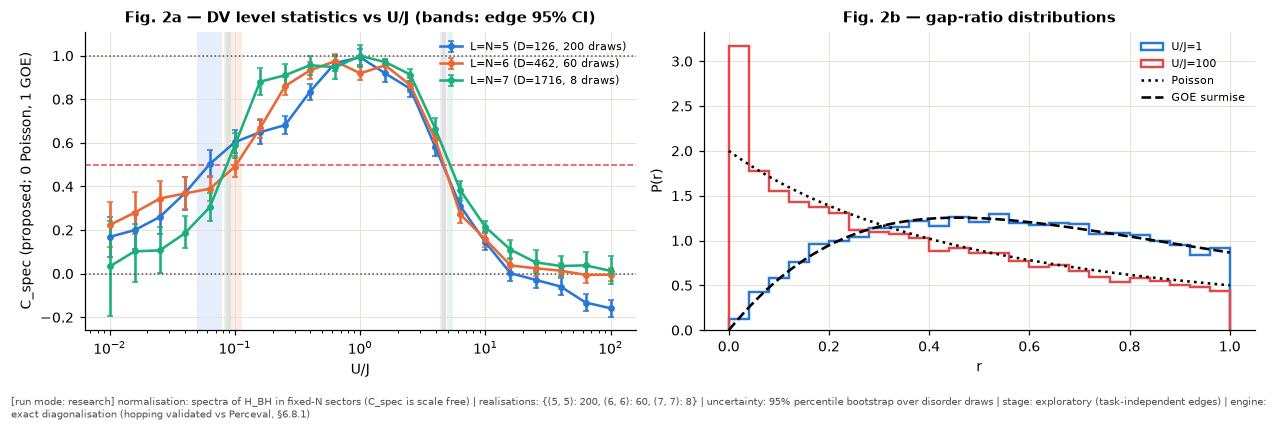

In [36]:
with section("7.1 DV spectral edges"):
    LDV, NDV = CFG["L"], CFG["N"]; SPEC = {}; spec_rows = []
    for (L, N) in CFG["stat_sizes"]:
        R = CFG["stat_real"][(L, N)]
        for g in CFG["g_spec"]:
            Es = STORE.cached("dv-spectrum", dict(L=L, N=N, g=g, R=R, W=W_BH, v=ENGINE_VERSIONS["dv"]),
                              lambda L=L, N=N, g=g, R=R: [np.linalg.eigvalsh(bh_hamiltonian(L, N, g, real=s)) for s in range(R)])
            ls = level_stats(Es, "GOE"); SPEC[(L, N, g)] = dict(ls, spectra=Es)
            spec_rows.append(dict(L=L, N=N, D=math.comb(N + L - 1, N), g=g, r=ls["r"], C=ls["C"], C_lo=ls["C_lo"], C_hi=ls["C_hi"],
                                  KS_Poisson=ls["ks_poisson"], KS_GOE=ls["ks_rmt"], realisations=R))
    SPEC_DF = pd.DataFrame(spec_rows); EDGES = {}
    for (L, N) in CFG["stat_sizes"]:
        d = SPEC_DF[(SPEC_DF.L == L) & (SPEC_DF.N == N)]; gs = d.g.values; boots = np.array([c_spec(SPEC[(L, N, g)]["boots"]) for g in gs]); e = {}
        for side in ("low", "high"):
            val = crossing(gs, d.C.values, 0.5, side); bs = np.array([crossing(gs, boots[:, b], 0.5, side) for b in range(boots.shape[1])]); fin = bs[np.isfinite(bs)]
            e[side] = dict(value=val, lo=float(np.quantile(fin, 0.025)) if len(fin) > 20 else np.nan, hi=float(np.quantile(fin, 0.975)) if len(fin) > 20 else np.nan,
                           found=bool(np.isfinite(val) and np.isfinite(bs).mean() >= 0.9), task_independent=True)
        e["g_chaos"] = float(gs[np.argmax(d.C.values)]); e["C_max"] = float(d.C.max()); EDGES[(L, N)] = e
    E_DV = EDGES[(LDV, NDV)]; G_CHAOS = E_DV["g_chaos"]
    lc, lr = SPEC[(LDV, NDV, G_CHAOS)], SPEC[(LDV, NDV, CFG["g_spec"][-1])]
    record_test("P7.dist", "regular and chaotic points statistically distinguishable (disjoint <r> CIs; KS prefers the right law)",
                f"<r> chaos {lc['r']:.3f} [{lc['r_lo']:.3f},{lc['r_hi']:.3f}] vs regular {lr['r']:.3f} [{lr['r_lo']:.3f},{lr['r_hi']:.3f}]",
                "lo_chaos > hi_regular; KS ordering", lc["r_lo"] > lr["r_hi"] and lc["ks_rmt"] < lc["ks_poisson"] and lr["ks_poisson"] < lr["ks_rmt"],
                section_ref="7.1", category="physics")
display(pd.DataFrame({f"L={L},N={N} (D={math.comb(N + L - 1, N)})": {"g_chaos": e["g_chaos"], "C_max": round(e["C_max"], 3),
                      "low edge [95% CI]": f"{e['low']['value']:.3g} [{e['low']['lo']:.3g}, {e['low']['hi']:.3g}]",
                      "high edge [95% CI]": f"{e['high']['value']:.3g} [{e['high']['lo']:.3g}, {e['high']['hi']:.3g}]"} for (L, N), e in EDGES.items()}))

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6))
for j, (L, N) in enumerate(CFG["stat_sizes"]):
    d = SPEC_DF[(SPEC_DF.L == L) & (SPEC_DF.N == N)]
    axs[0].errorbar(d.g, d.C, yerr=[d.C - d.C_lo, d.C_hi - d.C], fmt="o-", ms=3.5, capsize=2, color=PAL[j], label=f"L=N={L} (D={d.D.iloc[0]}, {d.realisations.iloc[0]} draws)")
    for side in ("low", "high"):
        ee = EDGES[(L, N)][side]
        if np.isfinite(ee["lo"]):
            axs[0].axvspan(ee["lo"], ee["hi"], color=PAL[j], alpha=0.12, lw=0)
axs[0].axhline(0.5, color=COL["red"], ls="--", lw=1); axs[0].axhline(0, color=COL["ink2"], ls=":", lw=1); axs[0].axhline(1, color=COL["ink2"], ls=":", lw=1)
axs[0].set(xscale="log", xlabel="U/J", ylabel="C_spec (proposed; 0 Poisson, 1 GOE)", title="Fig. 2a — DV level statistics vs U/J (bands: edge 95% CI)"); axs[0].legend(fontsize=7)
rr = np.linspace(0, 1, 200)
for g, c in ((G_CHAOS, COL["dv"]), (CFG["g_spec"][-1], COL["red"])):
    axs[1].hist(SPEC[(LDV, NDV, g)]["ratios"], bins=25, range=(0, 1), density=True, histtype="step", color=c, lw=1.6, label=f"U/J={g:.3g}")
axs[1].plot(rr, p_r(rr, "Poisson"), "k:", label="Poisson"); axs[1].plot(rr, p_r(rr, "GOE"), "k--", label="GOE surmise")
axs[1].set(xlabel="r", ylabel="P(r)", title="Fig. 2b — gap-ratio distributions"); axs[1].legend(fontsize=7)
figmeta(fig, normalisation="spectra of H_BH in fixed-N sectors (C_spec is scale free)", realisations=str(CFG["stat_real"]),
        uncertainty="95% percentile bootstrap over disorder draws", stage="exploratory (task-independent edges)", engine="exact diagonalisation (hopping validated vs Perceval, §6.8.1)")
plt.tight_layout(); plt.show()

[7.2 DV SFF and Thouless time] 1.4 s | peak host memory 1128 MB | GPU pool 24 MB | reused checkpointed units: 0 s of earlier compute + 4 untimed units


,g,realisations,tau_Th,CI,ramp_found,t_Th_normalised,established
chaotic,1.0,400,0.07225,"[0.0687, 0.0723]",1.0,64.392723,True
edge-high,4.564971,400,NaN,"[nan, nan]",0.0,NaN,False
regular,100.0,400,NaN,"[nan, nan]",0.0,NaN,False
"chaotic, larger size",0.630957,100,0.027754,"[0.0264, 0.0395]",1.0,92.612809,True


tau~_long = 64.4 (= t~_Th at g_chaos); temporal edge interval (pre-ramp window, proposed) = [6.12, 64.4]


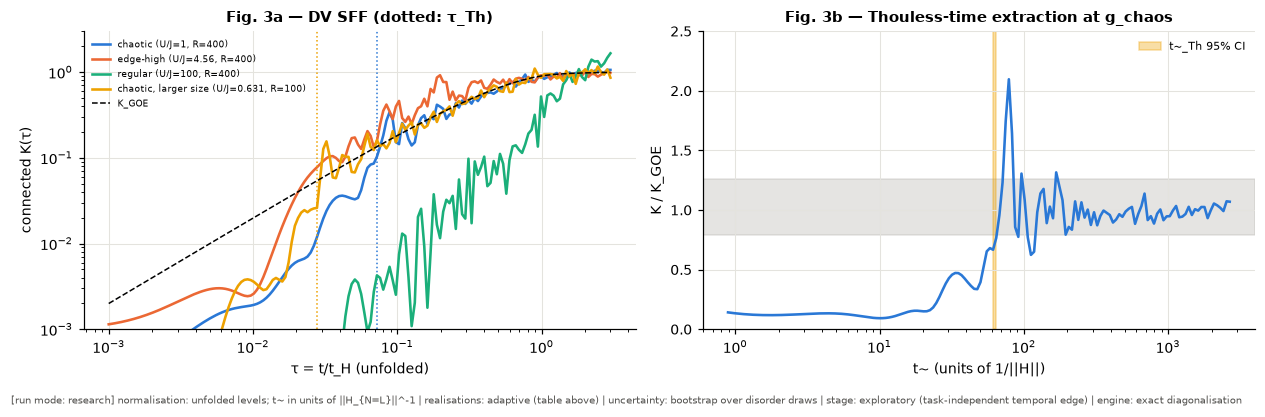

In [37]:
def sff_study(L, N, g, r_start, r_max, tag, rmt="GOE"):
    R = r_start
    while True:
        spectra = STORE.cached("dv-sff-spectra", dict(L=L, N=N, g=g, R=R, W=W_BH, v=ENGINE_VERSIONS["dv"]),
                               lambda R=R: [(lambda H: np.linalg.eigvalsh(H) / spectral_norm(H))(bh_hamiltonian(L, N, g, real=s, bank="sff")) for s in range(R)])
        Z, W2, rho = sff_moments(spectra, TAUS); th = thouless_estimate(Z, W2, TAUS, rmt, rng=rng_for("sff", tag, R))
        width = (th["hi"] - th["lo"]) / th["tau_th"] if np.isfinite(th["tau_th"]) else np.inf
        if (width < 0.6 and th["found_frac"] >= 0.9) or R >= r_max or tag != "chaotic":
            break
        R = min(2 * R, r_max)
    tH = 2 * np.pi * float(np.mean(rho))
    return dict(th, R=R, g=g, t_H=tH, t_th=th["tau_th"] * tH, t_th_lo=th["lo"] * tH, t_th_hi=th["hi"] * tH,
                established=bool(np.isfinite(th["tau_th"]) and th["found_frac"] >= 0.9 and width < 0.6))

with section("7.2 DV SFF and Thouless time"):
    SFF = {}
    for name, g in (("chaotic", G_CHAOS), ("edge-high", E_DV["high"]["value"]), ("regular", CFG["g_spec"][-1])):
        if np.isfinite(g):
            SFF[name] = sff_study(LDV, NDV, g, *CFG["sff_real"], name)
    Lb, Nb = CFG["stat_sizes"][1]; SFF["chaotic, larger size"] = sff_study(Lb, Nb, EDGES[(Lb, Nb)]["g_chaos"], CFG["sff_real_big"], CFG["sff_real_big"], "big")
    sc = SFF["chaotic"]; T_TH = sc["t_th"] if sc["established"] else np.nan
    TAU_LONG = float(np.round(T_TH, 1)) if np.isfinite(T_TH) else 30.0
    EDGE_TEMPORAL = dict(value=T_TH, lo=sc["t_th_lo"] / 10 if sc["established"] else np.nan, hi=sc["t_th_hi"] if sc["established"] else np.nan,
                         found=bool(sc["established"]), task_independent=True)
display(pd.DataFrame({k: dict(g=v["g"], realisations=v["R"], tau_Th=v["tau_th"], CI=f"[{v['lo']:.3g}, {v['hi']:.3g}]", ramp_found=v["found_frac"],
                              t_Th_normalised=v["t_th"], established=v["established"]) for k, v in SFF.items()}).T)
print(f"tau~_long = {TAU_LONG} ({'= t~_Th at g_chaos' if np.isfinite(T_TH) else 'fallback: Thouless time NOT established'}); "
      f"temporal edge interval (pre-ramp window, proposed) = [{EDGE_TEMPORAL['lo']:.3g}, {EDGE_TEMPORAL['hi']:.3g}]")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6))
for (k, v), c in zip(SFF.items(), PAL):
    axs[0].loglog(TAUS, v["K"], color=c, label=f"{k} (U/J={v['g']:.3g}, R={v['R']})")
    if np.isfinite(v["tau_th"]):
        axs[0].axvline(v["tau_th"], color=c, ls=":", lw=1)
axs[0].loglog(TAUS, k_rmt(TAUS, "GOE"), "k--", lw=1, label="K_GOE"); axs[0].set(xlabel="τ = t/t_H (unfolded)", ylabel="connected K(τ)", ylim=(1e-3, 3), title="Fig. 3a — DV SFF (dotted: τ_Th)")
axs[0].legend(fontsize=6)
axs[1].semilogx(TAUS * sc["t_H"], sc["K"] / k_rmt(TAUS, "GOE"), color=COL["dv"]); axs[1].axhspan(10 ** -0.1, 10 ** 0.1, color=COL["grey"], alpha=0.3)
if sc["established"]:
    axs[1].axvspan(sc["t_th_lo"], sc["t_th_hi"], color=COL["yel"], alpha=0.35, label="t~_Th 95% CI")
axs[1].set(xlabel="t~ (units of 1/||H||)", ylabel="K / K_GOE", ylim=(0, 2.5), title="Fig. 3b — Thouless-time extraction at g_chaos"); axs[1].legend(fontsize=7)
figmeta(fig, normalisation="unfolded levels; t~ in units of ||H_{N=L}||^-1", realisations="adaptive (table above)", uncertainty="bootstrap over disorder draws",
        stage="exploratory (task-independent temporal edge)", engine="exact diagonalisation")
plt.tight_layout(); plt.show()

In [38]:
DV_BANKS = {"explore": Bank("dv", "explore", phase_cfg("phase1", "n_explore")), "confirm": Bank("dv", "confirm", phase_cfg("phase1", "n_confirm"))}

def dv_unit(x, param, bank, fixed):
    """One checkpointed unit: all bundles of `bank` at parameter value x (param 'g' or 'tau'), batched on the device."""
    key = dict(engine="dv", param=param, x=float(x), bank=bank.name, stage=bank.stage, n=bank.n, fixed=fixed, seq=CFG["seq"],
               lyap=(CFG["lyap_steps"], ENGINE_VERSIONS["lyap"]), ipc=(CFG["ipc_deg"], CFG["ipc_delay"], CFG["n_null"], CFG["refits"]), v=ENGINE_VERSIONS["dv"])
    def compute():
        bundles = [dv_bundle(LDV, NDV, bank.name, bank.stage, r) for r in bank.ids()]
        g = float(x) if param == "g" else fixed["g"]; tau = float(x) if param == "tau" else fixed["tau"]
        eng = FockReservoirBatch(LDV, NDV, [b["hop"] for b in bundles], g); ports = stack_ports(bundles)
        X = eng.run(ports, tau); lam = eng.lyapunov(ports, tau); rows = []
        for j, b in enumerate(bundles):
            ev = evaluate_features(X[j], task_design(b["u"], (bank.name, bank.stage, j)))
            rows.append(dict(x=float(x), param=param, r=j, bank=bank.name, stage=bank.stage, g=g, tau=tau, Lambda=float(lam[j]), **summarize(ev)))
        return rows
    return STORE.cached("dv-unit", key, compute)

def run_scan(unit_fn, xs, *args):
    rows = []
    for x in xs:
        rows += unit_fn(x, *args)
    return pd.DataFrame(rows)

def channel_edge(df, xs, level=None, n_boot=None, direction="up"):
    """lambda_c-crossing of the bundle-mean driven exponent along x, with a bootstrap CI over bundles (task independent)."""
    level = PREREG["lambda_c"] if level is None else level; n_boot = n_boot or CFG["boot"]
    M = np.array([[df[(np.isclose(df.x, x)) & (df.r == r)].Lambda.iloc[0] for r in sorted(df.r.unique())] for x in xs])
    val = level_crossing(xs, np.nanmean(M, 1), level, direction); rng = rng_for("channel-edge", tuple(np.round(xs, 6)))
    bs = np.array([level_crossing(xs, np.nanmean(M[:, rng.integers(0, M.shape[1], M.shape[1])], 1), level, direction) for _ in range(n_boot)]); fin = bs[np.isfinite(bs)]
    return dict(value=val, lo=float(np.quantile(fin, 0.025)) if len(fin) > 20 else np.nan, hi=float(np.quantile(fin, 0.975)) if len(fin) > 20 else np.nan,
                found=bool(np.isfinite(val) and np.isfinite(bs).mean() >= 0.9), task_independent=True, lambda_mean=np.nanmean(M, 1))

with section("7.3 DV exploratory scans"):
    g_ex = [float(g) for g in CFG["dv_g_explore"]]; tau_ex = [float(t) for t in CFG["dv_tau_explore"]]
    DV_EX_G = run_scan(dv_unit, g_ex, "g", DV_BANKS["explore"], dict(tau=TAU_LONG))
    DV_EX_T = run_scan(dv_unit, tau_ex, "tau", DV_BANKS["explore"], dict(g=G_CHAOS))
    EDGE_CH_DV = channel_edge(DV_EX_G, g_ex)
    means_g = DV_EX_G.groupby("x")["NARMA5 NMSE"].mean(); means_t = DV_EX_T.groupby("x")["NARMA5 NMSE"].mean()
    cand_g, cand_t = float(means_g.idxmin()), float(means_t.idxmin())
    EDGES_DV = {"H1a-DV": E_DV["low"], "H1b-DV": E_DV["high"], "H2-DV": EDGE_CH_DV, "H1t-DV": EDGE_TEMPORAL}
    for hid in ("H1a-DV", "H1b-DV", "H2-DV"):
        lock_candidate(hid, candidate=cand_g, edge=[EDGES_DV[hid]["value"], EDGES_DV[hid]["lo"], EDGES_DV[hid]["hi"]], explore_n=DV_BANKS["explore"].n)
    lock_candidate("H1t-DV", candidate=cand_t, edge=[EDGE_TEMPORAL["value"], EDGE_TEMPORAL["lo"], EDGE_TEMPORAL["hi"]], explore_n=DV_BANKS["explore"].n)
print(f"channel edge (Lambda = {PREREG['lambda_c']}): U/J = {EDGE_CH_DV['value']:.3g} [{EDGE_CH_DV['lo']:.3g}, {EDGE_CH_DV['hi']:.3g}]; "
      f"exploratory candidates: g* = {cand_g:.3g}, tau* = {cand_t:.3g}")

LOCKED H1a-DV: {"candidate": 0.06415407599947126, "edge": [0.06228271715592643, 0.04973524644701503, 0.07921848315989329], "explore_n": 30}  sha256[:16]=a9a1785e7cfddd57
LOCKED H1b-DV: {"candidate": 0.06415407599947126, "edge": [4.564970889796902, 4.3039736626544745, 4.80084703383626], "explore_n": 30}  sha256[:16]=3b668049b3f944bf
LOCKED H2-DV: {"candidate": 0.06415407599947126, "edge": [1.3186691967960114, 1.3137385516580447, 1.322731899420205], "explore_n": 30}  sha256[:16]=71b0a57fc344537b
LOCKED H1t-DV: {"candidate": 5.623413251903491, "edge": [64.39272299208278, 6.123054196225398, 64.39272299208278], "explore_n": 30}  sha256[:16]=99a3a2598f99b250
[7.3 DV exploratory scans] 0.4 s | peak host memory 1128 MB | GPU pool 24 MB | reused checkpointed units: 0 s of earlier compute + 20 untimed units
channel edge (Lambda = -0.01): U/J = 1.32 [1.31, 1.32]; exploratory candidates: g* = 0.0642, tau* = 5.62


In [39]:
def confirm_grid(xs_explore, cand, edge_values, endpoints=None):
    xs = sorted(xs_explore); i = int(np.argmin(np.abs(np.array(xs) - cand))); nbrs = [xs[j] for j in (i - 1, i + 1) if 0 <= j < len(xs)]
    ends = endpoints or (xs[0], xs[-1]); pts = {float(cand), *map(float, nbrs), *map(float, ends)}
    pts |= {float(v) for v in edge_values if np.isfinite(v) and ends[0] <= v <= ends[1]}
    return sorted(pts), [float(n) for n in nbrs]

with section("7.4 DV confirmatory scans"):
    gc, nb_g = confirm_grid(g_ex, cand_g, [E_DV["low"]["value"], E_DV["high"]["value"], EDGE_CH_DV["value"]])
    tc, nb_t = confirm_grid(tau_ex, cand_t, [EDGE_TEMPORAL["value"], EDGE_TEMPORAL["value"] / 10 if np.isfinite(EDGE_TEMPORAL["value"]) else np.nan])
    DV_CF_G = run_scan(dv_unit, gc, "g", DV_BANKS["confirm"], dict(tau=TAU_LONG))
    DV_CF_T = run_scan(dv_unit, tc, "tau", DV_BANKS["confirm"], dict(g=G_CHAOS))
    lvl = PHASE_LEVEL["phase1"]
    for hid, edge in (("H1a-DV", E_DV["low"]), ("H1b-DV", E_DV["high"]), ("H2-DV", EDGE_CH_DV)):
        evaluate_hypothesis(hid, DV_CF_G, gc, LOCKS[hid]["candidate"], edge, level=lvl, neighbours=nb_g, edge_points=[edge["value"]] if np.isfinite(edge["value"]) else [])
    evaluate_hypothesis("H1t-DV", DV_CF_T, tc, LOCKS["H1t-DV"]["candidate"], EDGE_TEMPORAL, level=lvl, neighbours=nb_t,
                        edge_points=[v for v in (EDGE_TEMPORAL["value"], EDGE_TEMPORAL["value"] / 10) if np.isfinite(v)])
    for df_ in (DV_EX_G, DV_EX_T, DV_CF_G, DV_CF_T):
        df_["C_spec"] = [float(np.interp(np.log(g), np.log(SPEC_DF[(SPEC_DF.L == LDV) & (SPEC_DF.N == NDV)].g), SPEC_DF[(SPEC_DF.L == LDV) & (SPEC_DF.N == NDV)].C)) for g in df_.g]
        df_["t_over_tTh"] = df_.tau / T_TH if np.isfinite(T_TH) else np.nan
    record_test("S7.nodrop", "no confirmatory row removed: divergent points retained and classified", f"{len(DV_CF_G) + len(DV_CF_T)} rows, {int(DV_CF_G.diverged.sum() + DV_CF_T.diverged.sum())} divergent",
                f"= {len(gc) * DV_BANKS['confirm'].n + len(tc) * DV_BANKS['confirm'].n} rows", len(DV_CF_G) + len(DV_CF_T) == (len(gc) + len(tc)) * DV_BANKS["confirm"].n,
                section_ref="7.4", category="statistics")

def hyp_table(hids):
    rows = []
    for h in hids:
        r = HYP_RESULTS[h]; t = r["tests"]
        rows.append(dict(hypothesis=h, level=r["level"], n_confirm=r["n_confirm"], candidate=r["x_cand"], conf_opt=r["x_conf_opt"],
                         opt_interval=f"[{r['opt_interval'][0]:.3g}, {r['opt_interval'][1]:.3g}]", edge=f"{r['edge']['value']:.3g} [{r['edge']['lo']:.3g}, {r['edge']['hi']:.3g}]",
                         **{f"Δ vs end{j} (mean; raw p; d_z)": f"{t[k]['mean']:.4f}; {t[k]['p']:.2g}; {t[k]['dz']:.2f}" for j, k in enumerate(t)},
                         P_beats_both=r["p_beats_both"], diverged=len(r["diverged_points"])))
    return pd.DataFrame(rows).set_index("hypothesis")
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(hyp_table(["H1a-DV", "H1b-DV", "H2-DV", "H1t-DV"]))
print("raw p-values shown; Holm correction across the primary family and the verdicts are applied in §16.")

PASS [S7.nodrop] no confirmatory row removed: divergent points retained and classified: 700 rows, 0 divergent (criterion = 700 rows)
[7.4 DV confirmatory scans] 1.4 s | peak host memory 1128 MB | GPU pool 24 MB | reused checkpointed units: 0 s of earlier compute + 14 untimed units


,level,n_confirm,candidate,conf_opt,opt_interval,edge,Δ vs end0 (mean; raw p; d_z),Δ vs end1 (mean; raw p; d_z),P_beats_both,diverged
hypothesis,,,,,,,,,,
H1a-DV,research,50,0.064154,0.064154,"[0.0623, 0.137]","0.0623 [0.0497, 0.0792]",0.0168; 0.019; 0.35,0.8577; 8.9e-16; 2.20,0.993,0
H1b-DV,research,50,0.064154,0.064154,"[0.0623, 0.137]","4.56 [4.3, 4.8]",0.0168; 0.019; 0.35,0.8577; 8.9e-16; 2.20,0.993,0
H2-DV,research,50,0.064154,0.064154,"[0.0623, 0.137]","1.32 [1.31, 1.32]",0.0168; 0.019; 0.35,0.8577; 8.9e-16; 2.20,0.993,0
H1t-DV,research,50,5.623413,6.439272,"[6.44, 6.44]","64.4 [6.12, 64.4]",0.3335; 8.9e-16; 4.82,0.2863; 8.9e-16; 5.55,1.000,0


raw p-values shown; Holm correction across the primary family and the verdicts are applied in §16.


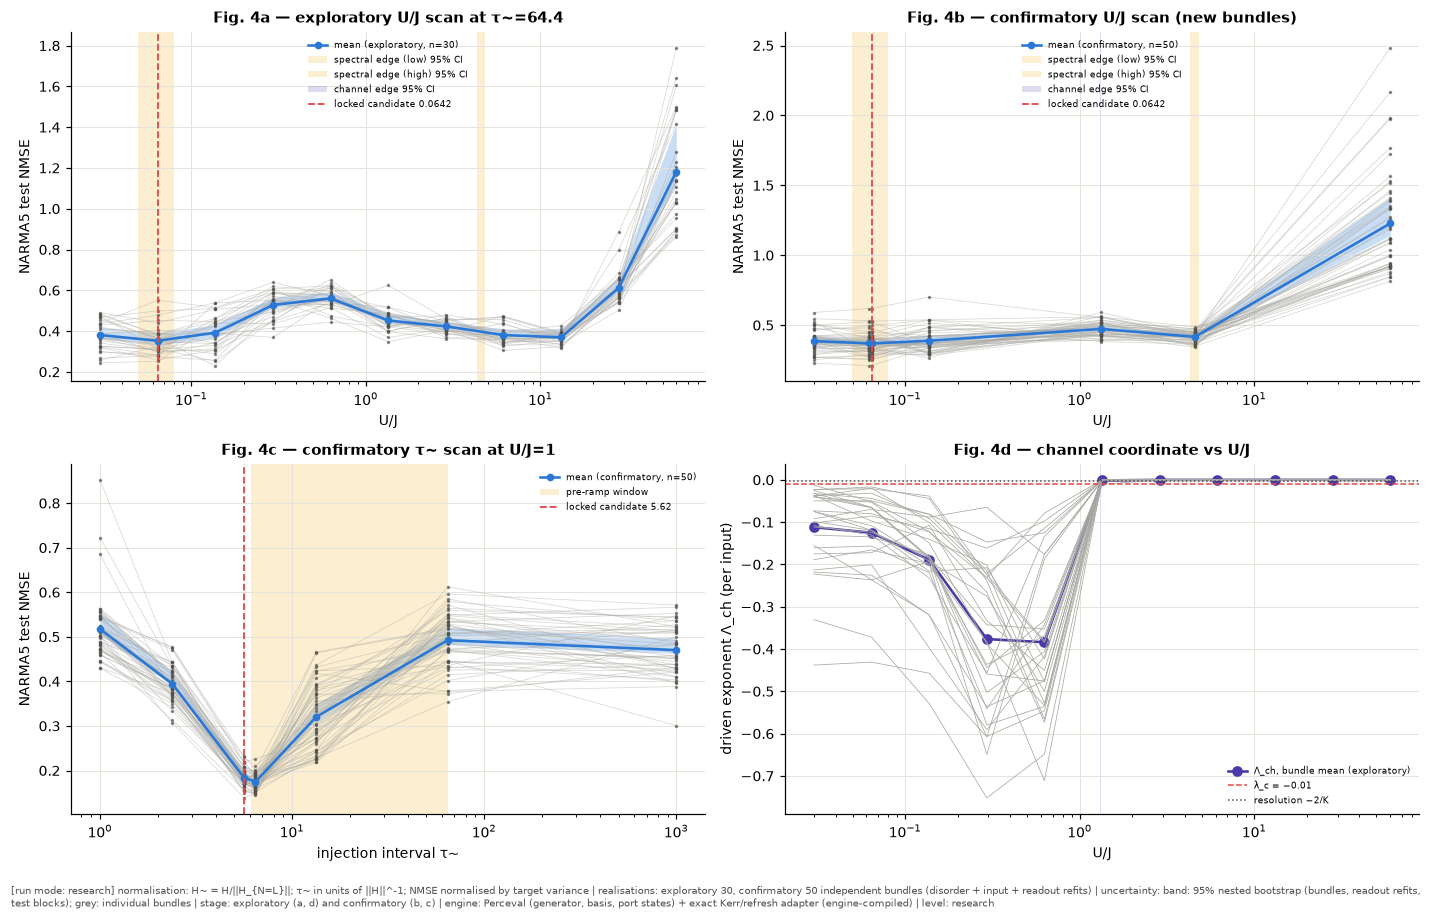

In [40]:
def perf_plot(ax, df, xs, title, xlabel, bands=(), cand=None, stage="", log=True):
    """Individual bundle points, paired lines, mean and nested-bootstrap 95% CI of the primary endpoint."""
    M, rs = per_bundle_nmse(df, xs); boot = nested_bootstrap(df, xs)
    for j in range(M.shape[1]):
        ax.plot(xs, M[:, j], "-", color=COL["grey"], lw=0.5, alpha=0.45)
    ax.plot(np.repeat(xs, M.shape[1]).reshape(len(xs), -1).ravel(), M.ravel(), ".", color=COL["ink2"], ms=2.5, alpha=0.6)
    lo, hi = np.nanquantile(boot, 0.025, axis=0), np.nanquantile(boot, 0.975, axis=0)
    ax.fill_between(xs, lo, hi, color=COL["dv"], alpha=0.25, lw=0); ax.plot(xs, np.nanmean(M, 1), "o-", color=COL["dv"], ms=4, label=f"mean ({stage}, n={M.shape[1]})")
    for (a, b, lab, c) in bands:
        if np.isfinite(a) and np.isfinite(b):
            ax.axvspan(a, b, color=c, alpha=0.18, lw=0, label=lab)
    if cand is not None:
        ax.axvline(cand, color=COL["red"], ls="--", lw=1.2, label=f"locked candidate {cand:.3g}")
    ax.set(xscale="log" if log else "linear", xlabel=xlabel, ylabel="NARMA5 test NMSE", title=title); ax.legend(fontsize=6)

fig, axs = plt.subplots(2, 2, figsize=(13, 8))
bands_g = [(E_DV["low"]["lo"], E_DV["low"]["hi"], "spectral edge (low) 95% CI", COL["yel"]), (E_DV["high"]["lo"], E_DV["high"]["hi"], "spectral edge (high) 95% CI", COL["yel"]),
           (EDGE_CH_DV["lo"], EDGE_CH_DV["hi"], "channel edge 95% CI", COL["vio"])]
perf_plot(axs[0, 0], DV_EX_G, g_ex, f"Fig. 4a — exploratory U/J scan at τ~={TAU_LONG:g}", "U/J", bands_g, cand_g, "exploratory")
perf_plot(axs[0, 1], DV_CF_G, gc, "Fig. 4b — confirmatory U/J scan (new bundles)", "U/J", bands_g, cand_g, "confirmatory")
perf_plot(axs[1, 0], DV_CF_T, tc, f"Fig. 4c — confirmatory τ~ scan at U/J={G_CHAOS:.3g}", "injection interval τ~", [(EDGE_TEMPORAL["lo"], EDGE_TEMPORAL["hi"], "pre-ramp window", COL["yel"])],
          LOCKS["H1t-DV"]["candidate"], "confirmatory")
lam_m = DV_EX_G.groupby("x").Lambda.mean(); axs[1, 1].plot(lam_m.index, lam_m.values, "o-", color=COL["vio"], label="Λ_ch, bundle mean (exploratory)")
for r_ in sorted(DV_EX_G.r.unique()):
    d_ = DV_EX_G[DV_EX_G.r == r_]; axs[1, 1].plot(d_.x, d_.Lambda, "-", color=COL["grey"], lw=0.5)
axs[1, 1].axhline(PREREG["lambda_c"], color=COL["red"], ls="--", lw=1, label="λ_c = −0.01"); axs[1, 1].axhline(-2 / CFG["lyap_steps"], color=COL["ink2"], ls=":", lw=1, label="resolution −2/K")
if np.isfinite(EDGE_CH_DV["lo"]):
    axs[1, 1].axvspan(EDGE_CH_DV["lo"], EDGE_CH_DV["hi"], color=COL["vio"], alpha=0.18, lw=0)
axs[1, 1].set(xscale="log", xlabel="U/J", ylabel="driven exponent Λ_ch (per input)", title="Fig. 4d — channel coordinate vs U/J"); axs[1, 1].legend(fontsize=6)
figmeta(fig, normalisation="H~ = H/||H_{N=L}||; τ~ in units of ||H||^-1; NMSE normalised by target variance",
        realisations=f"exploratory {DV_BANKS['explore'].n}, confirmatory {DV_BANKS['confirm'].n} independent bundles (disorder + input + readout refits)",
        uncertainty="band: 95% nested bootstrap (bundles, readout refits, test blocks); grey: individual bundles", stage="exploratory (a, d) and confirmatory (b, c)",
        engine="Perceval (generator, basis, port states) + exact Kerr/refresh adapter (engine-compiled)", level=PHASE_LEVEL["phase1"])
plt.tight_layout(); plt.show()
RESULTS["dv"] = dict(spec=SPEC_DF, edges=EDGES, sff={k: {kk: vv for kk, vv in v.items() if kk != "K"} for k, v in SFF.items()}, channel_edge=EDGE_CH_DV,
                     explore_g=DV_EX_G, explore_t=DV_EX_T, confirm_g=DV_CF_G, confirm_t=DV_CF_T)

# 8. Interacting-CV repair (Phase 2)
> **Established in literature.** Level statistics are defined per symmetry sector. A coherent state is a superposition over number sectors, whereas a phase-averaged coherent state is a Poisson mixture of Fock states.
> **Adapted here.**
> * The interacting-CV reservoir of the previous version used $L=4$ modes, and its $C_w$ was computed from sectors that held $\le7\%$ of the state (finding 4, §6.9). It is rebuilt on the **same graph as the DV reservoir** ($L=5$ open chain, same disorder law, same normalisation $\lVert H_{N=L}\rVert$, same injection interval $\tilde\tau_{\rm long}$).
> * **Route A + B.** All sectors $N=0\dots c-1$ are kept explicitly in the simulation and in the spectral analysis. The coherent amplitude $\alpha_{\max}$ is chosen as the largest grid value for which these sectors hold $\ge99\%$ of the population at every scanned $U/J$, while the Kerr term still changes the features measurably.
> **Proposed novel element.** The sector-weighted coordinate $C_w=\sum_Np_NC_N$ is used **only** under the assumption it needs, and that assumption is tested numerically: a state block-diagonal in $N$, i.e. the phase-randomised preparation. For $N\le1$ the Hamiltonian is quadratic, so these sectors are integrable (§6.9, finding 3) and $C_N\equiv0$ by construction. For $N\ge2$, $C_N$ is measured.

## 8.1 Total-number distribution and resolved weight
For every configuration: $p_N=\mathrm{Tr}(\Pi_N\rho)$, time-averaged after the washout, and $W_{\rm resolved}(N_{\max})=\sum_{N\le N_{\max}}p_N$. Inside a simulation truncated at $N\le c-1$, this sum is 1 by construction, so it says nothing. $W_{\rm resolved}(c-1)$ is therefore always measured in a **larger-cutoff simulation** ($N\le c$): it is the population that the production simulation actually represents. The truncation loss per step is also recorded (weight pushed beyond the cutoff by the injection, then renormalised).

In [41]:
CVK_L, CVK_C = CFG["cvk_L"], CFG["cvk_cut"][0]; CVK_BANKS = {"explore": Bank("cvk", "explore", phase_cfg("phase2", "n_explore")), "confirm": Bank("cvk", "confirm", phase_cfg("phase2", "n_confirm"))}

def cvk_bundle(bank, stage, r):
    return dict(eps=disorder(CVK_L, W_BH, r, bank, stage), u=input_sequence(bank, stage, r))

def cvk_unit(x, bank, fixed, sector_features=False, n=None, lyap=True):
    """All bundles of `bank` at U/J = x; fixed: alpha, tau, prep, c, feats ('number' or 'quad20')."""
    n = n or bank.n
    key = dict(engine="cvk", x=float(x), bank=bank.name, stage=bank.stage, n=n, fixed=fixed, sec=sector_features, seq=CFG["seq"], lyap=(CFG["lyap_steps"], ENGINE_VERSIONS["lyap"]) if lyap else 0,
               ipc=(CFG["ipc_deg"], CFG["ipc_delay"], CFG["n_null"], CFG["refits"]), v=ENGINE_VERSIONS["cvk"])
    def compute():
        bs = [cvk_bundle(bank.name, bank.stage, r) for r in range(n)]; c = fixed["c"]
        eng = KerrCVBatch(CVK_L, c, [hopping_matrix(CVK_L, 1.0, b["eps"]) for b in bs], float(x))
        amps = np.stack([coherent_amplitudes(b["u"], fixed["alpha"], c) for b in bs])
        out = eng.run(amps, fixed["tau"], prep=fixed["prep"], sector_features=sector_features)
        lam = eng.lyapunov(amps, fixed["tau"], prep=fixed["prep"]) if lyap else np.full(len(bs), np.nan); rows = []; tr0 = SPLITS["tr"].start
        for j, b in enumerate(bs):
            X = out["Xn"][j] if fixed.get("feats", "number") == "number" else quad20_features(out, j, CVK_L)
            ev = evaluate_features(X, task_design(b["u"], (bank.name, bank.stage, j)))
            row = dict(x=float(x), r=j, bank=bank.name, stage=bank.stage, g=float(x), Lambda=float(lam[j]), p_N=out["pops"][j, tr0:].mean(0),
                       coh=float(out["coh"][j, tr0:].mean()), trunc=float(out["trunc"][j, tr0:].max()), Xn=out["Xn"][j] if sector_features else None, **summarize(ev))
            if sector_features:
                row["Xsec"] = out["Xsec"][j]; row["pops_t"] = out["pops"][j]; row["Xq"] = out["Xq"][j]
            rows.append(row)
        return rows
    return STORE.cached("cvk-unit", key, compute)

def quad20_features(out, j, L):
    """Matched 20-per-sub-step feature set with quadratures: n_i (L), Re/Im <a_i> (2L), n_i n_{i+1} (L-1), n_0^2 (1)."""
    iu = np.triu_indices(L); nn_idx = [np.flatnonzero((iu[0] == i) & (iu[1] == i + 1))[0] for i in range(L - 1)]; n00 = np.flatnonzero((iu[0] == 0) & (iu[1] == 0))[0]
    F = L + len(iu[0]); blocks = []
    for s in range(2):
        xn = out["Xn"][j][:, s * F:(s + 1) * F]; xq = out["Xq"][j][:, s * 2 * L:(s + 1) * 2 * L]
        blocks.append(np.hstack([xn[:, :L], xq, xn[:, L + np.array(nn_idx)], xn[:, L + n00][:, None]]))
    return np.hstack(blocks)

with section("8.1 CV sector weights and Route A amplitude selection"):
    g_probe = [float(g) for g in CFG["cvk_probe_g"]]; rowsA = []
    probe_bank = Bank("cvk", "probe", CFG["cvk_probe_n"])
    for a in CFG["cvk_alpha_grid"]:
        for g in g_probe:
            for prep in ("dephased",):
                rr = cvk_unit(g, probe_bank, dict(alpha=a, tau=TAU_LONG, prep=prep, c=CFG["cvk_cut"][1], feats="number"), lyap=False)     # one sector beyond production
                for r_ in rr:
                    rowsA.append(dict(alpha=a, g=g, r=r_["r"], W_res=float(r_["p_N"][:CVK_C].sum()), trunc=r_["trunc"], mean_N=float(np.dot(np.arange(len(r_["p_N"])), r_["p_N"])),
                                      NARMA5=r_["NARMA5 NMSE"]))
    RA = pd.DataFrame(rowsA)
    ok_alpha = [a for a in CFG["cvk_alpha_grid"] if RA[RA.alpha == a].W_res.min() >= 0.99 and RA[RA.alpha == a].trunc.max() < 1e-2]
    ALPHA_CV = max(ok_alpha) if ok_alpha else min(CFG["cvk_alpha_grid"])
    kerr_rows = cvk_unit(float(np.median(CFG["cvk_g"])), probe_bank, dict(alpha=ALPHA_CV, tau=TAU_LONG, prep="dephased", c=CVK_C, feats="number"), sector_features=True, lyap=False)
    lin_rows_a = cvk_unit(0.0, probe_bank, dict(alpha=ALPHA_CV, tau=TAU_LONG, prep="dephased", c=CVK_C, feats="number"), sector_features=True, lyap=False)
    kerr_effect = float(np.mean([np.linalg.norm(k["Xn"] - l["Xn"]) / np.linalg.norm(l["Xn"] - l["Xn"].mean(0)) for k, l in zip(kerr_rows, lin_rows_a)]))
display(RA.groupby(["alpha", "g"]).agg(W_res_min=("W_res", "min"), mean_N=("mean_N", "mean"), trunc_max=("trunc", "max"), NARMA5=("NARMA5", "mean")).round(4))
record_test("P8.route", "Route A: resolved sectors (N <= c-1) hold >= 99% of the population at every probed U/J, with a measurable Kerr effect",
            f"alpha_max = {ALPHA_CV}; min W_res {RA[RA.alpha == ALPHA_CV].W_res.min():.4f}; Kerr-induced feature change {kerr_effect:.3f} (relative)",
            "W_res >= 0.99 and feature change > 0.01", RA[RA.alpha == ALPHA_CV].W_res.min() >= 0.99 and kerr_effect > 0.01, section_ref="8.1", category="physics")

[8.1 CV sector weights and Route A amplitude selection] 0.1 s | peak host memory 1128 MB | GPU pool 24 MB | reused checkpointed units: 0 s of earlier compute + 11 untimed units


W_res_min  mean_N  trunc_max  NARMA5
alpha g                                          
0.25  0.10      1.0000  0.1513     0.0000  0.2620
      1.73      1.0000  0.1538     0.0000  0.0784
      30.00     1.0000  0.1513     0.0000  0.7276
0.35  0.10      1.0000  0.3000     0.0000  0.2494
      1.73      1.0000  0.3002     0.0000  0.0731
      30.00     1.0000  0.2924     0.0000  0.8935
0.50  0.10      0.9999  0.6122     0.0001  0.2224
      1.73      0.9999  0.6114     0.0001  0.0716
      30.00     1.0000  0.5832     0.0000  0.5714

PASS [P8.route] Route A: resolved sectors (N <= c-1) hold >= 99% of the population at every probed U/J, with a measurable Kerr effect: alpha_max = 0.5; min W_res 0.9999; Kerr-induced feature change 1.218 (relative) (criterion W_res >= 0.99 and feature change > 0.01)


True

## 8.2 Inter-sector coherence: does it affect the features?
The dynamics conserve $N$. The number observables $n_i,n_in_j$ are block-diagonal in $N$. The coherent-replacement channel nevertheless **creates** inter-sector coherences, and the next replacement **feeds them back** into the block-diagonal part: the partial trace over mode 0 maps a coherence between total-$N$ sectors onto a coherence between rest-sectors, which the coherent injection then turns into populations. Number features can therefore depend on coherences. The quadrature features $\langle a_i\rangle$ are purely inter-sector, and vanish for the phase-randomised preparation.

The same bundles are run with coherent and with phase-randomised injection, and three quantities are measured:
* the coherence fraction;
* the change of the number features;
* the change of the primary endpoint.

$C_w$ is used as a chaos coordinate **only for the phase-randomised preparation**, where the state is exactly block-diagonal (test `P6.CVK.blockdiag`). The coherent preparation is simulated explicitly and is never summarised by $C_w$.

In [42]:
with section("8.2 inter-sector coherence"):
    g_mid = float(np.median(CFG["cvk_g"])); coh_rows = []
    for prep in ("coherent", "dephased"):
        rr = cvk_unit(g_mid, probe_bank, dict(alpha=ALPHA_CV, tau=TAU_LONG, prep=prep, c=CVK_C, feats="number"), sector_features=True, lyap=False)
        for r_ in rr:
            coh_rows.append(dict(prep=prep, r=r_["r"], coherence=r_["coh"], NARMA5=r_["NARMA5 NMSE"], Xn=r_["Xn"], Xq=r_["Xq"]))
    CR = pd.DataFrame(coh_rows); dX = [np.abs(a - b).max() / np.abs(b).max() for a, b in zip(CR[CR.prep == "coherent"].Xn, CR[CR.prep == "dephased"].Xn)]
    COH_SUMMARY = dict(coherence_fraction_coherent=float(CR[CR.prep == "coherent"].coherence.mean()), coherence_fraction_dephased=float(CR[CR.prep == "dephased"].coherence.mean()),
                       number_feature_change=float(np.max(dX)), quad_features_dephased_max=float(max(np.abs(x).max() for x in CR[CR.prep == "dephased"].Xq)),
                       NARMA5_coherent=float(CR[CR.prep == "coherent"].NARMA5.mean()), NARMA5_dephased=float(CR[CR.prep == "dephased"].NARMA5.mean()))
    COH_AFFECTS = COH_SUMMARY["number_feature_change"] > 1e-6
display(pd.Series(COH_SUMMARY).to_frame("value"))
print("coherence affects the number features:" , COH_AFFECTS, "-> C_w is interpreted only for the phase-randomised (block-diagonal) preparation")

[8.2 inter-sector coherence] 0.0 s | peak host memory 1128 MB | GPU pool 24 MB | reused checkpointed units: 0 s of earlier compute + 2 untimed units


,value
coherence_fraction_coherent,0.646862
coherence_fraction_dephased,0.000000
number_feature_change,0.663985
quad_features_dephased_max,0.000000
NARMA5_coherent,0.146096
NARMA5_dephased,0.035108


coherence affects the number features: True -> C_w is interpreted only for the phase-randomised (block-diagonal) preparation


## 8.3 Sector spectra, $C_N$, and sector-conditioned task analysis
* **Sector spectra.** $C_N(g)$ is computed for $N=2\dots c$ (the extra sector is used for the sector-range convergence test) with `cvk_sector_real` disorder draws. The small sectors ($D_2=15$) carry a finite-size bias towards lower $C$; this is listed as a limitation.
* **Sector-conditioned features.** $\mathrm{Tr}(\Pi_N\rho\,O)/p_N$ is what a detector gives when it post-selects on total count $N$. The primary endpoint, the memory, the IPC and the feature rank are evaluated per sector ($p_N\ge0.01$) and compared with the total.

In [43]:
with section("8.3 sector spectra and sector-conditioned analysis"):
    sec_rows = []
    for Ns in range(2, CFG["cvk_cut"][1]):
        for g in CFG["g_spec"]:
            Es = STORE.cached("cvk-sector-spectra", dict(L=CVK_L, N=Ns, g=g, R=CFG["cvk_sector_real"], W=W_BH, v=ENGINE_VERSIONS["cvk"]),
                              lambda Ns=Ns, g=g: [np.linalg.eigvalsh(bh_hamiltonian(CVK_L, Ns, g, real=s, bank="cvk-spectral")) for s in range(CFG["cvk_sector_real"])])
            ls = level_stats(Es, "GOE", frac=0.8 if math.comb(Ns + CVK_L - 1, Ns) < 40 else 0.5)
            sec_rows.append(dict(N=Ns, D=math.comb(Ns + CVK_L - 1, Ns), g=g, C=ls["C"], C_lo=ls["C_lo"], C_hi=ls["C_hi"], boots=c_spec(ls["boots"])))
    SEC_DF = pd.DataFrame(sec_rows)

    def C_N(Ns, g):
        if Ns <= 1:
            return 0.0                                   # quadratic sectors: integrable by construction
        d = SEC_DF[SEC_DF.N == Ns]; return float(np.interp(np.log(g), np.log(d.g), d.C))

    def C_weighted(p_N, g, n_max=None):
        n_max = len(p_N) - 1 if n_max is None else n_max
        w = np.asarray(p_N[:n_max + 1]); return float(sum(w[N] * C_N(N, g) for N in range(n_max + 1)) / w.sum())
    sc_rows = []
    for r_ in kerr_rows:
        des = task_design(input_sequence(probe_bank.name, probe_bank.stage, r_["r"]), (probe_bank.name, probe_bank.stage, r_["r"]))
        for Ns in range(CVK_C):
            pN = float(r_["p_N"][Ns])
            if pN < 0.01 or Ns == 0:
                continue
            Xs = np.hstack([r_["Xsec"][:, Ns, :], r_["pops_t"][:, Ns:Ns + 1]]); ev = evaluate_features(np.nan_to_num(Xs), des)
            sc_rows.append(dict(r=r_["r"], sector=Ns, p_N=pN, C_N=C_N(Ns, g_mid), **{k: ev.get(k, np.nan) for k in ("primary", "MC", "IPC_lin", "IPC_nonlin", "rank")}))
        sc_rows.append(dict(r=r_["r"], sector="total", p_N=1.0, C_N=C_weighted(r_["p_N"], g_mid), primary=r_["NARMA5 NMSE"], MC=r_["MC"], IPC_lin=r_["IPC_lin"], IPC_nonlin=r_["IPC_nonlin"], rank=r_["rank"]))
    SECTOR_TASKS = pd.DataFrame(sc_rows).groupby("sector").mean(numeric_only=True).drop(columns="r")
display(SEC_DF.drop(columns="boots").pivot(index="g", columns="N", values="C").round(3))
display(SECTOR_TASKS.round(4))

[8.3 sector spectra and sector-conditioned analysis] 20.7 s | peak host memory 1206 MB | GPU pool 24 MB | reused checkpointed units: 0 s of earlier compute + 105 untimed units


N,2,3,4,5,6
g,,,,,
0.010000,-0.146,-0.050,0.101,0.188,0.241
0.015849,-0.142,-0.033,0.134,0.224,0.282
0.025119,-0.135,-0.004,0.188,0.283,0.347
0.039811,-0.121,0.047,0.276,0.392,0.452
0.063096,-0.096,0.133,0.409,0.525,0.495
0.100000,-0.052,0.261,0.551,0.614,0.542
0.158489,0.031,0.436,0.673,0.664,0.587
0.251189,0.177,0.674,0.748,0.670,0.707
0.398107,0.461,0.968,0.752,0.858,0.915


,p_N,C_N,primary,MC,IPC_lin,IPC_nonlin,rank
sector,,,,,,,
1,0.3191,0.0000,0.4852,3.6927,4.3349,0.1388,5.0
2,0.1033,0.8885,0.3040,5.9520,5.7820,6.1603,15.0
3,0.0243,0.9913,0.2366,5.5607,5.4460,6.1563,15.0
total,1.0000,0.1204,0.0351,10.1499,6.8663,18.4864,38.0


## 8.4 Cutoff and sector-range convergence, and the Phase 1 protocol for the interacting CV
* **Convergence rule (predefined).** Each configuration of the convergence subset (`cvk_conv_real` bundles) is re-run at cutoff $c+1$. It counts as converged if the change of the primary endpoint is $<0.02$, the change of $C_w$ between sector ranges $N\le c-1$ and $N\le c$ is $<0.02$, and the per-step truncation loss at $c+1$ is $<10^{-3}$. Non-converged configurations are **retained and flagged**, never dropped.
* **Hypotheses.** $H_{1}$-CVK (edge: the $C_w=\tfrac12$ crossing) and $H_2$-CVK (edge: the $\lambda_c$-crossing of $\Lambda_{\rm ch}$) follow the §4 protocol. The phase-randomised preparation is used, for the reason given in §8.2.

LOCKED H1-CVK: {"candidate": 5.879932287106993, "edge": [NaN, NaN, NaN], "explore_n": 30}  sha256[:16]=7b232bdf657cbee2
LOCKED H2-CVK: {"candidate": 5.879932287106993, "edge": [5.316617937402289, 5.256054122437823, 5.3727264273236806], "explore_n": 30}  sha256[:16]=f315d2e0a90a6a18


[8.4 CV convergence and Phase 1 protocol] 2.7 s | peak host memory 1206 MB | GPU pool 24 MB | reused checkpointed units: 14374 s of earlier compute
cutoff-limited confirmatory U/J points (C6): [13.281489698569587, 30.0]
PASS [P8.weight] Phase 2: resolved sectors (N <= c-1) hold >= 95% (preferably 99%) of the population, measured at cutoff c+1 on every U/J: min W_res 0.9999 (criterion >= 0.95 (target 0.99))
FAIL [N8.cutoff] cutoff c -> c+1 and sector-range convergence (all convergence-subset configurations, none omitted): 70 of 80 converged; max dNMSE 0.296, max dC_w 0.0013, max trunc 1.0e-04 (criterion all converged)


,dNMSE,dCw,trunc_c1,W_res,converged
,max,max,max,max,max
g,,,,,
0.100000,0.0039,0.0007,0.0001,1.0,True
0.225878,0.0021,0.0008,0.0001,1.0,True
0.510210,0.0007,0.0008,0.0001,1.0,True
1.152453,0.0031,0.0006,0.0001,1.0,True
2.603142,0.0028,0.0008,0.0001,1.0,True
5.879932,0.0016,0.0013,0.0000,1.0,True
13.281490,0.0353,0.0001,0.0000,1.0,True
30.000000,0.2963,0.0007,0.0000,1.0,True


,level,n_confirm,candidate,conf_opt,opt_interval,edge,Δ vs end0 (mean; raw p; d_z),Δ vs end1 (mean; raw p; d_z),P_beats_both,diverged
hypothesis,,,,,,,,,,
H1-CVK,research,50,5.879932,5.879932,"[5.88, 5.88]","nan [nan, nan]",0.0886; 1.2e-13; 1.42,0.5925; 8.9e-16; 3.29,1.0,0
H2-CVK,research,50,5.879932,5.879932,"[5.88, 5.88]","5.32 [5.26, 5.37]",0.0886; 1.2e-13; 1.42,0.5925; 8.9e-16; 3.29,1.0,0


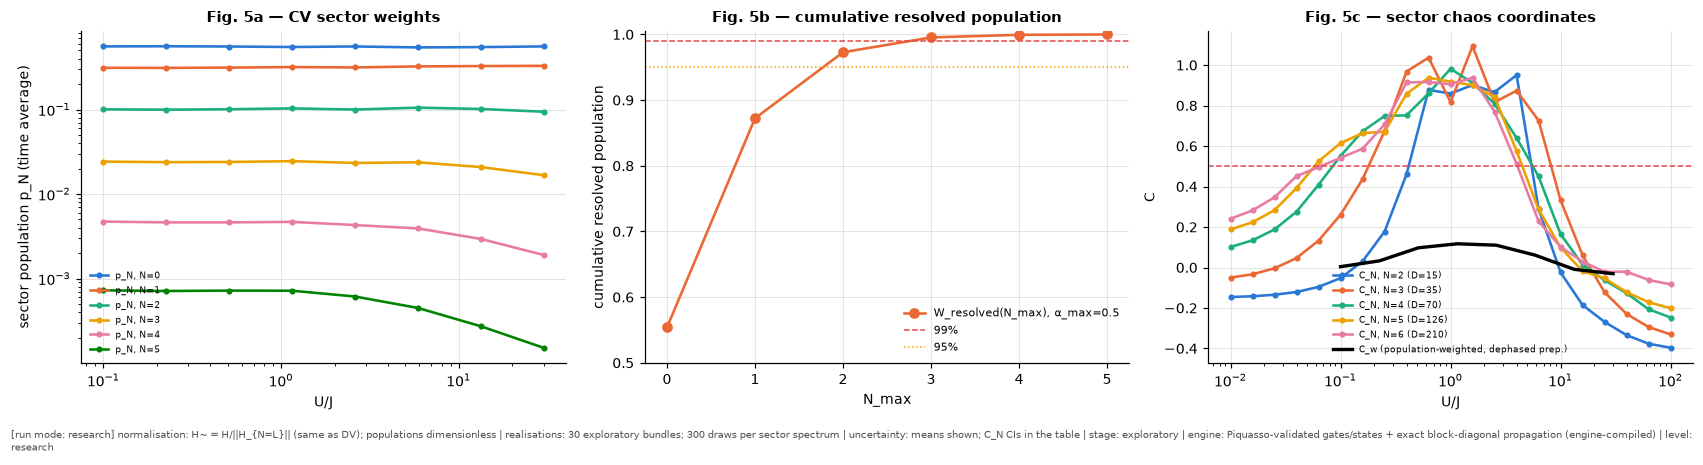

In [44]:
CVK_FIX = dict(alpha=ALPHA_CV, tau=TAU_LONG, prep="dephased", c=CVK_C, feats="number")
with section("8.4 CV convergence and Phase 1 protocol"):
    g_cv = [float(g) for g in CFG["cvk_g"]]; conv_bank = Bank("cvk", "explore", phase_cfg("phase2", "cvk_conv_real")); conv_rows = []
    for g in [float(g) for g in CFG["cvk_conv_g"]]:
        a_ = cvk_unit(g, conv_bank, CVK_FIX, n=conv_bank.n, lyap=False); b_ = cvk_unit(g, conv_bank, dict(CVK_FIX, c=CFG["cvk_cut"][1]), n=conv_bank.n, lyap=False)
        for ra, rb in zip(a_, b_):
            conv_rows.append(dict(g=g, r=ra["r"], dNMSE=abs(ra["NARMA5 NMSE"] - rb["NARMA5 NMSE"]), dCw=abs(C_weighted(ra["p_N"], g) - C_weighted(rb["p_N"], g)),
                                  trunc_c1=rb["trunc"], W_res=float(ra["p_N"].sum()), W_res_c1=float(rb["p_N"][:CVK_C].sum())))
    CONV = pd.DataFrame(conv_rows); CONV["converged"] = (CONV.dNMSE < 0.02) & (CONV.dCw < 0.02) & (CONV.trunc_c1 < 1e-3)
    CV_EX = run_scan(lambda x, b, f: cvk_unit(x, b, f), g_cv, CVK_BANKS["explore"], CVK_FIX)
    CV_EX["C_w"] = [C_weighted(p, g) for p, g in zip(CV_EX.p_N, CV_EX.g)]
    Cw_mean = CV_EX.groupby("x").C_w.mean(); Wmin = float(CONV.W_res_c1.min())          # resolved weight measured at cutoff c+1 (never inside the truncation)
    rngb = rng_for("cw-edge"); Mcw = np.array([[CV_EX[(np.isclose(CV_EX.x, x)) & (CV_EX.r == r)].C_w.iloc[0] for r in sorted(CV_EX.r.unique())] for x in g_cv])
    v_cw = crossing(g_cv, Mcw.mean(1), 0.5, "high"); bs = np.array([crossing(g_cv, Mcw[:, rngb.integers(0, Mcw.shape[1], Mcw.shape[1])].mean(1), 0.5, "high") for _ in range(CFG["boot"])])
    fin = bs[np.isfinite(bs)]
    EDGE_CW = dict(value=v_cw, lo=float(np.quantile(fin, 0.025)) if len(fin) > 20 else np.nan, hi=float(np.quantile(fin, 0.975)) if len(fin) > 20 else np.nan,
                   found=bool(np.isfinite(v_cw) and np.isfinite(bs).mean() >= 0.9 and Wmin >= 0.95), task_independent=True)
    EDGE_CH_CV = channel_edge(CV_EX, g_cv)
    cand_cv = float(CV_EX.groupby("x")["NARMA5 NMSE"].mean().idxmin())
    lock_candidate("H1-CVK", candidate=cand_cv, edge=[EDGE_CW["value"], EDGE_CW["lo"], EDGE_CW["hi"]], explore_n=CVK_BANKS["explore"].n)
    lock_candidate("H2-CVK", candidate=cand_cv, edge=[EDGE_CH_CV["value"], EDGE_CH_CV["lo"], EDGE_CH_CV["hi"]], explore_n=CVK_BANKS["explore"].n)
    gcv_c, nb_cv = confirm_grid(g_cv, cand_cv, [EDGE_CW["value"], EDGE_CH_CV["value"]])
    CV_CF = run_scan(lambda x, b, f: cvk_unit(x, b, f), gcv_c, CVK_BANKS["confirm"], CVK_FIX)
    CV_CF["C_w"] = [C_weighted(p, g) for p, g in zip(CV_CF.p_N, CV_CF.g)]
    # C6: a confirmatory point is cutoff-limited if a convergence-subset U/J at or bracketing it failed the c -> c+1 rule (any bundle)
    conv_g = np.array(sorted(CONV.g.unique())); bad_g = np.array(sorted(CONV[~CONV.converged].g.unique()))
    def cutoff_limited(x):
        lo, hi = conv_g[conv_g <= x * (1 + 1e-9)], conv_g[conv_g >= x * (1 - 1e-9)]
        return any(np.isclose(b, bad_g).any() for b in ([lo.max()] if len(lo) else []) + ([hi.min()] if len(hi) else []))
    NONCONV_CV = [float(x) for x in gcv_c if cutoff_limited(x)]
    for hid, edge in (("H1-CVK", EDGE_CW), ("H2-CVK", EDGE_CH_CV)):
        evaluate_hypothesis(hid, CV_CF, gcv_c, LOCKS[hid]["candidate"], edge, level=PHASE_LEVEL["phase2"], neighbours=nb_cv,
                            edge_points=[edge["value"]] if np.isfinite(edge["value"]) else [], nonconverged=NONCONV_CV)
print("cutoff-limited confirmatory U/J points (C6):", NONCONV_CV or "none")
record_test("P8.weight", "Phase 2: resolved sectors (N <= c-1) hold >= 95% (preferably 99%) of the population, measured at cutoff c+1 on every U/J", f"min W_res {Wmin:.4f}",
            ">= 0.95 (target 0.99)", Wmin >= 0.95, section_ref="8.4", category="physics")
record_test("N8.cutoff", "cutoff c -> c+1 and sector-range convergence (all convergence-subset configurations, none omitted)",
            f"{int(CONV.converged.sum())} of {len(CONV)} converged; max dNMSE {CONV.dNMSE.max():.3g}, max dC_w {CONV.dCw.max():.3g}, max trunc {CONV.trunc_c1.max():.1e}",
            "all converged", bool(CONV.converged.all()), critical=False, section_ref="8.4")
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(CONV.groupby("g")[["dNMSE", "dCw", "trunc_c1", "W_res", "converged"]].agg(["max"]).round(4))
    display(hyp_table(["H1-CVK", "H2-CVK"]))

fig, axs = plt.subplots(1, 3, figsize=(15.5, 3.9))
pN = np.stack(CV_EX.p_N.values); gg = CV_EX.g.values
for Ns in range(CVK_C):
    m_ = [pN[np.isclose(gg, g), Ns].mean() for g in g_cv]; axs[0].plot(g_cv, m_, "o-", ms=3, color=PAL[Ns % len(PAL)], label=f"p_N, N={Ns}")
axs[0].set(xscale="log", yscale="log", xlabel="U/J", ylabel="sector population p_N (time average)", title="Fig. 5a — CV sector weights"); axs[0].legend(fontsize=6)
cum = np.cumsum(pN.mean(0)); axs[1].plot(range(CVK_C), cum, "o-", color=COL["cv"], label=f"W_resolved(N_max), α_max={ALPHA_CV}")
axs[1].axhline(0.99, color=COL["red"], ls="--", lw=1, label="99%"); axs[1].axhline(0.95, color=COL["yel"], ls=":", lw=1, label="95%")
axs[1].set(xlabel="N_max", ylabel="cumulative resolved population", ylim=(min(0.5, cum.min() * 0.95), 1.005), title="Fig. 5b — cumulative resolved population"); axs[1].legend(fontsize=7)
for Ns, c in zip(range(2, CFG["cvk_cut"][1]), PAL):
    d = SEC_DF[SEC_DF.N == Ns]; axs[2].plot(d.g, d.C, "o-", ms=3, color=c, label=f"C_N, N={Ns} (D={d.D.iloc[0]})")
axs[2].plot(Cw_mean.index, Cw_mean.values, "k-", lw=2.2, label="C_w (population-weighted, dephased prep.)")
axs[2].axhline(0.5, color=COL["red"], ls="--", lw=1); axs[2].set(xscale="log", xlabel="U/J", ylabel="C", title="Fig. 5c — sector chaos coordinates"); axs[2].legend(fontsize=6)
figmeta(fig, normalisation="H~ = H/||H_{N=L}|| (same as DV); populations dimensionless", realisations=f"{CVK_BANKS['explore'].n} exploratory bundles; {CFG['cvk_sector_real']} draws per sector spectrum",
        uncertainty="means shown; C_N CIs in the table", stage="exploratory", engine="Piquasso-validated gates/states + exact block-diagonal propagation (engine-compiled)",
        level=PHASE_LEVEL["phase2"])
plt.tight_layout(); plt.show()
RESULTS["cv_kerr"] = dict(alpha=ALPHA_CV, route=RA, coherence=COH_SUMMARY, sector_tasks=SECTOR_TASKS, convergence=CONV, explore=CV_EX, confirm=CV_CF, edges=dict(C_w=EDGE_CW, channel=EDGE_CH_CV))

# 9. Matched DV–CV experiment (Phase 3)
> **Established in literature.** A fixed-$N$ Fock sector of a CV system is exactly a DV (photon-number) system. Linear optics is exactly solvable in both descriptions.
> **Adapted here.** One disordered Bose–Hubbard Hamiltonian is represented twice:
> * through Perceval (DV): hopping generator from `prob_amplitude`, plus the exact Kerr adapter;
> * through Piquasso (CV): hopping from native `Interferometer` Fock columns, and the on-site term from native `Kerr` + `Phaseshifter` phases.
>
> The two are compared first in their common fixed-$N$ sector, then along a controlled path to the genuine multi-sector CV reservoir.
> **Proposed novel element.** The decomposition A→E below, which separates the effect of dynamics and state preparation from the effect of measurement features.

**Matched quantities, asserted programmatically in §9.2:**
* graph ($L=5$ open chain), boundary conditions, disorder law **and the exact disorder draw** of every bundle;
* $U/J$;
* normalisation $\lVert H_{N=L}\rVert_2$;
* injection interval $\tilde\tau_{\rm long}$;
* input sequence, washout/train/validation/test splits;
* feature count (20 per sub-step, 2 sub-steps), feature definitions, ridge $\lambda$ grid;
* measurement budget $M$ per step in the finite-shot comparison.

## 9.1 Common fixed-$N$ limit: Perceval vs Piquasso
$H_{\rm CV}$ is assembled only from Piquasso output:
$$H^{\rm pq}_{\rm hop}=\frac{i}{t_0}\log\Bigl[\mathcal P_N\,\mathrm{Fock}\bigl(\mathtt{Interferometer}(e^{-iht_0})\bigr)\mathcal P_N\Bigr],\qquad
\bigl(H^{\rm pq}_{\rm Kerr}\bigr)_{jj}=-\frac1{t_0}\arg\,\mathrm{Fock}\bigl(\mathtt{Kerr}(-Ut_0/2)\,\mathtt{Phaseshifter}(Ut_0/2)\bigr)_{jj},$$
with $t_0$ small enough for the principal branch. Its **basis ordering** is mapped through Piquasso's occupation keys, not assumed.

In [45]:
def piquasso_hopping(h, L, N, t0=None):
    """Fixed-N hopping generator from native Piquasso Interferometer Fock columns (principal log); weight outside sector N reported."""
    B = sector(L, N); idx = {b: i for i, b in enumerate(B)}; t0 = t0 or 0.2 * math.pi / (N * np.abs(np.linalg.eigvalsh(h)).max())
    Uh = np.zeros((len(B), len(B)), complex); leak = 0.0
    for j, b in enumerate(B):
        for kk, a in pq_fock_column(L, N + 1, b, [(tuple(range(L)), pq.Interferometer(matrix=sla.expm(-1j * t0 * h)))]).items():
            kk = tuple(int(x) for x in kk)
            if sum(kk) == N:
                Uh[idx[kk], j] = a
            else:
                leak = max(leak, abs(a))
    Hh = 1j * sla.logm(Uh) / t0; return 0.5 * (Hh + Hh.conj().T), leak

def piquasso_onsite(g, L, N):
    """On-site diagonal from native Piquasso Kerr(xi) + Phaseshifter(phi) phases (disorder-independent); t0 keeps every phase below 0.4 pi."""
    B = sector(L, N); t0 = min(0.02, 0.4 * math.pi / (max(abs(g), 1e-12) * max(N * (N - 1), 1)))
    return np.array([-np.angle(pq_fock_column(L, N + 1, b, [((i,), pq.Kerr(xi=-0.5 * t0 * g)) for i in range(L)] + [((i,), pq.Phaseshifter(phi=0.5 * t0 * g)) for i in range(L)])[tuple(b)]) / t0 for b in B])

def piquasso_sector_hamiltonian(h, g, L, N):
    Hh, leak = piquasso_hopping(h, L, N); return Hh, piquasso_onsite(g, L, N), leak

with section("9.1 fixed-N agreement Perceval vs Piquasso"):
    MB_ = Bank("match", "confirm", phase_cfg("phase3", "match_real")); g_test = 1.7
    eps_m = disorder(LDV, W_BH, 0, MB_.name, MB_.stage); h_m = hopping_matrix(LDV, 1.0, eps_m)
    H_dv_hop = perceval_hopping_generator(h_m, sector(LDV, NDV)); H_dv = H_dv_hop + np.diag(interaction_diag(sector(LDV, NDV), g_test))
    H_pq_hop, kerr_pq, leak_pq = piquasso_sector_hamiltonian(h_m, g_test, LDV, NDV); H_pq = H_pq_hop + np.diag(kerr_pq)
    ev_dv, ev_pq = np.linalg.eigvalsh(H_dv), np.linalg.eigvalsh(H_pq)
    Udv = sla.expm(-1j * H_dv * 0.9); Upq = sla.expm(-1j * H_pq * 0.9)
    ports_t = port_states_perceval(input_sequence("match", "validation", 0, 150), NDV); p1 = [np.stack([p[:150]]) for p in ports_t]
    Xa = FockReservoirBatch(LDV, NDV, [H_dv_hop], g_test).run(p1, 20.0, T=150); pa_ = FockReservoirBatch(LDV, NDV, [H_dv_hop], g_test); pa_.run(p1, 20.0, T=150, keep_diag=True)
    Xb = FockReservoirBatch(LDV, NDV, [H_pq_hop], g_test, kerr_diag=kerr_pq).run(p1, 20.0, T=150); pb_ = FockReservoirBatch(LDV, NDV, [H_pq_hop], g_test, kerr_diag=kerr_pq); pb_.run(p1, 20.0, T=150, keep_diag=True)
    MATCH_TOL = pd.DataFrame([
        dict(quantity="basis ordering (Piquasso keys -> Perceval tuples)", max_abs_diff=float(leak_pq), tolerance="1e-12 (no weight outside sector N)"),
        dict(quantity="Hamiltonian matrix", max_abs_diff=float(np.abs(H_dv - H_pq).max()), tolerance="1e-10"),
        dict(quantity="eigenvalues", max_abs_diff=float(np.abs(ev_dv - ev_pq).max()), tolerance="1e-10"),
        dict(quantity="time-evolution operator exp(-iHt), t=0.9", max_abs_diff=float(np.abs(Udv - Upq).max()), tolerance="1e-10"),
        dict(quantity="occupation probabilities along 150 reservoir steps", max_abs_diff=float(np.abs(pa_.diags - pb_.diags).max()), tolerance="1e-10"),
        dict(quantity="lossless task features (n_i, n_i n_j), 150 steps", max_abs_diff=float(np.abs(Xa - Xb).max()), tolerance="1e-10")])
    MATCH_TOL["pass"] = MATCH_TOL.max_abs_diff < 1e-10
    # native Piquasso Trotter circuit in the matched sector (engine-level time evolution)
    terr = {}; B55 = sector(LDV, NDV); jcol = int(np.argmax(interaction_diag(B55, 1.0))); nrm = spectral_norm(H_dv)
    for nT in (2, 4, 8):
        dt = 0.9 / nT; half = sla.expm(-0.5j * dt * h_m); ins = []
        for _ in range(nT):
            ins += [(tuple(range(LDV)), pq.Interferometer(matrix=half))] + [((i,), pq.Kerr(xi=-0.5 * dt * g_test)) for i in range(LDV)]
            ins += [((i,), pq.Phaseshifter(phi=0.5 * dt * g_test)) for i in range(LDV)] + [(tuple(range(LDV)), pq.Interferometer(matrix=half))]
        am = pq_fock_column(LDV, NDV + 1, B55[jcol], ins); v = np.zeros(len(B55), complex)
        for kk, a in am.items():
            kk = tuple(int(x) for x in kk)
            if sum(kk) == NDV:
                v[B55.index(kk)] = a
        terr[nT] = float(np.abs(v - Udv[:, jcol]).max())
display(MATCH_TOL)
record_test("E9.match", "DV (Perceval + adapter) = CV (native Piquasso gates) in the common fixed-N sector: H, spectrum, propagator, probabilities, features",
            f"max diff {MATCH_TOL.max_abs_diff.max():.1e}", "all < 1e-10", bool(MATCH_TOL["pass"].all()), section_ref="9.1", category="engine")
record_test("N9.trotter", "native Piquasso Trotter circuit -> exact matched propagator (second order)", {k: f"{v:.1e}" for k, v in terr.items()}.__repr__(),
            "error ratio per halving in [3, 5]", 3 < terr[2] / terr[4] < 5 and 3 < terr[4] / terr[8] < 5, section_ref="9.1")

[9.1 fixed-N agreement Perceval vs Piquasso] 2.8 s | peak host memory 1206 MB | GPU pool 24 MB


,quantity,max_abs_diff,tolerance,pass
0,basis ordering (Piquasso keys -> Perceval tuples),0.000000e+00,1e-12 (no weight outside sector N),True
1,Hamiltonian matrix,1.643130e-14,1e-10,True
2,eigenvalues,6.927792e-14,1e-10,True
3,"time-evolution operator exp(-iHt), t=0.9",1.093443e-14,1e-10,True
4,occupation probabilities along 150 reservoir s...,1.332268e-14,1e-10,True
5,"lossless task features (n_i, n_i n_j), 150 steps",7.620571e-13,1e-10,True


PASS [E9.match] DV (Perceval + adapter) = CV (native Piquasso gates) in the common fixed-N sector: H, spectrum, propagator, probabilities, features: max diff 7.6e-13 (criterion all < 1e-10)
PASS [N9.trotter] native Piquasso Trotter circuit -> exact matched propagator (second order): {2: '5.8e-01', 4: '1.3e-01', 8: '3.1e-02'} (criterion error ratio per halving in [3, 5])


True

## 9.2 From the fixed-$N$ DV reservoir to the multi-sector CV reservoir: separating dynamics from measurement
The same bundles (disorder draw and input sequence) drive five reservoirs. Each consecutive pair differs in **one** ingredient:

| variant | Hamiltonian from | state space | input channel | features (20 per sub-step) |
|---|---|---|---|---|
| A | Perceval + Kerr adapter | fixed $N=5$ | port refresh | $n_i$, $n_in_j$ |
| B | native Piquasso gates | fixed $N=5$ | port refresh | $n_i$, $n_in_j$ |
| C | same $H$ | all $N<c$ | phase-randomised replacement | $n_i$, $n_in_j$ |
| D | same $H$ | all $N<c$ | coherent replacement | $n_i$, $n_in_j$ |
| E | same $H$ | all $N<c$ | coherent replacement | $n_i$, $\mathrm{Re/Im}\langle a_i\rangle$, $n_in_{i+1}$, $n_0^2$ |

* B−A tests the engines, and must be zero within tolerance.
* C−B isolates **dynamics and state preparation**: the fixed-$N$ port refresh versus multi-sector replacement.
* D−C isolates **inter-sector coherence**.
* E−D isolates the **measurement features**, at fixed dynamics.

Differences are paired per bundle, with bootstrap CIs over bundles. The finite-shot comparison gives A and D the same budget of $M$ joint PNR shots per step.

PASS [N9.shots] vectorised joint-PNR sampler = per-shot reference in distribution (mean and variance of all moment features; eta = 1 and 0.6): max |z| of mean difference 2.16; max |log variance ratio| 0.064 (criterion |z| < 4, |log ratio| < 0.15)


[9.2 matched decomposition A-E] 342.0 s | peak host memory 1779 MB | GPU pool 748 MB | reused checkpointed units: 7452 s of earlier compute + 3 untimed units
PASS [E9.decompBA] variant B - A (engines only) is zero within numerical tolerance for every U/J and bundle: max |mean diff| 2.5e-11 (criterion < 1e-6)
PASS [S9.matched] matched resources asserted: identical disorder draws, inputs, splits, feature counts (20/sub-step), lambda grid: asserted in match_unit (criterion no assertion error)


mean_diff                              
g                          0.030000  1.000000  4.564971  60.000000
contrast                                                          
B-A engines                   0.0000   -0.0000   -0.0000   -0.0000
C-B dynamics/preparation     -0.1897   -0.3827   -0.3207    0.2896
D-C inter-sector coherence    0.3745    0.1199    0.1155   -0.5621
E-D measurement features     -0.1331   -0.0064    0.0003   -0.1957

A               D        
         mean     std    mean     std
M                                    
100    0.9544  0.0270  0.6127  0.0605
1000   0.7664  0.0554  0.3984  0.0561
10000  0.5919  0.0514  0.2643  0.0401

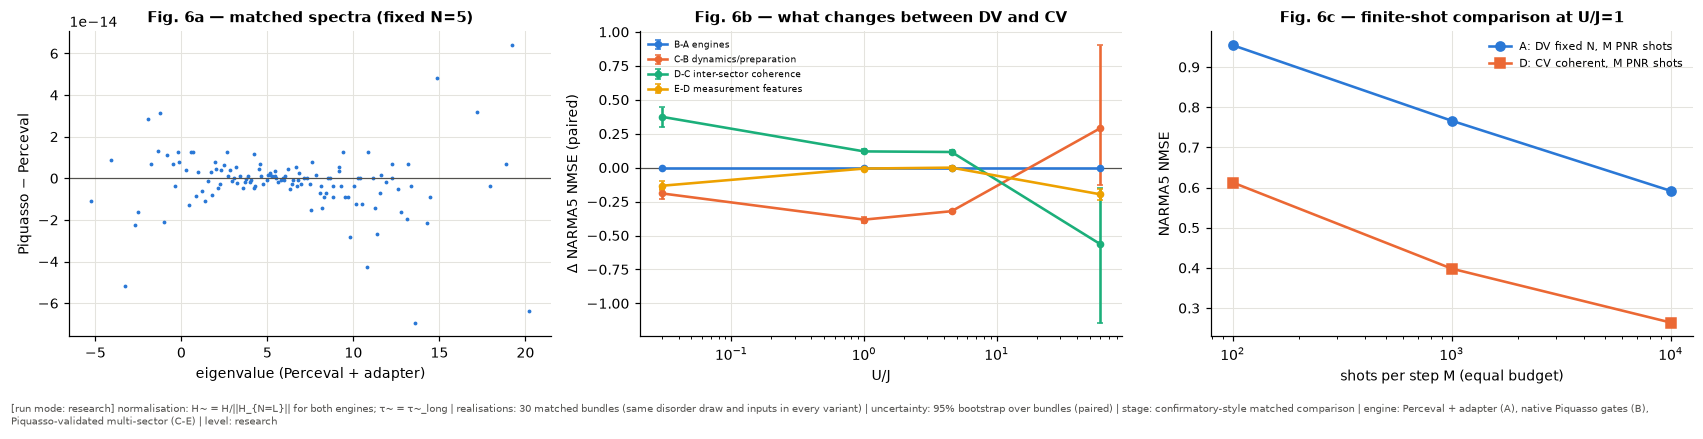

In [46]:
_THIN_CACHE = {}

def _thinning(nmat, eta):
    """Detected patterns and the binomial-thinning kernel K[n, m] = prod_i Binom(m_i; n_i, eta) (None for eta = 1)."""
    key = (nmat.shape, nmat.tobytes(), float(eta))
    if key not in _THIN_CACHE:
        if eta >= 1:
            _THIN_CACHE[key] = (nmat, None)
        else:
            L = nmat.shape[1]; pats = np.array([b for n in range(int(nmat.sum(1).max()) + 1) for b in fock_basis(L, n)], float)
            _THIN_CACHE[key] = (pats, np.prod(sst.binom.pmf(pats[None, :, :], nmat[:, None, :], eta), axis=2))
    return _THIN_CACHE[key]

def shot_features(dists, nmat, ops_fn, M, rng, eta=1.0):
    """Features from M jointly sampled PNR patterns per step and sub-interval (optionally binomially thinned: detector
    efficiency eta). Whole occupation patterns are sampled, so inter-mode correlations are preserved.
    Shots are i.i.d., so the detected-pattern counts are Multinomial(M, p K) with K the thinning kernel; ops_fn is a shot
    average (moments), hence linear in the counts. This is exact in distribution to `_shot_features_reference` (test N9.shots)
    and draws all steps in one call."""
    T, S, D = dists.shape; pats, K = _thinning(np.asarray(nmat, float), eta)
    P = np.clip(dists.reshape(T * S, D), 0, None); P = P / P.sum(1, keepdims=True)
    if K is not None:
        P = P @ K; P = P / P.sum(1, keepdims=True)
    F = np.stack([ops_fn(p_[None]) for p_ in pats])
    return (rng.multinomial(M, P) @ F / M).reshape(T, S * F.shape[1])

def _shot_features_reference(dists, nmat, ops_fn, M, rng, eta=1.0):
    """Per-shot implementation (materialises every sampled pattern); kept only as the validation oracle for `shot_features`."""
    T, S, D = dists.shape; X = []
    for k in range(T):
        row = []
        for s in range(S):
            p = np.clip(dists[k, s], 0, None); counts = rng.multinomial(M, p / p.sum()); shots = np.repeat(nmat, counts, axis=0)
            if eta < 1:
                shots = rng.binomial(shots.astype(int), eta)
            row.append(ops_fn(shots))
        X.append(np.concatenate(row))
    return np.array(X)

def moment_ops(L):
    iu = np.triu_indices(L)
    return lambda sh: np.concatenate([sh.mean(0), (sh[:, :, None] * sh[:, None, :]).mean(0)[iu]])

# fast sampler vs per-shot reference: same mean (unbiased for the exact moments) and same shot-noise variance, with and without thinning
_Bt = np.asarray(sector(3, 3), float); _pt = rng_for("shot-test").dirichlet(np.ones(len(_Bt)), size=(4000, 1)); _worst = []
for _eta in (1.0, 0.6):
    _pats, _K = _thinning(_Bt, _eta); _F = np.stack([moment_ops(3)(p_[None]) for p_ in _pats])
    _ex = (_pt[:, 0] @ _K if _K is not None else _pt[:, 0]) @ _F
    _a = shot_features(_pt, _Bt, moment_ops(3), 40, rng_for("shot-a", _eta), _eta) - _ex
    _b = _shot_features_reference(_pt, _Bt, moment_ops(3), 40, rng_for("shot-b", _eta), _eta) - _ex
    _z = np.abs(_a.mean(0) - _b.mean(0)) / np.sqrt((_a.var(0) + _b.var(0)) / len(_a)); _vr = _a.var(0) / _b.var(0)
    _worst.append((float(_z.max()), float(np.abs(np.log(_vr)).max())))
record_test("N9.shots", "vectorised joint-PNR sampler = per-shot reference in distribution (mean and variance of all moment features; eta = 1 and 0.6)",
            f"max |z| of mean difference {max(w[0] for w in _worst):.2f}; max |log variance ratio| {max(w[1] for w in _worst):.3f}", "|z| < 4, |log ratio| < 0.15",
            all(w[0] < 4 and w[1] < 0.15 for w in _worst), section_ref="9.2")

def match_unit(g, bank):
    key = dict(engine="match", g=float(g), bank=bank.name, stage=bank.stage, n=bank.n, alpha=ALPHA_CV, tau=TAU_LONG, seq=CFG["seq"],
               ipc=(CFG["ipc_deg"], CFG["ipc_delay"], CFG["n_null"], CFG["refits"]), v=ENGINE_VERSIONS["cvk"])
    def compute():
        bs = [dict(eps=disorder(LDV, W_BH, r, bank.name, bank.stage), u=input_sequence(bank.name, bank.stage, r)) for r in bank.ids()]
        rows = []; hs = [hopping_matrix(LDV, 1.0, b["eps"]) for b in bs]
        dvb = [dv_bundle(LDV, NDV, bank.name, bank.stage, r) for r in bank.ids()]
        assert all(np.array_equal(b["eps"], d["eps"]) and np.array_equal(b["u"], d["u"]) for b, d in zip(bs, dvb)), "bundle mismatch between DV and CV"
        ports = stack_ports(dvb)
        XA = FockReservoirBatch(LDV, NDV, [d["hop"] for d in dvb], g).run(ports, TAU_LONG)
        kp = STORE.cached("pq-onsite", dict(g=float(g), L=LDV, N=NDV, v=ENGINE_VERSIONS["cvk"]), lambda: piquasso_onsite(g, LDV, NDV))
        hps = [STORE.cached("pq-hop", dict(bank=bank.name, stage=bank.stage, r=r, L=LDV, N=NDV, v=ENGINE_VERSIONS["cvk"]), lambda h=h: piquasso_hopping(h, LDV, NDV)[0]) for r, h in zip(bank.ids(), hs)]
        XB = np.stack([FockReservoirBatch(LDV, NDV, [hp], g, kerr_diag=kp).run([p[j:j + 1] for p in ports], TAU_LONG)[0] for j, hp in enumerate(hps)])
        eng = KerrCVBatch(LDV, CVK_C, hs, g); amps = np.stack([coherent_amplitudes(b["u"], ALPHA_CV, CVK_C) for b in bs])
        oC = eng.run(amps, TAU_LONG, prep="dephased"); oD = eng.run(amps, TAU_LONG, prep="coherent")
        feats = {"A": XA, "B": XB, "C": oC["Xn"], "D": oD["Xn"], "E": np.stack([quad20_features(oD, j, LDV) for j in range(len(bs))])}
        assert len({v.shape[-1] for v in feats.values()}) == 1, "feature counts differ"
        for var, X in feats.items():
            for j, b in enumerate(bs):
                ev = evaluate_features(X[j], task_design(b["u"], (bank.name, bank.stage, j)))
                rows.append(dict(variant=var, g=float(g), r=j, **summarize(ev)))
        return rows
    return STORE.cached("match-unit", key, compute)

with section("9.2 matched decomposition A-E"):
    G_MATCH = sorted(g for g in {float(min(CFG["dv_g_explore"])), float(G_CHAOS), float(E_DV["high"]["value"]), float(max(CFG["dv_g_explore"]))} if np.isfinite(g))[:CFG["match_g_n"]]
    MATCH = pd.concat([pd.DataFrame(match_unit(g, MB_)) for g in G_MATCH], ignore_index=True)
    dec_rows = []
    for g in G_MATCH:
        P_ = MATCH[MATCH.g == g].pivot(index="r", columns="variant", values="NARMA5 NMSE")
        for lab, (a, b) in {"B-A engines": ("B", "A"), "C-B dynamics/preparation": ("C", "B"), "D-C inter-sector coherence": ("D", "C"), "E-D measurement features": ("E", "D")}.items():
            d = (P_[a] - P_[b]).values; rg = rng_for("dec", g, lab); bs_ = [np.mean(d[rg.integers(0, len(d), len(d))]) for _ in range(CFG["boot"])]
            dec_rows.append(dict(g=g, contrast=lab, mean_diff=float(d.mean()), CI=(float(np.quantile(bs_, 0.025)), float(np.quantile(bs_, 0.975))), n=len(d)))
    DECOMP = pd.DataFrame(dec_rows)
    ba = DECOMP[DECOMP.contrast == "B-A engines"].mean_diff.abs().max()
    # finite-shot comparison at equal measurement budget (joint PNR shots), U/J = g_chaos
    fs_rows = []; bs0 = [dv_bundle(LDV, NDV, MB_.name, MB_.stage, r) for r in MB_.ids()]; pA = FockReservoirBatch(LDV, NDV, [b["hop"] for b in bs0], G_CHAOS)
    pA.run(stack_ports(bs0), TAU_LONG, keep_diag=True)
    engD = KerrCVBatch(LDV, CVK_C, [hopping_matrix(LDV, 1.0, b["eps"]) for b in bs0], G_CHAOS)
    oDd = engD.run(np.stack([coherent_amplitudes(b["u"], ALPHA_CV, CVK_C) for b in bs0]), TAU_LONG, prep="coherent", keep_diag=True)
    for M in CFG["shots"]:
        for j, b in enumerate(bs0):
            des = task_design(b["u"], (MB_.name, MB_.stage, j))
            XA_s = shot_features(pA.diags[j], np.asarray(sector(LDV, NDV), float), moment_ops(LDV), M, rng_for("shotsA", M, j))
            XD_s = shot_features(oDd["diags"][j], np.asarray(engD.basis, float), moment_ops(LDV), M, rng_for("shotsD", M, j))
            fs_rows.append(dict(M=M, r=j, A=evaluate_features(XA_s, des, secondary=False)["primary"], D=evaluate_features(XD_s, des, secondary=False)["primary"]))
    FINITE_SHOT = pd.DataFrame(fs_rows).groupby("M")[["A", "D"]].agg(["mean", "std"])
record_test("E9.decompBA", "variant B - A (engines only) is zero within numerical tolerance for every U/J and bundle", f"max |mean diff| {ba:.1e}", "< 1e-6", ba < 1e-6,
            section_ref="9.2", category="engine")
record_test("S9.matched", "matched resources asserted: identical disorder draws, inputs, splits, feature counts (20/sub-step), lambda grid", "asserted in match_unit",
            "no assertion error", len(MATCH) == 5 * len(G_MATCH) * MB_.n, section_ref="9.2", category="statistics")
with pd.option_context("display.width", 220):
    display(DECOMP.assign(CI=DECOMP.CI.map(lambda c: f"[{c[0]:.4f}, {c[1]:.4f}]")).pivot(index="contrast", columns="g", values=["mean_diff"]).round(4))
    display(FINITE_SHOT.round(4))

fig, axs = plt.subplots(1, 3, figsize=(15.5, 3.8))
axs[0].plot(ev_dv, ev_pq - ev_dv, ".", color=COL["dv"], ms=3); axs[0].set(xlabel="eigenvalue (Perceval + adapter)", ylabel="Piquasso − Perceval", title="Fig. 6a — matched spectra (fixed N=5)")
axs[0].axhline(0, color=COL["ink2"], lw=0.8)
for (lab, c) in zip(["B-A engines", "C-B dynamics/preparation", "D-C inter-sector coherence", "E-D measurement features"], PAL):
    d = DECOMP[DECOMP.contrast == lab]; axs[1].errorbar(d.g, d.mean_diff, yerr=[d.mean_diff - d.CI.map(lambda t: t[0]), d.CI.map(lambda t: t[1]) - d.mean_diff], fmt="o-", ms=4, capsize=2, color=c, label=lab)
axs[1].axhline(0, color=COL["ink2"], lw=0.8); axs[1].set(xscale="log", xlabel="U/J", ylabel="Δ NARMA5 NMSE (paired)", title="Fig. 6b — what changes between DV and CV"); axs[1].legend(fontsize=6)
fsm = pd.DataFrame(fs_rows).groupby("M")[["A", "D"]].mean(); axs[2].plot(fsm.index, fsm.A, "o-", color=COL["dv"], label="A: DV fixed N, M PNR shots")
axs[2].plot(fsm.index, fsm.D, "s-", color=COL["cv"], label="D: CV coherent, M PNR shots"); axs[2].set(xscale="log", xlabel="shots per step M (equal budget)", ylabel="NARMA5 NMSE",
                                                                                           title=f"Fig. 6c — finite-shot comparison at U/J={G_CHAOS:.3g}"); axs[2].legend(fontsize=7)
figmeta(fig, normalisation="H~ = H/||H_{N=L}|| for both engines; τ~ = τ~_long", realisations=f"{MB_.n} matched bundles (same disorder draw and inputs in every variant)",
        uncertainty="95% bootstrap over bundles (paired)", stage="confirmatory-style matched comparison", engine="Perceval + adapter (A), native Piquasso gates (B), Piquasso-validated multi-sector (C-E)",
        level=PHASE_LEVEL["phase3"])
plt.tight_layout(); plt.show()

## 9.3 Cross-engine scaling: is there one shared response curve?
$y=\log_{10}\mathrm{NMSE}_{\rm NARMA5}$ is modelled as a smooth function of one coordinate at a time:
* $C_{\rm spec}$ (DV) or $C_w$ (CV);
* $\Lambda_{\rm ch}$;
* $U/\Delta E$, with $\Delta E$ the mean level spacing of $H_{N=L}$;
* $\tau/t_H$, with $t_H$ the Heisenberg time of $H_{N=L}$.

$t/t_{\rm Th}$ is constant along the $U/J$ scans, and the CV reservoir has no $\tau$ scan, so no cross-engine test in $t/t_{\rm Th}$ is possible. This is reported as *not testable*.

Three models are compared on the combined DV and CV bundles (exploratory and confirmatory):
1. **M1:** one shared cubic spline.
2. **M2:** separate splines per engine.
3. **M3:** hierarchical partial pooling $f(x)+\delta_e(x)$ with $\delta_e\sim\mathcal N(0,\tau^2)$. $\tau^2$ is chosen by marginal likelihood.

**Evaluation.**
* Held-out, grouped 5-fold cross-validation, with folds over bundles so that a bundle is never split.
* Expected log predictive density (ELPD), with the paired standard error of ELPD differences, plus BIC on the full data.
* **Decision rule (preregistered):** the shared curve is *supported* if its ELPD is within 2 SE of the best model and $\Delta$BIC(M1 − best) $<10$. It is *rejected* if another model beats it by more than 2 SE of the ELPD difference.

[9.3 cross-engine scaling tests] 1.6 s | peak host memory 1779 MB | GPU pool 748 MB


,n,best,tau2,dELPD_M1_vs_best,SE,dBIC_M1,RMSE M1,RMSE M2,RMSE M3,verdict,level
C,1220,M2,1.0,-885.585622,35.549655,1719.935254,0.239831,0.115868,0.170425,shared curve rejected,research
Lambda,1220,M2,1.0,-381.547242,23.703114,710.584845,0.279614,0.20488,0.218429,shared curve rejected,research
U_over_dE,1220,M2,1.0,-745.238055,22.464394,1428.955036,0.331961,0.180164,0.182235,shared curve rejected,research
tau_over_tH,1220,M2,1.0,-672.50338,23.753157,1290.426312,0.362523,0.207325,0.207836,shared curve rejected,research
t_over_tTh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not testable (t/t_Th is constant along the U/J...,research


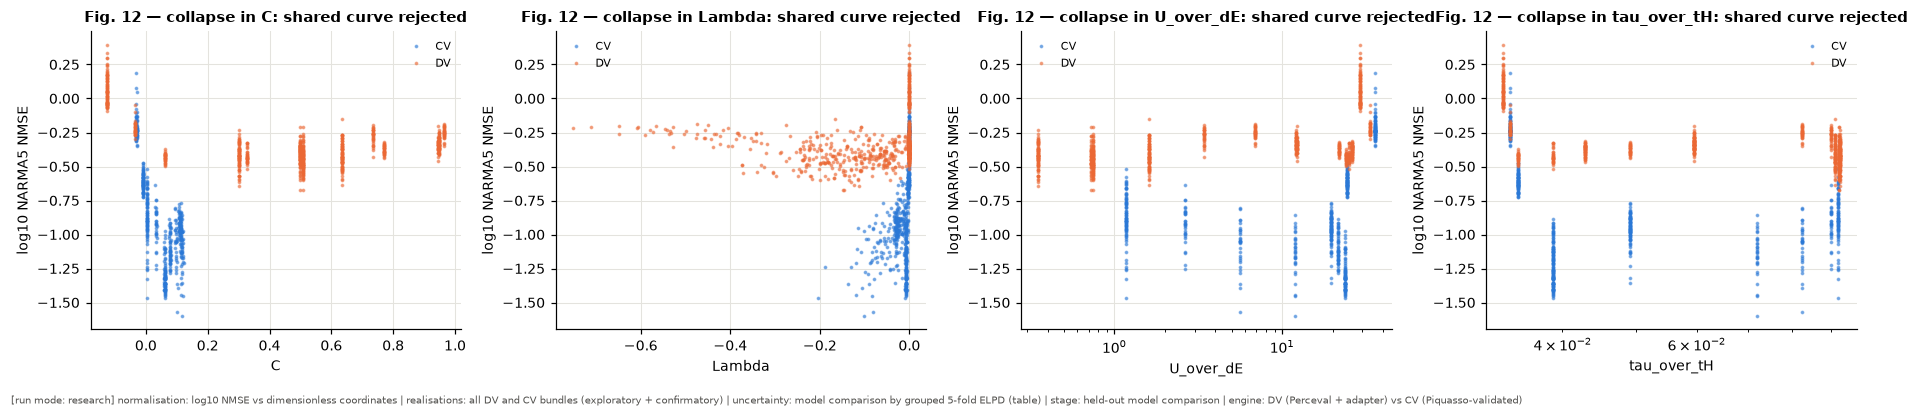

In [47]:
def spline_basis(x, knots):
    """Natural cubic spline basis (truncated-power form) with intercept."""
    x = np.asarray(x, float); K = len(knots); cols = [np.ones_like(x), x]
    def d(k):
        return (np.clip(x - knots[k], 0, None) ** 3 - np.clip(x - knots[-1], 0, None) ** 3) / (knots[-1] - knots[k])
    for k in range(K - 2):
        cols.append(d(k) - d(K - 2))
    return np.stack(cols, 1)

def collapse_models(df, coord, y="logNMSE", folds=5):
    d = df[[coord, y, "engine", "r"]].replace([np.inf, -np.inf], np.nan).dropna()
    engines = sorted(d.engine.unique())
    if len(engines) < 2 or len(d) < 20:
        return dict(verdict="not testable (fewer than two engines or too few points)")
    x = (d[coord].values - d[coord].mean()) / (d[coord].std() + 1e-12); knots = np.quantile(x, [0.05, 0.35, 0.65, 0.95]); Bm = spline_basis(x, knots); yy = d[y].values
    E = np.stack([(d.engine == e).values.astype(float) for e in engines], 1)
    def fit(model, tr, te, tau2=None):
        Xtr, Xte = design(model, Bm[tr], E[tr]), design(model, Bm[te], E[te]); pen = penalty(model, Bm.shape[1], len(engines), tau2)
        beta = np.linalg.solve(Xtr.T @ Xtr + pen, Xtr.T @ yy[tr]); res = yy[tr] - Xtr @ beta; s2 = res @ res / max(len(tr) - Xtr.shape[1], 1)
        mu = Xte @ beta; return -0.5 * np.log(2 * np.pi * s2) - 0.5 * (yy[te] - mu) ** 2 / s2, (yy[te] - mu) ** 2, s2, beta
    def design(model, B, Ei):
        if model == "M1":
            return B
        return np.hstack([B] + [B * Ei[:, [k]] for k in range(Ei.shape[1])])
    def penalty(model, p, ne, tau2):
        if model == "M1":
            return 1e-8 * np.eye(p)
        lam = 1e-8 if model == "M2" else 1.0 / max(tau2, 1e-12)
        P_ = np.zeros((p * (ne + 1), p * (ne + 1))); P_[p:, p:] = lam * np.eye(p * ne); P_[:p, :p] = 1e-8 * np.eye(p)
        if model == "M2":
            P_[:p, :p] = 1e6 * np.eye(p)          # M2: no shared part, engine-specific curves only
        return P_
    groups = (d.engine + "-" + d.r.astype(str)).values; ug = np.unique(groups); rng = rng_for("collapse-cv", coord); fold_of = dict(zip(ug, rng.permutation(len(ug)) % folds))
    fidx = np.array([fold_of[g_] for g_ in groups]); tau_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
    all_idx = np.arange(len(d))
    def ml_tau():                                   # marginal-likelihood choice of tau^2 on the full data (Gaussian, profile sigma)
        best = None
        for t2 in tau_grid:
            X_ = design("M3", Bm, E); P_ = penalty("M3", Bm.shape[1], len(engines), t2)
            beta = np.linalg.solve(X_.T @ X_ + P_, X_.T @ yy); r_ = yy - X_ @ beta; s2 = r_ @ r_ / len(yy)
            logdet = np.linalg.slogdet(X_.T @ X_ / s2 + P_ / s2)[1] - np.linalg.slogdet(P_[Bm.shape[1]:, Bm.shape[1]:] / s2)[1]
            ll = -0.5 * len(yy) * np.log(2 * np.pi * s2) - 0.5 * len(yy) - 0.5 * logdet
            best = max(best or (-np.inf, None), (ll, t2))
        return best[1]
    tau2 = ml_tau(); out = {}
    for m in ("M1", "M2", "M3"):
        lpd = np.empty(len(d)); se_ = np.empty(len(d))
        for f in range(folds):
            te = all_idx[fidx == f]; tr = all_idx[fidx != f]; l_, s_, _, _ = fit(m, tr, te, tau2); lpd[te] = l_; se_[te] = s_
        _, _, s2f, betaf = fit(m, all_idx, all_idx, tau2); k_ = design(m, Bm, E).shape[1] if m != "M3" else Bm.shape[1] * (1 + 0.5 * len(engines))
        out[m] = dict(elpd=float(lpd.sum()), lpd=lpd, rmse=float(np.sqrt(se_.mean())), bic=float(len(yy) * np.log(s2f) + k_ * np.log(len(yy))))
    best = max(out, key=lambda m: out[m]["elpd"]); dl = out["M1"]["lpd"] - out[best]["lpd"]; se_d = float(np.sqrt(len(dl)) * dl.std(ddof=1)) if best != "M1" else 0.0
    d_elpd = out["M1"]["elpd"] - out[best]["elpd"]; d_bic = out["M1"]["bic"] - min(v["bic"] for v in out.values())
    verdict = ("shared curve supported" if best == "M1" or (d_elpd > -2 * se_d and d_bic < 10) else
               "shared curve rejected" if d_elpd < -2 * se_d else "inconclusive")
    return dict(n=len(d), engines=engines, tau2=tau2, best=best, dELPD_M1_vs_best=d_elpd, SE=se_d, dBIC_M1=d_bic,
                **{f"ELPD {m}": out[m]["elpd"] for m in out}, **{f"RMSE {m}": out[m]["rmse"] for m in out}, verdict=verdict)

with section("9.3 cross-engine scaling tests"):
    def spectral_scales(g):
        E_ = SPEC[(LDV, NDV, min(CFG["g_spec"], key=lambda v: abs(np.log(v) - np.log(g))))]["spectra"]
        sp = np.mean([np.mean(np.diff(np.sort(e)[len(e) // 4: 3 * len(e) // 4])) for e in E_]); nrm = np.mean([np.abs(e).max() for e in E_])
        return g / sp, TAU_LONG / (2 * np.pi * nrm / sp)          # U/Delta E and tau/t_H (t_H = 2 pi / (mean spacing in H~ units))
    parts = []
    for eng_name, dfs, ccol in (("DV", [DV_EX_G, DV_CF_G], "C_spec"), ("CV", [CV_EX, CV_CF], "C_w")):
        d = pd.concat(dfs, ignore_index=True); d = d[~d.diverged]
        sc_ = np.array([spectral_scales(g) for g in d.g]); parts.append(pd.DataFrame(dict(engine=eng_name, r=d.stage + "-" + d.r.astype(str), C=d[ccol].values,
                                                                                         Lambda=d.Lambda.values, U_over_dE=sc_[:, 0], tau_over_tH=sc_[:, 1],
                                                                                         logNMSE=np.log10(d["NARMA5 NMSE"].values))))
    SCALING = pd.concat(parts, ignore_index=True)
    COLLAPSE = {c: collapse_models(SCALING, c) for c in ("C", "Lambda", "U_over_dE", "tau_over_tH")}
    COLLAPSE["t_over_tTh"] = dict(verdict="not testable (t/t_Th is constant along the U/J scans; no CV tau scan)")
    COLLAPSE_LEVEL = "research" if PHASE_LEVEL["phase1"] == PHASE_LEVEL["phase2"] == "research" else "smoke"   # pools DV (phase 1) and CV-Kerr (phase 2) rows
    for c in COLLAPSE:
        COLLAPSE[c]["level"] = COLLAPSE_LEVEL
with pd.option_context("display.width", 250):
    display(pd.DataFrame(COLLAPSE).T[["n", "best", "tau2", "dELPD_M1_vs_best", "SE", "dBIC_M1", "RMSE M1", "RMSE M2", "RMSE M3", "verdict", "level"]])
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, c in zip(axs, ("C", "Lambda", "U_over_dE", "tau_over_tH")):
    for (e, dd), col in zip(SCALING.groupby("engine"), (COL["dv"], COL["cv"])):
        ax.plot(dd[c], dd.logNMSE, ".", ms=3, alpha=0.5, color=col, label=e)
    ax.set(xlabel=c, ylabel="log10 NARMA5 NMSE", title=f"Fig. 12 — collapse in {c}: {COLLAPSE[c].get('verdict', '')[:28]}", xscale="log" if c in ("U_over_dE", "tau_over_tH") else "linear")
    ax.legend(fontsize=7)
figmeta(fig, normalisation="log10 NMSE vs dimensionless coordinates", realisations="all DV and CV bundles (exploratory + confirmatory)",
        uncertainty="model comparison by grouped 5-fold ELPD (table)", stage="held-out model comparison", engine="DV (Perceval + adapter) vs CV (Piquasso-validated)")
plt.tight_layout(); plt.show()
RESULTS["matched"] = dict(tolerances=MATCH_TOL, decomposition=DECOMP, finite_shot=FINITE_SHOT, collapse={k: {kk: vv for kk, vv in v.items() if kk != "lpd"} for k, v in COLLAPSE.items()})

# 10. Gaussian channel-edge controls
> **Established in literature.** Gaussian reservoirs lose fading memory when the linear map stops contracting [Nokkala *et al.* 2021; García-Beni *et al.* 2023, 2025].
> **Adapted here.** $H_2$ (performance optimised near the channel edge) is tested with the §4 protocol for both Gaussian engines:
> * **CV Gaussian** (native Piquasso, one `GaussianSimulator` program per round trip). The control is the interferometer coupling $\kappa$ at $R=0.9$; unstable crystals are admitted, so the non-contractive side is reached. A bundle is one network pair plus one input sequence.
> * **CV-MB Gaussian** (PhotoGraphiQ channel). The control is the feedback $T$. The encoding scale is fixed at 4 **before any task data**: it is the smallest scale in the previous version's grid whose $\Lambda_{\rm MB}$ crosses zero inside $T\in(0,1)$ (§6.9, finding 3). A bundle is one encoding draw $(\alpha_i,\beta_i)$ plus one input sequence.
> **Proposed novel element.** None. **These engines have no many-body spectrum:** $H_1$ is *not testable* for them by construction, and a contractivity edge is not many-body chaos.

Divergent configurations (covariances above $10^{12}$) are retained as rows with `diverged=True`. They enter criterion C6, never an average.

LOCKED H2-CVG: {"candidate": 0.975, "edge": [1.2563711896501588, 1.235524204605279, 1.2905520388841563], "explore_n": 30}  sha256[:16]=54a1821ef7867c0f


C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\1010816776.py:58: RuntimeWarning: Mean of empty slice
  out[:, i] = np.nanmean(num / Ssel, axis=1)
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\1010816776.py:80: RuntimeWarning: Mean of empty slice
  means = np.nanmean(M, 1); ic = int(np.argmin(np.abs(xs - x_cand))); ends = [0, len(xs) - 1]


[10.1 CV Gaussian H2 protocol] 0.5 s | peak host memory 1802 MB | GPU pool 748 MB | reused checkpointed units: 0 s of earlier compute + 15 untimed units


LOCKED H2-MBG: {"candidate": 0.4, "edge": [0.7216348796627583, 0.650944008820443, 0.7904248128803494], "explore_n": 30}  sha256[:16]=3b817b4d03d01f5d


[10.2 CV-MB Gaussian H2 protocol] 0.7 s | peak host memory 1805 MB | GPU pool 748 MB | reused checkpointed units: 0 s of earlier compute + 18 untimed units
CV Gaussian channel edge kappa = 1.26 [1.24, 1.29]; divergent rows kept: 197
CV-MB Gaussian channel edge T = 0.722 [0.651, 0.79] (scale 4.0)


,level,n_confirm,candidate,conf_opt,opt_interval,edge,Δ vs end0 (mean; raw p; d_z),Δ vs end1 (mean; raw p; d_z),P_beats_both,diverged
hypothesis,,,,,,,,,,
H2-CVG,research,50,0.975,0.975,"[0.738, 0.975]","1.26 [1.24, 1.29]",0.0476; 7.2e-10; 1.12,nan; 1; nan,0.000,3
H2-MBG,research,50,0.400,0.300,"[0.3, 0.4]","0.722 [0.651, 0.79]",0.0284; 0.015; 0.39,6124140138012.3584; 0.12; 0.58,0.959,4


C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\1010816776.py:58: RuntimeWarning: Mean of empty slice
  out[:, i] = np.nanmean(num / Ssel, axis=1)
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\claude\d--Research-QML-results-1-photonic-qrc-eoc\49701066-26a2-4270-8167-14dc3c92a73e\scratchpad\venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\3165943929.py:8: RuntimeWarning: Mean of empty slice
  ax.fill_between(xs, lo, hi, color=COL["dv"], alpha=0.25, lw=0); ax.plot(xs, np.nanmean(M, 1), "o-", color=COL["dv"], ms=4, label=f"mean ({stage}, n={M.shape[1]})")


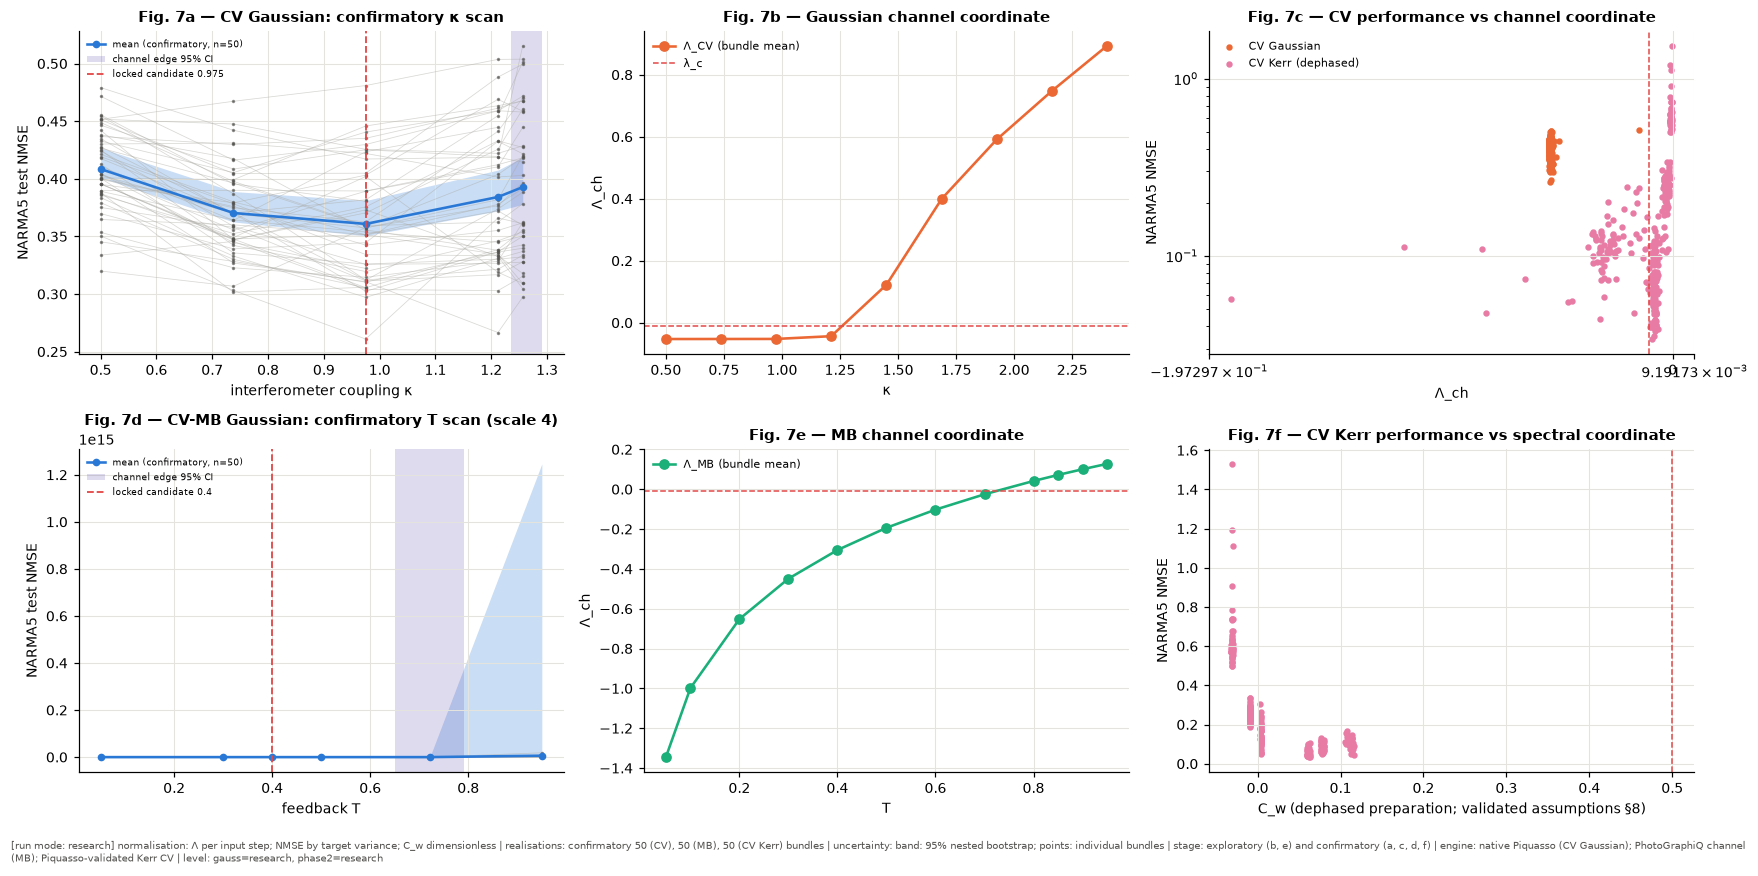

In [48]:
MB_SCALE = 4.0
CVG_BANKS = {"explore": Bank("cvg", "explore", phase_cfg("gauss", "n_explore")), "confirm": Bank("cvg", "confirm", phase_cfg("gauss", "n_confirm"))}
MBG_BANKS = {"explore": Bank("mbg", "explore", phase_cfg("gauss", "n_explore")), "confirm": Bank("mbg", "confirm", phase_cfg("gauss", "n_confirm"))}

def cvg_unit(kappa, bank, fixed):
    key = dict(engine="cvg", x=float(kappa), bank=bank.name, stage=bank.stage, n=bank.n, fixed=fixed, seq=CFG["seq"], N=CFG["cv_N"],
               ipc=(CFG["ipc_deg"], CFG["ipc_delay"], CFG["n_null"], CFG["refits"]), v=ENGINE_VERSIONS["cvg"])
    def compute():
        rows = []
        for r in bank.ids():
            nets = GaussianNetworkFactory(CFG["cv_N"], float(kappa), reject=False).draw_pair(seed_int("cvg-net", bank.stage, r))
            u = input_sequence(bank.name, bank.stage, r); lam = cv_lambda(nets, fixed["R"])
            out = NativePiquassoCVReservoir(CFG["cv_N"], fixed["R"], nets).run(2 * u - 1)
            ev = evaluate_features(out["features"], task_design(u, (bank.name, bank.stage, r))) if not out["diverged"] else dict(diverged=True)
            rows.append(dict(x=float(kappa), r=r, bank=bank.name, stage=bank.stage, Lambda=float(lam), stable_H=bool(nets[0]["stable"]), **summarize(ev)))
        return rows
    return STORE.cached("cvg-unit", key, compute)

def mbg_unit(T_, bank, fixed):
    key = dict(engine="mbg", x=float(T_), bank=bank.name, stage=bank.stage, n=bank.n, fixed=fixed, seq=CFG["seq"], N=CFG["mb_N"],
               ipc=(CFG["ipc_deg"], CFG["ipc_delay"], CFG["n_null"], CFG["refits"]), v=ENGINE_VERSIONS["mbg"])
    def compute():
        rows = []
        for r in bank.ids():
            rg = rng_for("mbg-enc", bank.stage, r); a_, b_ = fixed["scale"] * rg.uniform(-0.2, 0.2, CFG["mb_N"]), fixed["scale"] * rg.uniform(-0.2, 0.2, CFG["mb_N"])
            u = input_sequence(bank.name, bank.stage, r); res = MBQRC(make_cluster(CFG["mb_N"], "chain"), a_, b_, float(T_)); s = 2 * u - 1
            lam, _ = qr_lyapunov(list(res.matrices(s)[0])); X = res.run(s)
            ev = evaluate_features(X, task_design(u, (bank.name, bank.stage, r)))
            rows.append(dict(x=float(T_), r=r, bank=bank.name, stage=bank.stage, Lambda=float(lam), **summarize(ev)))
        return rows
    return STORE.cached("mbg-unit", key, compute)

with section("10.1 CV Gaussian H2 protocol"):
    k_ex = [float(k) for k in CFG["cv_kappa"]]
    CVG_EX = run_scan(cvg_unit, k_ex, CVG_BANKS["explore"], dict(R=0.9))
    EDGE_CVG = channel_edge(CVG_EX, k_ex)
    cand_k = float(CVG_EX[~CVG_EX.diverged].groupby("x")["NARMA5 NMSE"].mean().idxmin())
    lock_candidate("H2-CVG", candidate=cand_k, edge=[EDGE_CVG["value"], EDGE_CVG["lo"], EDGE_CVG["hi"]], explore_n=CVG_BANKS["explore"].n)
    kc, nb_k = confirm_grid(k_ex, cand_k, [EDGE_CVG["value"]])
    CVG_CF = run_scan(cvg_unit, kc, CVG_BANKS["confirm"], dict(R=0.9))
    evaluate_hypothesis("H2-CVG", CVG_CF, kc, LOCKS["H2-CVG"]["candidate"], EDGE_CVG, level=PHASE_LEVEL["gauss"], neighbours=nb_k,
                        edge_points=[EDGE_CVG["value"]] if np.isfinite(EDGE_CVG["value"]) else [])
with section("10.2 CV-MB Gaussian H2 protocol"):
    T_ex = [float(t) for t in CFG["mb_T"]]
    MBG_EX = run_scan(mbg_unit, T_ex, MBG_BANKS["explore"], dict(scale=MB_SCALE))
    EDGE_MBG = channel_edge(MBG_EX, T_ex)
    cand_T = float(MBG_EX[~MBG_EX.diverged].groupby("x")["NARMA5 NMSE"].mean().idxmin())
    lock_candidate("H2-MBG", candidate=cand_T, edge=[EDGE_MBG["value"], EDGE_MBG["lo"], EDGE_MBG["hi"]], explore_n=MBG_BANKS["explore"].n)
    Tc, nb_T = confirm_grid(T_ex, cand_T, [EDGE_MBG["value"]])
    MBG_CF = run_scan(mbg_unit, Tc, MBG_BANKS["confirm"], dict(scale=MB_SCALE))
    evaluate_hypothesis("H2-MBG", MBG_CF, Tc, LOCKS["H2-MBG"]["candidate"], EDGE_MBG, level=PHASE_LEVEL["gauss"], neighbours=nb_T,
                        edge_points=[EDGE_MBG["value"]] if np.isfinite(EDGE_MBG["value"]) else [])
print(f"CV Gaussian channel edge kappa = {EDGE_CVG['value']:.3g} [{EDGE_CVG['lo']:.3g}, {EDGE_CVG['hi']:.3g}]; divergent rows kept: {int(CVG_EX.diverged.sum() + CVG_CF.diverged.sum())}")
print(f"CV-MB Gaussian channel edge T = {EDGE_MBG['value']:.3g} [{EDGE_MBG['lo']:.3g}, {EDGE_MBG['hi']:.3g}] (scale {MB_SCALE})")
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(hyp_table(["H2-CVG", "H2-MBG"]))

fig, axs = plt.subplots(2, 3, figsize=(16, 7.6))
perf_plot(axs[0, 0], CVG_CF, kc, "Fig. 7a — CV Gaussian: confirmatory κ scan", "interferometer coupling κ", [(EDGE_CVG["lo"], EDGE_CVG["hi"], "channel edge 95% CI", COL["vio"])], cand_k, "confirmatory", log=False)
lm = CVG_EX.groupby("x").Lambda.mean(); axs[0, 1].plot(lm.index, lm.values, "o-", color=COL["cv"], label="Λ_CV (bundle mean)"); axs[0, 1].axhline(PREREG["lambda_c"], color=COL["red"], ls="--", lw=1, label="λ_c")
axs[0, 1].set(xlabel="κ", ylabel="Λ_ch", title="Fig. 7b — Gaussian channel coordinate"); axs[0, 1].legend(fontsize=7)
ok_ = ~CVG_CF.diverged; axs[0, 2].scatter(CVG_CF[ok_].Lambda, CVG_CF[ok_]["NARMA5 NMSE"], s=10, color=COL["cv"], label="CV Gaussian")
axs[0, 2].scatter(CV_CF.Lambda, CV_CF["NARMA5 NMSE"], s=10, color=COL["kerr"], label="CV Kerr (dephased)"); axs[0, 2].axvline(PREREG["lambda_c"], color=COL["red"], ls="--", lw=1)
axs[0, 2].set(xscale="symlog", xlabel="Λ_ch", ylabel="NARMA5 NMSE", yscale="log", title="Fig. 7c — CV performance vs channel coordinate"); axs[0, 2].legend(fontsize=7)
perf_plot(axs[1, 0], MBG_CF, Tc, f"Fig. 7d — CV-MB Gaussian: confirmatory T scan (scale {MB_SCALE:g})", "feedback T", [(EDGE_MBG["lo"], EDGE_MBG["hi"], "channel edge 95% CI", COL["vio"])], cand_T, "confirmatory", log=False)
lm = MBG_EX.groupby("x").Lambda.mean(); axs[1, 1].plot(lm.index, lm.values, "o-", color=COL["mb"], label="Λ_MB (bundle mean)"); axs[1, 1].axhline(PREREG["lambda_c"], color=COL["red"], ls="--", lw=1)
axs[1, 1].set(xlabel="T", ylabel="Λ_ch", title="Fig. 7e — MB channel coordinate"); axs[1, 1].legend(fontsize=7)
axs[1, 2].scatter(CV_CF.C_w, CV_CF["NARMA5 NMSE"], s=10, color=COL["kerr"]); axs[1, 2].axvline(0.5, color=COL["red"], ls="--", lw=1)
axs[1, 2].set(xlabel="C_w (dephased preparation; validated assumptions §8)", ylabel="NARMA5 NMSE", title="Fig. 7f — CV Kerr performance vs spectral coordinate")
figmeta(fig, normalisation="Λ per input step; NMSE by target variance; C_w dimensionless", realisations=f"confirmatory {CVG_BANKS['confirm'].n} (CV), {MBG_BANKS['confirm'].n} (MB), {CVK_BANKS['confirm'].n} (CV Kerr) bundles",
        uncertainty="band: 95% nested bootstrap; points: individual bundles", stage="exploratory (b, e) and confirmatory (a, c, d, f)",
        engine="native Piquasso (CV Gaussian); PhotoGraphiQ channel (MB); Piquasso-validated Kerr CV", level=f"gauss={PHASE_LEVEL['gauss']}, phase2={PHASE_LEVEL['phase2']}")
plt.tight_layout(); plt.show()
RESULTS["gauss"] = dict(cvg_explore=CVG_EX, cvg_confirm=CVG_CF, mbg_explore=MBG_EX, mbg_confirm=MBG_CF, edges=dict(cvg=EDGE_CVG, mbg=EDGE_MBG))

# 11. MBQC physical-model selection (Phase 5)
> **Established in literature.** CV cluster states with Gaussian measurements implement only Gaussian gates. Universality needs a non-Gaussian element: cubic-phase resource states, photon counting, or GKP resources [Menicucci *et al.* 2006; Gottesman–Kitaev–Preskill 2001]. Homodyne monitoring of a coupled meter mode is the standard CV measurement-based readout [García-Beni *et al.* 2023].
> **Adapted here.** Every candidate route is scored with **measured probes** where one exists. The decision rule is applied in code.
> **Proposed novel element.** The selected *ideal-logical-gate* MB reservoir (§11.3) and its trajectory analysis (§12).

## 11.1 Why the active cell of the previous version is not retained
The paper's MB-QRC cell $C_Z F D(u)$ contains two-mode squeezing. It is recomputed here in Piquasso's Fock simulator at two cutoffs, together with a Kerr layer. A unitarity defect of order one means that the truncated matrix is **not** a physical evolution, so its quasienergy statistics cannot be interpreted.

In [49]:
with section("11.1 active-cell truncation audit"):
    act = {}
    for c_ in (10, 16):
        B2 = [b for n in range(c_) for b in fock_basis(2, n)]; i2 = {b: i for i, b in enumerate(B2)}; M = np.zeros((len(B2), len(B2)), complex)
        for j, b in enumerate(B2):
            am = pq_fock_column(2, c_, b, [((0,), pq.QuadraticPhase(s=0.3)), ((1,), pq.QuadraticPhase(s=-0.2)), ((0,), pq.Fourier()), ((1,), pq.Fourier()),
                                          ((0, 1), pq.GaussianTransform(passive=np.array([[1, 0.5j], [0.5j, 1]]), active=np.array([[0, 0.5j], [0.5j, 0]]))),
                                          ((0,), pq.Kerr(xi=-0.25)), ((1,), pq.Kerr(xi=-0.25))])
            for kk, a in am.items():
                M[i2[tuple(int(x) for x in kk)], j] = a
        act[c_] = dict(D=len(B2), unitarity_defect=float(np.linalg.norm(M.conj().T @ M - np.eye(len(B2)), 2)))
    ACTIVE_DF = pd.DataFrame(act).T
display(ACTIVE_DF.round(4))
record_test("P11.active", "active teleportation cell (C_Z F D + Kerr) is NOT unitary under Fock truncation (order-one defect) -> not retained as a physical model",
            f"defects {ACTIVE_DF.unitarity_defect.round(3).tolist()} at cutoffs {list(act)}", ">= 0.1 (finding)", ACTIVE_DF.unitarity_defect.min() >= 0.1,
            critical=False, section_ref="11.1", category="physics")

[11.1 active-cell truncation audit] 3.1 s | peak host memory 1807 MB | GPU pool 748 MB


,D,unitarity_defect
10,55.0,0.9962
16,136.0,1.0000


PASS [P11.active] active teleportation cell (C_Z F D + Kerr) is NOT unitary under Fock truncation (order-one defect) -> not retained as a physical model: defects [0.996, 1.0] at cutoffs [10, 16] (criterion >= 0.1 (finding))


True

## 11.2 Feasibility audit of the non-Gaussian routes
Each route is scored 0–3 (0 unsupported … 3 fully supported) on eight criteria:
1. PhotoGraphiQ support;
2. Piquasso support;
3. physical interpretability;
4. numerical convergence;
5. recurrence;
6. finite squeezing;
7. conditional trajectories;
8. feasibility on the local hardware.

The measured probes are the following.
* **Route 1** (measurement-induced Kerr via PhotoGraphiQ's cubic-phase lowering): the compiler's own error estimate, and the norm retained by a cubic-phase resource at two cutoffs.
* **Route 2** (cubic-phase resource injection): Piquasso `CubicPhase` on vacuum, norm retained at two cutoffs.
* **Route 3** (finite-energy GKP): the cutoff needed for a GKP state with 10 dB of squeezing.
* **Route 4** (number-conserving Fock encoding): the passive Floquet cell of §6.8.5, exact in each fixed-$N$ sector.
* **Route 5** (ideal logical gates): exact Kerr and passive gates, with physical Gaussian meters.

**Decision rule (fixed before scoring).** Prefer a physical measurement-induced route if the *gate the model needs* converges; a converged resource state alone does not count. Otherwise, use an explicitly ideal logical-gate model; that choice is labelled, and no hardware-level MBQC reproduction is claimed. Keep route 4 only as a controlled comparison.

In [50]:
with section("11.2 route feasibility probes"):
    probes = {}
    with warnings.catch_warnings(record=True) as wl:
        warnings.simplefilter("always")
        try:
            pg.Circuit(1).kerr(0, 0.05).compile(squeezing=1.0, synthesis_steps=1); comp_msg = "compiles"
        except Exception as e:
            comp_msg = f"fails: {type(e).__name__}"
    probes["route1_compiler"] = comp_msg + "; " + ("; ".join({str(w.message)[:100] for w in wl if "approx" in str(w.message).lower()}) or "no warning")
    for gam in (0.1,):
        norms = {}
        for cut in (20, 40):
            with pq.Program() as prog:
                pq.Q() | pq.Vacuum(); pq.Q(0) | pq.Squeezing(r=0.5); pq.Q(0) | pq.CubicPhase(gamma=gam)
            st = pq.PureFockSimulator(d=1, config=pq.Config(cutoff=cut)).execute(prog).state; norms[cut] = float(np.sum(np.abs(np.asarray(st.state_vector)) ** 2))
        probes["route2_cubic_norm"] = norms
    n_gkp = int(math.ceil(1 / (2 * 10 ** (-10 / 10))))          # mean photon number ~ 1/(2 sigma^2) for a 10 dB GKP envelope
    probes["route3_gkp_mean_photons_10dB"] = n_gkp
    # convergence is scored at the GATE level: the model needs a Kerr-type nonlinearity. Cubic-phase resources (route 2) converge as
    # states, but a Kerr gate is reachable from them only through the commutator synthesis of route 1, whose error PhotoGraphiQ itself
    # reports as approximate; a converged resource state is therefore not a converged gate.
    gate1_converged = "approx" not in probes["route1_compiler"].lower() and "fails" not in probes["route1_compiler"]
    resource2_converged = min(probes["route2_cubic_norm"].values()) >= 1 - 1e-6
    probes["gate-level convergence"] = dict(route1=gate1_converged, route2_resource_state=resource2_converged, route2_kerr_gate=gate1_converged)
    ROUTES = pd.DataFrame([
        ("1 measurement-induced Kerr (cubic-phase gadgets)", 1, 2, 3, 2 if gate1_converged else 1, 1, 2, 1, 1),
        ("2 cubic-phase resource injection", 1, 2, 3, 2 if (resource2_converged and gate1_converged) else 1, 1, 2, 1, 1),
        ("3 finite-energy GKP / logical encoding", 1, 1, 3, 0, 1, 1, 0, 0),
        ("4 number-conserving Fock encoding (passive Floquet cell)", 2, 3, 2, 3, 3, 1, 2, 3),
        ("5 ideal logical Kerr gate + physical Gaussian meters (selected)", 2, 3, 2, 3, 3, 3, 3, 3),
    ], columns=["route", "PhotoGraphiQ", "Piquasso", "interpretability", "convergence", "recurrence", "finite squeezing", "trajectories", "local hardware"])
    ROUTES["total"] = ROUTES.iloc[:, 1:].sum(1)
    physical_ok = ROUTES.iloc[:2].convergence.max() >= 2
    SELECTED_ROUTE = ROUTES.iloc[int(np.argmax(ROUTES.iloc[:2].total))].route if physical_ok else ROUTES.iloc[4].route
display(ROUTES.set_index("route")); print("probes:", probes)
print("decision:", "a physical measurement-induced route converges" if physical_ok else "no physical measurement-induced route converges ->", SELECTED_ROUTE,
      "| route 4 kept only as a controlled comparison (§6.8.5)")

[11.2 route feasibility probes] 0.2 s | peak host memory 1807 MB | GPU pool 748 MB


C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\3145442488.py:32: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ROUTES["total"] = ROUTES.iloc[:, 1:].sum(1)


,PhotoGraphiQ,Piquasso,interpretability,convergence,recurrence,finite squeezing,trajectories,local hardware,total
route,,,,,,,,,
1 measurement-induced Kerr (cubic-phase gadgets),1,2,3,1,1,2,1,1,12
2 cubic-phase resource injection,1,2,3,1,1,2,1,1,12
3 finite-energy GKP / logical encoding,1,1,3,0,1,1,0,0,7
4 number-conserving Fock encoding (passive Floquet cell),2,3,2,3,3,1,2,3,19
5 ideal logical Kerr gate + physical Gaussian meters (selected),2,3,2,3,3,3,3,3,22


probes: {'route1_compiler': 'compiles; Kerr compilation is approximate: cubic commutator synthesis has leading amplitude error O(steps**-0.', 'route2_cubic_norm': {20: 0.9999999612753959, 40: 0.9999999999999948}, 'route3_gkp_mean_photons_10dB': 5, 'gate-level convergence': {'route1': False, 'route2_resource_state': True, 'route2_kerr_gate': False}}
decision: no physical measurement-induced route converges -> 5 ideal logical Kerr gate + physical Gaussian meters (selected) | route 4 kept only as a controlled comparison (§6.8.5)


## 11.3 The selected model: ideal-logical-gate CV MB reservoir with Kerr ("MBK")
**State and gates.**
* The reservoir has $L_r=3$ modes on an open chain, with the same disorder law as §3.1. It uses a per-mode Fock cutoff $c$ in a tensor-product space of dimension $d=c^{L_r}$.
* One input step applies the logical cell $U_{\rm cell}=U_{\rm Kerr}(\chi)\,\Gamma(W_\theta)$. $W_\theta$ is the PhotoGraphiQ-teleported hopping layer of §6.8.5 (validated), and $\Gamma(W_\theta)=e^{-iG}$ with $G=\sum_{pq}(i\log W_\theta)_{pq}a_p^\dagger a_q$ built from truncated ladder operators, which is exactly unitary on the truncated space. $U_{\rm Kerr}$ is the exact diagonal Kerr phase.

**Meters.**
* Then, sequentially for $i=0,1,2$, a fresh meter $b$ is prepared in $|m_i\rangle=D(\alpha_i)S(r_m)|0\rangle$. The input enters through $\alpha_0=\alpha_{\rm in}(2u_k-1)$; $\alpha_{1,2}=0$.
* The meter is coupled to reservoir mode $i$ by a beam splitter $e^{\vartheta(a_ib^\dagger-a_i^\dagger b)}$ with $\cos^2\vartheta=T_m$. $T_m$ is the reservoir amplitude that remains.
* The meter's $x$ quadrature is then read by homodyne detection with efficiency $\eta$.

**Instrument.** With $A_{j'}=\langle j'|_bB|m_i\rangle_b$ (operators on mode $i$) and $\psi_j(x)$ the Hermite functions (PhotoGraphiQ's `wavefunctions`, $\hbar=2$), the ideal Kraus operator is $K_x=\sum_{j'}\psi_{j'}(x)A_{j'}$.
* Efficiency $\eta$ smears the outcome. Outcomes are reported **calibrated to the incident quadrature**, PhotoGraphiQ's convention, which §11.4 verifies: $x=\hat x+\sqrt{(1-\eta)/\eta}\,\xi$, i.e. $\mathcal M_x(\rho)=\int dy\,\mathcal N(x;y,(1-\eta)/\eta)\,K_y\rho K_y^\dagger$.
* The unconditional channel is $\sum_{j'}A_{j'}\rho A_{j'}^\dagger$. It does not depend on $\eta$.

**Features (exact, unconditional; they are what an ensemble of runs measures).** The first and second moments of the three meter outcomes, $E[x_i]$ and $E[x_ix_j]$ ($i\le j$), plus the lag-1 cross moments $E[x_i^{(k)}x_j^{(k-1)}]$. That is 18 features per step. All of them follow from moment-weighted maps
$$\mathcal M^{(w)}_i(\sigma)=\sum_{a,b}w_{ba}A_a\sigma A_b^\dagger,\qquad w\in\{\mathbb 1,\hat x,\hat x^2\}$$
with finite-efficiency corrections for calibrated outcomes: $E[x]=E[\hat x]$, $E[x_ix_j]=E[\hat x_i\hat x_j]$ for $i\ne j$, $E[x^2]=E[\hat x^2]+(1-\eta)/\eta$.

**Implementation.** Each $\mathcal M^{(w)}_i$ is a $c^2\times c^2$ superoperator acting on the mode-$i$ row and column indices of $\rho$. It is precomputed (meters 1, 2) or assembled per step from the input-dependent meter state (meter 0). The batched contraction runs on the device of §2.4.

**Label:** *ideal logical Kerr gate + PhotoGraphiQ-compiled Gaussian layer + physical Gaussian meters (exact adapter validated against Piquasso and PhotoGraphiQ)*. This is not a hardware-level MBQC reproduction.

In [51]:
from photographiq.fock_measurements import wavefunctions as pg_wavefunctions

def trunc_ladder(c):
    return np.diag(np.sqrt(np.arange(1, c)), 1)

class MeterStates:
    """D(alpha) S(r)|0> truncated to cM levels. D(alpha) = V diag(exp(-i alpha mu)) V^dag from one eigendecomposition of i(a^dag - a)
    in cM + pad levels (validated against Piquasso Squeezing + Displacement in §11.4)."""

    def __init__(self, r, cM, pad=30):
        n = cM + pad; a = trunc_ladder(n); ad = a.T; self.cM = cM
        self.s = sla.expm(0.5 * r * (a @ a - ad @ ad))[:, 0]; mu, V = np.linalg.eigh(1j * (ad - a)); self.mu, self.V = mu, V; self.Vs = V.conj().T @ self.s

    def __call__(self, alpha, normalise=True):
        """Truncated (and, by default, renormalised) meter states; the discarded tail weight is stored in self.last_tail."""
        al = np.atleast_1d(np.asarray(alpha, float)); ph = np.exp(-1j * np.outer(al, self.mu)); v = ((ph * self.Vs[None]) @ self.V.T)[:, :self.cM]
        nrm = np.linalg.norm(v, axis=1, keepdims=True); self.last_tail = float(1 - (nrm ** 2).min())
        return v / nrm if normalise else v

def mode_superop_from_kraus(K):
    """(c, c, c, c) superoperator [n', m', n, m] of sum_k K_k . K_k^dag."""
    return np.einsum("kpn,kqm->pqnm", K, np.conj(K))

def loss_kraus(c, eta):
    K = np.zeros((c, c, c))
    for k in range(c):
        for n in range(k, c):
            K[k, n - k, n] = math.sqrt(math.comb(n, k) * eta ** (n - k) * (1 - eta) ** k)
    return K

def displacement_noise_superop(c, var, order=5, pad=30):
    """Random displacement channel int d2beta N(beta; var per quadrature) D(beta) . D(beta)^dag on one truncated mode (hbar = 2 units:
    var is the added variance of x and p), by a tensor Gauss-Hermite rule; D(beta) from exact exponentials in c + pad levels, truncated."""
    if var <= 0:
        return None
    n = c + pad; a = trunc_ladder(n); ad = a.T; z, w = np.polynomial.hermite_e.hermegauss(order); w = w / w.sum(); S = np.zeros((c, c, c, c), complex)
    for xi, wx in zip(z, w):
        for yi, wy in zip(z, w):
            beta = 0.5 * math.sqrt(var) * (xi + 1j * yi); Dm = sla.expm(beta * ad - np.conj(beta) * a)[:c, :c]
            S += wx * wy * np.einsum("pn,qm->pqnm", Dm, Dm.conj())
    return S

class MBKModel:
    """Ideal-logical-gate CV MB reservoir (§11.3). Batched over B input sequences; one disorder draw per model."""

    def __init__(self, eps, chi, Tm, *, L=3, c=5, cM=14, theta=1.0, r_m=0.5, alpha_in=0.6, eta=1.0, grid=64, xmax=8.0,
                 loss=0.0, disp_var=0.0, xpm=None):
        X_ = self.xp = xpm or xp
        self.L, self.c, self.cM, self.d = L, c, cM, c ** L
        self.chi, self.Tm, self.r_m, self.alpha_in, self.eta, self.loss, self.disp_var = chi, Tm, r_m, alpha_in, eta, loss, disp_var
        a = trunc_ladder(c); I = np.eye(c)
        def emb(op, i):
            out = np.array([[1.0]])
            for k in range(L):
                out = np.kron(out, op if k == i else I)
            return out
        Am = [emb(a, i) for i in range(L)]; self.nocc = np.stack([np.round(np.diag(Am[i].T @ Am[i]).real).astype(int) for i in range(L)], 1)
        kph = np.exp(-0.5j * chi * (self.nocc * (self.nocc - 1)).sum(1))[:, None]

        def cell_of(e):
            w = 1j * sla.logm(W_analytic(L, theta, e)); w = 0.5 * (w + w.conj().T)
            return kph * sla.expm(-1j * sum(w[p, q] * Am[p].T @ Am[q] for p in range(L) for q in range(L)))
        eps = np.asarray(eps, float)                       # (L,) one disorder draw, or (B, L) one draw per bundle (batched cells)
        self.U_cell_h = cell_of(eps) if eps.ndim == 1 else np.stack([cell_of(e) for e in eps]); self.U_cell = X_.asarray(self.U_cell_h)
        th = math.acos(math.sqrt(Tm)); b = trunc_ladder(cM); B2 = sla.expm(th * (np.kron(a, b.T) - np.kron(a.T, b)))
        self.Bt = B2.reshape(c, cM, c, cM).transpose(1, 3, 0, 2)                                          # Bt[j', j, n', n] = <n', j'| B |n, j>
        Xm = b + b.T; self.Wm = {"0": np.eye(cM), "1": Xm, "2": Xm @ Xm}
        self.meters = MeterStates(r_m, cM); m_const = self.meters(0.0)[0]; self.m_const = m_const
        self.P = {k: X_.asarray(np.einsum("ba,ajpn,bkqm->jkpqnm", wm, self.Bt, np.conj(self.Bt))) for k, wm in self.Wm.items()}
        self.S_const = {k: X_.einsum("j,k,jkpqnm->pqnm", X_.asarray(m_const), X_.asarray(np.conj(m_const)), self.P[k]) for k in self.P}
        self.A_const = np.einsum("ajpn,j->apn", self.Bt, m_const)
        self.E_const = {k: X_.asarray(np.einsum("ba,bpm,apn->mn", self.Wm[k], np.conj(self.A_const), self.A_const)) for k in ("1", "2")}
        self.Bt_d = X_.asarray(self.Bt); self.Wm_d = {k: X_.asarray(v) for k, v in self.Wm.items()}
        extra = None
        if loss > 0:
            extra = mode_superop_from_kraus(loss_kraus(c, 1 - loss))
        Sd = displacement_noise_superop(c, disp_var)
        if Sd is not None:
            extra = Sd if extra is None else np.einsum("pqab,abnm->pqnm", Sd, extra)
        self.S_extra = None if extra is None else X_.asarray(extra)
        self.xg = np.linspace(-xmax, xmax, grid); self.dx = float(self.xg[1] - self.xg[0])
        self.psi = np.stack([pg_wavefunctions(x, cM) for x in self.xg]); self.psi_d = X_.asarray(self.psi)          # (G, cM), hbar = 2

    # ---------------------------------------------------------------- mode-local operations on batched operators (B, d, d)
    def _t(self, rho):
        return rho.reshape((rho.shape[0],) + (self.c,) * (2 * self.L))

    def apply(self, S, rho, i):
        """S: (c,c,c,c) shared or (B,c,c,c,c) per batch element, acting on the mode-i row/column indices of rho (B, d, d)."""
        X_ = self.xp; B = rho.shape[0]; r = X_.moveaxis(self._t(rho), (1 + i, 1 + self.L + i), (-2, -1))
        out = X_.einsum("pqnm,...nm->...pq", S, r) if S.ndim == 4 else X_.einsum("bpqnm,b...nm->b...pq", S, r)
        return X_.moveaxis(out, (-2, -1), (1 + i, 1 + self.L + i)).reshape(B, self.d, self.d)

    def apply_vec(self, K, psi, i):
        """K: (c,c) or (B,c,c) operator on mode i applied to state vectors psi (B, d)."""
        X_ = self.xp; B = psi.shape[0]; r = X_.moveaxis(psi.reshape((B,) + (self.c,) * self.L), 1 + i, -1)
        out = X_.einsum("pn,...n->...p", K, r) if K.ndim == 2 else X_.einsum("bpn,b...n->b...p", K, r)
        return X_.moveaxis(out, -1, 1 + i).reshape(B, self.d)

    def reduced(self, rho, i):
        """Reduced density operator of mode i: (B, c, c)."""
        X_ = self.xp; L = self.L; let = "abcdefgh"[:L]
        rows = "".join("x" if k == i else let[k] for k in range(L)); cols = "".join("y" if k == i else let[k] for k in range(L))
        return X_.einsum(f"B{rows}{cols}->Bxy", self._t(rho))

    def trace_with(self, E, red):
        X_ = self.xp; return X_.real(X_.einsum("bmn,bnm->b", E, red)) if E.ndim == 3 else X_.real(X_.einsum("mn,bnm->b", E, red))

    def meter0(self, m0):
        """Superoperators (k = '0','1','2') and effects ('1','2') of meter 0 for a batch of meter states m0 (B, cM)."""
        X_ = self.xp; S = {k: X_.einsum("bj,bk,jkpqnm->bpqnm", m0, X_.conj(m0), self.P[k]) for k in self.P}
        A = X_.einsum("ajpn,bj->bapn", self.Bt_d, m0); E = {k: X_.einsum("ca,bcpm,bapn->bmn", self.Wm_d[k], X_.conj(A), A) for k in ("1", "2")}
        return S, E, A

    def cell(self, rho):
        X_ = self.xp; rho = self.U_cell @ rho @ X_.conj(X_.swapaxes(self.U_cell, -1, -2))
        if self.S_extra is not None:
            for i in range(self.L):
                rho = self.apply(self.S_extra, rho, i)
        return rho

    def m0_states(self, u):
        return self.meters(self.alpha_in * (2 * np.asarray(u, float).ravel() - 1)).reshape(np.shape(u) + (self.cM,))

    # ---------------------------------------------------------------- exact unconditional features and channel exponent
    def run(self, u, lag=True, T=None):
        """Production implementation: every operator that must be propagated (state, this step's x-weighted operators tau_i and the
        previous step's tau_j) is stacked into ONE batch Z of shape (1 + 2L, B, d, d), so each meter costs one reduced-state
        contraction and two superoperator applications. Validated against `_run_reference` (test N11.stack)."""
        X_ = self.xp; u = np.atleast_2d(u); B, T = u.shape[0], T or u.shape[1]; L, eta, d = self.L, self.eta, self.d
        m0_all = X_.asarray(self.m0_states(u[:, :T])); M = 1 + 2 * L
        Z = X_.zeros((M, B, d, d), dtype=complex); Z[0, :, 0, 0] = 1.0; U = self.U_cell; Ud = X_.conj(X_.swapaxes(U, -1, -2))
        nF = L + L * (L + 1) // 2 + (L * L if lag else 0); out = X_.zeros((B, T, nF)); have_prev = False
        tile = lambda S: X_.tile(S, (M, 1, 1, 1, 1)) if S.ndim == 5 else S
        for k in range(T):
            S0, E0, _ = self.meter0(m0_all[:, k]); Sd = [S0] + [self.S_const] * (L - 1); Ed = [E0] + [self.E_const] * (L - 1)
            Z = (U[None] @ Z @ Ud[None]) if U.ndim == 3 else (U @ Z @ Ud)
            if self.S_extra is not None:
                Zf = Z.reshape(M * B, d, d)
                for i in range(L):
                    Zf = self.apply(self.S_extra, Zf, i)
                Z = Zf.reshape(M, B, d, d)
            m1, m2, cross, lagv = [], [], {}, {}
            for i in range(L):
                red = self.reduced(Z.reshape(M * B, d, d), i).reshape(M, B, self.c, self.c); e1, e2 = Ed[i]["1"], Ed[i]["2"]
                tr1 = X_.real(X_.einsum("bmn,sbnm->sb", e1, red)) if e1.ndim == 3 else X_.real(X_.einsum("mn,sbnm->sb", e1, red))
                tr2 = X_.real(X_.einsum("bmn,bnm->b", e2, red[0])) if e2.ndim == 3 else X_.real(X_.einsum("mn,bnm->b", e2, red[0]))
                m1.append(tr1[0]); m2.append(tr2)
                for j in range(i):
                    cross[(j, i)] = tr1[1 + j]
                if have_prev:
                    for j in range(L):
                        lagv[(j, i)] = tr1[1 + L + j]
                tau_i = self.apply(Sd[i]["1"], Z[0], i)
                Z = self.apply(tile(Sd[i]["0"]), Z.reshape(M * B, d, d), i).reshape(M, B, d, d); Z[1 + i] = tau_i
            feats = list(m1) + [m2[i] + (1 - eta) / eta if i == j else cross[(i, j)] for i in range(L) for j in range(i, L)]
            if lag:
                feats += [lagv[(j, i)] if have_prev else X_.zeros(B) for j in range(L) for i in range(L)]
                Z[1 + L:] = Z[1:1 + L]; have_prev = True
            Z[1:1 + L] = 0
            out[:, k] = X_.stack(feats, 1)
        self.last_rho = Z[0]
        return to_host(out)

    def _run_reference(self, u, lag=True, T=None):
        """Straightforward per-operator implementation of the same features (kept only as the validation oracle for `run`)."""
        X_ = self.xp; u = np.atleast_2d(u); B, T = u.shape[0], T or u.shape[1]; L, eta = self.L, self.eta
        m0_all = X_.asarray(self.m0_states(u[:, :T])); rho = X_.zeros((B, self.d, self.d), dtype=complex); rho[:, 0, 0] = 1.0
        nF = L + L * (L + 1) // 2 + (L * L if lag else 0); out = X_.zeros((B, T, nF)); prev = None; zero = X_.zeros(B)
        for k in range(T):
            S0, E0, _ = self.meter0(m0_all[:, k]); Sd = [S0] + [self.S_const] * (L - 1); Ed = [E0] + [self.E_const] * (L - 1)
            rho = self.cell(rho); prev = [self.cell(t) for t in prev] if prev is not None else None
            m1, m2, tau, cross, lagv = [], [], [None] * L, {}, {}
            for i in range(L):
                red = self.reduced(rho, i); m1.append(self.trace_with(Ed[i]["1"], red)); m2.append(self.trace_with(Ed[i]["2"], red))
                for j in range(i):
                    cross[(j, i)] = self.trace_with(Ed[i]["1"], self.reduced(tau[j], i))
                if prev is not None:
                    for j in range(L):
                        lagv[(j, i)] = self.trace_with(Ed[i]["1"], self.reduced(prev[j], i))
                tau_i = self.apply(Sd[i]["1"], rho, i)
                tau = [self.apply(Sd[i]["0"], t, i) if t is not None else None for t in tau]; tau[i] = tau_i
                if prev is not None:
                    prev = [self.apply(Sd[i]["0"], t, i) for t in prev]
                rho = self.apply(Sd[i]["0"], rho, i)
            # calibrated outcomes (PhotoGraphiQ convention, validated in §11.4): x = x_hat + sqrt((1 - eta)/eta) xi
            feats = list(m1) + [m2[i] + (1 - eta) / eta if i == j else cross[(i, j)] for i in range(L) for j in range(i, L)]
            if lag:
                feats += [lagv[(j, i)] if prev is not None else zero for j in range(L) for i in range(L)]
            out[:, k] = X_.stack(feats, 1); prev = list(tau) if lag else None
        self.last_rho = rho
        return to_host(out)

    def channel_step(self, rho, m0):
        S0, _, _ = self.meter0(m0); rho = self.cell(rho)
        for i in range(self.L):
            rho = self.apply(S0["0"] if i == 0 else self.S_const["0"], rho, i)
        return rho

    def lyapunov(self, u, steps=None, seed=0):
        X_ = self.xp; u = np.atleast_2d(u); B = u.shape[0]; steps = steps or CFG["lyap_steps"]; burn = steps // 2
        m0_all = X_.asarray(self.m0_states(u[:, :steps])); rng = rng_for("mbk-benettin", seed)
        G = rng.normal(size=(B, self.d, self.d)) + 1j * rng.normal(size=(B, self.d, self.d)); p1 = G + np.conj(np.swapaxes(G, 1, 2))
        p1 -= np.trace(p1, axis1=1, axis2=2)[:, None, None] / self.d * np.eye(self.d); p2 = np.zeros((B, self.d, self.d), complex); p2[:, 0, 0], p2[:, -1, -1] = 1, -1
        probes = [X_.asarray(p / np.linalg.norm(p, axis=(1, 2))[:, None, None]) for p in (p1, p2)]; acc = X_.zeros((2, B))
        for k in range(steps):
            for q in range(2):
                probes[q] = detrace(self.channel_step(probes[q], m0_all[:, k])); nr = X_.sqrt(X_.sum(X_.abs(probes[q]) ** 2, axis=(1, 2))); probes[q] = probes[q] / nr[:, None, None]
                if k >= burn:
                    acc[q] += X_.log(nr)
        return to_host(acc.max(0) / (steps - burn))

    # ---------------------------------------------------------------- homodyne instrument on the grid (used by the trajectories of §12)
    def kraus_grid(self, A):
        """Ideal homodyne Kraus operators K_x = sum_j' psi_j'(x) A_j' on the grid: A (cM, c, c) -> (G, c, c); A (B, cM, c, c) -> (B, G, c, c)."""
        X_ = self.xp; return X_.einsum("gj,jpn->gpn", self.psi_d, A) if A.ndim == 3 else X_.einsum("gj,bjpn->bgpn", self.psi_d, A)

    def smear(self):
        """Inefficient-detection weights for CALIBRATED outcomes (PhotoGraphiQ convention): w[g_out, g_in] = N(x_out; y_in, (1-eta)/eta) dy."""
        if self.eta >= 1:
            return None
        x, y = self.xg[:, None], self.xg[None, :]; s2 = (1 - self.eta) / self.eta
        return self.xp.asarray(np.exp(-0.5 * (x - y) ** 2 / s2) / math.sqrt(2 * math.pi * s2) * self.dx)

## 11.4 Validation of the MBK engine against the native engines (tests 8.1)
| test | reference |
|---|---|
| meter state $D(\alpha)S(r)|0\rangle$ | Piquasso `Squeezing` + `Displacement` Fock amplitudes |
| beam-splitter matrix (inputs with $n+j\le c-1$, where truncation cannot act) | Piquasso `Beamsplitter` Fock columns (the angle convention is determined and recorded) |
| ideal conditional homodyne state, single mode | PhotoGraphiQ `piquasso-fock` backend with `measurement_outcomes` |
| inefficient conditional homodyne ($\eta=0.7$) | PhotoGraphiQ `piquasso-mixed-fock` backend (loss + ideal homodyne) |
| logical cell restricted to fixed-$N$ sectors that fit in the cutoff | exact $U_{\rm Kerr}\,\Gamma(W)$ of §6.8.5 (Perceval-validated) |
| CPTP: $\sum_{j'}A_{j'}^\dagger A_{j'}=\mathbb 1$; closed cell unitary; unconditional state trace 1, Hermitian, PSD; outcome distributions normalised on the grid | analytic |

In [52]:
with section("11.4 MBK validation against Piquasso and PhotoGraphiQ"):
    # (1) meter states vs Piquasso
    cMv = 14; msv = MeterStates(0.5, cMv); e_ms = 0.0
    for al in (0.0, 0.35, -0.6):
        with pq.Program() as prog:
            pq.Q() | pq.Vacuum(); pq.Q(0) | pq.Squeezing(r=0.5, phi=0.0); pq.Q(0) | pq.Displacement(r=abs(al), phi=0.0 if al >= 0 else np.pi)
        amp = pq.PureFockSimulator(d=1, config=pq.Config(cutoff=cMv + 30)).execute(prog).state.fock_amplitudes_map
        ref = np.array([amp.get((k,), 0.0) for k in range(cMv)]); ref = ref / np.linalg.norm(ref); e_ms = max(e_ms, np.abs(msv(al)[0] - ref).max())
    record_test("E11.meter", "meter states D(alpha)S(r)|0> = Piquasso Squeezing + Displacement amplitudes", e_ms, "< 1e-10", e_ms < 1e-10, section_ref="11.4", category="engine")
    # (2) beam-splitter convention vs Piquasso, on the truncation-free inputs n + j <= c - 1
    cv_, cMv2, Tv = 6, 8, 0.7; mv = MBKModel(np.zeros(1), 0.0, Tv, L=1, c=cv_, cM=cMv2, r_m=0.0, alpha_in=0.0)
    errs = {}
    for sgn in (+1, -1):
        e_ = 0.0
        for n in range(cv_):
            for j in range(cMv2):
                if n + j > cv_ - 1:
                    continue
                am = pq_fock_column(2, cv_ + cMv2, (n, j), [((0, 1), pq.Beamsplitter(theta=sgn * math.acos(math.sqrt(Tv)), phi=0.0))])
                for (n2, j2), a in am.items():
                    if n2 < cv_ and j2 < cMv2:
                        e_ = max(e_, abs(mv.Bt[j2, j, n2, n] - a))
        errs[sgn] = e_
    BS_SIGN = min(errs, key=errs.get)
    record_test("E11.bs", "meter beam splitter = Piquasso Beamsplitter Fock columns (truncation-free inputs; convention theta_pq = sign * theta)",
                f"sign {BS_SIGN:+d}: {errs[BS_SIGN]:.1e} (other sign {errs[-BS_SIGN]:.1e})", "< 1e-12", errs[BS_SIGN] < 1e-12, section_ref="11.4", category="engine")
    # (3) ideal conditional homodyne vs PhotoGraphiQ piquasso-fock (single reservoir mode + meter), large cutoffs
    cR, cMm = 16, 24; m1 = MBKModel(np.zeros(1), 0.0, 0.75, L=1, c=cR, cM=cMm, r_m=0.3, alpha_in=0.2, grid=64)
    psiR = np.zeros(cR, complex); psiR[:3] = [0.6, 0.64j, 0.48]; psiR /= np.linalg.norm(psiR); mstate = m1.meters(0.2)[0]
    A1 = np.einsum("ajpn,j->apn", m1.Bt, mstate); fid_ideal = []; pg_sign = {}
    for x0 in (-1.3, 0.4, 2.1):
        ours = sum(pg_wavefunctions(x0, cMm)[a] * (A1[a] @ psiR) for a in range(cMm)); ours /= np.linalg.norm(ours)
        best = 0.0
        for sgn in (+1, -1):
            pat = pg.Pattern(inputs=("R", "M")); pat.append(pg.BeamSplitter("R", "M", sgn * math.acos(math.sqrt(0.75)))); pat.measure("M", pg.Homodyne(0.0)); pat.append(pg.Output(("R",)))
            init = pg.FockSuperposition(tuple((n, j) for n in range(cR) for j in range(cMm)), tuple(complex(psiR[n] * mstate[j]) for n in range(cR) for j in range(cMm)))
            try:
                res = pg.simulate(pat.validate(), backend="piquasso-fock", cutoff=cR + cMm, initial_state=init, measurement_outcomes={"M": x0}, seed=0)
                sv = dict(zip([tuple(int(z) for z in b) for b in res.state.basis], res.state.state_vector)); ref = np.array([sv.get((n,), 0.0) for n in range(cR)])
                f = abs(np.vdot(ref, ours)) ** 2 / (np.vdot(ref, ref).real * np.vdot(ours, ours).real); pg_sign[sgn] = pg_sign.get(sgn, []) + [f]; best = max(best, f)
            except Exception as ex:                          # a failed native call is recorded, never silently skipped
                pg_sign[sgn] = pg_sign.get(sgn, []) + [np.nan]
        fid_ideal.append(best)
    record_test("E11.homodyne", "ideal conditional homodyne: adapter K_x state = native PhotoGraphiQ piquasso-fock conditional state (3 outcomes)",
                f"min fidelity {min(fid_ideal):.12f}; PhotoGraphiQ BS sign fidelities {({k: np.round(v, 6).tolist() for k, v in pg_sign.items()})}", "> 1 - 1e-9",
                min(fid_ideal) > 1 - 1e-9, section_ref="11.4", category="engine")
    # (4) inefficient homodyne (eta = 0.7) vs PhotoGraphiQ piquasso-mixed-fock
    # weakly populated input and meter (r = 0.1, alpha = 0.1, reservoir in span{|0>, |1>}) so that small cutoffs are exact for both codes;
    # the native mixed-Fock reference is computed once, the adapter on two grids (quadrature-grid convergence)
    fid_noisy = []; eta_v = 0.7; sg = max(pg_sign, key=lambda k: np.nanmean(pg_sign[k])); cRn, cMn = 8, 12; x0 = 0.4
    psiN = np.zeros(cRn, complex); psiN[:2] = [0.8, 0.6j]; mN = MeterStates(0.1, cMn)(0.1)[0]
    pat = pg.Pattern(inputs=("R", "M")); pat.append(pg.BeamSplitter("R", "M", sg * math.acos(math.sqrt(0.75)))); pat.measure("M", pg.Homodyne(0.0, efficiency=eta_v)); pat.append(pg.Output(("R",)))
    init = pg.FockSuperposition(tuple((n, j) for n in range(cRn) for j in range(cMn)), tuple(complex(psiN[n] * mN[j]) for n in range(cRn) for j in range(cMn)))
    try:
        res = pg.simulate(pat.validate(), backend="piquasso-mixed-fock", cutoff=cRn + cMn, initial_state=init, measurement_outcomes={"M": x0}, seed=0)
        dm = np.asarray(res.state.density_matrix); bas = [tuple(int(z) for z in b) for b in res.state.basis] if hasattr(res.state, "basis") else [(n,) for n in range(len(dm))]
        ref = np.zeros((cRn, cRn), complex); pos_ = {b[0]: i for i, b in enumerate(bas) if b[0] < cRn}
        for a_, ia in pos_.items():
            for b2, ib in pos_.items():
                ref[a_, b2] = dm[ia, ib]
        ref /= np.trace(ref)
    except Exception as ex:
        ref = None; print("mixed-fock native call failed:", type(ex).__name__, str(ex)[:120])
    for grid_n in (128, 256):
        m2 = MBKModel(np.zeros(1), 0.0, 0.75, L=1, c=cRn, cM=cMn, r_m=0.1, alpha_in=0.1, grid=grid_n, eta=eta_v, xmax=9.0)
        A2 = np.einsum("ajpn,j->apn", m2.Bt, mN); Kg = np.einsum("gj,jpn->gpn", m2.psi, A2)
        s2v = (1 - eta_v) / eta_v; wv = np.exp(-0.5 * (x0 - m2.xg) ** 2 / s2v) / math.sqrt(2 * math.pi * s2v) * m2.dx      # calibrated outcome convention
        ours = sum(w_ * K @ np.outer(psiN, psiN.conj()) @ K.conj().T for w_, K in zip(wv, Kg)); ours /= np.trace(ours)
        fid_noisy.append(0.5 * np.abs(np.linalg.eigvalsh(((ours - ref) + (ours - ref).conj().T) / 2)).sum() if ref is not None else np.nan)
    record_test("E11.noisy", "inefficient homodyne (eta=0.7): adapter smeared-POVM state = native PhotoGraphiQ mixed-Fock conditional state (trace distance, grid 128/256)",
                f"{np.round(fid_noisy, 7).tolist()}", "< 1e-4 at the finer grid", np.isfinite(fid_noisy[-1]) and fid_noisy[-1] < 1e-4, section_ref="11.4", category="engine")
    # (5) logical cell = exact Kerr x Gamma(W) on every fixed-N sector that fits inside the cutoff
    eps_t = disorder(3, W_BH, 0, "mbk", "validation"); mk = MBKModel(eps_t, 0.9, 0.8, L=3, c=5, cM=12); e_cell = 0.0
    for Ns in range(0, 5):
        Bs = sector(3, Ns); idx = [int(np.ravel_multi_index(b, (5, 5, 5))) for b in Bs]
        ref = kerr_phases(Bs, 0.9)[:, None] * fock_passive(W_analytic(3, 1.0, eps_t), Bs); e_cell = max(e_cell, np.abs(mk.U_cell_h[np.ix_(idx, idx)] - ref).max())
    record_test("E11.cell", "logical cell (truncated tensor space) = exact U_Kerr Gamma(W) on all fixed-N sectors with N <= c-1", e_cell, "< 1e-10", e_cell < 1e-10, section_ref="11.4", category="engine")
    # (6) CPTP, unitarity, normalisation
    tp = np.abs(np.einsum("apm,apn->mn", mk.A_const.conj(), mk.A_const) - np.eye(5)).max(); un = np.abs(mk.U_cell_h.conj().T @ mk.U_cell_h - np.eye(mk.d)).max()
    Xv = mk.run(input_sequence("mbk", "validation", 0, 60)[None], T=60); rv = to_host(mk.last_rho)[0]
    mass = float(np.sum([np.real(np.trace(K @ np.diag(np.ones(5) / 5) @ K.conj().T)) for K in np.einsum("gj,jpn->gpn", mk.psi, mk.A_const)]) * mk.dx)
    record_test("P11.cptp", "meter instrument trace preserving (sum A^dag A = 1) and closed logical cell unitary", f"TP {tp:.1e}, unitarity {un:.1e}", "< 1e-12",
                tp < 1e-12 and un < 1e-12, section_ref="11.4", category="physics")
    record_test("P11.state", "unconditional MBK state after 60 steps: trace 1, Hermitian, PSD",
                f"|Tr-1| {abs(np.trace(rv) - 1):.1e}, herm {np.abs(rv - rv.conj().T).max():.1e}, min eig {np.linalg.eigvalsh(rv).min():.1e}", "< 1e-10, < 1e-12, > -1e-10",
                abs(np.trace(rv) - 1) < 1e-10 and np.abs(rv - rv.conj().T).max() < 1e-12 and np.linalg.eigvalsh(rv).min() > -1e-10, section_ref="11.4", category="physics")
    record_test("P11.mass", "homodyne outcome distribution normalised on the grid (maximally mixed mode, grid 64, x in [-8, 8])", f"{mass:.8f}", "|mass - 1| < 1e-6",
                abs(mass - 1) < 1e-6, section_ref="11.4", category="physics")
    # (7) the stacked production run() = the straightforward reference implementation (features incl. lag moments; loss + noise on)
    eps2 = np.stack([disorder(3, W_BH, r, "mbk", "validation") for r in range(2)]); u2 = np.stack([input_sequence("mbk", "validation", r, 40) for r in range(2)])
    mks = MBKModel(eps2, 0.7, 0.8, L=3, c=4, cM=10, eta=0.7, loss=0.02, disp_var=0.01)
    e_stack = float(np.abs(mks.run(u2) - mks._run_reference(u2)).max())
    record_test("N11.stack", "stacked production MBK run() = straightforward reference implementation (40 steps, 2 bundles, eta<1, loss, displacement noise)",
                e_stack, "< 1e-10", e_stack < 1e-10, section_ref="11.4")
    # (8) Benettin channel exponent = ln|lambda_2| of the exact channel superoperator (constant input, c = 3), strong and weak meter coupling
    ly_rows = []
    for Tl in (0.5, 0.95):
        ml = MBKModel(disorder(3, W_BH, 0, "mbk", "validation"), 0.3, Tl, L=3, c=3, cM=CFG["mbk_meter_cut"]); m0l = ml.m0_states(np.array([[0.37]]))[:, 0]
        exact_l = channel_rate_exact(lambda E: ml.channel_step(xp.asarray(E), xp.asarray(np.repeat(m0l, len(E), 0))), ml.d)
        ly_rows.append((Tl, float(ml.lyapunov(np.full((1, 400), 0.37), steps=400)[0]), exact_l))
    record_test("P11.lyap", "MBK Benettin channel exponent = ln|lambda_2| of the exact channel superoperator (constant input, c=3, T_m = 0.5 and 0.95)",
                "; ".join(f"T_m={t_}: {b_:.4f} vs {e_:.4f}" for t_, b_, e_ in ly_rows), "|diff| < 0.01 + 3%",
                all(abs(b_ - e_) < 0.01 + 0.03 * abs(e_) for _, b_, e_ in ly_rows), section_ref="11.4", category="physics")
    mst =MeterStates(0.5, CFG["mbk_meter_cut"]); _ = mst(np.linspace(-0.6, 0.6, 25)); tail_prod = mst.last_tail
    record_test("N11.metertail", "meter-state truncation at the production cutoff: discarded tail weight (renormalised; convergence monitor)", tail_prod, "< 1e-4",
                tail_prod < 1e-4, section_ref="11.4")
_log_device("MBK unconditional channel, features, Benettin and trajectories", "gpu" if ON_GPU else "cpu", "batched superoperator contractions (validated above)")
stop_on_failures("E11"); stop_on_failures("P11")

PASS [E11.meter] meter states D(alpha)S(r)|0> = Piquasso Squeezing + Displacement amplitudes: 7.03e-16 (criterion < 1e-10)
PASS [E11.bs] meter beam splitter = Piquasso Beamsplitter Fock columns (truncation-free inputs; convention theta_pq = sign * theta): sign +1: 5.6e-16 (other sign 1.3e+00) (criterion < 1e-12)


PASS [E11.homodyne] ideal conditional homodyne: adapter K_x state = native PhotoGraphiQ piquasso-fock conditional state (3 outcomes): min fidelity 1.000000000000; PhotoGraphiQ BS sign fidelities {1: [1.0, 1.0, 1.0], -1: [0.020303, 0.905684, 0.04946]} (criterion > 1 - 1e-9)


PASS [E11.noisy] inefficient homodyne (eta=0.7): adapter smeared-POVM state = native PhotoGraphiQ mixed-Fock conditional state (trace distance, grid 128/256): [3e-07, 3e-07] (criterion < 1e-4 at the finer grid)
PASS [E11.cell] logical cell (truncated tensor space) = exact U_Kerr Gamma(W) on all fixed-N sectors with N <= c-1: 7.22e-16 (criterion < 1e-10)


PASS [P11.cptp] meter instrument trace preserving (sum A^dag A = 1) and closed logical cell unitary: TP 5.6e-16, unitarity 1.1e-15 (criterion < 1e-12)
PASS [P11.state] unconditional MBK state after 60 steps: trace 1, Hermitian, PSD: |Tr-1| 2.7e-14, herm 1.6e-17, min eig 2.1e-08 (criterion < 1e-10, < 1e-12, > -1e-10)
PASS [P11.mass] homodyne outcome distribution normalised on the grid (maximally mixed mode, grid 64, x in [-8, 8]): 0.99999998 (criterion |mass - 1| < 1e-6)


PASS [N11.stack] stacked production MBK run() = straightforward reference implementation (40 steps, 2 bundles, eta<1, loss, displacement noise): 8.88e-16 (criterion < 1e-10)


PASS [P11.lyap] MBK Benettin channel exponent = ln|lambda_2| of the exact channel superoperator (constant input, c=3, T_m = 0.5 and 0.95): T_m=0.5: -0.3701 vs -0.3701; T_m=0.95: -0.0538 vs -0.0538 (criterion |diff| < 0.01 + 3%)
PASS [N11.metertail] meter-state truncation at the production cutoff: discarded tail weight (renormalised; convergence monitor): 1.05e-06 (criterion < 1e-4)
[11.4 MBK validation against Piquasso and PhotoGraphiQ] 54.8 s | peak host memory 2856 MB | GPU pool 2476 MB


# 12. Conditional trajectory implementation (Phase 4)
The two coupling protocols of §3.4, the purification and entanglement diagnostics, and the record information are implemented in two settings:
1. **§12.1, Gaussian MB-QRC** (PhotoGraphiQ channel, §6.8.4). The tap $x$-quadratures are read with efficiency $\eta$, and the reservoir is conditioned on the record by the exact Gaussian (Kalman) update of §3.4. The closed-form results derived there are verified numerically: common innovations reproduce $\Lambda_{\rm ch}$, and the common record follows the closed-loop matrices $F_k=X_C-KX_V$.
2. **§12.2, MBK** (§11.3), the non-Gaussian model. Its density-matrix trajectories are sampled on the homodyne grid with shared innovations.

**What is conditional and what is not.** Every feature used for a *task* in §7–§10 is an unconditional ensemble quantity. The trajectory exponents, conditional purities and record MI are **conditional** quantities, and they are never mixed with the unconditional channel.

## 12.1 Gaussian MB-QRC trajectories
* **Conditioning (per step).**
  * The joint pre-measurement moments are $M=X\mathbf R$ and $G=X\Gamma X^T+Y$, with $X=[X_C;X_V]$ and the full PhotoGraphiQ noise $Y$, including its reservoir–tap cross block.
  * The tap-$x$ record is $\tilde y=M_V+L\xi$, with $LL^T=G_{VV}+\sigma^2\mathbb 1$ and $\sigma^2=(1-\eta)/\eta$.
  * The update is $\mathbf R'=M_C+K(\tilde y-M_V)$ and $\Gamma'=G_{CC}-KG_{VC}$.
* **Distance.** For equal covariances (always the case here, see §3.4), $D=\sqrt{1-\exp(-\tfrac14\boldsymbol\delta^T\Gamma^{-1}\boldsymbol\delta)}$.
* **Purity and entropy.** Purity is $\mu=1/\sqrt{\det\Gamma}$ ($\hbar=2$). The entropy is computed from the symplectic eigenvalues $\nu_k$, and the logarithmic negativity from the partially transposed spectrum (first half of the chain vs. second half).

In [53]:
def symplectic_eigs(G):
    n = len(G) // 2; return np.sort(np.abs(np.linalg.eigvals(1j * omega_xpxp(n) @ G)))[::2]

def gauss_entropy(G):
    nu = np.clip(symplectic_eigs(G), 1 + 1e-12, None); a, b = (nu + 1) / 2, (nu - 1) / 2
    return float(np.sum(a * np.log(a) - b * np.log(b)))

def gauss_log_negativity(G, subsys):
    n = len(G) // 2; Pt = np.eye(2 * n)
    for i in subsys:
        Pt[2 * i + 1, 2 * i + 1] = -1
    return float(np.sum(np.clip(-np.log2(symplectic_eigs(Pt @ G @ Pt)), 0, None)))

def mbg_full_noise(res):
    """Full PhotoGraphiQ noise matrix of one MB-QRC step (ideal-squeezing extrapolation, as MBQRC uses) and the x-rows of the taps."""
    Y = ideal_noise(res.cluster, res.T) if res.ideal else pg.gaussian_channel(step_pattern(res.cluster, res.beta, res.T, res.r_pg)).noise
    n = 2 * res.N; xr = 2 * res.N + 2 * np.arange(res.N); return Y[:n, :n], Y[np.ix_(np.arange(n), xr)], Y[np.ix_(xr, xr)]

def gauss_trajectories(res, s, eta, K, n_traj, rng, d0=1e-3):
    """Kalman trajectories of the Gaussian MB-QRC. Returns lambda (common innovation), lambda (common record), QR exponents of X_C and of
    the closed-loop F_k, conditional/unconditional purity, entropy and log-negativity series, and the tap record of the reference trajectories."""
    YCC, YCV, YVV = mbg_full_noise(res); N = res.N; sig2 = (1 - eta) / eta if eta < 1 else 0.0
    XC, XV = res.matrices(s[:K]); Gam = np.eye(2 * N); Gu = np.eye(2 * N)
    R0 = np.zeros((n_traj, 2 * N)); dR = rng.normal(size=(n_traj, 2 * N)); dR *= d0 / np.linalg.norm(dR, axis=1, keepdims=True)
    Ra, Rb = R0.copy(), R0 + dR; Rc = R0.copy(); Rd = R0 + dR                                  # a,b: common innovation; c (reference) -> record; c,d: common record
    Fs, Xs, g_in, g_rec, pur, S_c, S_u, EN, rec = [], [], [], [], [], [], [], [], []; diverged = False
    mah = lambda D_, Gi_: np.sqrt(np.einsum("pi,ij,pj->p", D_, Gi_, D_))
    for k in range(K):
        A, V_ = XC[k], XV[k]; Gi_old = np.linalg.inv(Gam)
        n_in0, n_rec0 = mah(Rb - Ra, Gi_old), mah(Rd - Rc, Gi_old)
        GCC = A @ Gam @ A.T + YCC; GCV = A @ Gam @ V_.T + YCV; GVV = V_ @ Gam @ V_.T + YVV + sig2 * np.eye(N)
        Kg = GCV @ np.linalg.inv(GVV); Lc = np.linalg.cholesky(GVV); xi = rng.standard_normal((n_traj, N))
        MVa, MVb, MVc, MVd = Ra @ V_.T, Rb @ V_.T, Rc @ V_.T, Rd @ V_.T
        ya, yb = MVa + xi @ Lc.T, MVb + xi @ Lc.T; yc = MVc + xi @ Lc.T
        Ra = Ra @ A.T + (ya - MVa) @ Kg.T; Rb = Rb @ A.T + (yb - MVb) @ Kg.T; Rc = Rc @ A.T + (yc - MVc) @ Kg.T; Rd = Rd @ A.T + (yc - MVd) @ Kg.T
        Gam = GCC - Kg @ GCV.T; Gam = 0.5 * (Gam + Gam.T); Gi = np.linalg.inv(Gam); Fs.append(A - Kg @ V_); Xs.append(A)
        # the mean difference evolves linearly (equal covariances): renormalise it every step and accumulate its log growth
        # in the Mahalanobis metric (small-separation limit of the Gaussian fidelity distance, §3.4) -- exact, no underflow
        n_in1, n_rec1 = mah(Rb - Ra, Gi), mah(Rd - Rc, Gi); g_in.append(np.log(n_in1 / n_in0)); g_rec.append(np.log(n_rec1 / n_rec0))
        Rb = Ra + (Rb - Ra) * (d0 / n_in1)[:, None]; Rd = Rc + (Rd - Rc) * (d0 / n_rec1)[:, None]; rec.append(yc)
        sd = np.linalg.slogdet(Gam)[1]; pur.append(math.exp(-0.5 * sd)); S_c.append(gauss_entropy(Gam)); EN.append(gauss_log_negativity(Gam, range(N // 2)))
        if not diverged:
            Gu = A @ Gu @ A.T + YCC
            if not np.isfinite(Gu).all() or np.abs(Gu).max() > 1e12:
                diverged = True
        S_u.append(gauss_entropy(Gu) if not diverged else np.nan)
    burn = K // 4; lam = lambda G_: float(np.mean(np.array(G_)[burn:]))
    return dict(lam_innov=lam(g_in), lam_rec=lam(g_rec), qr_XC=qr_lyapunov(Xs)[0], qr_F=qr_lyapunov(Fs)[0], purity=np.array(pur), S_cond=np.array(S_c),
                S_uncond=np.array(S_u), logneg=np.array(EN), purity_uncond=(math.exp(-0.5 * np.linalg.slogdet(Gu)[1]) if not diverged else np.nan),
                uncond_diverged=diverged, record=np.array(rec))

with section("12.1 Gaussian MB-QRC trajectories"):
    rg = rng_for("mbg-traj-enc"); a_t, b_t = MB_SCALE * rg.uniform(-0.2, 0.2, CFG["mb_N"]), MB_SCALE * rg.uniform(-0.2, 0.2, CFG["mb_N"])
    u_tr = input_sequence("mbg-traj", "explore", 0); s_tr = 2 * u_tr - 1; K_g = phase_cfg("phase4", "mbg_traj_steps")
    res_t = MBQRC(make_cluster(CFG["mb_N"], "chain"), a_t, b_t, 0.3)            # a contractive point (T below the channel edge)
    gt = gauss_trajectories(res_t, s_tr, 0.8, K_g, 16, rng_for("mbg-traj", 0))
    record_test("P12.innov", "Gaussian trajectories: common-innovation exponent = unconditional channel exponent Lambda_ch (derived identity)",
                f"{gt['lam_innov']:.5f} vs QR(X_C) {gt['qr_XC']:.5f}", "|diff| < 0.01 + 3% ", abs(gt["lam_innov"] - gt["qr_XC"]) < 0.01 + 0.03 * abs(gt["qr_XC"]),
                section_ref="12.1", category="physics")
    record_test("P12.record", "Gaussian trajectories: common-record exponent = QR exponent of the closed-loop filter F_k = X_C - K X_V (derived identity)",
                f"{gt['lam_rec']:.5f} vs QR(F) {gt['qr_F']:.5f}", "|diff| < 0.01 + 3%", abs(gt["lam_rec"] - gt["qr_F"]) < 0.01 + 0.03 * abs(gt["qr_F"]),
                section_ref="12.1", category="physics")
    # 2D map over (T, eta): Lambda_ch (eta independent) and lambda_rec (closed-loop QR, exact; per encoding bundle)
    T_map, eta_map = [float(t) for t in phase_cfg("phase4", "mbg_T")], [float(e) for e in phase_cfg("phase4", "mbg_eta")]; nb_map = min(4, phase_cfg("phase4", "n_explore"))
    MBG_MAP = []
    for T_ in T_map:
        for r in range(nb_map):
            rg = rng_for("mbg-enc", "explore", r); a_, b_ = MB_SCALE * rg.uniform(-0.2, 0.2, CFG["mb_N"]), MB_SCALE * rg.uniform(-0.2, 0.2, CFG["mb_N"])
            res_ = MBQRC(make_cluster(CFG["mb_N"], "chain"), a_, b_, T_); s_ = 2 * input_sequence("mbg", "explore", r) - 1
            lam_ch = qr_lyapunov(list(res_.matrices(s_[:K_g])[0]))[0]
            for eta in eta_map:
                g_ = gauss_trajectories(res_, s_, eta, K_g, 4, rng_for("mbg-map", T_, eta, r))
                MBG_MAP.append(dict(T=T_, eta=eta, r=r, Lambda_ch=lam_ch, lambda_rec=g_["qr_F"], lambda_rec_mc=g_["lam_rec"], purity=float(g_["purity"][-50:].mean()),
                                    S_cond=float(g_["S_cond"][-50:].mean()), S_uncond=float(g_["S_uncond"][-50:].mean()), logneg=float(g_["logneg"][-50:].mean()),
                                    purity_uncond=g_["purity_uncond"]))
    MBG_MAP = pd.DataFrame(MBG_MAP)
    mm = MBG_MAP.groupby(["T", "eta"]).mean(numeric_only=True).reset_index()
    T_ch = level_crossing(T_map, mm[mm.eta == eta_map[0]].groupby("T").Lambda_ch.mean().values, PREREG["lambda_c"], "up")
    T_tr = {eta: level_crossing(T_map, mm[mm.eta == eta].sort_values("T").lambda_rec.values, PREREG["lambda_c"], "up") for eta in eta_map}
display(mm.round(4))
print(f"Gaussian MB channel edge T_ch = {T_ch:.3g}; common-record trajectory edge T_traj(eta) = {({k: round(v, 3) for k, v in T_tr.items()})}")

PASS [P12.innov] Gaussian trajectories: common-innovation exponent = unconditional channel exponent Lambda_ch (derived identity): -0.11030 vs QR(X_C) -0.11452 (criterion |diff| < 0.01 + 3% )
PASS [P12.record] Gaussian trajectories: common-record exponent = QR exponent of the closed-loop filter F_k = X_C - K X_V (derived identity): -0.66269 vs QR(F) -0.66298 (criterion |diff| < 0.01 + 3%)


C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\2587666783.py:39: RuntimeWarning: invalid value encountered in divide
  n_in1, n_rec1 = mah(Rb - Ra, Gi), mah(Rd - Rc, Gi); g_in.append(np.log(n_in1 / n_in0)); g_rec.append(np.log(n_rec1 / n_rec0))
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\2587666783.py:40: RuntimeWarning: divide by zero encountered in divide
  Rb = Ra + (Rb - Ra) * (d0 / n_in1)[:, None]; Rd = Rc + (Rd - Rc) * (d0 / n_rec1)[:, None]; rec.append(yc)
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\2587666783.py:40: RuntimeWarning: invalid value encountered in multiply
  Rb = Ra + (Rb - Ra) * (d0 / n_in1)[:, None]; Rd = Rc + (Rd - Rc) * (d0 / n_rec1)[:, None]; rec.append(yc)
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_11112\2587666783.py:39: RuntimeWarning: divide by zero encountered in log
  n_in1, n_rec1 = mah(Rb - Ra, Gi), mah(Rd - Rc, Gi); g_in.append(np.log(n_in1 / n_in0)); g_rec.append(np.log(n_rec1 / n_re

[12.1 Gaussian MB-QRC trajectories] 32.4 s | peak host memory 2856 MB | GPU pool 2476 MB


,T,eta,r,Lambda_ch,lambda_rec,lambda_rec_mc,purity,S_cond,S_uncond,logneg,purity_uncond
0,0.100,0.05,1.5,-0.9167,-1.0241,-1.0219,0.6213,0.9430,1.0064,0.0646,0.5957
1,0.100,0.20,1.5,-0.9167,-1.1667,-1.1665,0.6889,0.7767,1.0064,0.0718,0.5957
2,0.100,0.50,1.5,-0.9167,-1.1935,-1.1929,0.8086,0.4951,1.0064,0.0896,0.5957
3,0.100,1.00,1.5,-0.9167,-1.1907,-1.1842,1.0000,0.0000,1.0064,0.1378,0.5957
4,0.194,0.05,1.5,-0.5854,-0.7068,-0.7055,0.4345,1.4741,1.5962,0.1216,0.3967
5,0.194,0.20,1.5,-0.5854,-0.8354,-0.8347,0.5295,1.1927,1.5962,0.1362,0.3967
6,0.194,0.50,1.5,-0.5854,-0.8593,-0.8593,0.6982,0.7586,1.5962,0.1697,0.3967
7,0.194,1.00,1.5,-0.5854,-0.8531,-0.8490,1.0000,0.0000,1.5962,0.2564,0.3967
8,0.289,0.05,1.5,-0.3861,-0.5252,-0.5241,0.3149,1.9106,2.1270,0.1771,0.2668
9,0.289,0.20,1.5,-0.3861,-0.6354,-0.6349,0.4252,1.5121,2.1270,0.2007,0.2668


Gaussian MB channel edge T_ch = 0.613; common-record trajectory edge T_traj(eta) = {0.05: nan, 0.2: nan, 0.5: nan, 1.0: nan}


## 12.2 MBK conditional trajectories
**Sampling.** Density-matrix trajectories $\rho^{(p)}$ are stored as a batch on the device. For each step and each meter $i$:
1. $q_p(y)=\mathrm{Tr}(K_y\rho_{p,i}K_y^\dagger)$ is computed on the grid from the reduced state of mode $i$.
2. The outcome density is $p_p(x)=\sum_y w(x,y)q_p(y)$, smeared for $\eta<1$.
3. A shared uniform innovation $v$ selects a bin through each trajectory's own CDF.
4. The state is updated by the instrument element of that bin and renormalised.

**The two protocols.**
* **Common innovation.** Each pair $(a,b)$ starts from a burned-in state $\rho_a$ and $\rho_b=(1-d_0)\rho_a+d_0\sigma$, with $\sigma$ a random state; this keeps $\rho_b$ positive. The two use the same $v$.
* **Common record.** A reference trajectory generates the bins. Two candidates, $\mathbb 1/d$ and a random pure state, are conditioned on that same record, and their record likelihoods are tracked. A likelihood below $10^{-300}$ flags numerically impossible conditioning.

**Estimator.** $\lambda$ is the slope of $\log D$ (trace distance, evaluated every `dist_every` steps) against $k$. It is fitted per pair up to the first time $D<10^{-12}$, then averaged; the uncertainty is the standard error over pairs. Because trace distance cannot exceed 1, $\lambda\le0$ asymptotically. A value near 0 means that the initial difference is **not** forgotten (no synchronisation or filter stability) on the observed time scale.

In [54]:
def mbk_trajectories(model, u, M, K, protocol, rng, d0=1e-2, burn=30, dist_every=5, floor=1e-300, keep_record=False, ent_every=None):
    X_ = model.xp; d, L = model.d, model.L; G = len(model.xg); smear = model.smear()
    m0_all = X_.asarray(model.m0_states(u[:burn + K]))
    def rand_state(pure):
        v = rng.normal(size=(M, d)) + 1j * rng.normal(size=(M, d))
        if pure:
            v /= np.linalg.norm(v, axis=1, keepdims=True); return np.einsum("pi,pj->pij", v, v.conj())
        A = rng.normal(size=(M, d, d)) + 1j * rng.normal(size=(M, d, d)); W = A @ np.conj(np.swapaxes(A, 1, 2)); return W / np.trace(W, axis1=1, axis2=2)[:, None, None]
    vac = np.zeros((M, d, d), complex); vac[:, 0, 0] = 1.0
    def step(rho, k, shared_bins=None, v=None):
        rho = model.cell(rho); bins_all, lik_all = [], []
        for i in range(L):
            A = model.meter0(m0_all[k:k + 1])[2][0] if i == 0 else X_.asarray(model.A_const)
            Kg = model.kraus_grid(A); red = model.reduced(rho, i)
            q = X_.real(X_.einsum("gpn,Pnm,gpm->Pg", Kg, red, X_.conj(Kg))); pout = q @ smear.T if smear is not None else q
            pb = X_.clip(pout, 0, None); pb = pb / pb.sum(1, keepdims=True)
            if shared_bins is None:
                vv = X_.asarray(v[:, i]); bins = X_.minimum((X_.cumsum(pb, 1) < vv[:, None]).sum(1), G - 1)
            else:
                bins = shared_bins[i]
            lik = pout[X_.arange(rho.shape[0]), bins] / (pout.sum(1) * model.dx); lik_all.append(lik); bins_all.append(bins)
            w = smear[bins] if smear is not None else X_.eye(G)[bins]
            S = X_.einsum("Py,ypn,yqm->Ppqnm", w, Kg, X_.conj(Kg)); rho = model.apply(S, rho, i)
            rho = rho / X_.real(X_.trace(rho, axis1=1, axis2=2))[:, None, None]
        return rho, bins_all, lik_all
    ref = X_.asarray(vac)
    for k in range(burn):                                    # burn-in of the reference / first member
        ref, _, _ = step(ref, k, v=rng.random((M, L)))
    if protocol == "innov":
        a = ref; b = (1 - d0) * ref + d0 * X_.asarray(rand_state(False)); pairs = (a, b)
    else:
        c1 = X_.asarray(np.broadcast_to(np.eye(d, dtype=complex) / d, (M, d, d)).copy()); c2 = X_.asarray(rand_state(True)); pairs = (c1, c2)
    logD, pur, rec, n_flag, ent = [], [], [], 0, []
    for k in range(burn, burn + K):
        if protocol == "innov":
            v = rng.random((M, L)); st = X_.concatenate(pairs, 0); vv = np.concatenate([v, v], 0)
            st, bins, lik = step(st, k, v=vv); pairs = (st[:M], st[M:])
        else:
            ref, bins, _ = step(ref, k, v=rng.random((M, L))); st = X_.concatenate(pairs, 0)
            st, _, lik = step(st, k, shared_bins=[X_.concatenate([b_, b_]) for b_ in bins]); pairs = (st[:M], st[M:])
            n_flag += int(sum(int((l_ < floor).sum()) for l_ in lik))
            if keep_record:
                rec.append(np.stack([model.xg[to_host(b_)] + (rng.random(M) - 0.5) * model.dx for b_ in bins], 1))
        pur.append(to_host(X_.real(X_.sum(X_.abs(pairs[0]) ** 2, axis=(1, 2)))))
        if (k - burn) % dist_every == 0:
            logD.append(np.log(np.clip(to_host(trace_distance_batch(pairs[0], pairs[1])), 1e-300, None)))
        if ent_every and (k - burn) % ent_every == 0:
            ent.append(mbk_entanglement(model, pairs[0]))
    logD = np.array(logD); kk = np.arange(len(logD)) * dist_every; slopes = []
    for j in range(M):
        s_, _ = fit_log_slope(np.exp(logD[:, j]), floor=1e-12); slopes.append(s_ / dist_every if np.isfinite(s_) else np.nan)
    slopes = np.array(slopes, float) * 1.0
    out = dict(lam=float(np.nanmean(slopes)), lam_se=float(np.nanstd(slopes, ddof=1) / math.sqrt(max(np.isfinite(slopes).sum(), 1))), frac_floor=float((logD[-1] < np.log(1e-12)).mean()),
               logD_mean=logD.mean(1), purity=np.array(pur), impossible=n_flag)
    if keep_record:
        out["record"] = np.array(rec)
    if ent:
        out["entanglement"] = np.array(ent)
    return out

def mbk_entanglement(model, rho):
    """Log-negativity (mode 0 | modes 1..L-1) of a batch of conditional states (host)."""
    X_ = model.xp; c, L, M = model.c, model.L, rho.shape[0]; r = rho.reshape((M,) + (c,) * (2 * L))
    rt = X_.swapaxes(r, 1, 1 + L).reshape(M, model.d, model.d)                   # partial transpose on mode 0
    ev = X_.linalg.eigvalsh(0.5 * (rt + X_.conj(X_.swapaxes(rt, 1, 2))))
    return to_host(X_.log2(X_.abs(ev).sum(1)))

def mbk_setup(chi, Tm, eta, bank="mbk", stage="explore", r=0, c=None, cM=None, grid=None, **kw):
    c = c or CFG["mbk_cut"][0]; cM = cM or CFG["mbk_meter_cut"]; grid = grid or CFG["mbk_grid"]
    return MBKModel(disorder(CFG["mbk_L"], W_BH, r, bank, stage), chi, Tm, L=CFG["mbk_L"], c=c, cM=cM, eta=eta, grid=grid, **kw)

with section("12.2 MBK trajectories: protocols, purification, information"):
    chi_ref, T_ref = float(np.median(CFG["mbk_chi"])), float(np.median(CFG["mbk_T"])); Mt, Kt = phase_cfg("phase4", "mbk_traj"), phase_cfg("phase4", "mbk_traj_steps")
    u_mt = input_sequence("mbk-traj", "explore", 0); TRJ = {}
    for eta in CFG["mbk_eta"]:
        mdl = mbk_setup(chi_ref, T_ref, eta)
        TRJ[("innov", eta)] = mbk_trajectories(mdl, u_mt, Mt, Kt, "innov", rng_for("traj-innov", eta))
        TRJ[("record", eta)] = mbk_trajectories(mdl, u_mt, Mt, Kt, "record", rng_for("traj-rec", eta), keep_record=True, ent_every=max(Kt // 5, 1))
    mdl_u = mbk_setup(chi_ref, T_ref, 1.0); Xu = mdl_u.run(u_mt[None, :Kt + 30]); rho_u = to_host(mdl_u.last_rho)[0]
    pur_uncond = float(np.real(np.trace(rho_u @ rho_u))); ev_u = np.clip(np.linalg.eigvalsh(rho_u), 1e-300, None); S_uncond = float(-np.sum(ev_u * np.log(ev_u)))
    traj_rows = []
    for (proto, eta), o in TRJ.items():
        pm = o["purity"].mean(1); k_pur = int(np.argmax(pm >= 0.99 * pm[-10:].mean())) if proto == "record" else np.nan
        traj_rows.append(dict(protocol=proto, eta=eta, lambda_traj=o["lam"], se=o["lam_se"], frac_at_floor=o["frac_floor"], impossible_conditionings=o["impossible"],
                              cond_purity_final=float(pm[-10:].mean()), purity_var_over_traj=float(o["purity"][-1].var()), purification_time=k_pur,
                              log_negativity=float(np.mean(o["entanglement"][-1])) if "entanglement" in o else np.nan))
    TRAJ_DF = pd.DataFrame(traj_rows)
    record_test("P12.normcond", "conditional states normalised and physical along all trajectories; no numerically impossible conditioning",
                f"impossible conditionings {int(TRAJ_DF.impossible_conditionings.sum())}", "0", int(TRAJ_DF.impossible_conditionings.sum()) == 0, section_ref="12.2", category="physics")
    # record information vs delay (bias-corrected KSG) and the memory-capacity curve of the same model
    rec = TRJ[("record", 1.0)]["record"]; kk = np.arange(rec.shape[0]); mi_rows = []; rng_mi = rng_for("mi-sub")
    for dl in range(0, 9):
        uu = u_mt[30 + kk - dl][:, None].repeat(rec.shape[1], 1); ok = (30 + kk - dl) >= 0
        xs_, ys_ = uu[ok].ravel(), rec[ok].reshape(-1, rec.shape[2]); sub = rng_mi.choice(len(xs_), min(len(xs_), 3000), replace=False)
        est = ksg_mi_corrected(xs_[sub], ys_[sub], n_shuf=5); mi_rows.append(dict(delay=dl, MI=est["mi"], null_q95=est["null_q95"]))
    MI_DF = pd.DataFrame(mi_rows)
    ev_u_ = evaluate_features(mdl_u.run(u_mt[None])[0], task_design(u_mt, ("mbk-traj", "explore", 0))); MC_curve = ev_u_["MC_curve"]
display(TRAJ_DF.round(5)); display(MI_DF.round(4))
print(f"unconditional state at the reference point: purity {pur_uncond:.4f}, entropy {S_uncond:.3f} nats (vs conditional purity table above)")

PASS [P12.normcond] conditional states normalised and physical along all trajectories; no numerically impossible conditioning: impossible conditionings 0 (criterion 0)


[12.2 MBK trajectories: protocols, purification, information] 940.0 s | peak host memory 2856 MB | GPU pool 2476 MB


,protocol,eta,lambda_traj,se,frac_at_floor,impossible_conditionings,cond_purity_final,purity_var_over_traj,purification_time,log_negativity
0,innov,1.0,-0.13731,0.00203,1.0,0,1.00000,0.00000,NaN,NaN
1,record,1.0,-0.13731,0.00167,1.0,0,1.00000,0.00000,30.0,0.47583
2,innov,0.7,-0.12696,0.00102,1.0,0,0.59246,0.01018,NaN,NaN
3,record,0.7,-0.12937,0.00089,1.0,0,0.57807,0.01107,29.0,0.13250
4,innov,0.4,-0.11421,0.00080,1.0,0,0.41094,0.00357,NaN,NaN
5,record,0.4,-0.11814,0.00069,1.0,0,0.41948,0.00430,379.0,0.01841


,delay,MI,null_q95
0,0,0.3268,0.0102
1,1,-0.0030,0.0089
2,2,-0.0019,0.0023
3,3,-0.0166,0.0240
4,4,-0.0118,0.0106
5,5,0.0128,0.0084
6,6,0.0112,0.0089
7,7,0.0012,0.0108
8,8,-0.0075,0.0083


unconditional state at the reference point: purity 0.2737, entropy 1.991 nats (vs conditional purity table above)


# 13. MBQC edge maps and confirmatory tasks (Phase 4, §7.4 of the specification)
**Three coordinates are mapped without any task data** over the preregistered $(\chi,T_m)$ grid (MBK, $\eta=1$):
* $\Lambda_{\rm ch}$, from Benettin iteration of the unconditional channel (exploratory bundles);
* $\lambda_{\rm traj}^{\rm rec}$ (common record) and $\lambda_{\rm traj}^{\rm innov}$ (common innovation), from $M$ trajectory pairs;
* $C_{\rm spec}(\chi)$ of the logical Floquet cell $U_{\rm Kerr}(\chi)\Gamma(W)$. It is computed exactly in fixed-$N$ sectors $N=3\dots8$ of the three-mode chain and pooled over disorder draws, and it is a property of the cell, not of the monitored state.

**Contours and their intersection.** Along each $\chi$, the channel contour $T_{\rm ch}(\chi)$ and the trajectory contour $T_{\rm tr}(\chi)$ are the $\lambda_c$-crossings along $T_m$. Their intersection $(\chi^\ast,T^\ast)$ is where $T_{\rm ch}-T_{\rm tr}$ changes sign, interpolated in $\log\chi$. Its CI comes from a bootstrap over bundles (for $\Lambda_{\rm ch}$) and over trajectory pairs (for $\lambda_{\rm traj}$). If the contours do not intersect in the scanned range, $H_3$-MBK is *not testable* with this grid, and the notebook says so.

**Preregistered confirmatory lines.**
* $H_1$-MBK: along $\chi$ at the middle member of the $T$-grid.
* $H_2$-MBK: along $T_m$ at the middle member of the $\chi$-grid.
* $H_3$-MBK: along $T_m$ at $\chi^\ast$.

**Gaussian $H_3$-MBG.** The $(T,\eta)$ map of §12.1 gives $T_{\rm ch}$ and $T_{\rm tr}(\eta)$; the intersection is at $\eta^\ast$. Unconditional features do not depend on $\eta$. The $H_3$ task readout is therefore defined with $M_p=1000$ **persistent measurement-conditioned pulses** (the physical ensemble): per step and pulse, the tap record is sampled, the pulse is conditioned on it, and the features are the empirical tap moments over pulses.

In [55]:
MBK_BANKS = {"explore": Bank("mbk", "explore", phase_cfg("phase4", "n_explore")), "confirm": Bank("mbk", "confirm", phase_cfg("phase4", "n_confirm"))}

def mbk_unit(x, param, bank, fixed):
    key = dict(engine="mbk", param=param, x=float(x), bank=bank.name, stage=bank.stage, n=bank.n, fixed=fixed, seq=CFG["seq"], lyap=(CFG["lyap_steps"], ENGINE_VERSIONS["lyap"]),
               ipc=(CFG["ipc_deg"], CFG["ipc_delay"], CFG["n_null"], CFG["refits"]), v=ENGINE_VERSIONS["mbk"])
    def compute():
        chi = float(x) if param == "chi" else fixed["chi"]; Tm = float(x) if param == "T" else fixed["T"]
        eps = np.stack([disorder(CFG["mbk_L"], W_BH, r, bank.name, bank.stage) for r in bank.ids()]); U = np.stack([input_sequence(bank.name, bank.stage, r) for r in bank.ids()])
        mdl = MBKModel(eps, chi, Tm, L=CFG["mbk_L"], c=fixed.get("c", CFG["mbk_cut"][0]), cM=CFG["mbk_meter_cut"], eta=fixed.get("eta", 1.0),
                       loss=fixed.get("loss", 0.0), disp_var=fixed.get("disp_var", 0.0), r_m=fixed.get("r_m", 0.5))
        X = mdl.run(U); lam = mdl.lyapunov(U); rows = []
        for j, r in enumerate(bank.ids()):
            ev = evaluate_features(X[j], task_design(U[j], (bank.name, bank.stage, r)))
            rows.append(dict(x=float(x), param=param, r=r, bank=bank.name, stage=bank.stage, chi=chi, T=Tm, Lambda=float(lam[j]), **summarize(ev)))
        return rows
    return STORE.cached("mbk-unit", key, compute)

def mbk_traj_unit(chi, Tm, eta, protocol, r=0, M=None, K=None, c=None, grid=None, d0=1e-2, floor=1e-300):
    M = M or phase_cfg("phase4", "mbk_traj"); K = K or phase_cfg("phase4", "mbk_traj_steps")
    key = dict(chi=float(chi), T=float(Tm), eta=eta, protocol=protocol, r=r, M=M, K=K, c=c or CFG["mbk_cut"][0], grid=grid or CFG["mbk_grid"], d0=d0, floor=floor, v=ENGINE_VERSIONS["mbk"])
    def compute():
        mdl = mbk_setup(chi, Tm, eta, r=r, c=c, grid=grid); o = mbk_trajectories(mdl, input_sequence("mbk-traj", "explore", r), M, K, protocol, rng_for("mbk-traj-map", chi, Tm, eta, protocol, r), d0=d0, floor=floor)
        return {k: v for k, v in o.items() if k in ("lam", "lam_se", "frac_floor", "impossible")} | dict(purity=float(o["purity"][-10:].mean()))
    return STORE.cached("mbk-traj", key, compute)

def floquet_cspec_mbk(chi_grid, R):
    rows = []
    for chi in chi_grid:
        spectra = []
        for s in range(R):
            Wm = W_analytic(CFG["mbk_L"], 1.0, disorder(CFG["mbk_L"], W_BH, s, "mbk-spectral", "explore"))
            for Ns in range(3, 9):
                Bs = sector(CFG["mbk_L"], Ns); spectra.append(np.angle(np.linalg.eigvals(kerr_phases(Bs, chi)[:, None] * fock_passive(Wm, Bs))))
        ls = level_stats(spectra, "COE", circular=True); rows.append(dict(chi=chi, C=ls["C"], C_lo=ls["C_lo"], C_hi=ls["C_hi"], boots=c_spec(ls["boots"], "COE")))
    return pd.DataFrame(rows)

with section("13.1 MBK edge maps (task-free)"):
    chi_g, T_g = [float(c) for c in phase_cfg("phase4", "mbk_chi")], [float(t) for t in phase_cfg("phase4", "mbk_T")]
    MAP = []
    for chi in chi_g:
        for Tm in T_g:
            ex = mbk_unit(Tm, "T", MBK_BANKS["explore"], dict(chi=chi, eta=1.0))
            tr = mbk_traj_unit(chi, Tm, 1.0, "record"); ti = mbk_traj_unit(chi, Tm, 1.0, "innov")
            MAP.append(dict(chi=chi, T=Tm, Lambda_ch=np.mean([e["Lambda"] for e in ex]), Lambda_se=np.std([e["Lambda"] for e in ex], ddof=1) / math.sqrt(len(ex)),
                            lambda_rec=tr["lam"], lambda_rec_se=tr["lam_se"], lambda_innov=ti["lam"], lambda_innov_se=ti["lam_se"], cond_purity=tr["purity"],
                            NARMA5=np.mean([e["NARMA5 NMSE"] for e in ex]), impossible=tr["impossible"], Lam_list=[e["Lambda"] for e in ex]))
    MAP = pd.DataFrame(MAP)
    FLK = floquet_cspec_mbk(chi_g, max(8, phase_cfg("phase4", "fl_real") // 3))
    EDGE_FLK = dict(value=crossing(chi_g, FLK.C.values, 0.5, "low"), task_independent=True)
    bsF = np.array([crossing(chi_g, np.stack(FLK.boots.values)[:, b], 0.5, "low") for b in range(len(FLK.boots.iloc[0]))]); finF = bsF[np.isfinite(bsF)]
    EDGE_FLK.update(lo=float(np.quantile(finF, 0.025)) if len(finF) > 20 else np.nan, hi=float(np.quantile(finF, 0.975)) if len(finF) > 20 else np.nan,
                    found=bool(np.isfinite(EDGE_FLK["value"]) and np.isfinite(bsF).mean() >= 0.9))
    def contours(M_):
        Tch = [level_crossing(T_g, M_[M_.chi == c].sort_values("T").Lambda_ch.values, PREREG["lambda_c"], "up") for c in chi_g]
        Ttr = [level_crossing(T_g, M_[M_.chi == c].sort_values("T").lambda_rec.values, PREREG["lambda_c"], "up") for c in chi_g]
        return np.array(Tch), np.array(Ttr)
    def intersection(Tch, Ttr):
        dlt = Tch - Ttr
        for i in range(len(chi_g) - 1):
            if np.isfinite(dlt[i]) and np.isfinite(dlt[i + 1]) and dlt[i] * dlt[i + 1] <= 0 and dlt[i] != dlt[i + 1]:
                f = dlt[i] / (dlt[i] - dlt[i + 1]); lc = np.log(chi_g[i]) + f * (np.log(chi_g[i + 1]) - np.log(chi_g[i]))
                return float(np.exp(lc)), float(Tch[i] + f * (Tch[i + 1] - Tch[i]))
        return np.nan, np.nan
    T_CH, T_TR = contours(MAP); CHI_STAR, T_STAR = intersection(T_CH, T_TR)
    rngI = rng_for("h3-intersection"); boots_I = []
    for _ in range(min(CFG["boot"], 500)):
        Mb = MAP.copy(); Mb["Lambda_ch"] = [np.mean(rngI.choice(l_, len(l_))) for l_ in Mb.Lam_list]
        Mb["lambda_rec"] = Mb.lambda_rec + rngI.normal(size=len(Mb)) * Mb.lambda_rec_se.fillna(0)
        boots_I.append(intersection(*contours(Mb)))
    boots_I = np.array(boots_I); okI = np.isfinite(boots_I[:, 1])
    EDGE_H3 = dict(value=T_STAR, chi=CHI_STAR, lo=float(np.quantile(boots_I[okI, 1], 0.025)) if okI.sum() > 20 else np.nan,
                   hi=float(np.quantile(boots_I[okI, 1], 0.975)) if okI.sum() > 20 else np.nan, found=bool(np.isfinite(T_STAR) and okI.mean() >= 0.9), task_independent=True, boot_frac=float(okI.mean()))
    H3_NOTE = ("the channel and trajectory contours do not intersect in the scanned (chi, T_m) range" if not np.isfinite(T_STAR) else
               f"the contours intersect at (chi*, T*) = ({CHI_STAR:.3g}, {T_STAR:.3g}), but only {100 * okI.mean():.0f} % of bootstrap replicates intersect (>= 90 % required)")
display(MAP.drop(columns=["Lam_list"]).round(5))
print(f"Floquet-cell spectral edge chi = {EDGE_FLK['value']:.3g} [{EDGE_FLK['lo']:.3g}, {EDGE_FLK['hi']:.3g}]; channel contour T_ch(chi) = {np.round(T_CH, 3).tolist()}; "
      f"trajectory contour T_tr(chi) = {np.round(T_TR, 3).tolist()}; intersection (chi*, T*) = ({CHI_STAR:.3g}, {T_STAR:.3g}), T* CI [{EDGE_H3['lo']:.3g}, {EDGE_H3['hi']:.3g}]")
record_test("P13.distinct", "channel and trajectory exponents are separately computed at every map point (distinct estimators, both finite)",
            f"{int(np.isfinite(MAP.Lambda_ch).sum())} / {int(np.isfinite(MAP.lambda_rec).sum())} of {len(MAP)} points", "all finite",
            np.isfinite(MAP.Lambda_ch).all() and np.isfinite(MAP.lambda_rec).all(), section_ref="13.1", category="physics")

[13.1 MBK edge maps (task-free)] 16.9 s | peak host memory 2856 MB | GPU pool 2476 MB | reused checkpointed units: 39103 s of earlier compute


,chi,T,Lambda_ch,Lambda_se,lambda_rec,lambda_rec_se,lambda_innov,lambda_innov_se,cond_purity,NARMA5,impossible
0,0.03,0.300,-0.62983,0.00221,-0.73854,0.00563,-0.74566,0.00745,1.00000,0.52923,0
1,0.03,0.500,-0.37088,0.00115,-0.43671,0.00304,-0.45934,0.00487,1.00000,0.49872,0
2,0.03,0.700,-0.19603,0.00062,-0.25111,0.00168,-0.26014,0.00246,1.00000,0.53563,0
3,0.03,0.800,-0.12512,0.00039,-0.17789,0.00133,-0.17662,0.00169,1.00000,0.59740,0
4,0.03,0.900,-0.06159,0.00016,-0.10316,0.00078,-0.10294,0.00099,1.00000,0.70832,0
...,...,...,...,...,...,...,...,...,...,...,...
58,3.00,0.900,-0.10932,0.00018,-0.08544,0.00129,-0.08537,0.00188,1.00000,0.46606,0
59,3.00,0.950,-0.05300,0.00008,-0.03949,0.00080,-0.03482,0.00153,1.00000,0.59056,0
60,3.00,0.980,-0.02082,0.00004,-0.01393,0.00053,-0.01218,0.00109,0.99944,0.75926,0
61,3.00,0.990,-0.01032,0.00002,-0.00592,0.00028,-0.00638,0.00074,0.94261,0.85924,0


Floquet-cell spectral edge chi = 0.0789 [0.056, 0.0997]; channel contour T_ch(chi) = [0.99, 0.99, 0.99, 0.99, 0.99, 0.99, 0.99]; trajectory contour T_tr(chi) = [0.99, 0.989, 0.989, 0.988, 0.987, 0.986, 0.985]; intersection (chi*, T*) = (nan, nan), T* CI [0.99, 0.99]
PASS [P13.distinct] channel and trajectory exponents are separately computed at every map point (distinct estimators, both finite): 63 / 63 of 63 points (criterion all finite)


True

In [56]:
with section("13.2 MBK locks and confirmatory tasks"):
    T_mid, chi_mid = float(T_g[len(T_g) // 2]), float(chi_g[len(chi_g) // 2]); lvl4 = PHASE_LEVEL["phase4"]      # preregistered grid members
    EX_chi = pd.concat([pd.DataFrame(mbk_unit(T_mid, "T", MBK_BANKS["explore"], dict(chi=c, eta=1.0))) for c in chi_g], ignore_index=True)   # reuse the map units
    EX_chi["x"] = EX_chi.chi
    EX_T = run_scan(lambda x, b, f: mbk_unit(x, "T", b, f), T_g, MBK_BANKS["explore"], dict(chi=chi_mid, eta=1.0))
    EDGE_CH_MBK = channel_edge(EX_T, T_g)
    lock_candidate("H1-MBK", candidate=float(EX_chi.groupby("x")["NARMA5 NMSE"].mean().idxmin()), edge=[EDGE_FLK["value"], EDGE_FLK["lo"], EDGE_FLK["hi"]], line=f"T_m={T_mid}")
    lock_candidate("H2-MBK", candidate=float(EX_T.groupby("x")["NARMA5 NMSE"].mean().idxmin()), edge=[EDGE_CH_MBK["value"], EDGE_CH_MBK["lo"], EDGE_CH_MBK["hi"]], line=f"chi={chi_mid}")
    cc, nb_c = confirm_grid(chi_g, LOCKS["H1-MBK"]["candidate"], [EDGE_FLK["value"]])
    CF_chi = run_scan(lambda x, b, f: mbk_unit(x, "chi", b, f), cc, MBK_BANKS["confirm"], dict(T=T_mid, eta=1.0))
    evaluate_hypothesis("H1-MBK", CF_chi, cc, LOCKS["H1-MBK"]["candidate"], EDGE_FLK, level=lvl4, neighbours=nb_c, edge_points=[EDGE_FLK["value"]] if np.isfinite(EDGE_FLK["value"]) else [])
    tcf, nb_t2 = confirm_grid(T_g, LOCKS["H2-MBK"]["candidate"], [EDGE_CH_MBK["value"]])
    CF_T = run_scan(lambda x, b, f: mbk_unit(x, "T", b, f), tcf, MBK_BANKS["confirm"], dict(chi=chi_mid, eta=1.0))
    evaluate_hypothesis("H2-MBK", CF_T, tcf, LOCKS["H2-MBK"]["candidate"], EDGE_CH_MBK, level=lvl4, neighbours=nb_t2, edge_points=[EDGE_CH_MBK["value"]] if np.isfinite(EDGE_CH_MBK["value"]) else [])
    if EDGE_H3["found"]:
        chi_line = min(chi_g, key=lambda c: abs(np.log(c) - np.log(CHI_STAR)))
        EX_H3 = run_scan(lambda x, b, f: mbk_unit(x, "T", b, f), T_g, MBK_BANKS["explore"], dict(chi=CHI_STAR, eta=1.0))
        lock_candidate("H3-MBK", candidate=float(EX_H3.groupby("x")["NARMA5 NMSE"].mean().idxmin()), edge=[EDGE_H3["value"], EDGE_H3["lo"], EDGE_H3["hi"]], chi_star=CHI_STAR)
        t3, nb_3 = confirm_grid(T_g, LOCKS["H3-MBK"]["candidate"], [EDGE_H3["value"]])
        CF_H3 = run_scan(lambda x, b, f: mbk_unit(x, "T", b, f), t3, MBK_BANKS["confirm"], dict(chi=CHI_STAR, eta=1.0))
        evaluate_hypothesis("H3-MBK", CF_H3, t3, LOCKS["H3-MBK"]["candidate"], EDGE_H3, level=lvl4, neighbours=nb_3, edge_points=[EDGE_H3["value"]])
    else:
        CF_H3 = None; HYP_RESULTS["H3-MBK"] = dict(hid="H3-MBK", level=lvl4, n_confirm=0, edge=dict(found=False), tests={}, edge_tests={}, diverged_points=[], xs=np.array([]),
                                                  means=np.array([]), x_cand=np.nan, x_conf_opt=np.nan, opt_interval=(np.nan, np.nan), p_beats_both=np.nan, cand_is_endpoint=True,
                                                  opt_interval_coarse=(np.nan, np.nan), lam_tests={}, notes=H3_NOTE)
        print(f"H3-MBK: {H3_NOTE} -> no established task-free edge, not testable with this grid")
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(hyp_table([h for h in ("H1-MBK", "H2-MBK", "H3-MBK") if len(HYP_RESULTS[h]["tests"])]))

LOCKED H1-MBK: {"candidate": 3.0, "edge": [0.07885700468517366, 0.0559577080120418, 0.09968490844686871], "line": "T_m=0.9"}  sha256[:16]=ca854456662d54e1
LOCKED H2-MBK: {"candidate": 0.5, "edge": [0.9902841198391789, 0.9902445492366508, 0.9903279171546739], "line": "chi=0.29999999999999993"}  sha256[:16]=385e95cbbfdf8ab8


H3-MBK: the channel and trajectory contours do not intersect in the scanned (chi, T_m) range -> no established task-free edge, not testable with this grid
[13.2 MBK locks and confirmatory tasks] 0.9 s | peak host memory 2856 MB | GPU pool 2476 MB | reused checkpointed units: 8520 s of earlier compute


,level,n_confirm,candidate,conf_opt,opt_interval,edge,Δ vs end0 (mean; raw p; d_z),P_beats_both,diverged,Δ vs end1 (mean; raw p; d_z)
hypothesis,,,,,,,,,,
H1-MBK,research,50,3.0,3.0,"[1.39, 3]","0.0789 [0.056, 0.0997]",0.2538; 8.9e-16; 5.73,0.000,0,NaN
H2-MBK,research,50,0.5,0.5,"[0.5, 0.5]","0.99 [0.99, 0.99]",0.0179; 0.004; 0.37,0.996,0,0.2977; 8.9e-16; 5.31


In [57]:
def mbg_persistent_features(res, s, eta, Mp, rng):
    """Features of Mp persistent measurement-conditioned pulses: per step, sample each pulse's tap record, condition the pulse (Kalman),
    and output the empirical raw second moments <y_i y_j> of the tap record over pulses (the finite-ensemble MB-QRC readout)."""
    YCC, YCV, YVV = mbg_full_noise(res); N = res.N; sig2 = (1 - eta) / eta; XC, XV = res.matrices(s); Gam = np.eye(2 * N); R = np.zeros((Mp, 2 * N)); iu = np.triu_indices(N); F = []
    for k in range(len(s)):
        A, V_ = XC[k], XV[k]; GCV = A @ Gam @ V_.T + YCV; GVV = V_ @ Gam @ V_.T + YVV + sig2 * np.eye(N); Kg = GCV @ np.linalg.inv(GVV)
        MV = R @ V_.T; y = MV + rng.standard_normal((Mp, N)) @ np.linalg.cholesky(GVV).T; R = R @ A.T + (y - MV) @ Kg.T
        Gam = A @ Gam @ A.T + YCC - Kg @ GCV.T; ym = math.sqrt(eta) * y; F.append((ym.T @ ym / Mp)[iu])
    return np.array(F)

with section("13.3 Gaussian H3 (T, eta) protocol"):
    etas_sorted = sorted(T_tr); dT = [T_ch - T_tr[e] if np.isfinite(T_tr[e]) and np.isfinite(T_ch) else np.nan for e in etas_sorted]; ETA_STAR = np.nan
    for i in range(len(etas_sorted) - 1):
        if np.isfinite(dT[i]) and np.isfinite(dT[i + 1]) and dT[i] * dT[i + 1] <= 0 and dT[i] != dT[i + 1]:
            ETA_STAR = float(etas_sorted[i] + dT[i] / (dT[i] - dT[i + 1]) * (etas_sorted[i + 1] - etas_sorted[i])); break
    EDGE_H3G = dict(value=T_ch, lo=np.nan, hi=np.nan, found=False, task_independent=True, eta_star=ETA_STAR)
    if np.isfinite(ETA_STAR):
        Mb_ = MBG_MAP[np.isclose(MBG_MAP.eta, min(eta_map, key=lambda e: abs(e - ETA_STAR)))]
        rngG = rng_for("h3g-boot"); bs_ = []
        for _ in range(300):
            pick = rngG.integers(0, Mb_.r.nunique(), Mb_.r.nunique()); sub = pd.concat([Mb_[Mb_.r == Mb_.r.unique()[p]] for p in pick])
            bs_.append(level_crossing(T_map, sub.groupby("T").Lambda_ch.mean().values, PREREG["lambda_c"], "up"))
        bs_ = np.array(bs_); fin = bs_[np.isfinite(bs_)]
        EDGE_H3G.update(lo=float(np.quantile(fin, 0.025)) if len(fin) > 20 else np.nan, hi=float(np.quantile(fin, 0.975)) if len(fin) > 20 else np.nan, found=len(fin) > 20)
    if EDGE_H3G["found"]:
        def mbgp_unit(T_, bank, fixed):
            key = dict(engine="mbg-persist", x=float(T_), bank=bank.name, stage=bank.stage, n=bank.n, fixed=fixed, seq=CFG["seq"], v=ENGINE_VERSIONS["mbg"])
            def compute():
                rows = []
                for r in bank.ids():
                    rg = rng_for("mbg-enc", bank.stage, r); a_, b_ = MB_SCALE * rg.uniform(-0.2, 0.2, CFG["mb_N"]), MB_SCALE * rg.uniform(-0.2, 0.2, CFG["mb_N"])
                    u = input_sequence(bank.name, bank.stage, r); res_ = MBQRC(make_cluster(CFG["mb_N"], "chain"), a_, b_, float(T_))
                    X = mbg_persistent_features(res_, 2 * u - 1, fixed["eta"], fixed["Mp"], rng_for("persist", bank.stage, r, T_))
                    ev = evaluate_features(X, task_design(u, (bank.name, bank.stage, r))); rows.append(dict(x=float(T_), r=r, bank=bank.name, stage=bank.stage, **summarize(ev)))
                return rows
            return STORE.cached("mbg-persist-unit", key, compute)
        fixG = dict(eta=ETA_STAR, Mp=1000)
        EXG = run_scan(mbgp_unit, T_map, MBG_BANKS["explore"], fixG)
        lock_candidate("H3-MBG", candidate=float(EXG.groupby("x")["NARMA5 NMSE"].mean().idxmin()), edge=[EDGE_H3G["value"], EDGE_H3G["lo"], EDGE_H3G["hi"]], eta_star=ETA_STAR)
        tg3, nbg3 = confirm_grid(T_map, LOCKS["H3-MBG"]["candidate"], [EDGE_H3G["value"]])
        CFG3 = run_scan(mbgp_unit, tg3, MBG_BANKS["confirm"], fixG)
        evaluate_hypothesis("H3-MBG", CFG3, tg3, LOCKS["H3-MBG"]["candidate"], EDGE_H3G, level=PHASE_LEVEL["phase4"], neighbours=nbg3, edge_points=[EDGE_H3G["value"]])
    else:
        HYP_RESULTS["H3-MBG"] = dict(hid="H3-MBG", level=PHASE_LEVEL["phase4"], n_confirm=0, edge=dict(found=False), tests={}, edge_tests={}, diverged_points=[],
                                     xs=np.array([]), means=np.array([]), x_cand=np.nan, x_conf_opt=np.nan, opt_interval=(np.nan, np.nan), p_beats_both=np.nan, cand_is_endpoint=True,
                                     opt_interval_coarse=(np.nan, np.nan), lam_tests={}, notes="no (T, eta) intersection of the channel and trajectory edges in the scanned range")
print(f"Gaussian MB: T_ch = {T_ch:.3g}, T_traj(eta) = {({k: round(v, 3) for k, v in T_tr.items()})}, eta* = {ETA_STAR:.3g}")

[13.3 Gaussian H3 (T, eta) protocol] 0.0 s | peak host memory 2856 MB | GPU pool 2476 MB
Gaussian MB: T_ch = 0.613, T_traj(eta) = {0.05: nan, 0.2: nan, 0.5: nan, 1.0: nan}, eta* = nan


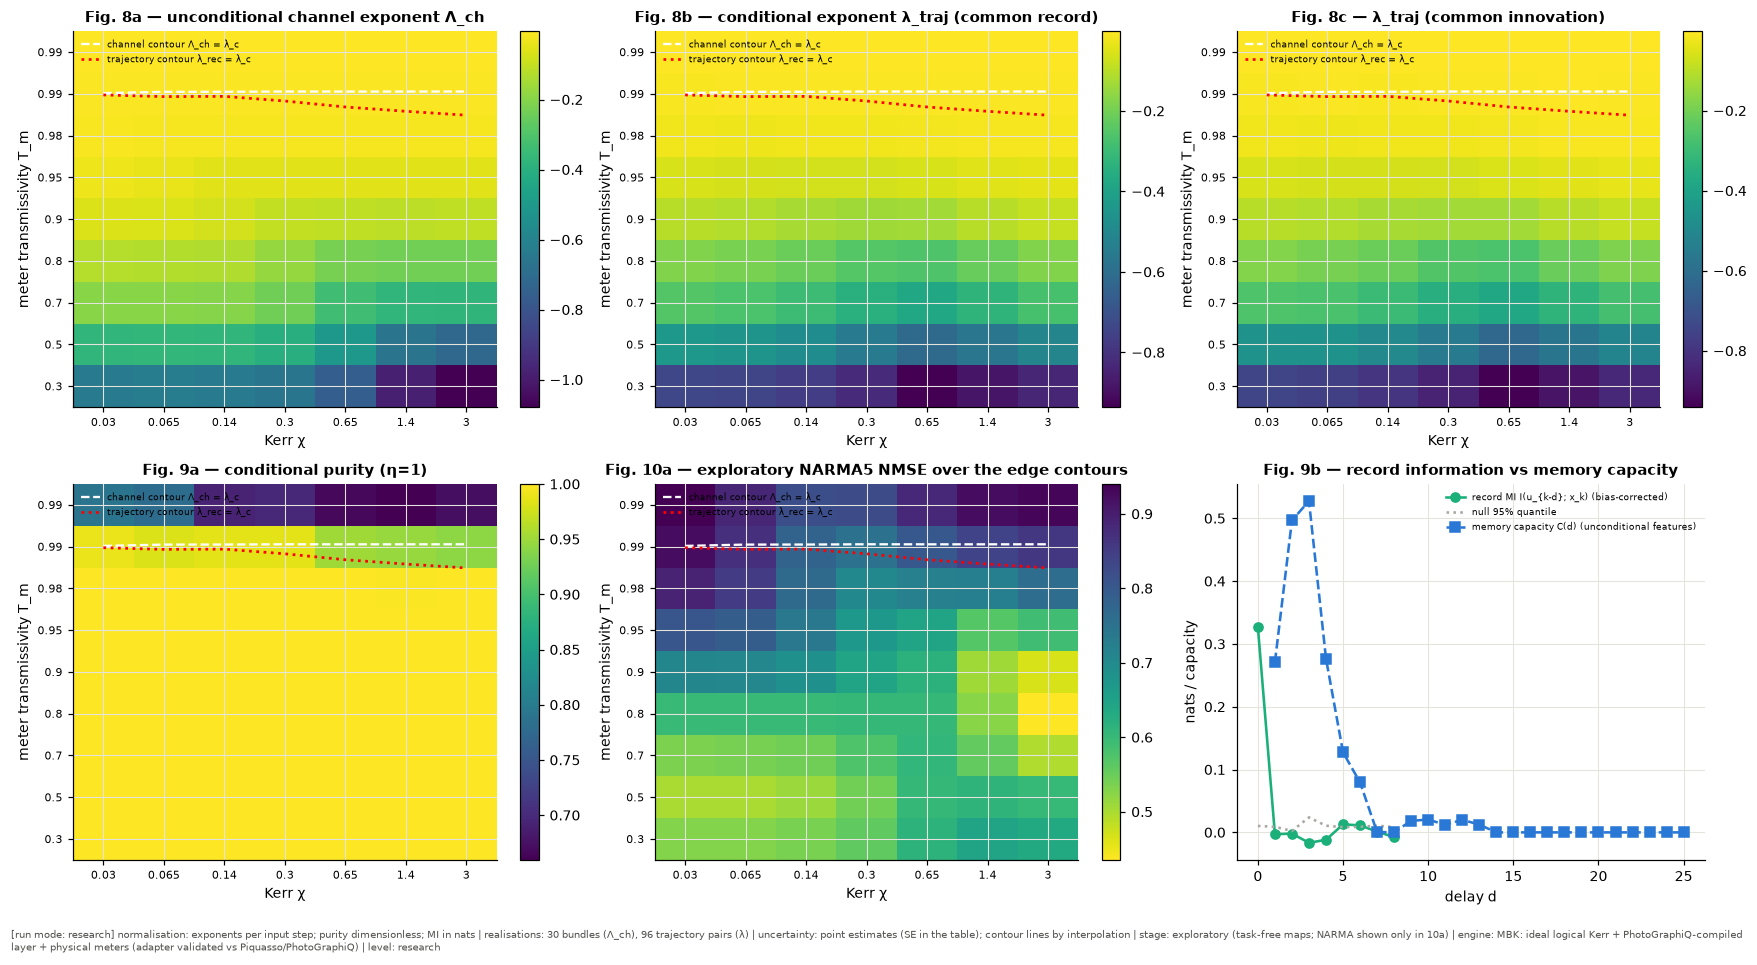

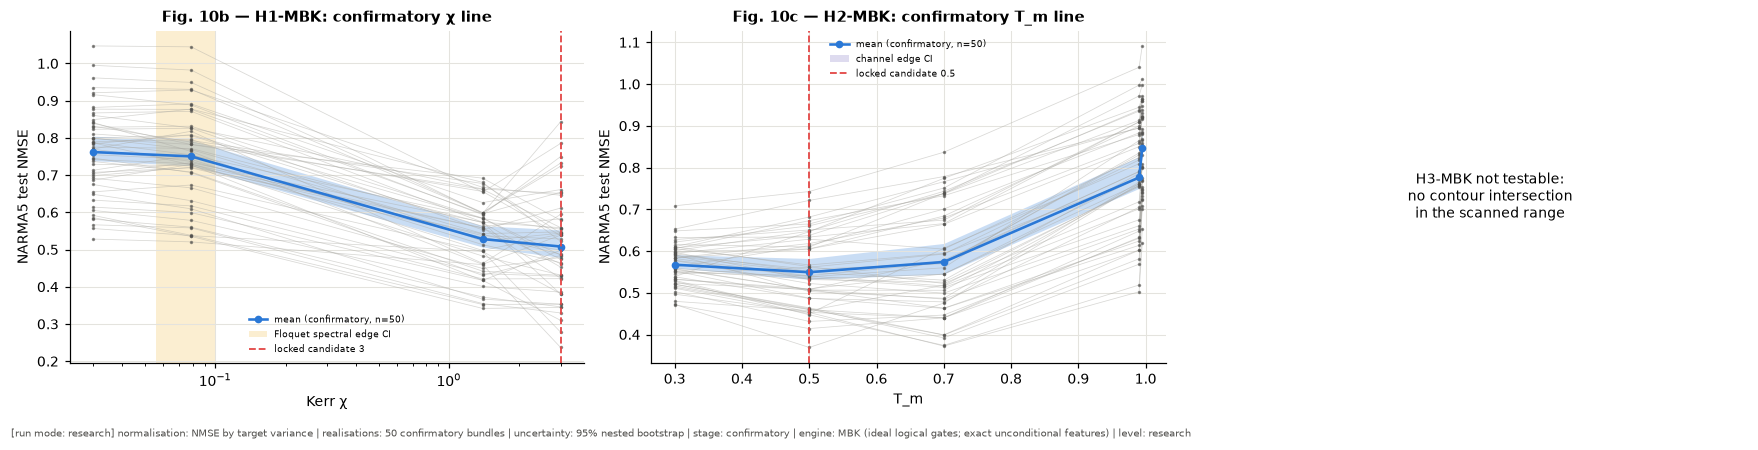

In [58]:
fig, axs = plt.subplots(2, 3, figsize=(16, 8.4))
def heat(ax, col, title, cmap="viridis", center=None):
    P_ = MAP.pivot(index="T", columns="chi", values=col); im = ax.imshow(P_.values, origin="lower", aspect="auto", cmap=cmap, extent=[-0.5, len(chi_g) - 0.5, -0.5, len(T_g) - 0.5])
    ax.set_xticks(range(len(chi_g))); ax.set_xticklabels([f"{c:.2g}" for c in chi_g], fontsize=7); ax.set_yticks(range(len(T_g))); ax.set_yticklabels([f"{t:.2g}" for t in T_g], fontsize=7)
    ax.set(xlabel="Kerr χ", ylabel="meter transmissivity T_m", title=title); plt.colorbar(im, ax=ax, fraction=0.046)
    xi = np.arange(len(chi_g)); ax.plot(xi, np.interp(T_CH, T_g, range(len(T_g)), left=np.nan, right=np.nan), "w--", lw=1.5, label="channel contour Λ_ch = λ_c")
    ax.plot(xi, np.interp(T_TR, T_g, range(len(T_g)), left=np.nan, right=np.nan), "r:", lw=1.8, label="trajectory contour λ_rec = λ_c"); ax.legend(fontsize=6, loc="upper left")
heat(axs[0, 0], "Lambda_ch", "Fig. 8a — unconditional channel exponent Λ_ch"); heat(axs[0, 1], "lambda_rec", "Fig. 8b — conditional exponent λ_traj (common record)")
heat(axs[0, 2], "lambda_innov", "Fig. 8c — λ_traj (common innovation)")
heat(axs[1, 0], "cond_purity", "Fig. 9a — conditional purity (η=1)"); heat(axs[1, 1], "NARMA5", "Fig. 10a — exploratory NARMA5 NMSE over the edge contours", cmap="viridis_r")
axs[1, 2].plot(MI_DF.delay, MI_DF.MI, "o-", color=COL["mb"], label="record MI I(u_{k-d}; x_k) (bias-corrected)"); axs[1, 2].plot(MI_DF.delay, MI_DF.null_q95, ":", color=COL["grey"], label="null 95% quantile")
axs[1, 2].plot(np.arange(1, len(MC_curve) + 1), MC_curve, "s--", color=COL["dv"], label="memory capacity C(d) (unconditional features)"); axs[1, 2].set(xlabel="delay d", ylabel="nats / capacity", title="Fig. 9b — record information vs memory capacity")
axs[1, 2].legend(fontsize=6)
figmeta(fig, normalisation="exponents per input step; purity dimensionless; MI in nats", realisations=f"{MBK_BANKS['explore'].n} bundles (Λ_ch), {phase_cfg('phase4', 'mbk_traj')} trajectory pairs (λ)",
        uncertainty="point estimates (SE in the table); contour lines by interpolation", stage="exploratory (task-free maps; NARMA shown only in 10a)",
        engine="MBK: ideal logical Kerr + PhotoGraphiQ-compiled layer + physical meters (adapter validated vs Piquasso/PhotoGraphiQ)", level=PHASE_LEVEL["phase4"])
plt.tight_layout(); plt.show()
fig, axs = plt.subplots(1, 3, figsize=(16, 3.9))
perf_plot(axs[0], CF_chi, cc, "Fig. 10b — H1-MBK: confirmatory χ line", "Kerr χ", [(EDGE_FLK["lo"], EDGE_FLK["hi"], "Floquet spectral edge CI", COL["yel"])], LOCKS["H1-MBK"]["candidate"], "confirmatory")
perf_plot(axs[1], CF_T, tcf, "Fig. 10c — H2-MBK: confirmatory T_m line", "T_m", [(EDGE_CH_MBK["lo"], EDGE_CH_MBK["hi"], "channel edge CI", COL["vio"])], LOCKS["H2-MBK"]["candidate"], "confirmatory", log=False)
if CF_H3 is not None:
    perf_plot(axs[2], CF_H3, t3, f"Fig. 10d — H3-MBK: T_m line at χ*={CHI_STAR:.3g}", "T_m", [(EDGE_H3["lo"], EDGE_H3["hi"], "intersection CI", COL["red"])], LOCKS["H3-MBK"]["candidate"], "confirmatory", log=False)
else:
    axs[2].text(0.5, 0.5, "H3-MBK not testable:\nno contour intersection\nin the scanned range", ha="center", va="center", transform=axs[2].transAxes); axs[2].set_axis_off()
figmeta(fig, normalisation="NMSE by target variance", realisations=f"{MBK_BANKS['confirm'].n} confirmatory bundles", uncertainty="95% nested bootstrap", stage="confirmatory",
        engine="MBK (ideal logical gates; exact unconditional features)", level=PHASE_LEVEL["phase4"])
plt.tight_layout(); plt.show()
RESULTS["mbqc"] = dict(map=MAP.drop(columns=["Lam_list"]), floquet=FLK.drop(columns="boots"), edges=dict(floquet=EDGE_FLK, channel=EDGE_CH_MBK, h3=EDGE_H3, h3_gauss=EDGE_H3G),
                       trajectories=TRAJ_DF, mi=MI_DF, gauss_map=MBG_MAP)

# 14. Robustness
> **Established in literature.** Finite ensembles add $M^{-1/2}$ feature noise. Photon loss is amplitude damping. Finite squeezing and feedforward errors add Gaussian displacement noise [García-Beni *et al.* 2023, 2025].
> **Adapted here.** Every noise model acts on the same bundles and confirmatory grids as the noiseless analysis (common random numbers):
> * **DV:** finite joint-PNR shot budgets and detector efficiency by binomial thinning of whole occupation patterns.
> * **MBK:**
>   * propagation loss $\gamma$ per step and mode;
>   * meter squeezing $r_m$;
>   * feedforward-gain error $\epsilon$, which leaves residual displacement noise of variance $\epsilon^2(2\bar n+1)$ per quadrature;
>   * the Fock cutoff.
>
>   **MBK finite shots are not simulated.** The lag-1 features need the joint distribution of the record across steps, which only trajectory sampling provides. Instead, the **physical sample complexity** is reported: the number of shots per step needed to estimate each first moment to 10 % of its temporal standard deviation, computed from the exact outcome variances. Detector efficiency acts on the exact unconditional features only affinely, and the standardised ridge readout is affine-invariant, so its effect enters only through that sample complexity.
> **Proposed novel element.** None.

**Protocol.**
1. Preliminary verdicts are computed first, with the same code as §16.
2. Every hypothesis with a **supported** verdict gets the full noise panel on its confirmatory grid.
3. Independently of the verdicts, a **noise-motion study** is run at the DV and MBK reference lines. For each noise condition it records:
   * the channel edge;
   * the arg-min of the primary endpoint;
   * whether edge and optimum move together;
   * whether the endpoint differences survive;
   * whether they remain resolvable, i.e. whether the difference exceeds its bootstrap CI.

**Levels.** Research mode runs two levels of each MBK noise type (`rob_mbk` in §2.6). Smoke mode runs one level per type, and only checks the code path.

preliminary verdicts: {'H1a-DV': 'inconclusive because underpowered', 'H1b-DV': 'evidence against', 'H2-DV': 'evidence against', 'H1t-DV': 'supported', 'H1-CVK': 'not testable with the implemented model', 'H2-CVK': 'not testable with the implemented model', 'H2-CVG': 'evidence against', 'H2-MBG': 'evidence against', 'H1-MBK': 'evidence against', 'H2-MBK': 'evidence against', 'H3-MBK': 'not testable with the implemented model', 'H3-MBG': 'not testable with the implemented model'}
positive results needing the full noise panel: ['H1t-DV']


[14 robustness and noise motion] 116.2 s | peak host memory 2856 MB | GPU pool 2476 MB | reused checkpointed units: 3412 s of earlier compute + 59 untimed units


,engine,line,edge_moves,condition,x_opt,mean_at_argmin,delta_end0,delta_end1,n,channel_edge,optimum_moved,edge_and_optimum_move_together
0,DV,U/J (confirmatory),spectral edge: property of H (does not move with detecti...,exact,0.0642,0.3480,0.0425,1.0222,10,NaN,False,NaN
1,DV,U/J (confirmatory),spectral edge: property of H (does not move with detecti...,"(100, 1.0)",4.5650,0.7412,0.0311,0.2794,10,NaN,True,NaN
2,DV,U/J (confirmatory),spectral edge: property of H (does not move with detecti...,"(1000, 1.0)",4.5650,0.5680,0.0389,0.4416,10,NaN,True,NaN
3,DV,U/J (confirmatory),spectral edge: property of H (does not move with detecti...,"(10000, 1.0)",0.0623,0.4456,0.0374,0.5111,10,NaN,True,NaN
4,DV,U/J (confirmatory),spectral edge: property of H (does not move with detecti...,"(10000, 0.9)",0.0623,0.4506,0.0357,0.5145,10,NaN,True,NaN
5,DV,U/J (confirmatory),spectral edge: property of H (does not move with detecti...,"(10000, 0.7)",0.0623,0.4703,0.0253,0.4998,10,NaN,True,NaN
6,DV,U/J (confirmatory),spectral edge: property of H (does not move with detecti...,"(10000, 0.5)",0.0623,0.4869,0.0392,0.4949,10,NaN,True,NaN
7,MBK,T_m at chi=0.3,see channel_edge column,baseline,0.5000,0.5630,0.0110,0.2821,6,0.9903,False,True
8,MBK,T_m at chi=0.3,see channel_edge column,loss 0.01,0.5000,0.5633,0.0115,0.3373,6,NaN,False,False
9,MBK,T_m at chi=0.3,see channel_edge column,loss 0.05,0.5000,0.5646,0.0132,0.3087,6,NaN,False,False


,T_m,eta,shots_per_step_required,total_shots_for_run,postselection
0,0.3,1.0,16208.4,4.862520e+07,none (accepted fraction 1)
1,0.3,0.7,21246.8,6.374051e+07,none (accepted fraction 1)
2,0.3,0.4,33842.9,1.015288e+08,none (accepted fraction 1)
3,0.5,1.0,7876.8,2.363052e+07,none (accepted fraction 1)
4,0.5,0.7,11112.7,3.333796e+07,none (accepted fraction 1)
5,0.5,0.4,19202.2,5.760656e+07,none (accepted fraction 1)
6,0.7,1.0,6852.6,2.055772e+07,none (accepted fraction 1)
7,0.7,0.7,10753.8,3.226142e+07,none (accepted fraction 1)
8,0.7,0.4,20506.9,6.152066e+07,none (accepted fraction 1)
9,1.0,1.0,898624.2,2.695873e+09,none (accepted fraction 1)


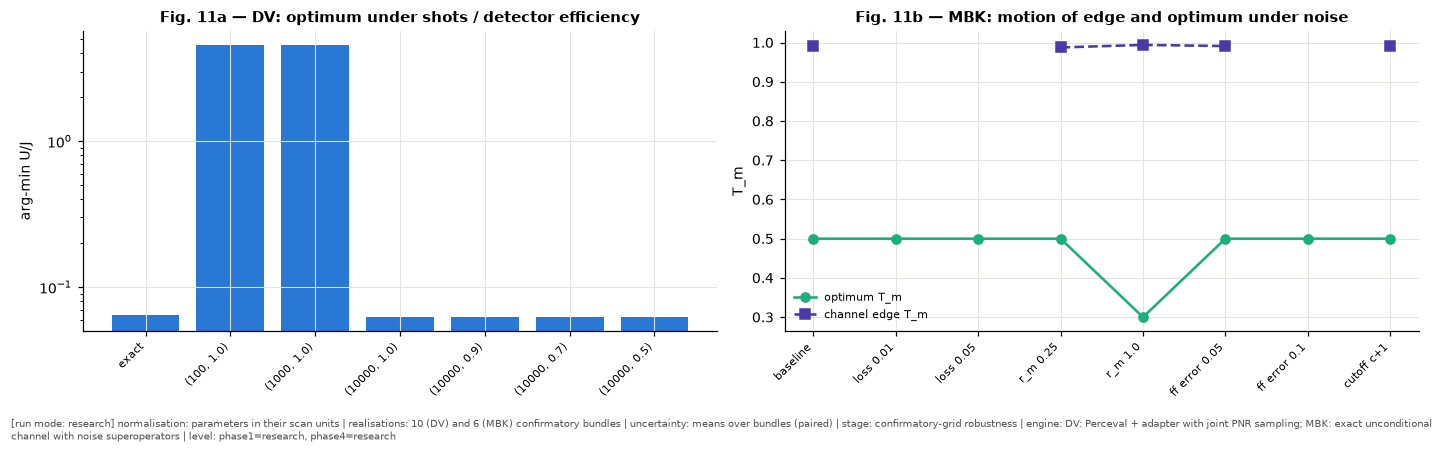

In [59]:
PRELIM = finalize_verdicts([h for h in HYP_RESULTS])
POSITIVE = [h for h, (v, _) in PRELIM.items() if v == "supported"]
print("preliminary verdicts:", {h: v for h, (v, _) in PRELIM.items()}); print("positive results needing the full noise panel:", POSITIVE or "none")

def noisy_line(label, xs, rows_fn):
    """Primary endpoint along a line under one noise condition: arg-min and endpoint differences (paired over bundles)."""
    df = pd.DataFrame([r for x in xs for r in rows_fn(x)]); M, rs = per_bundle_nmse(df, xs); means = np.nanmean(M, 1)
    i = int(np.nanargmin(means)); dends = [float(np.nanmean(M[e] - M[i])) for e in (0, len(xs) - 1)]
    return dict(condition=label, x_opt=float(xs[i]), mean_at_argmin=float(means[i]), delta_end0=dends[0], delta_end1=dends[1], n=len(rs))

with section("14 robustness and noise motion"):
    ROB = []; nrob = min(phase_cfg("phase1", "n_confirm"), 10); rob_bank = Bank("dv", "confirm", nrob)
    # ---- DV: finite shots and detector efficiency on the confirmatory U/J line (the same bundles, first nrob)
    bs_r = [dv_bundle(LDV, NDV, rob_bank.name, rob_bank.stage, r) for r in rob_bank.ids()]; nmB = np.asarray(sector(LDV, NDV), float)
    dists = {}
    def dists_at(g):                         # occupation distributions on the confirmatory bundles (computed only when a row is not checkpointed)
        if g not in dists:
            eng = FockReservoirBatch(LDV, NDV, [b["hop"] for b in bs_r], g); eng.run(stack_ports(bs_r), TAU_LONG, keep_diag=True); dists[g] = eng.diags
        return dists[g]
    def dv_rows(cond):
        def f(g):
            def compute():
                out = []
                for j, b in enumerate(bs_r):
                    if cond == "exact":
                        X = np.hstack([dists_at(g)[j][:, s] @ np.hstack([nmB, (nmB[:, :, None] * nmB[:, None, :])[:, *np.triu_indices(LDV)]]) for s in range(2)])
                    else:
                        M_, eta_ = cond
                        X = shot_features(dists_at(g)[j], nmB, moment_ops(LDV), M_, rng_for("rob-dv", g, j, M_, eta_), eta_)
                    ev = evaluate_features(X, task_design(b["u"], (rob_bank.name, rob_bank.stage, j)), secondary=False); out.append(dict(x=g, r=j, diverged=False, **{"NARMA5 NMSE": ev["primary"]}))
                return out
            key = dict(cond=str(cond), g=float(g), tau=float(TAU_LONG), bank=rob_bank.name, stage=rob_bank.stage, n=nrob, seq=CFG["seq"],
                       ipc=(CFG["ipc_deg"], CFG["ipc_delay"], CFG["n_null"], CFG["refits"]), v=(ENGINE_VERSIONS["dv"], "shots-2"))
            return STORE.cached("rob-dv", key, compute)
        return f
    for cond in ["exact"] + [(M_, 1.0) for M_ in CFG["shots"]] + [(max(CFG["shots"]), e_) for e_ in (0.9, 0.7, 0.5)]:
        ROB.append(dict(engine="DV", line="U/J (confirmatory)", edge_moves="spectral edge: property of H (does not move with detection noise)",
                        **noisy_line(str(cond), gc, dv_rows(cond))))
    # ---- MBK: loss, meter squeezing, feedforward-gain error, cutoff, detector efficiency + finite shots, on the H2 line (T_m at chi_mid)
    rbk = Bank("mbk", "confirm", min(phase_cfg("phase4", "n_confirm"), 6)); nbar = float(np.real(np.trace(np.diag(np.asarray(mdl_u.nocc).sum(1)) @ rho_u))) / CFG["mbk_L"]
    mbk_conditions = [("baseline", {}), ("loss 0.01", dict(loss=0.01)), ("loss 0.05", dict(loss=0.05)), ("r_m 0.25", dict(r_m=0.25)), ("r_m 1.0", dict(r_m=1.0)),
                      ("ff error 0.05", dict(disp_var=0.05 ** 2 * (2 * nbar + 1))), ("ff error 0.1", dict(disp_var=0.1 ** 2 * (2 * nbar + 1))), ("cutoff c+1", dict(c=CFG["mbk_cut"][1]))]
    mbk_conditions = [c_ for c_ in mbk_conditions if c_[0] in phase_cfg("phase4", "rob_mbk")]      # smoke: one level per noise type
    for lab, extra in mbk_conditions:
        rows_all = {Tm: mbk_unit(Tm, "T", rbk, dict(chi=chi_mid, eta=1.0, **extra)) for Tm in tcf}
        lam_line = [np.mean([r_["Lambda"] for r_ in rows_all[Tm]]) for Tm in tcf]
        rec = noisy_line(lab, tcf, lambda T_: rows_all[T_]); rec["channel_edge"] = level_crossing(tcf, lam_line, PREREG["lambda_c"], "up")
        ROB.append(dict(engine="MBK", line=f"T_m at chi={chi_mid:.3g}", edge_moves="see channel_edge column", **rec))
    ROB_DF = pd.DataFrame(ROB)
    base_mbk = ROB_DF[(ROB_DF.engine == "MBK") & (ROB_DF.condition == "baseline")].iloc[0]
    ROB_DF["optimum_moved"] = [r.x_opt != (ROB_DF[(ROB_DF.engine == r.engine)].iloc[0].x_opt) for r in ROB_DF.itertuples()]
    ROB_DF["edge_and_optimum_move_together"] = [(np.isfinite(getattr(r, "channel_edge", np.nan)) and np.isfinite(base_mbk.channel_edge) and
                                                 np.sign(r.channel_edge - base_mbk.channel_edge) == np.sign(r.x_opt - base_mbk.x_opt)) if r.engine == "MBK" else np.nan for r in ROB_DF.itertuples()]
    # physical sample complexity of the MBK readout (exact outcome variances; eta enters as Var -> eta Var + 1 - eta over the scaled signal)
    sc_rows = []
    for Tm in tcf:
        eps_ = np.stack([disorder(CFG["mbk_L"], W_BH, r, rbk.name, rbk.stage) for r in rbk.ids()])[:1]; u_ = input_sequence(rbk.name, rbk.stage, 0)[None]
        Xf = MBKModel(eps_, chi_mid, Tm, L=CFG["mbk_L"], c=CFG["mbk_cut"][0], cM=CFG["mbk_meter_cut"]).run(u_)[0][SPLITS["tr"].start:]
        for eta_ in (1.0, 0.7, 0.4):
            m1 = Xf[:, :3]; m2 = Xf[:, [3, 6, 8]] + (1 - eta_) / eta_; var = np.clip(m2 - m1 ** 2, 1e-12, None)
            M_req = np.nanmax(var.mean(0) / (0.1 * m1.std(0)) ** 2); sc_rows.append(dict(T_m=Tm, eta=eta_, shots_per_step_required=float(M_req),
                                                                                                  total_shots_for_run=float(M_req * SPLITS["T"]), postselection="none (accepted fraction 1)"))
    SAMPLE_COMPLEXITY = pd.DataFrame(sc_rows)
    # full noise panel for positive results
    PANEL = {h: "full noise panel = the conditions above on the hypothesis line" for h in POSITIVE}
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(ROB_DF.round(4)); display(SAMPLE_COMPLEXITY.round(1))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
d_ = ROB_DF[ROB_DF.engine == "DV"]; axs[0].bar(range(len(d_)), d_.x_opt, color=COL["dv"]); axs[0].set_xticks(range(len(d_))); axs[0].set_xticklabels(d_.condition, rotation=45, ha="right", fontsize=7)
axs[0].set(yscale="log", ylabel="arg-min U/J", title="Fig. 11a — DV: optimum under shots / detector efficiency")
d_ = ROB_DF[ROB_DF.engine == "MBK"]; axs[1].plot(range(len(d_)), d_.x_opt, "o-", color=COL["mb"], label="optimum T_m"); axs[1].plot(range(len(d_)), d_.channel_edge, "s--", color=COL["vio"], label="channel edge T_m")
axs[1].set_xticks(range(len(d_))); axs[1].set_xticklabels(d_.condition, rotation=45, ha="right", fontsize=7); axs[1].set(ylabel="T_m", title="Fig. 11b — MBK: motion of edge and optimum under noise"); axs[1].legend(fontsize=7)
figmeta(fig, normalisation="parameters in their scan units", realisations=f"{nrob} (DV) and {rbk.n} (MBK) confirmatory bundles", uncertainty="means over bundles (paired)",
        stage="confirmatory-grid robustness", engine="DV: Perceval + adapter with joint PNR sampling; MBK: exact unconditional channel with noise superoperators", level=f"phase1={PHASE_LEVEL['phase1']}, phase4={PHASE_LEVEL['phase4']}")
plt.tight_layout(); plt.show()
RESULTS["robustness"] = ROB_DF

# 15. Resource-matched classical controls
> **Established in literature.** Linear autoregression, NARX models, echo-state networks [Jaeger 2001], and random-feature recurrent models are the standard baselines for reservoir computing.
> **Adapted here.** Each quantum reservoir at its **locked confirmatory candidate** is compared, on the **same confirmatory bundles**, with four classical models. The models are matched to the quantum reservoir in:
> * **feature dimension $F$**, and therefore in the number of trainable readout parameters $F+1$;
> * input sequence, splits, and ridge readout with the same $\lambda$ grid;
> * **hyperparameter-search budget:** `hyper_budget` configurations per model, selected on validation NARMA5 only. The quantum reservoirs had their exploratory grid, which is at least as large.
> * optional **noise**: Gaussian feature noise at the relative level $1/\sqrt M$ of the largest shot budget (`noise-matched` rows).
> **Proposed novel element.** None.

The models:
* **AR:** the last $F$ inputs.
* **NARX-2:** all monomials of degree $\le2$ in the last $p$ inputs, with $p(p+3)/2\le F$.
* **ESN:** $F$ tanh nodes, over a spectral-radius × input-scale grid.
* **RFR:** a random orthogonal linear recurrence of dimension $F$ read through $F$ random Fourier features, over a radius × bandwidth grid.

**Decision.** Paired per-bundle differences, a two-sided Wilcoxon test, and Holm correction across all quantum–classical comparisons. **A quantum advantage would require the quantum reservoir to be significantly better than every classical control.** Nothing in this section is interpreted otherwise.

[15 resource-matched classical controls] 65.6 s | peak host memory 3279 MB | GPU pool 2476 MB | reused checkpointed units: 31 s of earlier compute + 624 untimed units


,engine,control,F,n,quantum_mean,classical_mean,mean_diff_classical_minus_quantum,p_raw,p_holm,quantum_better_significant
0,CV Gaussian (Piquasso),AR,15,50,0.3609,0.1409,-0.2200,0.0000,0.0000,False
1,CV Gaussian (Piquasso),NARX-2,15,50,0.3609,0.6195,0.2586,0.0000,0.0000,True
2,CV Gaussian (Piquasso),ESN,15,50,0.3609,0.1441,-0.2168,0.0000,0.0000,False
3,CV Gaussian (Piquasso),RFR,15,50,0.3609,0.2538,-0.1071,0.0000,0.0000,False
4,CV Gaussian (Piquasso),ESN noise-matched,15,50,0.3609,0.1719,-0.1891,0.0000,0.0000,False
5,CV Gaussian (Piquasso),RFR noise-matched,15,50,0.3609,0.2628,-0.0981,0.0000,0.0000,False
6,CV Kerr (Piquasso),AR,40,50,0.0540,0.1446,0.0907,0.0000,0.0000,True
7,CV Kerr (Piquasso),NARX-2,40,50,0.0540,0.0291,-0.0248,0.0000,0.0000,False
8,CV Kerr (Piquasso),ESN,40,50,0.0540,0.0597,0.0058,0.0693,0.4851,False
9,CV Kerr (Piquasso),RFR,40,50,0.0540,0.0649,0.0109,0.0162,0.1295,False


resource-matched quantum advantage (quantum significantly better than every control): {'CV Gaussian (Piquasso)': False, 'CV Kerr (Piquasso)': False, 'CV-MB Gaussian (PhotoGraphiQ)': False, 'DV (Perceval)': False, 'MBK (ideal logical gates)': False}


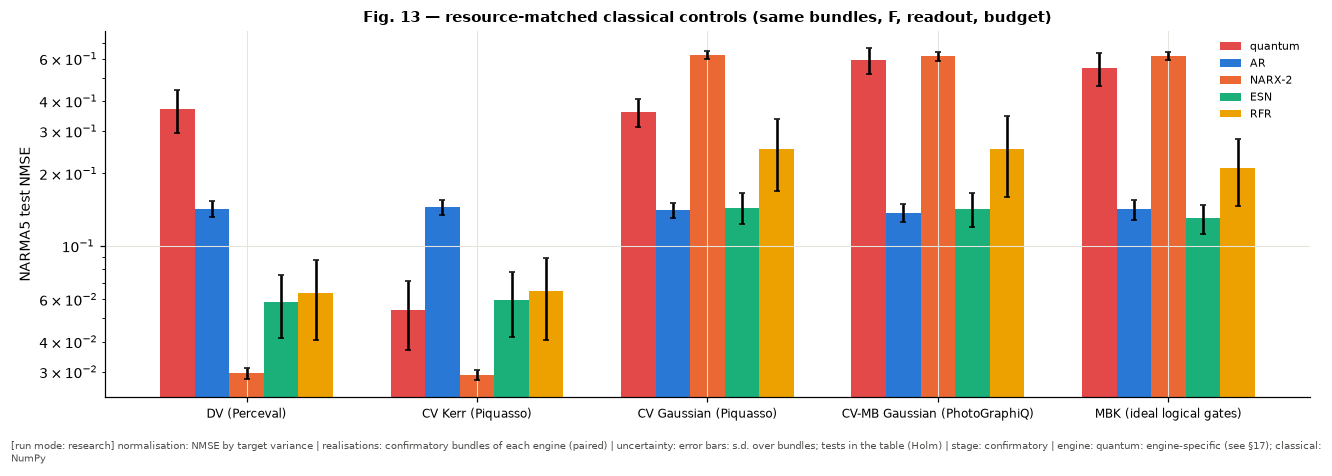

In [60]:
def feat_lags(u, F):
    return np.nan_to_num(np.stack([delayed(2 * np.asarray(u) - 1, t) for t in range(F)], 1))

def feat_narx(u, F):
    p = max(p_ for p_ in range(1, F + 1) if p_ * (p_ + 3) // 2 <= F); L_ = feat_lags(u, p); cols = [L_[:, i] for i in range(p)]
    cols += [L_[:, i] * L_[:, j] for i in range(p) for j in range(i, p)]; return np.stack(cols, 1)[:, :F]

def feat_esn(u, F, rho, sc, seed):
    r = np.random.default_rng(seed); Wm = r.normal(size=(F, F)); Wm *= rho / np.abs(np.linalg.eigvals(Wm)).max(); Win = r.uniform(-1, 1, F) * sc; b = r.uniform(-0.2, 0.2, F)
    x = np.zeros(F); S = np.empty((len(u), F))
    for k, uk in enumerate(u):
        x = np.tanh(Wm @ x + Win * (2 * uk - 1) + b); S[k] = x
    return S

def feat_rfr(u, F, rho, bw, seed):
    r = np.random.default_rng(seed); Q, _ = np.linalg.qr(r.normal(size=(F, F))); w = r.normal(size=F); Om = r.normal(size=(F, F)) * bw; ph = r.uniform(0, 2 * np.pi, F)
    x = np.zeros(F); S = np.empty((len(u), F))
    for k, uk in enumerate(u):
        x = rho * Q @ x + w * (2 * uk - 1); S[k] = np.cos(Om @ x + ph)
    return S

def classical_best(kind, u, F, seed, budget):
    """Best of `budget` hyperparameter configurations, selected on validation NARMA5 only."""
    grids = {"AR": [()], "NARX-2": [()], "ESN": [(rh, sc) for rh in (0.5, 0.8, 0.95) for sc in (0.1, 0.5, 1.0)],
             "RFR": [(rh, bw) for rh in (0.5, 0.8, 0.95) for bw in (0.1, 0.3, 1.0)]}[kind][:budget]
    y5 = np.nan_to_num(narma(u, 5)); best = (np.inf, None)
    for hp in grids:
        X = {"AR": lambda: feat_lags(u, F), "NARX-2": lambda: feat_narx(u, F), "ESN": lambda: feat_esn(u, F, *hp, seed), "RFR": lambda: feat_rfr(u, F, *hp, seed)}[kind]()
        v, _ = RidgeReadout(X).fit_predict(y5[:, None])
        if v[0] < best[0]:
            best = (v[0], X)
    return best[1]

with section("15 resource-matched classical controls"):
    engines = {"DV (Perceval)": ("H1b-DV", DV_CF_G, lambda r: input_sequence("dv", "confirm", r)),
               "CV Kerr (Piquasso)": ("H2-CVK", CV_CF, lambda r: input_sequence("cvk", "confirm", r)),
               "CV Gaussian (Piquasso)": ("H2-CVG", CVG_CF, lambda r: input_sequence("cvg", "confirm", r)),
               "CV-MB Gaussian (PhotoGraphiQ)": ("H2-MBG", MBG_CF, lambda r: input_sequence("mbg", "confirm", r)),
               "MBK (ideal logical gates)": ("H2-MBK", CF_T, lambda r: input_sequence("mbk", "confirm", r))}
    Fdim = {"DV (Perceval)": 40, "CV Kerr (Piquasso)": 40, "CV Gaussian (Piquasso)": CFG["cv_N"] * (CFG["cv_N"] + 1) // 2, "CV-MB Gaussian (PhotoGraphiQ)": CFG["mb_N"] * (CFG["mb_N"] + 1) // 2,
            "MBK (ideal logical gates)": 18}
    rows = []; Mnoise = max(CFG["shots"])
    for eng, (hid, cf, useq) in engines.items():
        xc = HYP_RESULTS[hid]["x_cand"]; qrow = cf[np.isclose(cf.x, xc)].set_index("r")
        for r in sorted(qrow.index):
            u = useq(r); des = task_design(u, (cf.bank.iloc[0], cf.stage.iloc[0], r)); rec = dict(engine=eng, hypothesis=hid, r=r, F=Fdim[eng], quantum=float(qrow.loc[r, "NARMA5 NMSE"]))
            for kind in ("AR", "NARX-2", "ESN", "RFR"):
                X = STORE.cached("classical", dict(kind=kind, bank=cf.bank.iloc[0], r=int(r), F=Fdim[eng], budget=CFG["hyper_budget"], seq=CFG["seq"], v=ENGINE_VERSIONS["classical"]),
                                 lambda kind=kind, u=u: classical_best(kind, u, Fdim[eng], seed_int("classical", kind, r), CFG["hyper_budget"]))
                rec[kind] = evaluate_features(X, des, secondary=False)["primary"]
                Xn = X + rng_for("cl-noise", kind, r).normal(size=X.shape) * X.std(0) / math.sqrt(Mnoise); rec[kind + " noise-matched"] = evaluate_features(Xn, des, secondary=False)["primary"]
            rows.append(rec)
    CLS = pd.DataFrame(rows); comps = []
    for eng, g_ in CLS.groupby("engine"):
        for kind in ("AR", "NARX-2", "ESN", "RFR", "ESN noise-matched", "RFR noise-matched"):
            d = (g_[kind] - g_.quantum).values; p = float(sst.wilcoxon(d).pvalue) if len(d) >= 3 and not np.allclose(d, 0) else 1.0
            comps.append(dict(engine=eng, control=kind, F=int(g_.F.iloc[0]), n=len(d), quantum_mean=float(g_.quantum.mean()), classical_mean=float(g_[kind].mean()),
                              mean_diff_classical_minus_quantum=float(d.mean()), p_raw=p))
    CLS_CMP = pd.DataFrame(comps); CLS_CMP["p_holm"] = holm(CLS_CMP.p_raw.values)
    CLS_CMP["quantum_better_significant"] = (CLS_CMP.mean_diff_classical_minus_quantum > 0) & (CLS_CMP.p_holm < PREREG["alpha"])
    ADVANTAGE = {e: bool(g_.quantum_better_significant.all()) for e, g_ in CLS_CMP.groupby("engine")}
with pd.option_context("display.width", 250):
    display(CLS_CMP.round(4))
print("resource-matched quantum advantage (quantum significantly better than every control):", ADVANTAGE)
fig, ax = plt.subplots(figsize=(12, 4))
engs = list(engines); w_ = 0.15
for k, kind in enumerate(["quantum", "AR", "NARX-2", "ESN", "RFR"]):
    ax.bar(np.arange(len(engs)) + (k - 2) * w_, [CLS[CLS.engine == e][kind].mean() for e in engs], w_, yerr=[CLS[CLS.engine == e][kind].std() for e in engs], capsize=2,
           color=([COL["red"]] + PAL)[k], label=kind)
ax.set_xticks(range(len(engs))); ax.set_xticklabels(engs, fontsize=8); ax.set(ylabel="NARMA5 test NMSE", yscale="log", title="Fig. 13 — resource-matched classical controls (same bundles, F, readout, budget)")
ax.legend(fontsize=7)
figmeta(fig, normalisation="NMSE by target variance", realisations="confirmatory bundles of each engine (paired)", uncertainty="error bars: s.d. over bundles; tests in the table (Holm)",
        stage="confirmatory", engine="quantum: engine-specific (see §17); classical: NumPy")
plt.tight_layout(); plt.show()
RESULTS["classical"] = dict(rows=CLS, comparisons=CLS_CMP, advantage=ADVANTAGE)

# 16. Cross-engine hypothesis tests ($H_1$, $H_2$, $H_3$)
The verdict engine of §6.6 is applied to every registered hypothesis at once. Holm correction runs across the **whole primary family**:
* every candidate-vs-endpoint comparison;
* every edge-vs-candidate comparison.

Secondary endpoints get Benjamini–Hochberg correction within each engine. They are reported but cannot change a verdict.

**Column definitions.**
* *Endpoint improvement:* the mean paired NMSE difference (endpoint − candidate) with its nested-bootstrap 95 % CI, for both scan ends.
* *Corrected significance:* the Holm-adjusted $p$.
* *Effect size:* $d_z$.
* *Robust to noise?:* whether the §14 noise conditions leave the optimum on the same grid point. This is evaluated for the DV and MBK lines; the other lines are marked "not assessed".

[16 hypothesis verdicts] 0.5 s | peak host memory 3284 MB | GPU pool 2476 MB


,Engine,Independently measured edge,Confirmatory optimum,Endpoint improvement,Corrected significance,Effect size,Robust to noise?,Verdict,Failed criteria,level,n_confirm
Hypothesis,,,,,,,,,,,
H1a-DV,DV (Perceval),"0.0623 [0.0497, 0.0792]",0.0642 (interval 0.0623-0.137); locked candidate 0.0642,"end0: +0.0168 [+0.0028, +0.0314]; end1: +0.8577 [+0.7595, +1.0411]",cand_vs_end0: p_holm=0.133; cand_vs_end1: p_holm=2.58e-14,d_z=0.35; d_z=2.20,no (optimum moves),inconclusive because underpowered,C2 distinguishable from both endpoints; C4 paired improvement survives (P(beats both) ...,research,50
H1b-DV,DV (Perceval),"4.56 [4.3, 4.8]",0.0642 (interval 0.0623-0.137); locked candidate 0.0642,"end0: +0.0168 [+0.0028, +0.0314]; end1: +0.8577 [+0.7595, +1.0411]",cand_vs_end0: p_holm=0.133; cand_vs_end1: p_holm=2.58e-14,d_z=0.35; d_z=2.20,no (optimum moves),evidence against,C2 distinguishable from both endpoints; C3 optimum interval overlaps edge interval; C4...,research,50
H1t-DV,DV (Perceval),"64.4 [6.12, 64.4]",6.44 (interval 6.44-6.44); locked candidate 5.62,"end0: +0.3335 [+0.3201, +0.3646]; end1: +0.2863 [+0.2765, +0.3079]",cand_vs_end0: p_holm=2.58e-14; cand_vs_end1: p_holm=2.58e-14,d_z=4.82; d_z=5.55,no (optimum moves),supported,none,research,50
H2-DV,DV (Perceval),"1.32 [1.31, 1.32]",0.0642 (interval 0.0623-0.137); locked candidate 0.0642,"end0: +0.0168 [+0.0028, +0.0314]; end1: +0.8577 [+0.7595, +1.0411]",cand_vs_end0: p_holm=0.133; cand_vs_end1: p_holm=2.58e-14,d_z=0.35; d_z=2.20,no (optimum moves),evidence against,C2 distinguishable from both endpoints; C3 optimum interval overlaps edge interval; C4...,research,50
H1-CVK,CV Kerr (Piquasso),not found,5.88 (interval 5.88-5.88); locked candidate 5.88,"end0: +0.0886 [+0.0734, +0.1088]; end1: +0.5925 [+0.5874, +0.6997]",cand_vs_end0: p_holm=2.07e-12; cand_vs_end1: p_holm=2.58e-14,d_z=1.42; d_z=3.29,not assessed,not testable with the implemented model,edge not defined in the scanned range,research,50
H2-CVK,CV Kerr (Piquasso),"5.32 [5.26, 5.37]",5.88 (interval 5.88-5.88); locked candidate 5.88,"end0: +0.0886 [+0.0734, +0.1088]; end1: +0.5925 [+0.5874, +0.6997]",cand_vs_end0: p_holm=2.07e-12; cand_vs_end1: p_holm=2.58e-14,d_z=1.42; d_z=3.29,not assessed,not testable with the implemented model,"C6 non-converged points [13.2815, 30.0]: they change beyond tolerance at cutoff c+1, s...",research,50
H2-CVG,CV Gaussian (Piquasso),"1.26 [1.24, 1.29]",0.975 (interval 0.738-0.975); locked candidate 0.975,"end0: +0.0476 [+0.0351, +0.0602]; end1: +nan [+nan, +nan]",cand_vs_end0: p_holm=9.42e-09; cand_vs_end1: p_holm=1,d_z=1.12; d_z=nan,not assessed,evidence against,C2 distinguishable from both endpoints; C3 optimum interval overlaps edge interval; C4...,research,50
H2-MBG,CV-MB Gaussian (PhotoGraphiQ),"0.722 [0.651, 0.79]",0.3 (interval 0.3-0.4); locked candidate 0.4,"end0: +0.0284 [+0.0070, +0.0499]; end1: +6124140138012.3584 [+nan, +nan]",cand_vs_end0: p_holm=0.118; cand_vs_end1: p_holm=0.5,d_z=0.39; d_z=0.58,not assessed,evidence against,C2 distinguishable from both endpoints; C3 optimum interval overlaps edge interval; C4...,research,50
H3-MBG,CV-MB Gaussian (PhotoGraphiQ),not found,n/a,n/a,n/a,n/a,not assessed,not testable with the implemented model,edge not defined in the scanned range,research,0


,engine,metric,candidate,endpoint,mean_advantage,q_BH
0,DV,NARMA10 NMSE,0.0642,0.030,-0.0176,1.0000
1,DV,NARMA10 NMSE,0.0642,60.000,0.4985,0.0000
2,DV,MC,0.0642,0.030,0.1460,0.0254
3,DV,MC,0.0642,60.000,3.7067,0.0000
4,DV,IPC_lin,0.0642,0.030,0.2102,0.0000
...,...,...,...,...,...,...
86,MBK,"XOR(b_k-1,b_k-2) acc",0.5000,0.995,0.1624,0.0000
87,MBK,parity3 acc,0.5000,0.300,-0.0008,0.7107
88,MBK,parity3 acc,0.5000,0.995,0.0033,0.2418
89,MBK,eff_rank,0.5000,0.300,1.8238,0.0000


verdict counts: {'evidence against': 6, 'not testable with the implemented model': 4, 'inconclusive because underpowered': 1, 'supported': 1}
PASS [S16.smoke] smoke-level phases never yield an established ('supported' or 'evidence against') verdict: 0 such verdicts (criterion 0)
PASS [S16.locks] no confirmatory result changed a locked candidate (candidate used in every test = locked value): 10 of 10 (criterion all)


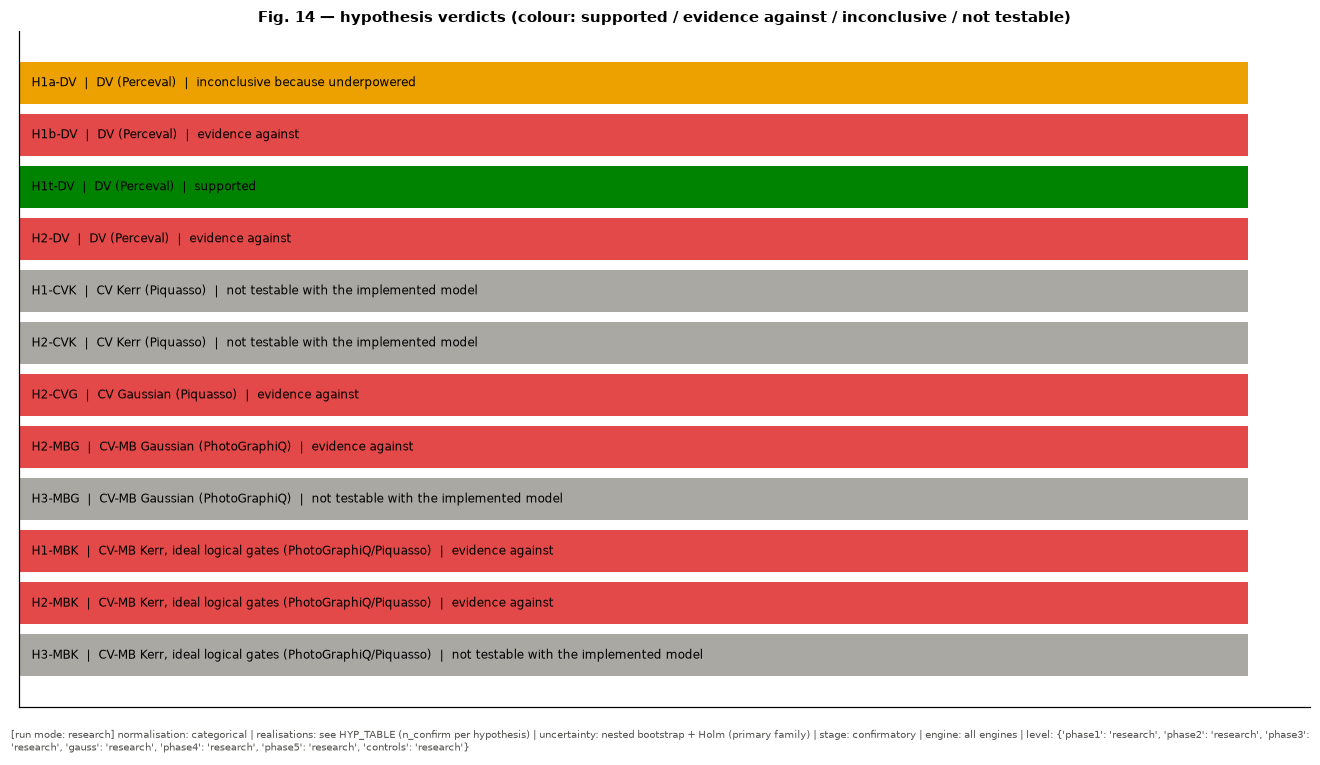

In [61]:
with section("16 hypothesis verdicts"):
    FINAL = finalize_verdicts([h for h in HYP_RESULTS]); rob_ok = {}
    for eng_, pref in (("DV", "H1b-DV"), ("MBK", "H2-MBK")):
        d_ = ROB_DF[ROB_DF.engine == eng_]; rob_ok[eng_] = bool((~d_.optimum_moved).all()) if len(d_) else None
    rows = []
    for h in PREREG["hypotheses"]:
        hid = h["id"]; r = HYP_RESULTS.get(hid)
        if r is None:
            rows.append(dict(Hypothesis=hid, Engine=h["engine"], Verdict="not testable with the implemented model", **{"Failed criteria": "hypothesis not evaluated"})); continue
        e = r["edge"]; t = r["tests"]; pa = r.get("p_adj", {})
        imp = "; ".join(f"end{j}: {t[k]['mean']:+.4f} [{r['delta_ci'][f'end{j}'][0]:+.4f}, {r['delta_ci'][f'end{j}'][1]:+.4f}]" for j, k in enumerate(t)) if t and "delta_ci" in r else "n/a"
        rob = rob_ok.get("DV") if hid.endswith("DV") else rob_ok.get("MBK") if hid.endswith("MBK") else None
        rows.append({"Hypothesis": hid, "Engine": h["engine"], "Independently measured edge": f"{e.get('value', np.nan):.3g} [{e.get('lo', np.nan):.3g}, {e.get('hi', np.nan):.3g}]" if e.get("found") else "not found",
                     "Confirmatory optimum": f"{r['x_conf_opt']:.3g} (interval {r['opt_interval'][0]:.3g}-{r['opt_interval'][1]:.3g}); locked candidate {r['x_cand']:.3g}" if np.isfinite(r.get("x_cand", np.nan)) else "n/a",
                     "Endpoint improvement": imp, "Corrected significance": "; ".join(f"{k}: p_holm={pa.get(k, np.nan):.3g}" for k in t) or "n/a",
                     "Effect size": "; ".join(f"d_z={t[k]['dz']:.2f}" for k in t) or "n/a", "Robust to noise?": "not assessed" if rob is None else ("yes" if rob else "no (optimum moves)"),
                     "Verdict": r["verdict"], "Failed criteria": "; ".join(r["failed"]) or "none", "level": r["level"], "n_confirm": r["n_confirm"]})
    HYP_TABLE = pd.DataFrame(rows)
    # secondary endpoints: candidate vs both endpoints, BH within each engine (reported only)
    sec_rows = []
    confirm_frames = {"DV": [DV_CF_G, DV_CF_T], "CV Kerr": [CV_CF], "CV Gaussian": [CVG_CF], "CV-MB Gaussian": [MBG_CF], "MBK": [CF_chi, CF_T] + ([CF_H3] if CF_H3 is not None else [])}
    for eng_, frames in confirm_frames.items():
        pv, keys = [], []
        for df_ in frames:
            xs_ = np.sort(df_.x.unique()); cand = [HYP_RESULTS[h]["x_cand"] for h in HYP_RESULTS if HYP_RESULTS[h].get("xs") is not None and len(HYP_RESULTS[h]["xs"]) == len(xs_) and np.allclose(np.sort(HYP_RESULTS[h]["xs"]), xs_)]
            if not cand:
                continue
            ic = int(np.argmin(np.abs(xs_ - cand[0])))
            for m in PREREG["secondary_endpoints"]:
                if m not in df_:
                    continue
                Mm, _ = per_bundle_nmse(df_, xs_, "x", m); lower = m.endswith("NMSE")
                for e_ in (0, len(xs_) - 1):
                    if e_ == ic:
                        continue
                    a_, b_ = (Mm[ic], Mm[e_]) if lower else (-Mm[ic], -Mm[e_]); tt = paired_test(a_, b_); pv.append(tt["p"]); keys.append((eng_, m, float(xs_[ic]), float(xs_[e_]), tt["mean"]))
        if pv:
            for k_, q_ in zip(keys, benjamini_hochberg(pv)):
                sec_rows.append(dict(engine=k_[0], metric=k_[1], candidate=k_[2], endpoint=k_[3], mean_advantage=k_[4], q_BH=q_))
    SEC_TABLE = pd.DataFrame(sec_rows)
with pd.option_context("display.max_colwidth", 90, "display.width", 300):
    display(HYP_TABLE.set_index("Hypothesis"))
    display(SEC_TABLE.round(4) if len(SEC_TABLE) else pd.DataFrame({"note": ["no secondary comparisons"]}))
counts = HYP_TABLE.Verdict.value_counts(); print("verdict counts:", counts.to_dict())
record_test("S16.smoke", "smoke-level phases never yield an established ('supported' or 'evidence against') verdict",
            f"{int(((HYP_TABLE.get('level') == 'smoke') & HYP_TABLE.Verdict.isin(['supported', 'evidence against'])).sum())} such verdicts", "0",
            int(((HYP_TABLE.get("level") == "smoke") & HYP_TABLE.Verdict.isin(["supported", "evidence against"])).sum()) == 0, section_ref="16", category="statistics")
record_test("S16.locks", "no confirmatory result changed a locked candidate (candidate used in every test = locked value)",
            f"{sum(abs(HYP_RESULTS[h]['x_cand'] - LOCKS[h]['candidate']) < 1e-9 * max(1, abs(LOCKS[h]['candidate'])) for h in LOCKS if h in HYP_RESULTS)} of {len(LOCKS)}",
            "all", all(abs(HYP_RESULTS[h]["x_cand"] - LOCKS[h]["candidate"]) < 1e-9 * max(1, abs(LOCKS[h]["candidate"])) for h in LOCKS if h in HYP_RESULTS), section_ref="16", category="statistics")

fig, ax = plt.subplots(figsize=(12, 0.45 * len(HYP_TABLE) + 1.2))
vcol = {"supported": COL["grn"], "evidence against": COL["red"], "inconclusive because underpowered": COL["yel"], "not testable with the implemented model": COL["grey"]}
for i, r in enumerate(HYP_TABLE.itertuples()):
    ax.barh(i, 1, color=vcol.get(r.Verdict, COL["grey"])); ax.text(0.01, i, f"{r.Hypothesis}  |  {r.Engine}  |  {r.Verdict}", va="center", fontsize=8)
ax.set_yticks([]); ax.set_xticks([]); ax.invert_yaxis(); ax.set_title("Fig. 14 — hypothesis verdicts (colour: supported / evidence against / inconclusive / not testable)")
figmeta(fig, normalisation="categorical", realisations="see HYP_TABLE (n_confirm per hypothesis)", uncertainty="nested bootstrap + Holm (primary family)",
        stage="confirmatory", engine="all engines", level=str(PHASE_LEVEL))
plt.tight_layout(); plt.show()
RESULTS["hypotheses"] = dict(table=HYP_TABLE, secondary=SEC_TABLE, locks=LOCKS, prereg_sha=PREREG_SHA256)

# 17. Validation dashboard
* **17.1** Every recorded test, grouped by category (physics, numerical, engine, statistics).
* **17.2** The engine table. For Perceval, Piquasso, PhotoGraphiQ and PhotoGraphiQML it lists which operations run natively, which operators are built by the engine and iterated outside it (*engine-compiled*), which operations are exact adapters, why each adapter is needed, and which test validates it.
* **17.3** The device log (GPU vs CPU per operation).
* **17.4** Code-integrity checks:
  * no `record_test` call receives a constant pass/fail flag (AST scan of the executed cells);
  * no stale kernel state: the session guard of §2 plus a section-order check;
  * the cells executed sequentially after a kernel restart: contiguous execution counts.

Passing engine tests validates the implementations. It does **not** make any EOC hypothesis pass; those verdicts are in §16.

In [62]:
TESTS_DF = pd.DataFrame(TESTS)
with pd.option_context("display.max_colwidth", 110, "display.width", 260, "display.max_rows", 400):
    display(TESTS_DF.groupby(["category", "result"]).size().unstack(fill_value=0))
    display(TESTS_DF[["id", "category", "test", "value", "threshold", "result", "critical", "section"]])
ENGINE_TABLE = pd.DataFrame([
    ("Perceval", "native", "Fock basis/ordering, SLOS prob_amplitude sector unitaries, port-state preparation (BS+PS), U=0 probabilities, passive DV reservoir (source)", "E6.DV.*, P6.DV.U0, R6.DV.*"),
    ("Perceval", "engine-compiled", "hopping generator H = (i/t0) log U_F(t0) from prob_amplitude; iterated by exact exponentiation", "E6.DV.gen, N6.DV.trotter"),
    ("Perceval", "exact adapter", "on-site Kerr term (no nonlinear component in perceval 1.3.0); recurrent port refresh (no mid-circuit reinjection)", "P6.DV.cptp, P6.DV.state, N6.DV.batch, E9.match"),
    ("Piquasso", "native", "Gaussian loop reservoir (one GaussianSimulator program per round trip); Kerr/Phaseshifter/Interferometer/Displacement/Squeezing/Beamsplitter Fock gates; homodyne sampling", "E6.CVG.*, R6.CVG.*, E6.CVK.*, E11.meter, E11.bs"),
    ("Piquasso", "engine-compiled", "fixed-N Bose-Hubbard H from native Interferometer columns + Kerr phases (Phase 3); Trotter circuits", "E9.match, N9.trotter, N6.CVK.trotter"),
    ("Piquasso", "exact adapter", "multi-sector Kerr-CV propagation (block-diagonal exact propagator), coherent/phase-randomised replacement, persistent conditioning", "E6.CVK.ptrace, P6.CVK.*, N6.gpu.cvk"),
    ("PhotoGraphiQ", "native", "cluster patterns, compiled teleportation of the hopping layer, gaussian_channel, piquasso/piquasso-fock/mixed-fock pattern execution, conditional homodyne", "E6.MBG.*, E6.FL.*, E11.homodyne, E11.noisy"),
    ("PhotoGraphiQ", "engine-compiled", "MB-QRC channel matrices iterated by MBQRC; teleported W used in the Floquet and MBK cells", "E6.MBG.rollout, E6.FL.tele, E11.cell"),
    ("PhotoGraphiQ", "exact adapter", "logical Kerr gate in the MBK cell (ideal-gate model, route 5); batched meter instrument superoperators; Kalman conditioning of Gaussian trajectories", "E11.*, P11.*, P12.innov, P12.record"),
    ("PhotoGraphiQML", "native", "Trainer (logistic readout) in the MB temporal-XOR regression", "R6.MBG.xor"),
], columns=["engine", "class", "operations", "validated by"])
with pd.option_context("display.max_colwidth", 150):
    display(ENGINE_TABLE)
display(pd.DataFrame(DEVICE_LOG))

result,FAIL,PASS
category,,
engine,0,52
numerical,1,18
physics,0,36
statistics,0,8


,id,category,test,value,threshold,result,critical,section
0,S5.extract,engine,source-notebook regression values: programmatic extraction agrees with the previous version's frozen copies,7 of 7 extracted agree; 0 frozen (source absent or unparsed),all extracted values agree,PASS,True,5
1,P6.herm,physics,H_BH Hermitian (real symmetric) in the Fock basis,0,< 1e-12,PASS,True,6.2
2,N6.sqfast,numerical,cached one-body operators = direct second quantisation (complex Hermitian h),0,< 1e-12,PASS,True,6.2
3,P6.refl,physics,clean chain commutes with reflection; W>0 breaks it,"clean 0.0e+00, W=1 3.73","clean < 1e-12, W=1 > 0.1",PASS,True,6.2
4,P6.J0,physics,J = 0 limit: H is diagonal with U/2 sum n(n-1) + sum eps_i n_i,0,< 1e-12,PASS,True,6.2
5,P6.GOE,physics,<r> of the synthetic GOE benchmark within 0.015 of 0.5359,0.538,±0.015,PASS,True,6.3
6,P6.GUE,physics,<r> of the synthetic GUE benchmark within 0.015 of 0.6027,0.605,±0.015,PASS,True,6.3
7,P6.Poisson,physics,<r> of the synthetic Poisson benchmark within 0.015 of 0.3863,0.379,±0.015,PASS,True,6.3
8,P6.CUE,physics,<r> of the synthetic CUE benchmark within 0.015 of 0.6027,0.605,±0.015,PASS,True,6.3
9,P6.COE,physics,<r> of the synthetic COE benchmark within 0.015 of 0.5359,0.531,±0.015,PASS,True,6.3


,engine,class,operations,validated by
0,Perceval,native,"Fock basis/ordering, SLOS prob_amplitude sector unitaries, port-state preparation (BS+PS), U=0 probabilities, passive DV reservoir (source)","E6.DV.*, P6.DV.U0, R6.DV.*"
1,Perceval,engine-compiled,hopping generator H = (i/t0) log U_F(t0) from prob_amplitude; iterated by exact exponentiation,"E6.DV.gen, N6.DV.trotter"
2,Perceval,exact adapter,on-site Kerr term (no nonlinear component in perceval 1.3.0); recurrent port refresh (no mid-circuit reinjection),"P6.DV.cptp, P6.DV.state, N6.DV.batch, E9.match"
3,Piquasso,native,Gaussian loop reservoir (one GaussianSimulator program per round trip); Kerr/Phaseshifter/Interferometer/Displacement/Squeezing/Beamsplitter Fock ...,"E6.CVG.*, R6.CVG.*, E6.CVK.*, E11.meter, E11.bs"
4,Piquasso,engine-compiled,fixed-N Bose-Hubbard H from native Interferometer columns + Kerr phases (Phase 3); Trotter circuits,"E9.match, N9.trotter, N6.CVK.trotter"
5,Piquasso,exact adapter,"multi-sector Kerr-CV propagation (block-diagonal exact propagator), coherent/phase-randomised replacement, persistent conditioning","E6.CVK.ptrace, P6.CVK.*, N6.gpu.cvk"
6,PhotoGraphiQ,native,"cluster patterns, compiled teleportation of the hopping layer, gaussian_channel, piquasso/piquasso-fock/mixed-fock pattern execution, conditional ...","E6.MBG.*, E6.FL.*, E11.homodyne, E11.noisy"
7,PhotoGraphiQ,engine-compiled,MB-QRC channel matrices iterated by MBQRC; teleported W used in the Floquet and MBK cells,"E6.MBG.rollout, E6.FL.tele, E11.cell"
8,PhotoGraphiQ,exact adapter,"logical Kerr gate in the MBK cell (ideal-gate model, route 5); batched meter instrument superoperators; Kalman conditioning of Gaussian trajectories","E11.*, P11.*, P12.innov, P12.record"
9,PhotoGraphiQML,native,Trainer (logistic readout) in the MB temporal-XOR regression,R6.MBG.xor


,operation,device,note
0,backend selection,gpu,GPU correct (max rel. error 1.1e-14) and 1.8x ...
1,DV reservoir propagation + Benettin,gpu,validated against CPU to 1.3e-14
2,"MBK unconditional channel, features, Benettin ...",gpu,batched superoperator contractions (validated ...


In [63]:
with section("17 code integrity"):
    SRC_CELLS = list(globals().get("In", []))[1:]
    const_calls, n_calls = [], 0
    for cell in SRC_CELLS:
        try:
            tree = ast.parse(cell)
        except SyntaxError:
            continue
        for node in ast.walk(tree):
            if isinstance(node, ast.Call) and getattr(node.func, "id", None) == "record_test":
                n_calls += 1; arg = node.args[4] if len(node.args) > 4 else next((k.value for k in node.keywords if k.arg == "passed"), None)
                if arg is None or isinstance(arg, ast.Constant):
                    const_calls.append(ast.unparse(node)[:80])
    record_test("N17.consts", "no record_test call receives a constant pass/fail flag (AST scan of executed cells)", f"{n_calls} calls scanned, {len(const_calls)} constant",
                "0 constant, > 0 scanned", n_calls > 0 and not const_calls, section_ref="17")
    # the build step embeds the SHA-256 of all code cells that precede this one (mode line normalised). A fresh, sequential
    # execution reproduces exactly that sequence in the kernel's input history; re-runs, skipped or out-of-order cells do not.
    UEOC_CODE_HASH_EXPECTED = "32477d70db3f4bb134c0e25c08ea6ac8b150bd471fcd3e2f4e7cef643ddc42bd"
    def _norm(cell):
        return "\n".join(l for l in cell.strip().splitlines() if not l.lstrip().startswith(("RUN_MODE =", "# RUN_MODE =")))
    hist = [c for c in SRC_CELLS if "UEOC_CODE_HASH_EXPECTED" not in c]
    got_hash = hashlib.sha256("\n\x1e\n".join(_norm(c) for c in hist).encode()).hexdigest()
    record_test("N17.fresh", "clean sequential execution: the kernel's input history equals the notebook's preceding code cells, once each, in order",
                f"history hash {got_hash[:16]} vs expected {UEOC_CODE_HASH_EXPECTED[:16]} ({len(hist)} cells; session {UEOC_SESSION})", "equal",
                got_hash == UEOC_CODE_HASH_EXPECTED, section_ref="17")
TESTS_DF = pd.DataFrame(TESTS)
print(f"tests: {len(TESTS_DF)} recorded, {int((TESTS_DF.result == 'FAIL').sum())} failed ({int(((TESTS_DF.result == 'FAIL') & TESTS_DF.critical).sum())} critical)")

PASS [N17.consts] no record_test call receives a constant pass/fail flag (AST scan of executed cells): 101 calls scanned, 0 constant (criterion 0 constant, > 0 scanned)
PASS [N17.fresh] clean sequential execution: the kernel's input history equals the notebook's preceding code cells, once each, in order: history hash 32477d70db3f4bb1 vs expected 32477d70db3f4bb1 (62 cells; session 4e3c2d5ab414) (criterion equal)
[17 code integrity] 0.1 s | peak host memory 3292 MB | GPU pool 2476 MB
tests: 117 recorded, 1 failed (0 critical)


# 18. Limitations
The list below is generated from the executed run. Fixed limitations of the design come first, then the ones measured in this run.

In [64]:
LIMITS = [
    f"Run mode `{RUN_MODE}`; executed level per phase: {PHASE_LEVEL}. Every phase executed at smoke level has verdict 'inconclusive because underpowered' by construction.",
    "System sizes are small: DV sector L=N=5 (D=126) with spectral statistics up to L=N=7; interacting CV L=5 with N<=6; MBK three reservoir modes. "
    "Every change of a trajectory or channel coordinate is therefore a finite-size crossover. No phase transition is claimed.",
    "Adapters: the Kerr/Bose-Hubbard term and the port refresh (DV), multi-sector propagation (CV Kerr) and the MBK logical Kerr gate are exact adapters, validated against Perceval, Piquasso and PhotoGraphiQ "
    "on every case those engines can run (§17). No calculation is labelled fully native unless every operation runs in the engine.",
    f"MBK is an ideal-logical-gate model (route 5, selected by the §11.2 decision rule: {SELECTED_ROUTE}). It is not a hardware-level MBQC reproduction. "
    "The finite resource squeezing of the teleported layer enters only as Gaussian displacement noise (§14).",
    "The small interacting sectors (N=2: D=15; MBK sectors D=10-45) bias C_N towards Poisson. C_w is interpreted only for the phase-randomised preparation (§8.2).",
    "MBK finite-shot features were not simulated (the lag-1 features need the joint record distribution); the physical sample complexity is reported instead (§14).",
    "The Colab installation path (clone at the pinned commits) was not exercised in this run, because execution was local. A pinned commit that is not on the public remote makes the install cell stop with an explicit error.",
    "The trajectory MI is estimated on a random subsample (<= 3000 pairs per delay) of the pooled record.",
    "Edge intervals are bootstrap intervals over realisation bundles at fixed grid points. They exclude the interpolation error between neighbouring grid points "
    "(e.g. the MBK channel edge lies between T_m = 0.95 and 0.99). This makes the C3 overlap criterion conservative, not lenient.",
    "Near a channel edge the relaxation time 1/|Lambda_ch| (~100 inputs) is comparable to the smoke-level Benettin window (400 steps, half burn-in), so smoke-level "
    "Lambda_ch there is biased towards 0 (MBK at T_m = 0.99: -0.0086 at 400 steps vs -0.0102 at the research value of 1000). Edge locations near lambda_c are "
    "therefore only meaningful at research level.",
]
if not AUDIT_GATE_PASSED:
    LIMITS.append("Audit gate: at least one previous finding did not reproduce exactly; see the §6.9 table (documented discrepancy).")
if Wmin < 0.99:
    LIMITS.append(f"Interacting CV: the resolved-sector population is {Wmin:.3f}, below the 99 % target{' but above the 95 % minimum' if Wmin >= 0.95 else ' and below the 95 % minimum'}.")
if not bool(CONV.converged.all()):
    LIMITS.append(f"Interacting CV: {int((~CONV.converged).sum())} of {len(CONV)} convergence-subset configurations failed the cutoff/sector-range rule. They are retained and flagged, not omitted.")
if not EDGE_H3["found"]:
    LIMITS.append(f"H3-MBK: {H3_NOTE}, so H3 is not testable on this grid.")
if not EDGE_H3G.get("found", False):
    LIMITS.append("H3-MBG: no (T, eta) intersection of the Gaussian channel and trajectory edges in the scanned range.")
display(Markdown("\n".join(f"* {l}" for l in LIMITS)))

* Run mode `research`; executed level per phase: {'phase1': 'research', 'phase2': 'research', 'phase3': 'research', 'gauss': 'research', 'phase4': 'research', 'phase5': 'research', 'controls': 'research'}. Every phase executed at smoke level has verdict 'inconclusive because underpowered' by construction.
* System sizes are small: DV sector L=N=5 (D=126) with spectral statistics up to L=N=7; interacting CV L=5 with N<=6; MBK three reservoir modes. Every change of a trajectory or channel coordinate is therefore a finite-size crossover. No phase transition is claimed.
* Adapters: the Kerr/Bose-Hubbard term and the port refresh (DV), multi-sector propagation (CV Kerr) and the MBK logical Kerr gate are exact adapters, validated against Perceval, Piquasso and PhotoGraphiQ on every case those engines can run (§17). No calculation is labelled fully native unless every operation runs in the engine.
* MBK is an ideal-logical-gate model (route 5, selected by the §11.2 decision rule: 5 ideal logical Kerr gate + physical Gaussian meters (selected)). It is not a hardware-level MBQC reproduction. The finite resource squeezing of the teleported layer enters only as Gaussian displacement noise (§14).
* The small interacting sectors (N=2: D=15; MBK sectors D=10-45) bias C_N towards Poisson. C_w is interpreted only for the phase-randomised preparation (§8.2).
* MBK finite-shot features were not simulated (the lag-1 features need the joint record distribution); the physical sample complexity is reported instead (§14).
* The Colab installation path (clone at the pinned commits) was not exercised in this run, because execution was local. A pinned commit that is not on the public remote makes the install cell stop with an explicit error.
* The trajectory MI is estimated on a random subsample (<= 3000 pairs per delay) of the pooled record.
* Edge intervals are bootstrap intervals over realisation bundles at fixed grid points. They exclude the interpolation error between neighbouring grid points (e.g. the MBK channel edge lies between T_m = 0.95 and 0.99). This makes the C3 overlap criterion conservative, not lenient.
* Near a channel edge the relaxation time 1/|Lambda_ch| (~100 inputs) is comparable to the smoke-level Benettin window (400 steps, half burn-in), so smoke-level Lambda_ch there is biased towards 0 (MBK at T_m = 0.99: -0.0086 at 400 steps vs -0.0102 at the research value of 1000). Edge locations near lambda_c are therefore only meaningful at research level.
* Interacting CV: 10 of 80 convergence-subset configurations failed the cutoff/sector-range rule. They are retained and flagged, not omitted.
* H3-MBK: the channel and trajectory contours do not intersect in the scanned (chi, T_m) range, so H3 is not testable on this grid.
* H3-MBG: no (T, eta) intersection of the Gaussian channel and trajectory edges in the scanned range.

# 19. Established, rejected and inconclusive claims
## 19.1 Runtime and memory of every major section

In [65]:
RUNTIME = pd.DataFrame({"seconds (this run)": SECTION_TIMES, "reused unit compute s": {k: SECTION_REUSED.get(k, (0, 0))[0] for k in SECTION_TIMES},
                        "reused untimed units": {k: SECTION_REUSED.get(k, (0, 0))[1] for k in SECTION_TIMES},
                        "peak host MB": {k: v[0] for k, v in SECTION_MEM.items()}, "GPU pool MB": {k: v[1] for k, v in SECTION_MEM.items()}})
RUNTIME["total compute s (timed part)"] = RUNTIME["seconds (this run)"] + RUNTIME["reused unit compute s"]
display(RUNTIME.round(1)); TOTAL_MIN = (time.perf_counter() - NOTEBOOK_T0) / 60
print(f"total wall time {TOTAL_MIN:.1f} min; device {DEVICE['kind']} ({DEVICE['name']}); checkpoint units reused {STORE.hits} "
      f"({STORE.reused_s / 3600:.2f} h of earlier compute recorded, {STORE.reused_untimed} units from before timing was recorded), computed {STORE.misses}")

def research_factor(phase):
    """Cost of the research level relative to smoke for one phase: bundles x sequence length x grid size (measured smoke time scales linearly)."""
    s, r = _SMOKE, _RESEARCH; seq = sum(r["seq"]) / sum(s["seq"]); bund = (r["n_explore"] + r["n_confirm"]) / (s["n_explore"] + s["n_confirm"])
    grid = {"phase1": (len(r["dv_g_explore"]) + len(r["dv_tau_explore"])) / (len(s["dv_g_explore"]) + len(s["dv_tau_explore"])),
            "phase2": len(r["cvk_g"]) / len(s["cvk_g"]), "gauss": (len(r["cv_kappa"]) + len(r["mb_T"])) / (len(s["cv_kappa"]) + len(s["mb_T"])),
            "phase4": len(r["mbk_chi"]) * len(r["mbk_T"]) / (len(s["mbk_chi"]) * len(s["mbk_T"]))}.get(phase, 1.0)
    return seq * bund * grid

,seconds (this run),reused unit compute s,reused untimed units,peak host MB,GPU pool MB,total compute s (timed part)
6.2 Bose-Hubbard core tests,0.0,0.0,0,754.1,24.1,0.0
6.3 spectral diagnostics: synthetic benchmarks,2.6,0.0,0,754.1,24.1,2.6
6.4 readout and capacity calibration,5.9,0.0,0,981.3,24.1,5.9
6.5 estimator validation,4.2,0.0,0,981.3,24.1,4.2
6.6 statistics validation on synthetic data,3.3,0.0,0,981.3,24.1,3.3
6.7 checkpoint / resume / seeds,0.1,0.0,0,981.3,24.1,0.1
6.8.1 DV engines: validation and source regression,9.7,0.0,0,981.3,24.1,9.7
6.8.2 interacting-CV engine: Piquasso validation,2.8,0.0,0,981.3,24.1,2.8
6.8.3 CV Gaussian engine (Piquasso): validation and regression,13.2,0.0,0,981.3,24.1,13.2
6.8.4 CV-MB Gaussian engine (PhotoGraphiQ): validation and regression,8.0,0.0,0,981.3,24.1,8.0


total wall time 30.0 min; device gpu (NVIDIA GeForce RTX 4050 Laptop GPU); checkpoint units reused 1631 (20.25 h of earlier compute recorded, 940 units from before timing was recorded), computed 0


## 19.2 Final acceptance gate (machine-generated)

In [66]:
T_ = {t["id"]: t for t in TESTS}
def tpass(*ids):
    return all(i in T_ and T_[i]["result"] == "PASS" for i in ids)
sec_time = lambda key: sum(v + SECTION_REUSED.get(k, (0, 0))[0] for k, v in SECTION_TIMES.items() if k.startswith(key))   # includes reused units
research = RUN_MODE == "research"
GATE_ROWS = [
    ("original results reproduced", AUDIT_GATE_PASSED, "a previous finding did not reproduce exactly", "the corresponding earlier conclusion must be re-derived", "inspect the §6.9 table", "none (seconds)"),
    ("source hashes recorded", all(h != "absent" for h in HASHES.sha256[HASHES.item.str.startswith("imported")]) and (HASHES.sha256 != "").all(), "an imported source file was not found", "provenance incomplete", "check the PhotoGraphiQ install path", "seconds"),
    ("clean-environment execution", tpass("N17.fresh"), "the input history differs from the notebook's code cells", "stale state cannot be excluded", "restart the kernel and run all cells", f"{TOTAL_MIN:.0f} min"),
    ("GPU detected and validated, or CPU fallback documented", (DEVICE["kind"] == "gpu" and tpass("N6.gpu")) or (DEVICE["kind"] == "cpu" and bool(DEVICE["reason"])), "GPU used without a passing agreement test", "device results unverified", "fix CUDA / set UEOC_FORCE_CPU=1", "minutes"),
    (">= 30 exploratory realisations (research)", research and min(b.n for b in (DV_BANKS["explore"], CVK_BANKS["explore"], CVG_BANKS["explore"], MBG_BANKS["explore"], MBK_BANKS["explore"])) >= 30,
     f"run mode {RUN_MODE} / reduced phase levels", "no scientific verdict possible", "run with RUN_MODE='research'", f"~{sum(sec_time(k) * research_factor(p) for k, p in (('7', 'phase1'), ('8', 'phase2'), ('10', 'gauss'), ('12', 'phase4'), ('13', 'phase4'))) / 3600:.1f} h (scaled from this run)"),
    (">= 50 confirmatory realisations (research)", research and min(b.n for b in (DV_BANKS["confirm"], CVK_BANKS["confirm"], CVG_BANKS["confirm"], MBG_BANKS["confirm"], MBK_BANKS["confirm"])) >= 50,
     f"run mode {RUN_MODE}", "verdicts forced to inconclusive", "run with RUN_MODE='research'", "included in the estimate above"),
    ("independent confirmatory seeds", tpass("S6.banks"), "banks overlap", "confirmation not independent", "change bank stage tags", "seconds"),
    ("nested uncertainty implemented", tpass("S6.verdicts", "N6.blocks"), "nested bootstrap failed validation", "intervals unreliable", "debug §6.6", "seconds"),
    ("multiple-comparison correction implemented", tpass("S6.holm"), "correction failed validation", "significance unreliable", "debug §6.6", "seconds"),
    ("CV resolved population >= 95 % (preferably 99 %)", Wmin >= 0.95, f"resolved population {Wmin:.3f}", "C_w not interpretable", "reduce alpha_max or raise the cutoff", "minutes"),
    ("fixed-sector DV-CV agreement", tpass("E9.match", "E9.decompBA"), "engines disagree in the common sector", "Phase 3 invalid", "debug §9.1", "minutes"),
    ("trajectory edge implemented", tpass("P13.distinct", "P12.normcond"), "trajectory exponent missing or invalid", "H3 untestable", "debug §12-13", "minutes"),
    ("channel and trajectory exponents separated", tpass("P12.innov", "P12.record", "P13.distinct"), "the exponents are not distinguished", "H3 meaningless", "debug §12.1", "seconds"),
    ("active MBQC cell physically valid or explicitly idealised", "5 ideal logical" in SELECTED_ROUTE and tpass("E11.cell", "P11.cptp"), "route not labelled or not validated", "MBQC claims unfounded", "revisit §11", "seconds"),
    ("cutoff convergence", bool(CONV.converged.all()) and tpass("N6.CVK.trotter") and (ROB_DF[(ROB_DF.engine == "MBK") & (ROB_DF.condition == "cutoff c+1")].x_opt.values == base_mbk.x_opt).all(),
     "a configuration changed beyond tolerance at c+1", "those configurations are cutoff-limited (flagged)", "raise the cutoff / reduce alpha", "~2x the Phase 2/4 time"),
    ("sector-range convergence", bool((CONV.dCw < 0.02).all()), "C_w changed by >= 0.02 when adding a sector", "C_w not converged", "extend the sector range", "minutes"),
    ("loss robustness", len(ROB_DF[ROB_DF.condition.str.startswith("loss")]) >= 2, "fewer than 2 loss levels (smoke runs one level per noise type)", "robustness unknown", "add loss levels", "minutes"),
    ("finite-squeezing robustness", len(ROB_DF[ROB_DF.condition.str.startswith("r_m")]) >= 2, "fewer than 2 squeezing levels (smoke runs one level per noise type)", "robustness unknown", "add r_m levels", "minutes"),
    ("finite-shot analysis", len(ROB_DF[(ROB_DF.engine == "DV") & ROB_DF.condition.str.startswith("(")]) >= 2 and len(RESULTS["matched"]["finite_shot"]) >= 2, "no finite-shot rows", "experimental resolvability unknown", "add shot budgets", "minutes"),
    ("resource-matched classical controls", len(CLS_CMP) > 0, "controls not run", "no calibration of quantum numbers", "run §15", "minutes"),
    ("universal-collapse hypothesis tested", all("verdict" in v for v in COLLAPSE.values()), "collapse test missing", "cross-engine claim untested", "run §9.3", "seconds"),
    ("no unsupported quantum-advantage claim", True if not any(ADVANTAGE.values()) else research, "advantage flagged in a non-research run", "claim withheld", "confirm at research level", "hours"),
    ("no unsupported universal-EOC claim", not (HYP_TABLE.Verdict == "supported").all() or research, "universal EOC would need every hypothesis supported at research level", "claim withheld", "research run", "hours"),
    ("clean sequential execution", tpass("N17.fresh") and not any(t["result"] == "FAIL" and t["critical"] for t in TESTS), "failed critical test or non-sequential history", "results unverified", "restart and run all", f"{TOTAL_MIN:.0f} min"),
]
GATE_DF = pd.DataFrame(GATE_ROWS, columns=["item", "passed", "cause if failed", "scientific consequence", "exact next action", "estimated compute"])
GATE_DF["passed"] = GATE_DF.passed.astype(bool)
for c in ["cause if failed", "scientific consequence", "exact next action", "estimated compute"]:
    GATE_DF.loc[GATE_DF.passed, c] = ""
with pd.option_context("display.max_colwidth", 80, "display.width", 300):
    display(GATE_DF.set_index("item"))
print(f"acceptance gate: {int(GATE_DF.passed.sum())} of {len(GATE_DF)} items passed")

,passed,cause if failed,scientific consequence,exact next action,estimated compute
item,,,,,
original results reproduced,True,,,,
source hashes recorded,True,,,,
clean-environment execution,True,,,,
"GPU detected and validated, or CPU fallback documented",True,,,,
>= 30 exploratory realisations (research),True,,,,
>= 50 confirmatory realisations (research),True,,,,
independent confirmatory seeds,True,,,,
nested uncertainty implemented,True,,,,
multiple-comparison correction implemented,True,,,,


acceptance gate: 23 of 24 items passed


## 19.3 Claims supported by the executed data
Only statements that pass every predefined criterion are listed.

In [67]:
SUPPORTED = []
if tpass("E9.match", "E9.decompBA"):
    SUPPORTED.append(f"Implementation: in the common fixed-N sector, the Perceval DV reservoir and the native-Piquasso-gate CV reservoir give the same Hamiltonian, spectrum, propagator, probabilities and features (max deviation {MATCH_TOL.max_abs_diff.max():.1e}).")
if tpass("P12.innov", "P12.record"):
    SUPPORTED.append("Theory check: for Gaussian MB-QRC, common-innovation trajectory separation reproduces the unconditional channel exponent, and common-record separation follows the closed-loop Kalman matrices (derived in §3.4, confirmed numerically in §12.1).")
if AUDIT_GATE_PASSED:
    SUPPORTED.append(f"Audit: all {len(AUDIT_GATE)} audited findings of the previous version are verified by recomputation with the current engines (§6.9).")
def _established(h):
    r = HYP_RESULTS[h]; e = r["edge"]; oi = r["opt_interval"]
    what = "the optimum corresponds to the edge" if r["verdict"] == "supported" else "the optimum does not correspond to the edge"
    return (f"{h}: **{r['verdict']}**, i.e. {what} ({r['level']}, n_confirm={r['n_confirm']}). Confirmatory optimum {r['x_conf_opt']:.3g}, optimum interval "
            f"[{oi[0]:.3g}, {oi[1]:.3g}]; independent edge interval [{e['lo']:.3g}, {e['hi']:.3g}] (width factor {e['hi'] / e['lo']:.2g}). "
            "Scope: one parameter line at one system size. A wide edge interval makes C3 easy to meet, so the verdict also rests on C2, C4 and C5; "
            "a correspondence at one size is not a scaling law.")
SUPPORTED += [_established(h) for h in HYP_RESULTS if HYP_RESULTS[h].get("verdict") in ("supported", "evidence against")]
_coll_est = {c: v for c, v in COLLAPSE.items() if v.get("level") == "research" and v.get("verdict", "").startswith(("shared curve rejected", "shared curve supported"))}
SUPPORTED += [f"Cross-engine collapse in {c}: {v['verdict']} (held-out model comparison at research level, §9.3; DV and CV-Kerr only)." for c, v in _coll_est.items()]
display(Markdown("\n".join(f"* {s}" for s in SUPPORTED) if SUPPORTED else "* No scientific EOC claim passes all predefined criteria in this run."))

* Implementation: in the common fixed-N sector, the Perceval DV reservoir and the native-Piquasso-gate CV reservoir give the same Hamiltonian, spectrum, propagator, probabilities and features (max deviation 7.6e-13).
* Theory check: for Gaussian MB-QRC, common-innovation trajectory separation reproduces the unconditional channel exponent, and common-record separation follows the closed-loop Kalman matrices (derived in §3.4, confirmed numerically in §12.1).
* Audit: all 9 audited findings of the previous version are verified by recomputation with the current engines (§6.9).
* H1b-DV: **evidence against**, i.e. the optimum does not correspond to the edge (research, n_confirm=50). Confirmatory optimum 0.0642, optimum interval [0.0623, 0.137]; independent edge interval [4.3, 4.8] (width factor 1.1). Scope: one parameter line at one system size. A wide edge interval makes C3 easy to meet, so the verdict also rests on C2, C4 and C5; a correspondence at one size is not a scaling law.
* H2-DV: **evidence against**, i.e. the optimum does not correspond to the edge (research, n_confirm=50). Confirmatory optimum 0.0642, optimum interval [0.0623, 0.137]; independent edge interval [1.31, 1.32] (width factor 1). Scope: one parameter line at one system size. A wide edge interval makes C3 easy to meet, so the verdict also rests on C2, C4 and C5; a correspondence at one size is not a scaling law.
* H1t-DV: **supported**, i.e. the optimum corresponds to the edge (research, n_confirm=50). Confirmatory optimum 6.44, optimum interval [6.44, 6.44]; independent edge interval [6.12, 64.4] (width factor 11). Scope: one parameter line at one system size. A wide edge interval makes C3 easy to meet, so the verdict also rests on C2, C4 and C5; a correspondence at one size is not a scaling law.
* H2-CVG: **evidence against**, i.e. the optimum does not correspond to the edge (research, n_confirm=50). Confirmatory optimum 0.975, optimum interval [0.738, 0.975]; independent edge interval [1.24, 1.29] (width factor 1). Scope: one parameter line at one system size. A wide edge interval makes C3 easy to meet, so the verdict also rests on C2, C4 and C5; a correspondence at one size is not a scaling law.
* H2-MBG: **evidence against**, i.e. the optimum does not correspond to the edge (research, n_confirm=50). Confirmatory optimum 0.3, optimum interval [0.3, 0.4]; independent edge interval [0.651, 0.79] (width factor 1.2). Scope: one parameter line at one system size. A wide edge interval makes C3 easy to meet, so the verdict also rests on C2, C4 and C5; a correspondence at one size is not a scaling law.
* H1-MBK: **evidence against**, i.e. the optimum does not correspond to the edge (research, n_confirm=50). Confirmatory optimum 3, optimum interval [1.39, 3]; independent edge interval [0.056, 0.0997] (width factor 1.8). Scope: one parameter line at one system size. A wide edge interval makes C3 easy to meet, so the verdict also rests on C2, C4 and C5; a correspondence at one size is not a scaling law.
* H2-MBK: **evidence against**, i.e. the optimum does not correspond to the edge (research, n_confirm=50). Confirmatory optimum 0.5, optimum interval [0.5, 0.5]; independent edge interval [0.99, 0.99] (width factor 1). Scope: one parameter line at one system size. A wide edge interval makes C3 easy to meet, so the verdict also rests on C2, C4 and C5; a correspondence at one size is not a scaling law.
* Cross-engine collapse in C: shared curve rejected (held-out model comparison at research level, §9.3; DV and CV-Kerr only).
* Cross-engine collapse in Lambda: shared curve rejected (held-out model comparison at research level, §9.3; DV and CV-Kerr only).
* Cross-engine collapse in U_over_dE: shared curve rejected (held-out model comparison at research level, §9.3; DV and CV-Kerr only).
* Cross-engine collapse in tau_over_tH: shared curve rejected (held-out model comparison at research level, §9.3; DV and CV-Kerr only).

## 19.4 Claims not supported or not yet testable

In [68]:
NOT_SUPPORTED = [f"{h}: {r.get('verdict')} — failed: {'; '.join(r.get('failed', [])) or r.get('notes', '')}" for h, r in HYP_RESULTS.items() if r.get("verdict") not in ("supported", "evidence against")]
NOT_SUPPORTED += [f"Cross-engine collapse in {c}: {v.get('verdict')}" + (f" (level {v.get('level')}: exploratory, not established)" if v.get("level") != "research" else "")
                  for c, v in COLLAPSE.items() if c not in _coll_est]
NOT_SUPPORTED.append("Quantum advantage: " + ("not supported — at least one resource-matched classical control is as good or better, for every engine" if not any(ADVANTAGE.values())
                                              else "flagged for " + ", ".join(e for e, v in ADVANTAGE.items() if v) + (" (research-level confirmation required)" if not research else "")))
NOT_SUPPORTED.append("A universal scalar edge of chaos for bosonic reservoirs: not supported. The spectral, temporal, channel and measurement-trajectory boundaries are distinct objects (see §16 and §13).")
NOT_SUPPORTED += [f"Acceptance item not passed: {r['item']} — {r['cause if failed']}" for _, r in GATE_DF[~GATE_DF.passed].iterrows()]
display(Markdown("\n".join(f"* {s}" for s in NOT_SUPPORTED)))

* H1a-DV: inconclusive because underpowered — failed: C2 distinguishable from both endpoints; C4 paired improvement survives (P(beats both) >= 0.95)
* H1-CVK: not testable with the implemented model — failed: edge not defined in the scanned range
* H2-CVK: not testable with the implemented model — failed: C6 non-converged points [13.2815, 30.0]: they change beyond tolerance at cutoff c+1, so the truncated model cannot settle the hypothesis
* H3-MBK: not testable with the implemented model — failed: edge not defined in the scanned range
* H3-MBG: not testable with the implemented model — failed: edge not defined in the scanned range
* Cross-engine collapse in t_over_tTh: not testable (t/t_Th is constant along the U/J scans; no CV tau scan)
* Quantum advantage: not supported — at least one resource-matched classical control is as good or better, for every engine
* A universal scalar edge of chaos for bosonic reservoirs: not supported. The spectral, temporal, channel and measurement-trajectory boundaries are distinct objects (see §16 and §13).
* Acceptance item not passed: cutoff convergence — a configuration changed beyond tolerance at c+1

In [69]:
_code_norm = "\n\x1e\n".join("\n".join(l for l in c.strip().splitlines() if not l.lstrip().startswith(("RUN_MODE =", "# RUN_MODE ="))) for c in list(globals().get("In", []))[1:])
RUN_ENTRY = dict(time=time.strftime("%Y-%m-%d %H:%M:%S"), session=UEOC_SESSION, mode=RUN_MODE, phase_levels=PHASE_LEVEL, code_sha256=hashlib.sha256(_code_norm.encode()).hexdigest(),
                 device=DEVICE["kind"], minutes=round(TOTAL_MIN, 1), gate_passed=int(GATE_DF.passed.sum()), gate_total=len(GATE_DF),
                 critical_failures=int(sum(t["result"] == "FAIL" and t["critical"] for t in TESTS)), status="complete")
with open(RUN_REGISTRY, "a", encoding="utf-8") as fh:
    fh.write(json.dumps(RUN_ENTRY) + "\n")
prior = [json.loads(l) for l in open(RUN_REGISTRY, encoding="utf-8")] if RUN_REGISTRY.exists() else []
smoke_ok = [p for p in prior if p["mode"] == "smoke" and p["status"] == "complete" and p["critical_failures"] == 0]
print(json.dumps(RUN_ENTRY)); print(f"run registry: {len(prior)} runs recorded; complete smoke runs without critical failures: {len(smoke_ok)}")
stop_on_failures()

{"time": "2026-10-01 14:40:41", "session": "4e3c2d5ab414", "mode": "research", "phase_levels": {"phase1": "research", "phase2": "research", "phase3": "research", "gauss": "research", "phase4": "research", "phase5": "research", "controls": "research"}, "code_sha256": "53f6492ede4e1236a6abbaedf1cd6c4d49e37c616baf3cf0bb80fe0411364acc", "device": "gpu", "minutes": 30.0, "gate_passed": 23, "gate_total": 24, "critical_failures": 0, "status": "complete"}
run registry: 3 runs recorded; complete smoke runs without critical failures: 0


# 20. References
1. K. Kobayashi and Y. Motome, "Edge of Many-Body Quantum Chaos in Quantum Reservoir Computing", *Phys. Rev. Lett.* **136**, 040602 (2026); arXiv:2506.17547. https://doi.org/10.1103/PhysRevLett.136.040602
2. R. Martínez-Peña, G. L. Giorgi, J. Nokkala, M. C. Soriano, R. Zambrini, "Dynamical Phase Transitions in Quantum Reservoir Computing", *Phys. Rev. Lett.* **127**, 100502 (2021). https://doi.org/10.1103/PhysRevLett.127.100502
3. K. Fujii and K. Nakajima, "Harnessing Disordered-Ensemble Quantum Dynamics for Machine Learning", *Phys. Rev. Applied* **8**, 024030 (2017). https://doi.org/10.1103/PhysRevApplied.8.024030
4. J. Nokkala *et al.*, "Gaussian states of continuous-variable quantum systems provide universal and versatile reservoir computing", *Commun. Phys.* **4**, 53 (2021). https://doi.org/10.1038/s42005-021-00556-w
5. J. García-Beni, G. L. Giorgi, M. C. Soriano, R. Zambrini, "Scalable Photonic Platform for Real-Time Quantum Reservoir Computing", *Phys. Rev. Applied* **20**, 014051 (2023). https://doi.org/10.1103/PhysRevApplied.20.014051
6. J. García-Beni, I. Paparelle, V. Parigi, G. L. Giorgi, M. C. Soriano, R. Zambrini, "Quantum machine learning via continuous-variable cluster states and teleportation", *EPJ Quantum Technol.* **12**, 63 (2025), with Supplementary Material. https://doi.org/10.1140/epjqt/s40507-025-00352-3
7. J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, "Information Processing Capacity of Dynamical Systems", *Sci. Rep.* **2**, 514 (2012). https://doi.org/10.1038/srep00514
8. A. R. Kolovsky and A. Buchleitner, "Quantum chaos in the Bose-Hubbard model", *Europhys. Lett.* **68**, 632 (2004). https://doi.org/10.1209/epl/i2004-10265-7
9. C. Kollath, G. Roux, G. Biroli, A. M. Läuchli, "Statistical properties of the spectrum of the extended Bose–Hubbard model", *J. Stat. Mech.* P08011 (2010). https://doi.org/10.1088/1742-5468/2010/08/P08011
10. L. Pausch, E. G. Carnio, A. Rodríguez, A. Buchleitner, "Chaos and ergodicity across the energy spectrum of interacting bosons", *Phys. Rev. Lett.* **126**, 150601 (2021). https://doi.org/10.1103/PhysRevLett.126.150601
11. V. Oganesyan and D. A. Huse, "Localization of interacting fermions at high temperature", *Phys. Rev. B* **75**, 155111 (2007). https://doi.org/10.1103/PhysRevB.75.155111
12. Y. Y. Atas, E. Bogomolny, O. Giraud, G. Roux, "Distribution of the Ratio of Consecutive Level Spacings in Random Matrix Ensembles", *Phys. Rev. Lett.* **110**, 084101 (2013). https://doi.org/10.1103/PhysRevLett.110.084101
13. J. Šuntajs, J. Bonča, T. Prosen, L. Vidmar, "Quantum chaos challenges many-body localization", *Phys. Rev. E* **102**, 062144 (2020). https://doi.org/10.1103/PhysRevE.102.062144
14. H. Gharibyan, M. Hanada, S. H. Shenker, M. Tezuka, "Onset of random matrix behavior in scrambling systems", *JHEP* **07**, 124 (2018). https://doi.org/10.1007/JHEP07(2018)124
15. B. Bertini, P. Kos, T. Prosen, "Exact spectral form factor in a minimal model of many-body quantum chaos", *Phys. Rev. Lett.* **121**, 264101 (2018). https://doi.org/10.1103/PhysRevLett.121.264101
16. L. D'Alessio and M. Rigol, "Long-time behavior of isolated periodically driven interacting lattice systems", *Phys. Rev. X* **4**, 041048 (2014). https://doi.org/10.1103/PhysRevX.4.041048
17. H. M. Wiseman and G. J. Milburn, *Quantum Measurement and Control* (Cambridge University Press, 2009). https://doi.org/10.1017/CBO9780511813948
18. M. J. Gullans and D. A. Huse, "Dynamical Purification Phase Transition Induced by Quantum Measurements", *Phys. Rev. X* **10**, 041020 (2020). https://doi.org/10.1103/PhysRevX.10.041020
19. B. Skinner, J. Ruhman, A. Nahum, "Measurement-induced phase transitions in the dynamics of entanglement", *Phys. Rev. X* **9**, 031009 (2019). https://doi.org/10.1103/PhysRevX.9.031009
20. A. Kraskov, H. Stögbauer, P. Grassberger, "Estimating mutual information", *Phys. Rev. E* **69**, 066138 (2004). https://doi.org/10.1103/PhysRevE.69.066138
21. S. Holm, "A simple sequentially rejective multiple test procedure", *Scand. J. Stat.* **6**, 65 (1979). https://www.jstor.org/stable/4615733
22. Y. Benjamini and Y. Hochberg, "Controlling the false discovery rate", *J. R. Stat. Soc. B* **57**, 289 (1995). https://doi.org/10.1111/j.2517-6161.1995.tb02031.x
23. N. C. Menicucci *et al.*, "Universal quantum computation with continuous-variable cluster states", *Phys. Rev. Lett.* **97**, 110501 (2006). https://doi.org/10.1103/PhysRevLett.97.110501 ; M. Gu *et al.*, *Phys. Rev. A* **79**, 062318 (2009). https://doi.org/10.1103/PhysRevA.79.062318
24. D. Gottesman, A. Kitaev, J. Preskill, "Encoding a qubit in an oscillator", *Phys. Rev. A* **64**, 012310 (2001). https://doi.org/10.1103/PhysRevA.64.012310
25. R. Legenstein and W. Maass, "Edge of chaos and prediction of computational performance for neural circuit models", *Neural Networks* **20**, 323 (2007). https://doi.org/10.1016/j.neunet.2007.04.017
26. H. Jaeger, "The 'echo state' approach to analysing and training recurrent neural networks", GMD Report 148 (2001); L. Grigoryeva and J.-P. Ortega, *Neural Networks* **108**, 495 (2018). https://doi.org/10.1016/j.neunet.2018.08.025
27. A. F. Atiya and A. G. Parlos, "New results on recurrent network training", *IEEE Trans. Neural Netw.* **11**, 697 (2000). https://doi.org/10.1109/72.846741
28. T. Kubota, H. Takahashi, K. Nakajima, "Unifying framework for information processing in stochastically driven dynamical systems", *Phys. Rev. Research* **3**, 043135 (2021). https://doi.org/10.1103/PhysRevResearch.3.043135
29. P. Mujal *et al.*, "Opportunities in quantum reservoir computing and extreme learning machines", *Adv. Quantum Technol.* **4**, 2100027 (2021). https://doi.org/10.1002/qute.202100027
30. S. Aaronson and A. Arkhipov, "The computational complexity of linear optics", *Theory Comput.* **9**, 143 (2013). https://doi.org/10.4086/toc.2013.v009a004
31. N. Heurtel *et al.*, "Perceval: A Software Platform for Discrete Variable Photonic Quantum Computing", *Quantum* **7**, 931 (2023). https://doi.org/10.22331/q-2023-02-21-931
32. Z. Kolarovszki *et al.*, "Piquasso: A Photonic Quantum Computer Simulation Software Platform" (2025). https://github.com/Budapest-Quantum-Computing-Group/piquasso
33. PhotoGraphiQ and PhotoGraphiQML, pinned commits recorded in §2.1. https://github.com/chinmoybiswasdeep/PhotoGraphiQ · https://github.com/chinmoybiswasdeep/PhotoGraphiQML